<div style="background:linear-gradient(145deg,#08080D 0%,#121024 55%,#1D0E2A 100%);border:2px solid #FF2D95;border-radius:20px;padding:24px 26px;color:#F5F5FA;font-family:'Inter',system-ui,Segoe UI,Roboto,sans-serif;box-shadow:0 12px 40px rgba(255,45,149,0.25)">
<div style="font-size:11px;font-weight:800;color:#00F0FF;letter-spacing:2px;text-transform:uppercase;margin-bottom:6px">⚡ MUZA PROJECT · CYBER-EDITORIAL THESIS &amp; SKRIPSI BUILDER</div>
<div style="font-size:32px;font-weight:900;line-height:1.15;color:#FF2D95;margin-bottom:8px">🏛️ MuZA_Skripsi_Builder v1.1 — Pembuat Template Skripsi Otomatis</div>
<div style="font-size:14.5px;color:#E2E2F0;line-height:1.6;margin-bottom:14px">
Generator dokumen Word (<code>.docx</code>) skripsi &amp; tugas akhir berstandar <b>pedoman kampus Indonesia</b> dengan antarmuka <b>Cyber-Editorial Dark Neon</b>. Kini dilengkapi <b>Pencarian Daring Logo Resmi, Kota, Kementerian &amp; Pejabat Kampus</b> (Wikipedia · Wikidata · ROR · Situs <code>*.ac.id</code> — termasuk dukungan prioritas untuk <b>UNNES, UNDIP, UNWAHAS, UIN Walisongo, Polines, UDINUS, Unika Soegijapranata, UNISSULA, USM, UNIMUS, UNISBANK</b> &amp; seluruh kampus Indonesia) serta integrasi langsung ZIP <b>MuZA_Search v1.1</b>! <i>Nama Mahasiswa &amp; NIM tetap dibiarkan sebagai placeholder agar kamu isi sendiri di Word (<code>Ctrl+H</code>) setelah mengunduh file.</i>
</div>
<div style="display:flex;flex-wrap:wrap;gap:8px;margin-top:10px">
<span style="background:#181828;color:#00F0FF;border:1px solid #00F0FF;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">🌐 Auto-Cari Logo PNG &amp; Pejabat Kampus Daring</span>
<span style="background:#181828;color:#FF2D95;border:1px solid #FF2D95;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">📄 Auto-Reader Pedoman Kampus (.pdf / .docx)</span>
<span style="background:#181828;color:#8B5CF6;border:1px solid #8B5CF6;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">📏 Tabel 3-Garis Booktabs · Hanging Indent · SEQ Caption</span>
<span style="background:#181828;color:#10B981;border:1px solid #10B981;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">🔗 Sync ZIP MuZA_Search v1.1 (Bab 2 + APA/IEEE)</span>
<span style="background:#181828;color:#F59E0B;border:1px solid #F59E0B;border-radius:99px;padding:4px 12px;font-size:12px;font-weight:700">✏️ Nama &amp; NIM Diisi Sendiri via Ctrl+H</span>
</div>
</div>

---

### ⚡ Cara Pakai (2 Langkah Mudah):
1. Tekan tombol **▶** pada **⚙️ LANGKAH 1** di bawah (cukup sekali setiap membuka Google Colab).
2. Di **📝 LANGKAH 2**, pilih atau ketik **nama kampus** (mis. `UNNES`, `UNDIP`, `UNWAHAS`, `UIN Walisongo`, `Polines`, `UDINUS`, dll.), isi fakultas/prodi, aktifkan **cari logo & nama resmi online**, pilih jenis penelitian & gaya sitasi, lalu tekan **▶**.
3. File **`Template_Skripsi_<Kampus>.docx`** akan terunduh lengkap dengan **logo kampus resmi**, **tabel verifikasi pejabat**, **Daftar Isi terisi**, **Tabel Bab 2**, dan **Daftar Pustaka**! Tinggal ganti **Nama & NIM** kamu sendiri lewat `Ctrl+H`.



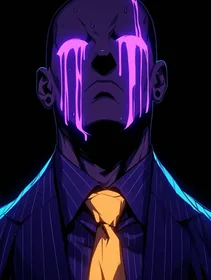
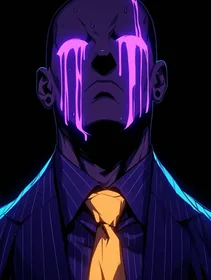
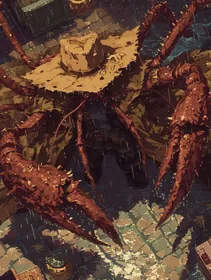
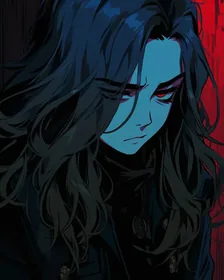
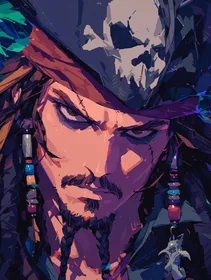
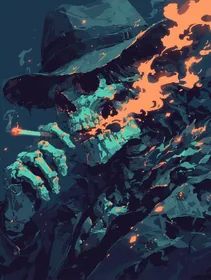
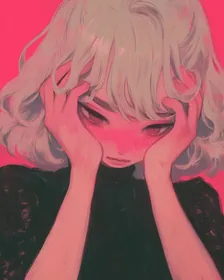
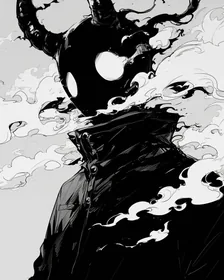
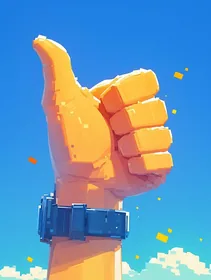
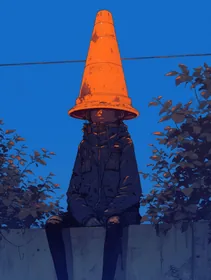

In [1]:
#@title ⚙️ LANGKAH 1 — Siapkan Mesin MuZA_Skripsi_Template v1.1 (tekan ▶ sekali saja) { display-mode: "form" }
# =====================================================================
#  MuZA_Skripsi_Builder v1.1 — MuZA Project Thesis & Skripsi Builder
#  Cyber-Editorial Edition · by MuZA Project (Muhammad Zidan Aisar)
#  Fitur utama :
#  1. Pencarian daring logo resmi (PNG), kota, kementerian, gelar & pejabat kampus
#  2. Auto-extractor aturan pedoman skripsi (.pdf/.docx) + audit halaman
#  3. Engine OOXML Word (.docx): Tabel 3-Garis Booktabs + Repeat Header
#  4. Hanging Indent otomatis pada Sub-Bab + Piramida Terbalik Sampul
#  5. Style resmi Kutipan Langsung, Rumus (tab tengah/kanan), SEQ Caption
#  6. Analytical Fallback Page Estimator (Daftar Isi selalu terisi angka)
#  7. 5 Preset Metodologi (Informatika/Ilkom, Kuantitatif, Kualitatif, R&D, PTK)
#  8. Integrasi langsung ZIP/CSV/RIS dari MuZA_Search v1.1 (Bab 2 + Ref)
# =====================================================================
import argparse
import base64
import concurrent.futures
import copy
import csv
import datetime
import hashlib
import html
from html.parser import HTMLParser
import io
import json
import math
import os
import re
import shutil
import ssl
import subprocess
import sys
import tempfile
import urllib.error
import urllib.parse
import urllib.request
import warnings
import zipfile
from typing import Any, Dict, List, Optional, Tuple

warnings.filterwarnings("ignore")
for _pkg, _mod in [
    ("python-docx", "docx"),
    ("pypdf", "pypdf"),
    ("pdfplumber", "pdfplumber"),
    ("openpyxl", "openpyxl"),
    ("Pillow", "PIL"),
    ("requests", "requests"),
]:
    try:
        __import__(_mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)

from docx import Document
from docx.enum.section import WD_SECTION
from docx.enum.style import WD_STYLE_TYPE
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.enum.text import WD_ALIGN_PARAGRAPH, WD_BREAK, WD_TAB_ALIGNMENT, WD_TAB_LEADER
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.shared import Cm, Pt, RGBColor
from IPython.display import display, HTML

try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

WIB = datetime.timezone(datetime.timedelta(hours=7))
WARNA = {
    "bg": "#08080D",
    "panel": "#12121A",
    "panel2": "#181826",
    "pink": "#FF2D95",
    "violet": "#8B5CF6",
    "cyan": "#00F0FF",
    "hijau": "#10B981",
    "emas": "#F59E0B",
    "teks": "#F5F5FA",
    "abu": "#9696A7",
}

IKON_GAMBAR = {
    "hero": "data:image/webp;base64,UklGRrIcAABXRUJQVlA4IKYcAADwfACdASrTABgBPmEskkakIqGhKNRqaIAMCU3bq8pYjgwu9+984vkXtu94/efOL2YdkeYR0h5//+N6xf7h6hX9d9OHpK8z/mnf9P9sveJ/cfUH/n/+u9Z7/v+zv/bP+57Fn7RetF/8P3M+IH+2f9D9xPaIwhZuPh9xlnsvyf/M9ifbL/IeIvld2QHib79qy+IOiX/jeTr9Q/7XsCfzT/D+sj/s+Y3669hXph+TAZpf5c33iqWTq/2TRGPM7Jsc0HOk/RiiP4DHk5Y6yXm5/rwIMv2sroYW1JtQ2EIqKnGbiTrgFR8rawmVQ3YqDyViPx3TmU+PdS82Hn+TzZBssvkwYBq4o+w6qTDPRYD8h5csiPdRKjDrCGRm/M6Wauq1naeW++Hn8CX2THWNVA7SHNEbR3AekKtCOzHgJNw2FM7UojEvKxJhPB9+YtBZpeDUEZXksfnwztyoAZPHtvLDgDoMJSGlkaSGL90Rm4Up4oPEv/Qjnly7SlVs+MiACU337aQoMbve/AJPeiVyycYtinOW8rPnTeV5Ktz7LSLhAzNAMHpltIivU0gstED/yDEt6KIjhLf8l/pAlZzzQPvSkJdctSdUrFOHxWwRIB4ZMkhn0uYAViJmcU2BrDlbXQzcee1Gfz9w+0nonKC02vUP9Fp0cYXsJeKgOWQpoz7uS+8UV588OQR5EhcUgvtzIP6LqxdSMWieUWQaydWotZHSu+Uhw0gRRMhhVUZSJsG/cohpUIQhSbiIyYGFp/fNqZN88BYjKnsZ+35BeNat2+ZlSIYQD9qXpyUUXYHysZa7h3Yws036TobhtQe/UTqU6t+jdug8qF4Pzxk8cKsPYAHc3+S+CP7leyqV3BtHuxlQLNlXvdWZinaGskYVom4RctRv7+tPgPr8o15d469+X2jNXWRDPofIdrWdLu+NTNEyfqBm9nw9ADurP7EusM7Qu4suWWbtMI7laXL/+zH9YF5WF4QL45xT62v6Kcaev7xy60mJ4O/QUsBmzcKNLaf4Ewn6J7aR/eHjaKcFvn24hLpUNkcbyVScacXUaN+StRfTibVwjYl5wxedWQh/wLXn1RXPwoiQubAPm2+trOVAtksSF6RR88wFaNTTpThJYX3c7bfSNChMdZDxZ8c1ToAsFUlg+1SsplFB9Ts0ode5Wo5srWJiEdXqKVM9hIL7HxbmjD6oTvoF5rZO9/zCIz1ERDZg3MKELq82gSSk95XqhE6VrUk5ocovMmSYGuhgVI/Yq3QaWi5rHHfy+ayBnl9oUnjI0iSqGA+OC6v6Ujj0ts9t4litgOPvJpxi62mdq5cw+67ULQdzZOM3sAZRhW4LQnpP/AwA/v0n4dMp8sGv62E3FBFPhRdqfkiUxeZmJilu+Jte1Jf+hY1kiUdpdX/Mr/SmyQ9iUpOfzn751KwABoNjO/mctvjnIMqLPXZJerCy0zKHFA/Slgn0Ltz5203mvscS3gZhKi/c1L/yPDwYB4JcI49GNcYvkTGMNfeLIMPgt1ucA6NhKj5ZtRNCCKf9rUXrjDPUmC2NqmAHSgwr99BeuuFPUIT8H08Qme3QwAbB+f/oeeOtF33kEb1dIW/mH/MtL0KIOjFy7y7CJjJA8Py+EGlEpVyIyQTGk/ScbMwWsUAFudtUX1Pw/HgU5Xxdf2wWOUgYLjeqxN9GtsvGAWVkg7SI6WF4AAeldhw8XCinGjpgh13TCqmfl4lntYkltoi5G8klgrBrtgIFr4H/71+d3xQF8iaJGd13/Iux+OsxTsN8Al8YdmFOopUg2KDHmdkmY+flnSAIVK4jttI+ftT0RNo3ThEqs+PI4BLGC2o0sKAAfnXAZPmlJC5c4WIKP27u8hi85iZ71G76sTrOPGzuLpT/udFX1TKpAJx2PIaSrWYY+TR2J2xkQhBTgxqca938NWS+W35M+86KU+v8yATLxFUm8NFMcjsqvo45A+PR4Zv2DodjZXTzwFL/x9OWjWKTsbYZhm0txgAMciU66gVDjM3QX3Hr8d6OtjTdU5CBmimXAi1aqcbLdXnK43L2e3RIlQxrRW59zh1elt803iDr0pWB4oNU1p/eSq6w66q6sL34RXSpYAtEOkmP36LtUGJ0YnKDOOvd72kemgMU2EAI6F4vPmxRtuHGKLDEfJKai7ONey+9zL11xmytvEKfqI4cgDRE5o0UxyCyp4b1II4AlU6JUHp3ofn97SFoamWvaNWHSxZOdtGNFhv0sRPbyCLaOtxgLqm6NJQdy8DYMsAym0AQj6nwiPj0vBCWKc0HPahRN5+goXTF4h8CmAojAIc8369jBUbAQErwTTzMJ+3iaLoiAGjv4U8/3/gd+0NH5CkIOJEZEoP8CJm8pFYu600kdH4lsKAcMYtp85F64tLdho9aH/A9HoyH0e9vcFwyJqoBwBwtFXYg/JkgS923ViLHy5NSnBrZFubrqWHtSZ0Dqm03qja156/jp0zuCNMh5XnQcnJPTBtM4sL/hBZsQpSdYG38mXCSZi45dCAEYtIh/0WqiEjcx8TPYmfgOK52nQYgPelTLp6aEyppFlP2WkPo4A+5EOM7Cm4roLqAAaZo+Kphq1DhugkLNhwJBqpGbIKMJqBdrY+hzSsHJJqmLADbqyDUBQwmw8g0NDo5T20D8icuU6W6fQ/NYL+RTI1o+VBHg9T9asK6m3Yvc5oPS5kownRWMmRuS63M0USrf6WYy32mqwdLOMWx+ACeDLs70LLWM0CkfZ4LnxcRFF1mXhUf5kWFQ2buCZ0+eyqCGh99ze/I8LVo+PRUFtKV7IZ1DCNTxQn/r1kDQ3GJNvKJYOxWlRbT8cVh9Sju9l2Aolj4zbz13kFeAwchzOIgd0BpqiAY+HH8qzjYrvqZlNdATfXe+UJmES1w3pigagVFsKjuo5eU4gFRzPuKtBGlLwjNvlknD1oxn2ji3CWbc82dYjpMZzMj/J85ZAJ/0ciYI6dZmAg2Z+RUCw56+bKel4HwQaurNIXRcqw/AkIZLo2g5cbuc2zUKuU9GoP4HhrRILWqfCHIrU4+SQ8pDVapebTYhWYlkSNyx7YQBrDc6JXdLYQfAB5VOJgtu8qFc3EkhcBmLg9PU0HVS9hSYzTVzwKkWIojeJEkFMQeImqMKlep7/d7A/vKwI/EQjzUKK2GV5/fNn8vwVRAhvzSAVy9tvZB+8cGEjaZEc2yOGAppqFUJ16UMF2Ce7Wl7F+cALh8D2HuVQQPwzlWRMk3b6e3d7heTTrrmnWDwL2eGUuf41H1920G+eZoS9Q2lg7L6s36ztt5GDKDCEuoUPl0IQ2Wc06NuqJzq98h3MHSOhQ/4DHQbKc3Py3WhC+hSYP7SNzWP8Pzcm8KQAnPCTcf9MRD2tnUuNTGc1dA/D4phY4PvT0/teZ048/IpEE1fxMQLHmBW9GaXKY1yU03ArRXq2wSn0e/dXiC6mZUbOCnIpDsB4sAeLIRknGTm+OiF9SaDYq4RkLNL5gguw1BZ/7coyYi40yVb0DyBDndXEGvhD6ARU4aA8QerI1BoIMCLhEkBlHZuYkQ4mAzI8UQybIAA76SoX5ADQHs2QWmP5eO6WSPP4WUyjJSGcqcac1LiBR203W/jkNA4l8Snam4JdS8suUkQDmx5zCs7PbFqpWQslY/JgF69tGFi9eKmdoV2BFsAqprn2Mt8glmprbhZvHoAZvUWqbKmNCTafDwlnNYoOtpSZLDaNIBlW2NyAckrhiJX64BbJCF8K+5+OcjsU2oOKcBrpMi7FdlKdoy1Iddma4Qo+Yq2kWZkc6eKqgOJYYT1hJ9ftWia02NOQPg3xl+HL3A56xBCVFIlaozJPHDFT16UPbP3bfvpMskR/wjDVh73G5zxIUZTlmivmnHtq0iRMZHvKfvDKEN2EaVbAFzx8x/yZpicsEqfes0vP2U/JVRKXQsMB5pzgzaMNtCPQP7G2423awoEfuKRtkGDXosffk5aZ4S8L37a3w5hRo27ilTbEYx87Ver0dGYX22jOZjxaPgHsYpThGjDPBL/ey3IAXfecsoVcctMEppnjrauALX0MnASuneZYUkrW92UezTdHPOUWrrPQkN/2W/PHgyWVWgiahRXnPyun1R23gpBkTOqBdFJacs7ts7vii2KN9H5J7oKY1+W9m1zHvemJU5Yx2u/XOo0CaPxDSpkZpLIurpBcGNU+D/xjhR5mdqe/xRACUZAQAsycHIa073QATfaEGatRkJ318bmfO0hWpO+x9OLlveTmml5/nFBH19cIm2y4rCPlfQqWdXUPK1Yv/qMNVX1Mqf6BWhV/GQ2/5PvtcaKOb41Utz/sxp+huH5YaXryJsFA0haVoUk0XwTylPCo6HGzVlTZ7xdOCZ5crJYkYKLR7z3TyNEe0bGjzBw9cKfSrqz+XPq6gDsG0nVVnV9QL+PKs96kT2orJ6rxrPqx7nWK+a2dhlElrWkXpe9jJpkVhcixG0LRp6twBH6WKScwWzRsJ1i4NUpbSRpGzV41tGrk+eSv27Vs4JyRlDpMEdwAoVqcFO0AOK8uagC1mfxOxwb1o5FUNecQjcPtJP6hqiW+mnfMLI1tuePHgyq8bn3MN6j4pjBBsADi5r+qSYFRvGZiV29u7zxypmBfdSFy7co7D59/wUe2NI04b9B24KTD1ZahWhgM+dzNd9gSYEi3OX55z/7pyB5Na/hWDj2nIehaM6pPdpCipklwy22lb+Fdrl3qQ52xfTSvZ7X78fROqY3dSob0Lxs03WXQbOn+7gPTQHtfVvWnB++jkvwMWg9b/Ay/z4+LxRhwQHSPySljNemmCPDAtEW2tfwGdroOq8c6RQElzDEzdXNO3n4cSc4cIB4kSEysAB3dSnCJIOEBOwpnubQJTejyLO0Igpp/3Gr2TeZo+uJ+byCO/NzEksQHp4ICGFdxDlStHCznzl87KtOS85sLuHNIRCvy6mXNE7M6rRUbtWAncRspI2X+7cpWtBY/qXyLiCq3UmICt6kX75clQB4N38RGPYtZhvbfGvMUA1tOo5T15ElGEE8r2i1IFZw7IbPOwDJCcFJqhlmflxllRX5/mPaZWH717w1AJVDnr/jvhFtN/9ZkPg8Y4NOabm/QtdpsdX2XAVPX5jlhDTDra+FHIKpQACOna7kQBaP8MP8HQNG93/w15UUST/UQhFlGlP1l0LaOLYJauuQ/uo6EGjnEt7bV3zZj7QrPeiY5OPa5/Rjov5vIJiOcmtELzD5NnGFetOzfnyoZ+HqkQIgufkM3cOAPsmKaLysibrmu8clgn+Az1TM9v5gSiABxeGzBgxiqe1coUSP6O4+PH5OJ37zhdgBxNTGq3o1Pbf9+9by79EckbjizXBSzejRAfwtn+UGl0SRJ7NbNjLstrb9dp7ENcxk/uLioTafksa2/n8wmK1ZloFCjul6vjv0CaGmx6nItYBorMHItO4hKr5b76hkeCKoMB4oyYratfhbc79rfoMOD8nt4I190sFEokE/Yu97Wj4Q0S3mG3SM43fEmU8jT5OW9s6Z9pPvEHy5r2Eb3skgffDp6FVhj/mwdBb0rvDPWWfsLirP5uTtSm43CRLaeb9GVxAeoKWBukKi74SK8gOVogmSOxAZwDhtAi2M4isIRaobPrX6IXUhUaWTnm45SmmIPestiu1VwEzDIplGJLP3et/pg0LZbz3b0pRii9xlNOBebU49H3Jt392MnlMwV0D3zXaAQwCVVvbIYgb693Or0I2zLs80aX1jN3kcF+v5WePBylJ5z+3Im19RP1NnkOIsQl+v7HOvf7QZ7SF9O8iGIfOp7Ed3RofdX3xY/p3FPqQ/0nUwifWwGZW9UB9dgqOynmf8KELrLSwkk3I9Kj0oe7/8S90fBfuzBuD/CCxi+GUMbLBztNRaYa4+kBEKDTIOLKtrFdR1M3s5IB8K2ndY1TFY42mlRJkwZgdpmg/TjjRNFc+AvfWFSChui2lmH0IXQqwIdYiwKnDROexHa6Ltg6Bey/2zzdIACjYHgDijLkTE1LOG34RLujf89g75sXyE+pjKCSpiSDgD/pqWSi26i+qDrN24T5Vnv48svDe2VoWjkzn0384ly6tsW4KOgz6VFrphcDSMUheUgHm1WR6PieDlzxJoPHo84JD3hxeCic++jGuRgLYNNP1UzB6Y+DG/Ylf6RhrhO+2n3vT9++VA1U7IAyJ+0aalzvTKBM184uq17DHi8nmx5B3vbOabaGp1PxJ1XjUz0tqEOPum4ADKxeeSEaH9TuV0Cm1f3r4NPNYXKzE5linx/wwlDw+d0ISQV3gckMumkzRmNyzqv/gALHaKN1Aj57/25VS4v535985mBygjZXp8g2Xkqto6Wi7I59Ppn01T7DN5M2Bqfy2zh/+o6SS9E8RTV37j1w3Fw0tf4TyPJ8G/BJEfnU4kVJMp/2uFK/FxZT/bIivsVCw5QIquOHf9RSVfQ8C4b3M9mEYLoTn2fecD35n/yo1F6Og5J7FHv7c74/H9WYXbAhPIFVSQroAH1yVr/8Xw3C3nJGDoE3Di/QPWRW3ASNInjE3nd7Aiww/WPmIrc8uXaMi+rxVZi7EGH692js417ynK8yx9DqKSzH1QyU59JhobMuCjgk+1/naPp5hdtK38jXDSGAStt+PFoocXe4hIAD9UGEIGn0hz9kFQ+eh9zkKr0svmjsNc52hzlxGaXM1Zu3wrly8I2/dU+JY34D4Bv1rj6GkLfugdzaDnf6pI3+99ia+i0x/tKV6NoAfZuEj2QrkoNw63mANwu8KDW3aJ70EGN11DToaCbgy+4FtX8SXeT4o/Rb7a9W/HAqtRxZKBiFyMkUGL5mAp4sURPkE1jcX5DfbcaBEougSJd95G/bkeGncghmEw5Omd1kmHolxj1RorFuWQTy+vlp6Aj5kmX0wneppTwxJicEEdO75TEPfrv7lJ6BoIEvvQLDqBrghqXfOclPAACvu730MOaSDceRGoPXcDXqbKeUo4AIlt4i+w93ItLkDSIvJLPn5mJ8RPVrwP7Ivb///BWNSDv4959mPL7CQtcpo9fW4m7jAxs6U8jeDcJ/aQdxS/DMk9LfU5JN7IaSmhCwqqHhQMOQtvUG1Rydl07E4i6WkIxQZqjg8ldcsmzTxSW+YZWjxfZKFlmVy09AdjpE7kV2zCymHvc/4hgIp5r8rU0aoqz7/L9URyP3iL+vqn8P0HDKy/vVrPK4PwERTbFqQrwa0fvDGBn1v+FTZJ926OkPioONRpsDSZhWLRR05QTer+Ixc3SvBKvwk72J8YweFoo9BGmlfK7scFryiz7HFqQRsizWYnYcs1HcgD7/Ah5rf6Q2Tp47h6f0gqCri+T94BibXnNZ4YbhtBa+Z0/YIT3+U8ZhxUxT66jKArsaMcqq2vO2A0R+5ewLqDrDwPH+a1wane3lLxBmFbOY9u1GW5A1GhiOXWUpWfeg4JQT9BnjktYmxBDWiteR12YblwjHdEiTjXR8eubxYDyQWZXf/ex7rQPLFLo+gVL/U2Ri4TY68sIMW8LlIWsleRMn7QNNuAiPW7NU0kHVPhD5QUy2y0juEPZ7bBl1rfFwMjWIn1vLfDZ1XMV0N5Jo/VowfoljLOfuvfx5e/tJ7X3BJx/bGs01/02MgVJSp/Oq8i5TUhjSqfBexAIXGYez/keuOfzyrZGBMYvc6UCp8bTCXtYouZZpXTPp2Dmyv/mMvjjLe+eDUTqX7SEslckrcZTNbKsDNrU35s5xq6u0dKqeNiwFGblHpM698Atls21QbQwJLThogd2Eqm+mtG3ZnjpfCwyB/Sw87+5mPOb4LqOH7rxw+7gxmYBgT+EFmJ1mAdMQrIXRWp0eOBCqn9R+KaNYBo+6DDSp7sMqZbN+yvL2sQFZ6gmmqxHUOSP8U9BHDT+ODMCnX3sC1LmQq3QPWS2pi5tDva2VIoF+oLFYSbCL4r9vl/WUJpg9Lln98rhfEGR20YgRuy1lbl1GD+OTXWZkR4KOStqPms9LP1/cT1rJ2zPUIjlZa2EF3XUIWsmd5FCqaJ4hWSvglnKAYGv3y6+uzg/ILf8zfNtATe9Tle57QO9NmCXkcd3coMron/+Q5Du6pqPL2TZa1Vu/Mc87nv1+9Qr063lR3BUM8dk9eRJyx2+QzeP2TegOBF6i3sXuHGBQ8Y7gyT/NdAz/wG4hNU4QhJk6DfRed6qQgvFnt0raYTW4leW45Lfwza82IufINoB4cBPRkJTOyu0oRzaMhMFM1beAJFNVxETXL5k/8xPBXl5WEI5of6tMG8Q2jofQMPfplHpslSaR3TYmo2xw3/5a5xrxGeV4yNddFmrglTjatDLWNzxEdTziPEC+QsOZch4CSEJfHyQNCDmaNNw5aP0EyvZR4ztUwd7PeBElk8bGDGXsSOGtNPr2Hc96YfQpvx4Y9FmChK/W5zPAxw9T28unfRVsPXA4zdIDS5YGGl360zcgB+m7vJKo2G4tbhdhWILz1704JJtvvicYrFQZIwy+ZQtwcq/amHOTELup8P/vfhG19E+N0e7i1OfX5Camar58DvdPge6094JOEI7dCMdgv5E3fYQaAJhGVzfDFmIoz9TYdbSUxprCeF6Gj7W8M/YY5tsd8RZgyanZGGIie6QjwMuIqOWkb0bGz8jnKQ0rYFz1Xs1ziYl2+2tHERFSSefTMVs3CAQgr9tKkkXGUuodAr157YaGocD5vnM1AHNhahukV++VXof9Ko5QIVISYgl4dPR0x315Ei3/YGmffQCL+NVs/qLDXs2CgtfdoZ0KjLBDkMYNMJtJ6lablgKX8dTNyoWpQUQXsGZTiOAJbUCbIUFP4N1iDYucVRUI3I+F3Dh4Ry73e+++cNS/2nx+k3x/FduXl3LqagfXkH4u7/NuWbVYqRUbzPFtCqnevby9UTs9UerfQglxpAl09+oV4zjLEvGysLiXY9WEMWDG3ivbew02NaYuUXqhP/oW4qHbP9hIsD4D9Jf6i82w9FuCbD8Ct10ZgdFdhlQ+GPf3bTwKJZ//CJ0PT5r0K+FbtF0V1NR+tRkieQAX1QMFMXWuazT+P3P0rAI/uADraQNR49zRiu1669V0LtpnkRSMlZBk+FoOH9pNSY28yQgn9Ck/86u1fybERLso/GjOYpmmE5/YZZwY3drNrAP9nd5eraVCgCPTdwGhyaNIjM6sNyiFj3YXTG2c+M5WfB81ezxIAnX8y736u8ms09jVbeSZ2DtElkMu/caLLvLkPlumsWAsO24KDWo/eEV4PNj+yFC9VpbPIMHL79vHV7JTTs3uThk7oHzHSRisrIX+5iHiQ8Z9S16oWKCbniwxwNTk+9dnIQifBj1ZM1adTAqIN6adXdxzfLSLKIHAws+m3xfXtldEukD0mR8MD2Eq5Obu4uMlHIKQkZNoL7siXvYnioXM+k22X6q86/NgZNjIJC4aDkob+1+/hApQCRcNTc7Idg7wle32L7BIe+I7AAwOPCjjcmq3u8m3iKf28kzSvh7sNqUgBv+B8+sNzGGMYzBpDkZXOXqubp4RL2XwyAIg0IBkR7UoBpM4e+DVh64i5DGo3EZ2AuwINps0EmRgYwGvHy1cTRAPI7SD8HAjM/gWTGkNIYqjV1c4cI2MRXLTJL8Hb370ZrajeMfhQRjf3iesShQ0FRrozBzJjcNJIm/sEOxn6qpukY1ogOSHWa153F3JO1JbEs2YiIkdSecjwsUc4kE3ucNt4CTJx3h5uOpBcQEkodc0UlZIlV3EQYSzQqG6Cd2dGM3gyFDMU9YLZBU8q9gscwrKOFCTLuoZLO41K5sz704UoSv8jfAAAAA==",
    "jempol": "data:image/webp;base64,UklGRngZAABXRUJQVlA4IGwZAAAQaQCdASrTABgBPmEuk0akIqIhJlKrOIAMCWRu5KgQiZ/VgCrczmSHsZ9gaPDwH5M/kj8zVofwP4s/J75d+R3Yvma8/f7/7a/l7/tv+X7LP0f/vPz/+gT9U/9Z/feu15if6n/gv2m92f/kfs77uP7V6gf9H/u//r7EP/H+oN+0X//9eD91vhS/sX/N/cb4Fv2L/6HWAf//q3+SNs7rY/oLI5y7+X2Ujet9v8Ln7/xP6a3Mp/zfpIaUdRUq4kEcdq9hR5Mvev2NN9Kln5YEn2lY0ZSIwz1smm9rWmTidTB4GRxzgRvvHwSYFlESfPi7ug6ksvvQDgEO+KiOAl8nMxW6LTNEcL4Iw5p6JDkaDNhQiv3/3Hom4aF8ADG1QOwSbaMv8sgt6xmsNRea2MX7TYmUrTuuJ/zFGEwtwh12s/fVFy9m/kW42YqbM5nj38/Qxy6ZC6Az2LYoSJBYYOeiIkyFpcfePRVObfuX0VbvZPh2iRxtpNcHy5DLVz204tyYq5/aShlAK30V4K58GYg/LwGIg8XarGslLxW7FPSzRnIipkjRYwVWzC50nZF2FcMO4tJAUgMTFY6nBylfPylKRmePvX5eA2OH+1NG+YIIeZvl6xet6eHpkP0fXTeJBaKTOg5D3DBEGAWdyaXkIBBE7zxHJSF3EberLwnKLUS7OqCG6nGZ1+dPViHYwQSwZvKDb49/w6G0e0BdVer1UdB6YibSayZYUvJOSqyAe93rT1XsqmUkEKbDdDyph/uxSH3e1wX24UkABT7up+Dnx6rhsDLeWT7kf1SVQ1rw1VsPGtTi6SowLuOyNYVUqCaUzV3lcD1B5xkuStGotW0eAU8Rl0a1YEIJKm9kfshtEpC1+0FcNL6TKMkFdUtCRcB7jBPLD0bRMTajLolhkJTNLx6FC4/c0Q30qCdZuvKvkkAS0pXXEZPhTJzJ4NIv4vhJPTIhP1F6nXsWasI+c74rlojbfev497FxDwfgIej9VZ2cDaYDsSX4pFbkJS4NebmgY658g74a1pl526OL1pIN9WBTRTcDkssuzYRDpZDWHPreb5wYC8A7TYy+Ao1fu7WBr+H/PHE/Qk3cT7PVJdv/iZrn6eGO5Fa4/8aX0LQ8Z8KZIKzD44AA/uuQP+yT458c7Zv/qTK/UgyJjQYyA7rLjJ9VOygAe0+7oj+ZF0eu7GLryDu+zAvD9xUx+xCDmO/U2ZZufMqc/5IAAANvAUviK/ah6x6DKg3sxR1gt1D+LOfAtRZcKQWdRq8rO36KV8qcFGKq8jy0YUGl8O1ickZFituFUtAyGpfSG4Wx8judpoLQ7FTJDo3Jy+n3vpvl+gJU4LWcjR4LdYmg54QWLBwEN/cX6a/zvi+h/oS0u5680uumFN/eK9DO6O4CDJJ4VwGMXk6/m9X4fM0EJtPZCCeHgPvCp4G8oFwcrW451TbogaFQbTH7tacmLA9TcCL3EE5jW08f1hLwIaK3ugE9Gm2UNGjVnE2D/xDbtJxvDN9gbASZf+nioZPrCEPChqny+R+E5H82Qh11AwF8dKcJYq76z1O4SY67KxoUvCcWIJuUvE7OhwA/r4OzqkuAxMIj59X1BtICoK3ppNKHsUheEA5AXM9/5spkYxvdklKA2OShkV28WFYQ4H3/kTyDQ8R2ipq2DcmXBNz5071HCFTg8MCqO7Eik9UEu3NMWJgGxvMhT5dS5blPTo9r6nRExMuL2i6xveoqXUkUt/jnXhB+Fud9MgifV3LiVPKBI91r3xWQUwMcWOly6Z+wJJ7HNdGcz57jP1G2rt+bbtFN64ImknoT5k9eZiLUF8s3muo8yX8qyfKUG98HXdKq39ITi9rXmw0uY/SmrCuPveRxgI034jtRN3a3k5sE/ytuJHDHM9CAEJ3+vRIiU50Q6I62NqRTZzHsgU/lDV4b4LOlO+m3obxd5JK6xojP4RdODMUDD3/RAfD4txyRY6xSHe+HFP/rBPmJfrDAGe8/EYDlcRBL0jB8mTH5ep3Wx/X4pkEVtWDdu2aUizwNgOEXfNCwWSlFL+6NlGDBlWYkxY7zW7U5Zac0bwKGrmh4Tn9+D3IFI8n8XoJ602h3oXMWHkb/rDSS/7jZVPZZAOkTRoLezLkywfdi+DVPITjItMz2hi7efBBDpRvjp002mkRyBGWrkgiLTgUzuW9klLx4GjhkHXoMnuxe3esm6zos8UWv/ouU6Zy3K3I8GMc+XKzz7TkjzsoivGr0dcupJGzY6BU19i+fX+453vwc/twXvXi3ulggOviNIjqwCQA1zclKDtXkWgN4493NMo3o4rSR94CGJaDnDqxMZay8S/+tsARho752lDnQ1Z/YUe3+tfT71jzFOzazdXse6M57UBYI0TSHh7dXtY+n8bvCN9evbafLIICPAQYfEW5TLM+2lKJXL8mbCEQlS/jR+DVDVQeTcPgpKFDsIduEY84ez4N3UTXX5dvPcxFq0SLsAV/fs7yVl5yyhzmBOi6yyWLF0S6rvgyau1dRJLf7UlhAFKYigGH1WfT/d+AHQ/lqZh0PGlu3pbj2dKmN/GgKf15O31c3c/BOwlHy+KrN4VauO1ug/kArZHx+jqTdYAp9JbvZOf6sE2UHCIwxacRMbM/5ZJg0VJnEKnuK8VjBwlNF5ZqJuTIvetUf1WwQvP9nD6uhusbOCdDiKoGX6IIK0SSDjsbEcS9ZgyRY6hBuc7hNBlDEeO+LdPCI5nyzBZzdlUJ9qL/cbtYDUBpKDBruancBE+mK+6lswY8CXf9BDb7mQnzCxGaHXEKx+U0ctTyCx3KPMvjiH0KBbASXZsMCWLlKpUAMDkgPMLWIwBA20S+eLc8w7YjRkHyTtYiSv4aCleiJ9B8letW72mklJQzavXW7yaCXJCPKNey4v3W4nKRAk4OOYZBIIemEbQpXNiYWbYDG7gG4ne+ap7c3cpFhxfpt+zExk9ngC4VEJm5Dp84qN0uupFh52yiBU8Bb46hDBlJEIJWwd9aQOHtMHtHYNGf+M2j+wT3v0oTiKaJobdDhccVErdcQHkll79vCZa66AUibx6V2mcUsTVA4b85fXw90vHhNApgphl/7uxR5OkrNEPpn2InGtD8AUk84lTWwSIK5FAJyPinpNFZcZiZIahg1BcqrRRr3KMfAIHZJqJ3Kf1swxI7K25lLdqlDjLiDetw3Qn42y5GLUzHOwdqoYome4P/mcRCrotyVkxDukKH+3T3nvFU43a89M/w1h3ecQ3Ga+5KMUVdO+rBjdTuqMpxvbzBsvwgvwmKH5+pqxCdPfkBtGiuqCYvAyz81nFENfi0k+J2nKNs+NDSO7C4oKq9AcgPwc/vuekXk9jMPtiU5llUaOOxr2i5Jz+FtKi/XZ5ttPzcr/Hg+lwDElVCYAmDewWdRDblomjt8VYgHtbe8rmTp2jJX/O5ENHrF8Moa3P/JHp7RPl5UZkz3SB6Ik801m+LAfCRExJLnymepWa1Rh4z0FXzScIXJFuofE0tZA09bPsssrUBao9blkZuhYv/Gb/w1JAVXXivV0umdYzl6vpM6WBzjiKGidYk210akxn9XEXgQEoJhiuDDC/KhsDYQ87BTyszM+9SepFIX7q8urw0SpRm68ZR2cRn27i8zinsOnF57pG+mGWKY4CwIxF3/SEsMPm2Ogd/B1W9RlW78tcsH/qvKl/Wr5SBgsPhofTsxuOSeKdi3KLUzp7iswG5Gy6np3z4xByRhHAMPXA1CzQKdDhciKwLAVKiAAfbp/Nv8hUaMD+ag70N/PzV3Sl40mR/zz2Gpa8B7ruEefIax3eeTUyuw3OfDElzE6KMQAHm6vbOBgh9m9CuOAhb7wTYrceClhG9/dTVTD/tksH7sfiTl+PVV2copuVaADRJ93zCLEEvEj4LRG99W3Po6NSzpg30Zf5TxbCkJ17paMZUmyEjeRz7De49zpForBkafzMbEPWJAf/emY27cv5FXPUq/gDHvakJsOxsgo3pIfIZbtwDpkf0VYJ0lrQakMj4wMTKzZhWCh9WfWJ1nH/kSXYOkLmgPnjSNL1ozb0AqGUKe7JmP3fS40VtIdUd+wyNeNJwWSVyxQJw0y+3zSmnuAfAr0TvK+QNEOvYN1foJ3hgOdPywXW05YmhFC6lEPe4j4oB78EBnMdsgF4AlFHBX95HRBBLqUm0FPMOIUsn9citi3eLpv+6tNgPTn2AgjZY0hobIfXkbmUTx00onFvDuhP3PwWn4P9HB1YS5QjsAuz/b+ogIO1SWBzSuts9xwdAxMoTK5jKinzl1ZDOFuo7pbSly4xtxUAlOI23CieGuxxrxGZeaE7ZDyWrvDPnsU4YO0CuBw3ADPyvJQLD3VNxCqXq5Xl9hmdanl11rFsrU3nNGjjZNUjt9JkU4fwn3Ho2kkLIpbVV9b595S2klSoEubmKQWAmf8w/HfmToAAyJBddlWDv3prEUoFc2toLk0l4FJYLOTs5AHSMTZFn/xq3fPyln83FB9ilukWGGqtvgrk1MFxbswPDVebwMgaCXzITX3ZPB7dxWQgEu/xvCtcgUACoH5M8Zp/QwVBxVFE5WSmrzawSbHunbp6XnPeg6R5jS10xDzRoHiFY5wdn02Sz4MuLykeHgLqUdHLlU3Hr77CEFPSzZctVmas7VlOHhoSSNj+/GgVaiwmQe7U9F9MZ1L1b3OJ6VlRnLYYGBPNzDrfgFYATJ5BY5oG1mFVY7s61IPYiiTvJc/msVitdclbzJW9JML68VdCh/63ZoMCeG2e4MgGZzzgL/1E4qn3Qv8maCcJ29PFbN5bpujgkAuBhpD/xdcOIL3NDdLa//q9ZaFMkb5/KAem7LudP1mQ4udoXDZWvApl0G3vhYdVIg8YYzcfp1ZTwoQaq7hS5FmJSThlaOaKfNLer7+AHeRd2LG7dwMvTJG33+6+3Q+HX/zMgFdwIGKhmoYPlJY8sOFvb1iDaii3NyaAnylDVcfwR2SXWxZnNV7Ez/8IRRQvzvy9uwlDDv0tAu2tGifxXNqVkwuMMKiFEDhn68x0bAklCbtNvXUBrPp8xfg8MTV0q6Wexrjq+IGdFz6mNzAbtXF0LMjgB0SHa+cf1TFA3odyLi2CGMfV1o0zzAtgOCbGmlC4Q5CJ5x3+4j2bBJ+Pol0m287s0nvnKL33R1cuUKhy/KDOU9QJ7nFdvE8vLtxQ+6yn632x9GNkK6mXuPiLr9R/zrYgVprZHJlR0S832/Da4hmdb3HSzfNbgF1dmLRXlMVj70wPwSYZS0y7UlWlKwlbEbHAGAVlUL9LSs1H/iOQC+1lvSbEnqHPhl83MiIPw9PCMkJ6xQNcF5lFYvSgz1lRD/1KrSxbHU5qEvDyQo/uZcIc+8N/fJvu7o3WFek1moGYG1/hPQEhr4Uo3VNQcNU/O/kmxj4EcjDT1TzwQNzTJb0MYvH796/sbHfKI3XM9eyzmmgrZQhhpjJmdXCu6TNxUcJwQGpDTs/CyI4strv3gc4v78XJMX8WgSpEaQoJXWgSg9yrO0bW/1jPDPf4//6/6NdTvxYEudXJycpKgrNli4vzebagFdoBt3I54PwBszueYTX3mZ070+UI4MXGTca4C7zImU7KZxGN0WtLKI3RL2ZxmF9jKM2zTUg3+rFNR16d7/pgwDo5fCu/I9EZAG2vqTCDIC43kSEpJsSHz04vdp+oUhQj5GiBzdKjm5Jk8IKryYZ49Tgf/5U62iFf+G4SUrq2QuiRh6O+rbpnm7Dh5ZXR9RTOlHexXoT/hs/g/SqjJ3jPCuENrCJbYHZo/q6ddLF0f4S+cIcFyzmJg957qV9ScpoaDKsR3BIOLsecRNubNOVYCnEN3Kf1ybud4bhXQy+gJfZS0sbQUQA5erd0fINEBjsHSHK6PL7S6h5So+U/Ua3B5yZT3VbkSo3dL1+NY4eS2t+WrKc2xp9pbwd9y7mw7Cd6D8NkeZZRzr3AtFOkH3kEPrAVxh8eEUzvrw2VEMqO5fJGGmQH4+7ldxAeC+Cxgz/rCK52gZUOox4x7RH4uRH8/1D34t+WUPyp1cFTFoHbws1yTU6WjMSJa/O5SPVBfuoYf7kgwchZ5L6Vqn8fZMGr8eJcb639qp//GuanmdeAHeah59v/swGmfpkqIC+yM447CrmdMcoP+XO1gqh5DMWFusCjKbBEfIKX5I1s3lNKtO5hYS6FQexK3M82T8OX4QdpkzxFhu8KzESmlJCHytchvqewIBccWSJcTBl62q9qreGaTwhKWWYJFzW6w4kS+jxPnEvhBgbkG5KGxLwMb4H5q1YE6KZwhuI7Q5CbFe6dnrZMA10q5Bzj/xuxY7jrmE2jUsL6eN8+Eyj3h5u/IkC4Qixl9hHZfy4iRamiwtZDJLY3qH1EnD8xX0SgdXlzgYcS2BoNjusdZ2vrImgytGuaYTCvlhFJHHgJPA9/9by2bVT43xDCTXPQeW+3Wc49R7bKfUTmOpGUjQY8oDkx4gZaSKvTosqxQSbrlGlT4pgLxKKCzPFC5SNWwSFWgLU32yGYpQ9CoPaepcddSC6sVyA/meZNBf5lPvskre/Ex/pic2GOaslCRBKdCNAvJRb/Ee8QbiNKRxbjB5ZhSBGNIDhKz8gMcjdlHXxP6zYViK1kdi4HuoiVKhItMMuYzX4xsprpWn5oDF1R0frxenFj+eZrqK8KtQp1Wdi8Rjxk0BgX3YiXKs04WWDuLQWaj1FpaB9DusrcgE0xTLwVlU7pg6uGVRvYIY23hKC4IAIPX5zH8euvmh/dJLiZmbACa3MG2b7pb6Xgs1u1u+uY9wA3cvFDGMCEGMFFGlJmcnkOM0Lsyid2SPM2F9cN04obCPpkr1L8k/Gf386MUfY2AfI1bsfOhgfcinukRzdPyKajRiVEqXXQ2ORG8OOJ1wcdK9B/iXa6JeABXf54r8WIQOetK1tsDGxXygl+5ZS46qh0lWhaOFRmTOXojQPaEJz60CJX0yf807j15qyjcgm7m5Of6yJVn+bAwO1kzb4g9O1MWD3ob3hUkT9nRUQq1ILi2/tZ+hSX+ccf/UtyPSgq27DUVErlvP7lVOL3JSoU0Gu+BDFFWXLx4//ZRlq8chYcj+9ouU/uFXL0TOxJdFIX62WtY+pWkbI/me8Sa6qFYxWro2pC33nRmOCNp1dVzAio7cPJrujiWz2flaeVaoSTYQ/qsIKUIwODzeAzLHOSLN5T1M2H6H2KcHo4dBYCfz/tN+bEKAQbCCAiOURciXaFovrqXuNOkpQcWO0aVhyNKGxV5WZJ916fzCxsu2fQveLoNduUEMX4rEXgcOmXXbMzg3NWtzv3/hjMVu/PyFWvTRPSolrab5oSVdsvxEPMz6WB9+tdjJ73RvEcvj0GDwgrxqCR8fCFPc7bCsAVcXX+sZJcVQ3EbZrZnZg9kmxVruC3Zjk7oLu/s+z6gNVX689VzLr7TdrCBbWBpHAw0WNNTCUzaLom90ivUYx0GbrGV4wqfK0y9wnlcO05VRuwCmCgbXJwD4UsgXxrk+4GPrDVtezNd3P/8TupGzGfxn5ib06HFwFMG7vP+sZJ5k9JmqZskc1tUD/jrPubooc6ZQhfMFRyBwX0tXMp41MFE69FB/VM0DQXTjr8h6vceTqfh0Y95ySSPVKh/QTXTo/ffych/ymN16Pj0tFtdRTgLerWpzYH79EDZAGcqB1Zp4KXSUWpNRRDa0B7v+RfIMuQYVeT/C+30eaJuTHQ8v8s+/Xh1VNtMEaJ6yBM93JdWGrOs194ESMBSCFeaFOu7TNrjzbz/A1bjYCfwJ9d+ZqLcqIEKlAT6/5Snqj4JqIGjzLtp+0bB/peljowEmAp2nc/JayEokXDj2t9cDFcR5sO5HTv9Ds9Jv1P9Bv8fx/nEc2/rOEHToviFoLWaax18dnvCmOHv3zSl6WW5D7b9v5btaWxQBlnvV/OnZP8XDVSUgH/NZGgZSziMyt7OYT3Iido46kmkbsc6/PUZHkiqOKWYdYmh7hhqPKThRS8XXcBMTP76ThH6H7XJJrIT/MODOsrcdTvV5y4k4DOxFXYMJoAW+4K/kwUX610IeR1GopU29lpEThPSJvboKFCoZGF+kuChrgfrfYtHWORoGhDKvdprAeQEb8K6nK4NRhf+EFSKh2O+sLC7EZZYL7Y5M2fXa6beDFnLYXa3ES5moq7xFCLFm/UHhoezA86MxAEG47wgy8TkrY0QJSEasOWVhjnjodRut7QGWMiGUnsxBVuBJMW2m2BKhX2pkH7gwIy0c12RqbrXzvpLyO94JVEcBqtliMxnwi4G01qOVJ2i8v9lwmYp/eyCCnCwpHYb+N3qdG3SZdMjAX2tOgtGS1CNigejKSrcRM/SffM3OJDIXjIWM/B2DEsp1nmi/w6tihJQQrA1tSKtbYqZPn11N44lWC5Twwm4NzcHdUZTYoCbBA8Q+dFVROhW4u4wcXXJFr/IiKIako7A7sqUfAvENsyjWJbaL0EJrmwBqodEjmNQlGFg3r7KqoG1OPclICD08fipBoOou5iaYKHbLtgdZLzx4a7vnpxmmz2RABruyZtg+ySQIXop4kPl7wy0FNdpx9dXX/vLtCGc/kfq4cJ3MZLKIPBsDWJz3YUDt/TlEHf6rY6enEqOmpItHCJuvIyLWtCkMeebQ9/Fc0a139OH1TW2Et0ZTGTIGpihrHbJD+R2RXEDyhB/rfKfis5W7AAAA",
    "crawler": "...",
    "bajak_laut": "data:image/webp;base64,UklGRig4AABXRUJQVlA4IBw4AACQwgCdASrTABgBPmEoj0UkIqEXajbIQAYEsxuAAdGMA5quQ/QX8n/E+jRyP26/QvwXnL7A+2PNJ6h87v/D9Wv9V/3/sFfr90uP3k9Qv7g/tb7u3/e9av+N9QT+5/9frY/QX85P/6+zX/c//J6W/qAf//23eCP/zHol8fP3X5Yefvm7+SaH+WPs51Pvm/40/k+s3+47/fm5qEfmn9X3iEAX6b/ifAt1X/FXsAfrXxj3r/sCf0j/M+rl/r+S37F9gv9jOuP6Vyfr1jsjwxxQuDfcRobrCLvTs1Bb9ed+p9e1jNmhXxtQXrRiyrg9CY/CpuirRY4uUhzCP5+MJKb7yMLeHtjWy492iNK1WDMWpDHbgmqFvkUvAbgJ2xKNmlk4IDqA/RPWFf/teZbwMr/uB6MaOAwiLDwkBDRoPk4JNW6K7XgOAbA9yLLu8hhSVoVRMXkN/XXdoFMM6Xk21eST7MNjGtfFVGtD2g8FuPFJ5r37iqlaJ5w0Zgzkg4A8H8JHJo253EjGt2rsp10QlszVXrLW/p1OwJZ+LDFjmAvlGL5G/5ZjFUpK5xmUQO+yKVadORAQMlhuoHV/KYl5rieudTJnoaP/vesE/H9Z/NDmaIWtMFjgWEbXJOAcJO7cKH7Ye0svQiBAl4IWhWL3LEGi1KN8kPffOPq//+jKF9ZOcQgI5/GyadWovnB4vhOiD+RuDjS15Sq9RP52tKQYpMQQyec5mbXW+kGydB3jTQ/WwzIpV/c21YesXmiSgyCqbE5FFEB6TzwOrGKlqdW1RE2Xc8g17HU5wpqTokzoLXn1C8DuPxVb0jo/nYdjIxNAK6Xq1oNijUsQ3sCB5WI06vOmnEk8cloRaHxG8LfE6hYs/8J3YAuwl7lFjXX9vihb9b0hftoOpefkBjLobahrZG3Sb/vRIB0ik1vvB0G+vIyMeoK3vMkuWXuJNpE/+jdSLelrSeB+/7uZq9ZmXC0+bRHJRhn5iOeZwvmgxvG7LgYKzPm4g1KtW5x8hur8kW124gOsIb+F+/NXi7yiaeXlTvXv3CHcT/uUqFfpJXyllEai40XzQyiEgT91yiMdvca1BFRBiquZv1KNvHKJFuFM78UwJCDAymvRmbSVz5vwYWY7piS9U8txktubh03Kz1cVlosvbynmO8EXwu7hKXGiySHxf5PL81W5cb0RAJ5JvmI3wZb2ApPWod8ye1gVLnwrkZjHH2eDNjdwb/xG0hnZ7slAXbIfvByC2mn2VcYf2FZ3xk9fiKTK03IpIgMBwYY2iO/UlZTdV491BBzPB4C6h7UoaN5CiYWLn6yyx1SX7pwHE9aVznuw/Zi5sWIpyuFDltof5FP3i1JRzvn3CyY/SEyJuRz9ZWG52oYizlU6di2nGpUPEdJkLdGm5TBehLbVdK/ZE4nn49mcFYZdNG0OiDqKNEg5pVCkbOxx98iXEhMR9wKct+pIu38InjgHN7B3dMT+RA9HozBcsysjP7VJ1cQcnGZfptq8K0PifFqHS+jUkYJ+3n77kXMCLwzihKlH40V/yPqSvdDMIQiSl6Hv0yQGBm+0A36kTggGeK6pe7Y/SfEQErioQ5jz4PLRDWhsRjHqjnN1wpD6pTDJOnMkGvhMfHCJ+0o3OBrZ+bxg0zyGY+KLu/R2Vscn3g2ckZEZfiWQCT/qlYcLwUJYMwyt30mf4VO45NKprUYq+vS2rEUUJWyZkYVD9qbmvsVSEP5cfIAafX8xyPrMa8tn8PU4qNgfEGCPUr36tkPB1Ru4+kN2jx0Fac8oetjk5amein90OfDpjzQkodPVLE6rXr+uLyNy7wgamz51STXLCgTS6BRftxS1zERn7jLJYyqfUQNIKaedzSn9mlHdH/FRxKf6zPv4tmpS6ovFKmEm7LiZLPiUWnpOvd5+yorLTA+uLzcL/y9lXdEOexEzokAFidsnSXiIqYwQFARZmDkE5wBqtfxyXtTX0JoLrx53CeMHXPwSUvJfS4QfyN7jrfl2AEWQ/1jwn04fEBdJ370M1JXqzD8AA2mNqe3CL5x/K+BtJY3jT0/DgEOyftYRpDJJ0mAI4aCCRtrngLx5q7pIrI4/dZ3YAAD+7PPtFVTwYCJAD8wCRgq6m9LTNktsp9zAN+U5NCMw07cYNUL+lHTM7kGcv8W0ooACynf/RkLmw+f2eplH/lf9c2H+ly8NM995u05cP6dDJUa3TKl9VN2fU127y+0nJhlCSAYFkBFPI6hGJWlQL1xUtUzVCbC8j9SHnp3U+nNzbg3DWXiECByVDRIXQxxiES1cmldakLTaQfTf1lBYx5GdnIjqHyJwNNVaCsP924ryC8LllkZqU962Ohh3jtPwc7B0tDtFEeoKHze6Prh6mjHBsiGOpHLuIutydtFwbZDCABC/efhkei6F8mkc19Mf0Ala88QjPK+k1Wehde8dnpGYsvjJ/++08/2/DCuiX4/i1ZYt/Ob/E4cv8C3ckYp8ocIAdbL1pL0ZfT+X0Y2VsTUSZAO5q6k/7/STm/P/4QO3Lf8x7f2e9cA8ndgS7136/3k2wrsKxHT5T7XoG24HyEbRvV/5Kf5r83ihUSwBMwjzxSkW3cZ9BqNJvtuvQOlLtir+4qvXscdXDT7oWEkLUp3EHR8GADztFVY8d4BfTU3yV0boEm3P14nZPGEh4l7kQnY3u39AA9DN/GQ2btIuPwKiW8Ej8chlGwf+Ej8eeJf0gFU71Al5jwLPNfICqq3/b88MR9FY5PBdau4gCMfHbrWLxaq+qBWB5KwkMN66LRIK/7AvX6qo/Y7UBiG2bIpsUaz4wM/uozwlUEwwsnCVRv4hBjMLtkmFB9SWO1iVX5sySDtMcLZOA+6JM5joociwuN2I8RiCCf1i4FTyupv3sIFIBIReL9OrRCi84OHqI9+F+E0CjKw23ysqbHl4Y8hqH599vQZkrQKnXnLfIIScRjT+yWOHkaI6UTc1f/fnEKOD+nU4lXSJiKAVQW5hd3I8FCXy7ya8UhRH8NI4UEUmdQVQBkitk2h5uMysIPadUcMo96cIC/5G8TwAq0Tq5LmdWY2/nBUbJDFO6Sm2mOTt2PCui9abx6PSiDXFRlTnO800Ddwvm7Ha8pZlmfiCP7i5dHgUFhcCOe8bvxChQjcw18J+FvCKEeEr8l1hTbZIWnn3jY9fhvtsoPOlKisn9EPoxe4E7jlOIZI4kcVwcmPK7kTzsTM/LGwJqrdF3pgL1m/fz9lwqVEiJKw4/Fdbbfiin+dbSOphMiCh51bjlRxfgaY03DJxn6cNJXud+LDTFzo/RSB14Cn7Og2tLiH5RvywL1xPx/J4KTN+SWDyP+1E6dsUxHDSYtI0QnDm6zQnSqCfNosyJEdS08NlsowdZNsaw9mI7FU3xoDh7dlYkk3l5nsa2yJFknHcfnTXeZVficxr3yWAyfwGo2VYzQh7RvNlCuBJgBRGt7f2YcdWzwwv6KI/S+8rBK/fm/Ag5J4LmlkoI1B78yoUEem9YmufA8gJxbEEGpDHwW4+m2bX44Fx31hrHPqOxtkOnKUJ5DT5hMSNOEM+cRasu5WGAGHh7yzye/ct4eoA4X/+SA2hNdgZF4XY+9X1eH/hzR3CVNUoPin6EUuuBGLj9zyXtyWOJ6XN/qhYwTyPEetqSDlTVHVIIiOfPenXeiSxLeO31bIfyZfLgoOsBkpf/Cbff5nzUnvLWK3bwoSIMsbTJOqbFtBq7A2EP7CHN+AxOiUpg3+boJ5IjxKfeh56yG3kE5qjV9rZe22/gT/B9CLcEjSuT7Dgn/Ce5k+0TM9/3F7SbpsP3+pJ4ffpoCtMZ883i8VX8L0v6FdUcRoaQAkL/X5wlBXArVrYwGk9XwBXDrgV9YvbhAaIajlcg66ZKjmxWbdRGd4f8BwkU+pCl1RnLAYZPUAsy4jk2ukAaXCl103qjH35O2bszXiG/c4Dkb9O6yKxez0UquoIrYMMhMDcPOPNMaet8g0t6I+F/g93MOVGqR0Ypn+72UQWzSevfqWdUhxGIe3zyypOCKXdx1sRNx3bcx47mZD+EkfOTK8QDUaKO0YTxkcr//NYl52kuzlTR38n4i8PejDTXdB9q1id5n0tEEKeWhKLWN8su6sDv6NsZzmYVrWrMEpbWNGHjCUBkZ7YHjBVI3B+po78Pndh2MnERvaPjUaLuwdii7+zSxg4UYVKEG80rp+XNfDCoivuZOwLp8avSoSpZae863QCvxa6ImkDv4UR+A6qHdWL6HL6klMaaO7WvkgxUe0bdGCPav1zXcVtfP8aWmB+9qeRUGDhYo4nO8xnINxPXZ8uuH7XXqGHcIaDhuSrBoFhMzZZLrsyhohmjIN8K5hDnSFoqJlj6gMZCWXSO/ZvIxyHEYv+N/9hm+j/mpt2UPo9TK048aaGU3DYsS+tQR6pAcWMlFAMgYveduhDTgcsCyrsSI93fT4QVWeZcS/gnAcUA0qQcR7t4JKyvl0aqdYy/TkxyA7DDqx/sGenpMzCeSa1XIOP7xNHkAj4DWrKnCFizv0pYEE4BC/H2aXz8wjKzUrZJt0hx+gQpI0BIGlADKU0gdhrZpmFzfEoVRC3vtdQmud+RLbKMW3m6yPfOdbhGkjI8kUtszq+9PWuRHAIELvrCzoQx5+jSMpFeXJGvx7xcrD2sKuVcDSOAfzzOLeDbyZdyz0d9Q/3sPooo5VwBrTrt0bwMFlxZuwoFXfCIiOnLU8eORZvSqnXBnNxePwC27c/bh9GpHKWq6k7qKs0+1zM97YK6s//oUvpSb9NKIjER7OMXfC0/FrHdkjuluT4GGgpJl8967x/doNuix0p8SlbA3vwegzb7euIL72LxVaQpf+JN5gBnNYPFBU88GQ/V6PkCaFkqE8d56v9sij8xEGf1uwXkfFb5hUwRIpwJPBjpMYgC9ygubol3268o51gLj2nkTGj8m7kCZ+AacNuBdWK1wIOh9Ddyen12crixV+jDvxqvUtqzJJVhnx+s+uvHhdgJHY7fs/OOblBUsJnCRqRmxaAuxnqTzHy3sU5VSMB5VpKWwQzbYndvDj5xxYiMmfAmHC59UNMs9OzUBPHReV1nj9PEJOPloHojo3AMgUuxD/HjjNdzBU9I84KN5mCxxnRs+R8+YYpDZrUtGPkVnDY6IKXiQo/E3lHn8jsYmwatbicY2caYb5jbIJl1me3XF+SwkObX09O+wUiu04a68ZJpsRBH7lJjiYZ3aCA7cBZ2IulKkFqStZc/UfV6dvuBti/+Mnes8tv6wYYokj5t3Q69fNVBGkZJa/yQyUf5531rwnPI4ub/5t6AlDGezz/Ig5Fosl1N80fhOWvRsaIABZELToSUMLhC4RNEfISXAFkHtFrEPKv1ccRxNJTet2fU5p+MoHdBN8W4XapssyWrU9Ydg8rc/aaqL4+9+TGfYyNwpR85ipvrwJmWJKMrpMVBYE3FTNNIE5hMTF1RiXZfJpQKHshrmSIpLCdcvI9sqsiiMyQCQGEYsaEQ00xfGw2hrMpmb5lDwiZI+bm8YOGHaDqZrClpYJg6hJEPQE4BD4riMkyKextZ/jRYdRa/8nc7Ec4/UzkOOA6SBHKyeyjEt8H+YjlQKgbBddfGG80qvhkbXSmTSqRoPNN6ezuJcHqEMTcgxNeuV5W4EmSRBdIRAArNH1pUUJqwsAXVTiko/D+DFKpIbhY0021Er9zrcXJfxaEJwOVwzy5dE2G7Fho3KygMyGpS6Xu0LhsoGKkSGuMsSqwYiIHTxEKJNr5panCzPwtrTC4zBrWYgho2XsgxTeVVpVeZ4TM2s+Em7b6VQp1QPhb9aWmgN8enQDwtz+CSPhsGI2cwsj3EPrKQrQqAkzCe7mOZgaKWOoGrmkeRfb/YAiyIP22EC+0mrY7+76ufFXzVwR3MK5NvqhoxcmEqyV7eOosx3BW9EBxJN4ui/Xmx6RBs4fYJ7oCjtvWsZ4iuI9AcxrDNk6iYioFnkARSnhxRegll9CIvBcgLM/SQ/DYVnSNMutYNm7SGIVlqyEUkOPwkBgunq1eZ1mujJsBQzH/wit3Zj5GyQPtBoCqszIT9ZyN2Nh2Cg2OaKPRSkUoKWt6gVtcfWSLAG/38chZ1lVmTCidqZgXZ2CXYWzuNCv/y3/wyNgQdcR4jcaSTRssLrNLex5wXLH64PE6k90eSZhxvMn3ijN4yjhOAn7iGyb/vY5eUh7YxVxxk30vurDgZRyPkugfg4EYK+VsKEeAiOpHdbKQWSzwGOi1Vcn4/PuMkCnkSOT/L8AqoDKNggRN2vhBLjGR4uur4oqCKEldo6eCJ1sZUM7KFSf0UpLzWU+HM0+v0gLpjJeZA0i32RLXH9ZsRJVFI7JUq83U5vVWhjOI3yWavALdUHk/b5BxJQllusOzydK3+3pGf7X0PVYUhugc68H0OIUVOUJqQZZXhE5MYx+EM2bpTow/Sy87z6qSLqsOZCg/uWwzQG0A1kNeVFzRMyEmcDuNcaDwDkYo4JNOSc5N6eR541p88WOegWv5DKJc+wDgPA0AJeZC8PA4POVn6IKj6Ggm0ALVMDvYSBBEJeFztjaQjtSGQ1jUIqCSyv2RlphuM0vkyXIJjDTv4Q8dBrdFOvyGSbE7qdmVs2gmldMd+n2vQVvryqp7PB/RrKFWkL40ebwDBjuy6pkRPNOhVqJWV2KNVm5Lxuwb5mbGjuDsUPaDrmkCcfBR66wZ7LC8Mxlknwv23zMc0FzZFC+ZQ/mpfSwEwFzz4TqKW8gkoU1cBtOU7IIfJA5vPF1k7K12B8gAlL4FbKkFnap+Dlns/5MglW51F/uI93rBXKFSNfcleuTJTBUT0r2yNWRbsK2/Fyztn8x0T3pf2tEMDuWG6sa5cLcr9k56KZkaHxmF4INOAXCda7o6xoLM8n6AKIDWbuIT2meecGumz61UFAabZ6VXPWIOTGrehxU383fXeoZoCdlbL8GT7rJtQRfg16teF9Tclf38ngo+xkzYav2v1BIi5bRCdPs4wYtjssk83EiM2cciB4BTomzj7C9m5rK8oT5QQgmSfKa3Zh1AAyaiNjsbDP3nTRBJVeDtJi8Lbna8XrrNENgfcg/kQ71Y9BSzlJ/U8UhmzyPyRC6e35l8SRaSc6H6SBG2xGNT9wShcMc7EzY8lcbMkesebXi56FWgws873s9ON9m6i9UGuQ8y7yX/i5MaAf3Br+666g4Ap+j24mkjCwMbvZEyXE1Jnqnoo762Xu/U1KAYkiwSw+LIRYySEgpK0QP778U5bLfH8A9v7MagR1AqgJf3aBt7d2RYJeaPmHiHb3qbEhpH+flYDD1ib3xbd/J83weWyjcZ+MGNJDfE/QpzQ5gb7B7qxIi2ZSi5fGS0mliULDHL+FYEQYLL1zh+UChG8xe2mOcN9hAcRmo3/zWEzPVNbkgRFY49gzNsiKPdeawkwrcXMa2atFTjKrLHuDX1nqdNllGIOZ9mCcnFJ+SJtmA2cqi8JLdVco/ChyKnnIEuSBG9f3Z7Jm3wxw5CF3eRlxhx7GFEIKImNHmZy6ZcE4qP7N+o61VdhCzOKj25xxlbt+syAvO63sFOeqWNbXyMr1ZpW6TNoxGlYw2NEFSeBMyTiuFVbYDlB0PugjLWF9uLnfBcC2/OegpioE+rSQTDlId2m7IQEUt/nJWtjHruMrXgpFabmOy6I9Pz+O7xTNZc2ADGj9Xpur5+PYG+6vYO7zlfiDaLbKIjZrpTxnUfeX70pW643qxQjQ/5hFrHmruxBpxEWq2pQ19ASn70qpaklzhCIT0keKkHUq43KKON1AAmBQzIzPuKDF6cg7v28lAqh6PgNOOqbpD+ZikuG5TvJluLKs0Ts2RfSWJnuYwqm+mqpp4P3uc39Hr8NUzC2q/XUpVojKFkAv5xxCI8yYmBuKoVHMsMf/eB+/pb7loUlSUMNmqNO7kLqCh8vBorkpTECIeGlMuOPoDAYwkSJ/0zbFGU590Z2dFwNBUc6grBCPP0XM7bjZG0o/Lz6UbgDBbNZZdvtCrHN2tvFI3p7/UM+1IiaJe6sKmRIuxmsuDwidm9ZrftkQQDTwk6440wX9RCf0HsNeje/bHY9B2jHMRK2I1NE6/dd4U1afZcUXuod8/Ahy1AcozlsxFVJ3yDZEemtqTZYryLf/5VkNRi+iB918ePIsfFW2sECr2FRzss5M6J2ClJKFMFnQcfaYeawAHOef8iYtOzfbmwGa9n7rLtVWVE1OlunEE3yYAt89WxpLsckEEi2sNzXhc2yCMcGiNFrwtTcATdnoyoa19/5HY69tyMP+6t2XDVQ3SmCR5ql2Cc7ryTKmAhiCzq2AESYCnPFi2rf9RyyJxVXcDDvf9kbf04bsHJb7P80d2oSOF8bnNXtVun9K8QWj4f8NKeT61zqy06K5mlYNx73K9cUsqLEhISUMeiYhGAdn0m9S45kUnS8V7H24JalGA8t4uAbC+ecHiEE2IZIHEM1069roif2QOZBOKTo4sR3ZYUMHQAXIU6ucbkXS+FRDFoATaF969PndcMkk2o8xQIahip+I2kyq7sydaxg3ZEXFDA/SGQy8IcWi0QtordyOkdgTQZKcAQrXyj7WqH1uUN4WQsrF7ClSi3ei2OARK3aiMFdrfnbhVWCmQuhZlmX8M6gDnCQBB8LLjSSf5tVLPzUT4LghS7VuMiZN0ks8H2eJK2x0kxOsnvVXNQY6p8q02ejLDTUs/yQymOnQvjFvhQi6R5vVrELCVJEMOc5PhlCk1p9FKw0Vmy1sk7cyKaA30XcNDNVM4c5UqUfKZQLuSTtMA+VHuhXR0RD0jfksSUdEnNbRmP29l0oCUhcybl8mtppojFQNtF32BfifKU92+ifbaVsciLqTFMgOYORmZcSaKKJZZLk0q/UFtW1XoBLPeJeuDBdlF0+9ogEj0VlOlc58AiLtSkjVX4PJV6lf7fQE0OZIbLvnbyceQn/QHycq4ejKYaPYwdRUgR8aL0S9tVRto/jpIPu/6Nezq6fEgUlwCfnaUNGa+2c9Wa28hBbG0Cd3PJQ8fBjDd/6THqVeD7lAgmy8mcEYaB+mIrtTJJ5O1NqqlsCoFOx4Cz+Ehhrhsj2aG2dy23dkeqnH9Y7//Bs0QXhIt1hJUKr26qWzoc+LGgV0ynnk4sdu33T/+0bcaF9tLKkYwiZ2flJadvjXUxRY0sVcrCmkIrwTjsrTXKHjBcoTkfARrc8s4vwp2++3fm2mh2bKfMI+rYKvQ1nWRwSYC1sx/LcQoBQd3LAEBAVLnNEtgcv/NMwl/h/IR6Zu7yrSWv9ywCPgk3XgUxOSsop6tXUC5WWlQcry+d5od9iTt4kNdgnJBHLZvGSBZoedUKXhAf8BiL8PMuvseSdXaGj78KdUsHbixDcAB/8e6jqJXQNoWzIU4pPm0zordueRagaYLd12WGruswxJXsuuU6QTwLGIrbhgk+4McHP6QDtq3tB5L0lguIKaOCv0HemJz9GgLCy4Bx/nsCK6Kfcx4GIuL7RnkW4hhJT3tKdW87p+HlTyvBKFTePyucvICGk9c3Kx54Tq09SpznqNtLMxvCwnq0Ayi5vNHIgmtEMmCw8q/s7Ob8CJVngcr8SUKNa7CIzCexoBc4qL5zN4WSjqNoHMUUUCZlvfpBz3+sJ01T0jgC64f4Y3dmkQ6r8xYslkz/8Z8aiBwkFhd2RpjQyrlr+y/ZGl9UMvm4oLjcgjWHrWGnmhjRZ8w+83VBS0OtQTZ/1LfB1nwz+EITzaw7IvipUEOCDUivXRMjq2GpofHRzKHR8bTC/VjJG/pneCKPjOf3QVS5KxuaF2WaH5OmAemhwl0f1gJu+KpEL87iTDni/CsQDDcXbRUHyeJV8NG1iGlDtCrbJnggdtVlhuazWWNz/SM3oIkrgTQKYN5fhly5HzuEOtVqHAepEXeZ80qMJZggM3No1uwiyRsb6eLkDr2WbWmmEauxc2MoLbHU0L5PoUU3hPNU6F26RdZITSgOX6DqrM5dV5j55H453B7Njv9S6fffNTjRJCxYxT/6IM/A7UUJvwPpiv0qXEtDveCBriI+75qeNhOImZtLSYwqkgW+DK94o6pTdpSNr3tm3ZS9oCTOMYonpmz+/QdHe3oGninyqNUkMeaKmMW46jiK2nTbFv0xk3IbkOz0XuAITOv4OHIAEdm6uqFtLkkFK73GuvqrCJSGdgz4JnSG9pPtNcKZyEVPmXmNUMRnGZmHhCkWgbMWtAc+d4ocSMXBr1VDOvOCpqIEUuL9vHuTeI6sZbCT1HYPq7b0Rcn3Enq3mk3gmb4RFG6cqt+B+iX81BFtD0F84LFdWLP9uid1hfU+46OI/Lm941cC9gT/PQ0WI3NziZwydzX5rgLgF//TmA+iQTP/Ml4oy1gxi1PIXwA+EVg2IAEojKh7KAHK6XEjoRWja6Ad8IT4wYG5hqB/883h2H+1NMbdJrMBajsKnLmHIgPSHaV+qzAcUfQETXzY0FS8UGsKb64T2XHPFUp04vWImhTzEJjT6XSMD3OuOTJK03k7wHU/1WXU43ha4ZIU4sF97Z+92UZPQVQxCV0Gc3cVzAbC4ldVebBWOWxgnKApLNh5/yL7SWaJnTTrv4Tv9oz9QSFkt75RxlDR+deb72GxZx5T5GnnW9grTgIczz+DSOQySYjGuOZKJ1UqMYUUSq7ILq89dmTgnVCC1DDHwzxSdfaH5Kr/OjC3beQ9ipLjFXmtlG9L7aLnIPT2JZpADA4niI+OlFxiG/HnEiMU91zQ+EE6Lp/FxVEDXvVRwNG5jKHbM1kxp/afXMk1zmrOBzFD9KgB4xfhltaT73QJk4Q1xt61y6a+CnTgzxxtLJqqb6d5bf1iYOmxK8mfX35e31PlCKW68PcAFsOe5PjHtoJ72/MQZFRPHsGUa5Z1CG18Rz0mc6Ir66HqgEfkCsOQl7LlZyxhenIfDqJsfOL56SITS8yv8iW/v+DhRyDtA/L3d1lBBBUBMY28Wf108UJ/WJUUUkBU/cka1UBOvTuruJEf+KlwpuFG4d/b9QcTTxHeZ3/+5gQD51uT4nDoiZxLIZ61zcvy0OFI0KlACVJiqkc7jEzEcsQ6XsRzfKekTP5eAyFWPTE89+0CpdgpatY+VRckpmU/wzLjrR+Ja0aLHlSxVSGL2CtPMqEXbUdyRtkNphII2VR9OZunE1FsUhsXbVmkpd6EVJZOTmnRR982RUXt+p8VZDnU7guTV9dntTs7Rm6HvjasU3uzXOnQIYbKk2ruyIDZv/132WPJFu08EtRjpeE/RanAZurq0U70aQ6Jn7wHjnIva6lty16HZZiqSwgI4kRA5c3ln7HTKnitKQsPgJbE6A1AAIG2rhtQkkVeo9CkBANgfabuoY6xVsGirFQ3L0LDxG/k6I170ntRtcAOVH46DAMshLkQbJazkcvvKgMzOanrbiyzLF+MA4aMfCS2bciCtaEYIn0KJ8MV3T4bbR/ygQAvtWX3Lur40u1v11CTkZGqcxuoWEb9SBpTOwTqi9p1QNlKWN48Q+7cEHNhmxJKiItVgW7rYZs0zS4CWyItCRfD0Jg8pjkExgxkFWa/BGXuZQRmUHfXRLpG6r+CAnCo1jFDRvQM7WSD12UO7v8IRQO33UlOZoonzvTADKk8LslkUBXw38W/uyLrzwZxw0lV7dyVtV3h190tbW2fW1e8IzIIZeuLnUDBEGqZLStNvHfizVZaFs4MrZC0sN0xNZnQ0nT6tAZC/cXb6En4aVgTpDXsKRGJolojZQTyvlMjR6KZBcCo+nMOY182QqBYTOiPAqZO6KLFV8ATppHVr65xmBjjDvS0B72WjjuSIuseflQvUV0BSFluwKbpL7ywLFJX6mRe+zHPzP2hGUAzVYM/QxWHsTGtEtKvbIFKunWJsPw48tk81s1sODdWb3Z3fPt6WZUe+NSuj+owRnbEZwxF/WTwnhiNTtvsz+Wb3Th5Wyf+jqZ+dWd0zLaUKAxzG3/jt2QIGmC5tTX/f2tcIxqGO+ZTzmK6xlFJdtQGUnqiFSalsRAdgpD11mSKq8qE9eJQYUCVSBxtZzZjL4QEyZgiKXguuI8yGgnalOO6MVrnIWsdmSlBfZhMdUhIAWtsxFmDV0CEiQrK4N0bk/CK38z2uBG5gjA8tIMZgW0fdt+hIeMKmJryi2eFOQUmg/bjU/zeH/LMHHi8HV8QBJgXvZK1ofBvIFQMPGOZnMfV3wEAvw34ePPeeUGEUvrZN393goW6AC0MS1doTdLGAzP0Fr/WIX2S6GgqFiHcEvTuEzxgqtCi1bbh7W/8vff6+4hn/4Qy5NO4NIpn+lisqsyJNlf6S+oO/9/Mi2IcDkqBzbH/+FAuR21SpO1DbyJPNlktmMAXyW4htDjilZlTtODFffukzTJFIrliPBugwWvhNqy7rmUINm7E4yXn14Pcr7jucDL/fyJa5dYqJtqYd4ouq/ShKYf13ay+P1DthI9DeI+Ji6/AtdftxLIo3PciDBnrhGJc7LTBxZUPG7xE9K+EYFx/cciUKmsBuK/1DquEOjnOPwHG8BDRn1BUUWGvLRWgch9MzP3c0/N6EKfN7E4X0VSzhqvd4Srl8NPAg0/SrfgicPPssc72b/MV9Zk/8/7T9szs115PX2UezlGSNJVwkWnMctQYtgvCQeghByf2nUs7bvx1izJ4R97CDo2wJL7aY/Aa64xaUgi7atfOlV15R7J/VSaKIoudJv3tP1dqDEQ5WzDHCamXID07yXvvHSjKYw5UlHdEFGceBZolVPL8iVDehM4Mxo1v9UTAGvwtglwzPWeHx5N04NykIm8A6/8x6FqSbcmztysO4tog+p7ojzDAh+dndHZ3DURCaxf+09hsyEtvj1THuHtSSomhPDQvp/8APGO14j5JzOi0BvWJDy5nqwFeHzNiq412Hfx24eOY3ziPHam/wiSYmg1SuYioZliThl0dWFEtd6oyp7Z7YDABjGzSaIND9SSB8TwK9aMArfzjNE0tIYiktQwxuQxHrHj6BzQ3W7JAH1mWs+VK6rKhJZ+qGinfhqJY+FHo+vchvIMy0kEAxgOZAwZdQA87L1W+owp4suKq2DFc3FrDnWRunT6/Q1/Ubo9Wl7gX3pV4lA2usbIPX9QYjOpckTZkDubMV2nPJC47euUp4JaveGlyPJcIJ8oKcBNSNQCt2Z9kwZHw0BBD3HaJNmtCj+ERPaovlg+mAWk/f5hmwU70zq5ylWuvgERbWlfgmQGgEaBuZKpYl43RDf+CSpLmL8dCDTwt1qVOt4FOYswtQqOcoJ864vfQCPoPI87MyHhreV+FKiMCf2DUZvYZwAHFXI4mwm30VwP/bRpYACCklDq2Y61Z5sssBSqfYl+2QSCkhtHUYKJ16n89J5yR73hyjoHSxsrk02FHlM9RGHZ101WB2tQgtLSp1k7Xh12okGXAFNEIKC5WYukjgZbMRmnx0wwJBhN/JgroVzOrVVeZam/fP1fhw7IR5FucA1LZ6eqBAZz74ji2AH8RB3A9BKXSn6uZxxn/etu5knidkfwi6CX9wsqQlpv7MItiXSruXUinULxoo565ypFkv8IvmXnmFQMwK5rlF8TvJHsghyqPhbUmVQD1boMKq+NYwqLhm0tf4DSKU7NCPonPHf3cVswU0X8GZvt51szpXf8Pjp8VENtgmHVZ05xnlVWAZK/Sgzoq2ScAn/2ZtnB9yUTKus+eDXIRQzJ+UI3Hbm3OY6Dg8of6ncWjhLdYctzVWespnHW3KFA2bbX5rly2M4Uq8+4xDVxT3sqo8Zs57+XdGmF36IoBIkFRAazD3zlMZjS95uQUHi52mIK8pEbq+AKCxkU9q/YEVQerk/qSOOc+d+gqGRUj6UYlY4TVvuOIJQQO/aENfti/WAPNUm+wbfmscQZwhUaTPdEvbdeEhiSQ6WkUgOequ5oi0Lpe4C0iDsAGw0HXuBCQvuukVN4wcUZeT2AE6VLyvJZzDFiZY5q5zUdlNTR6Asju6RcVytMGXD+2+to7KCarZiBcg3b8T6pV5d7QK7EmSO2DIWFrRaR+nEvXqgKDjWLnNDfxK0W8zjQtnw8YlVnJzgusIGiY7KI3IDAIcnwlvXb7ltFkMVv5gK5uwP9EGEdRNfXXHhuLyc6jROXHr+SoyMsqAOKghY+OPnuNjvKcuJXdpOBlfsYa/6yoAAKorLFqiQDFDx9bvs9WO1eBnWwJewsGoWMLuAPJh9RjpcfZUWVkVIYxIFmTn4KfKUhucDCs27GTWF2r7wYDAaw0vNaF8AK00NG25F+9KO6VdXtWAqFqFEQwMcdvyI8uEvjLIn2Gg4bX12KZUWDKZJK1wAzczxpdkaKZcqUMJtz0joSb04mOySNJj+jjrqnRIMWNQht/Un3rgpMlzfylJm11aNEtmP+VItfN/zpdcHQIEG4DEbu0AJBtVUaIavv5IvIbeuuwE21hwex5TD24tBEg8WjNCIGtdAhovv6WT/X7uRJ27SfzzGwxq5K22gqEYg3u9Rf9vouPmRA972MfR8Hbw/Mrc7izUMEO0gYJTeBuZSxqStdn+fP+DEqxGEeMHi20NnMdrEQ/qPbaJAvJ9K1S2mbb2Ea3fdymr6JDzjbFl6U7b4ze4sl5wHrI7ZOON9ceNNYwvmoLSesLTLq6qaXGBb7p+62BRWplz5hsxpDwtodQhcv0m09UM5ajZYisRLxWOfwCPKdrMXmtJWbh8CrI8j54qT9wF8QlQ4CNoJ65vAVd40roxiCWozxhQ/mdKsM0HMdYR4XnD0ARO7r7ck14ag6eEs5vY5riU2ZfxznySbhmxEL+Ab+Fr+iuA3h8lKfRZ5h0k36t14bv058ECMW6JoVzLOI+NawocyrtXaY/t1VlWKMc0/lIdEvr+za5nSExp29wEhOTsvBpic6avFUvyb5LKpQgxRL9mgJdW85XDyQMeuNyabXkrY4bdkjeS2YMuulNoCrw6npQ4oFquyHFFlR25KcpCyf8tVYmdb+OrV4HX54GsqvQwlsWlDI3qySwUJ3Dv0qLLPli7Y046fFmc2xnR/FOIDH3dmLheNxNXn+ZMcZkVRRMc/039esHzhsobxP5pxpDMC4E+ugGEi1Z+AVC2H3vnfNrdAtKZD9n611iftT6X4hPmk1eoZ/Y/JXrVrfCd3wM6qGSWBase7h2H3Knsn7Oa9BnzrDz2nm4bpZrYlGf4fXi/cpMyHxMd2azwHNf7D7gZfWfdeEuHuCsUjiG1+UOlhJ8TvSCliEyQw5rD5yEE6Hg1epcYVWkeWuJ3HKOzLRXJQr8h2QObrFiIo7ACe4rJDy36R/5tBN+wKpJ/6Zj2OJYfxdytSFzJSvAS4zd6OlJFD2e3cGbZQLUDmN9DOKDLWHOnThti0TKeejPMDKIhlZwEHi5KZq1fqiaFhdaLo2xWbzoquMZtt62Ns7epJL91+mrLp3uXB0TmFCx2nheGMvBQmEL/06drzYd1Z30nnOVjkZEbPEBCTOQHVttgkZrI5x1c9UeH2aX6GuMdcrXEv7TXXIXZtunP1a6lcKJVqmbPv8AMmRDDJVDtEac4KZDfvKirtYloOKn1R3+VqxrRk+y3MbtcdzUv2k/X1VQwcqofnsOryc+K9sLkMYnJRVXdmsM0akMecLaR2aJeX64U9znkGcFhyERFrloOezcVj0Pc5ANX2e3c+Gc0S5tawo32LpRJaig0s2IEZvmacExOy/81D19DYmKXzIlsx6tPeYdbFSRfuAw073uQ4TycsmLha3amjCDDG9A1On7ufvx9rISJQ5jTokf97WPhUObaxniS8vepw6S+wZiMbx2e6LyeBI0VFPjwb90GNPOIOPDYF1x6oFLZrZ3M+uehTADkXiaYTYvJR1ykkSC/ZZPizHTgqSZEpxhGto+WLzItB6Kbg9DpXhPdAoM5EWF0vkX1ywyeFsoIRKXsI/bzslTp2baL0tr6VP96FsM8CPra+yKFVd2X00zZENmDMwv8DK6jr4hDlgPQVCh0L2vynp+ZNt+27obkzSg/8mRHTvP5DtmyIRrpxPlqWrviuV8K3kATI93kl+Wy9T2QLpe2Kjw78JGigi/qX4eedZTNsKWiLHkq30nm58hux0TC/S/H4OPTpNOlKMmQAJq2ws2w3CDy2Zze8UnPD7/MRx+TzqwDMvLr9IKY5BVhSqQbjy+WwMRhHcCAzKXHe6abNiMBFWF0YIXVp32sZoTBVoOEBRe7lSXj8uUANrumzPOro0imbEVD/qMQVt4YoV7LZ3zO/Xf2G0zn2SAj/90RP3QUViQKE6nU0G1tduiKqUmfpARkRSPm2DPOjakf8m5673NFcvJ9HGY8A3jLINYr0iwi0xriuo7kU0idgt3eejHaTiWI03KkjS8XnfR66aou/E0exEgj+VNlzTNxSdLVlJeh2li++SrUFeSvtpptTv8mUgufQa6PEmvBuvYItETX/obqfbtNdcNDitxCeJuNODGGAqzh3Yop69YwjGNN6Vv+Gat4HfiLncw2NlKEUzp82tfpbO5Q+HlEBYXi4RGW03OHECSBdtIljo0F3348mHfqQqoSZ70kpZ86GBjDUmtam0jRnQIDcE59BdcC1cYVLu1cQBa1GMelOSNN0QGqDgT8MUPjaoy4p5lJ13R6AGWzhTOQ075+Q5U5LKklOGAWb5nPldBLwPI2qwXRYnbGadBgfod32LtzOFyj6zsKfTOYBAgOfPoCN7cPfFhttPSd94wZs3kdxDRhNOQIeGoS6MiUYedIAHQARr8ym7/duug1TtyKCkxj3M9/6ayvGnGmhlto6VC7AjKsjd2tnR1gZW/kCoTzHno0uglFWbrZXD0lgPU5Azkz3DDS/aApSlOBRf59y3VWhXAIA6XxBPatGFgDAgdWaa+2V1E+0qxJsv39VUQ+rwHY0BLogeeXUcAFwa1wyV3/n0RruGfHmBqxqoV68GcBF7+ZIQ1Zgt7DlNP/roNsSOearQn0tX2hsrx0ZxkN60jyGi2e+YlvSJdQwiEhuXXIoZENb1PRMZiQu/xcAP+3Hifof+5bVGtPjlTzGRzVhgi+cVZiY2K1leTEsuKBw5DT/bTpE3j0yQIQq9T1HGmyZUhttzCqgsJstgFuiF2Hpu1P26dUcyVHgaymkpkioIEBdxTJfbNqav6rSUlpJOeqEcM3HeGuLMt2u8kQCU+HhZuzVFsi3GpVcpbHoN+HSTQmwS0Nem1eS6HpGrJTDAPsFpz8fgVC+j5tHHCvILw6XdeYuTXam+RIWi52vKbvh/vJMfxXtCmzphysX6zY3JH/xGNGkpGLZDbnlHk2OUxQYPu5Ut1+8bU0F8EeZw/uCKa+Jn494dw5eAZGtqoF7ngisabaE3f0Q9KVQ4wku9g/OGpkBhsjyuUaMOGiGJYCYzLPQgP0OWLcYUBnYkJ6A1Ea6LCkiyyfRPsPWPXgKimA+XHF6pufdJ03zu1niN5y/br2Yd+Shobj7iTUwbPUHXtBGmwM2dFIl2mkS5aNAbPBiMGUiCRt0ejyEYgzm+NIRP5qBVbw8Q0TaCl+vQ20JbU6v7HoW00bcwtIK0S+ahBmlXh1bBx86phvVR5Wkydlka542g8ccBUFt2DY59A0QhIrfjeSZBpJ3IzxBe1Uz0qLHFqLtbGYBvycXgKeSyBtvrlIC2epCsUTiqtChIxuHiMVPud7cQPzfmfd7nFnk9r22AUJ658yhho+XZ0Y/BZe43ZHyjkrd+4b36vuC9DLYpTnFBcnynmq17qz2gwxYr8hF1Vf5gnwn29uy6brUo7egK63HvHNGvmAyUX0iiW9lSXIZltTosYNquCemLa6Tjqk6u37wh0LjgdUkstO5Z7y52zY9XmLGrKkNc03uf3K6vATBalq3YGxPAsZGEq0mSDXu+6ZhSWr5+FGpc3GNnklgGXgInjDZHI7GvuFVYUe4eWVxXBvyS0L20qQjtzY0aiUJQE2LKZ5UcFNpRHrugkuHIqz7ZjRyqOQ+gFRfieuHj9jvcYWEZ9/8ROIEvu27MHy2P7X9tp6HTJM64yV1OsGjXo4s8YcsEOQ7KqOJk2Fx/r/nfdQKBHEDbvKN6c9XwrAI27blJzXG7W9iTlpuQOlDG7wGthZR6AdB9Qh8UT7bECDZazRY6YhRlJrscU259ohunpgXHfkgL+gML4d3gvhvcgBKBKoEiBKvCCZkGCO4Wr98U1ZkpfVoTY3TBe+OUXyHlA4sZ8GvYRGajxZcWlCLGs6myG48AjJhDK7cqwqqV7jTLvxgwSwfwpvYbDIMZWhH8DMYti5bKsDiORZvqmrBdDGSTpMUpiwk1+4pCLfcO68ugmYgj67BJcSC/TSmkedFXLlwcUkHmY1cFV3g4+Drsdl4OmFzk9v3KCM28/0SKOwa7/+wtsNYt4Fb42H2m6T0VLKYNePvUfk/q7fcoYFDSnh2CYB+k64tDWn1H6M3kiKNLocFkBJvDQGXWp1nkzoqdrCmng2i+Jl4Zc1a3EOVXcMHZl3ubJJwTp8lLG+hT9Ic5ZnhZteIaBLcteS9IdIklokBqLAO/hB1e5o/2sFX8OTjqlwf1fyWMh56RalvOltPdVccegsObDMqmPeUeyNIzczIkamzrIJgfqfF6i6QzcZ0Gn/D4PzPLQpgG9xF4YNte7AOn9ehVa3rxboqlN6TuJimqMaIRw6F+1+U3Tk1SFFNths5GVgRmCBOLnx7PO0d2SMwLNfTfg/jAob8avsAsFeENRwrLuf7xqL5O/U/Ma7tMaH7Nn4DO+BhBgJt9mOQ3CjTC5s4OzUUQcuRB8C5m5FuzYbwXwLEqWg0ILDJHDjk3eUVsRxEpq8NTCCEAi+oLDTpNa0lsqV/MbKcry66M6wmV2zVHnGYVN46Q0P+xLmzcbWPR6rEw559tpRefrYI3BPITKF10Qy+YlxWqNiI30MdT+1xGQrFoP6FkRg4uPDYwR9hleydF1SZEWWXB4YuBSx2mOA0cIfhwJc6SVSEMvVeCD7fW88Sv5UNjMdGyKufqrfn5T6yPDq3U6IXX8mXlFhvWdqWrHVAKPSWJZ5qjVtNXopQT3hplpwslCtJXOwrzuTbaRGeSkZrBUKyY5xKJ9rrdxhkxZzLPzdXKXtwnsQuOL6nZnxADNDkljBBY+AwgSmzSzZrFcMiMYR8n+GPWJgI0VAeHRk/zoHP9wtkvWRDYEAxbSJpBR6EhTE+/DrKM0+mxFUmZRw3amgMKoFv7g1pEgAAA=",
    "internasional": "data:image/webp;base64,UklGRj43AABXRUJQVlA4IDI3AAAwwgCdASrTABgBPmEoj0WkIqEkLVZsmIAMCWYnAuBVYlUZQIHF/lecXx73Me3/u/3AcurZfmndNedX/hfsr7qf6l/rv/P7gX61fsN7n/+56yP73/1vxm+Bf7kfup7xHo6/v/qIf3rqN/QH8u/91/hX/vf/k/d724vUA/93tifwD//8Uh/ovQV47fvvD38b+sf1X+C45fZnmn/N/yZ/W/yfpF33/L7UI/MP51/wvSO/G7e7bfMO9wvuP7LeTrrJeMfYA8zv+54ffsXsA/rf1Y/9PyT/pH/B9gb9gd9+TgiD/4YUt18HP7oQiuVa1eLzDlqdja4i/AO9EirL/uaXNeMmCBNH9LpQurqk8eki0TjQzw0+T8sNgl2dawwr88oDXw6rtGebrRKg/8ctTU6p0c3o8NXmV+2S5fFxmZel4SLgW1UTgPmTGFq8Jh19N3Skqr7BehqkbYZ1kBtD/KmDGQNm7dsblA/bJf3ouMr5qdzUOrAjXP/ppjTrb00JzUXfuHUdC1Na8pLAgv5EFMWoNUAAu3+xx5APKp2iGuyDfmDMMeI1XXJGyYGJKA5DB3vzQfX/51uDO2ac1V5EuqATXU5lioae4+tjrVSy2u73JfkK5mbjiJpdYrxfX/rDg+lZgMuIuaLhgsRuWNK1Sa/pYmbjM6Erb/xQ6sHRO0BQzjYNPTNjigZLZr7QBeN+WJBMTqUa4LLdta+UQ+7lL5mpMf8jLTEO1e7AkSKchavrnipyuJaZCYUHPdIWZW1OT1akQA67Nl0yeceqQ/skGbOXjP2PFP0nWuWX3HXRuwYxhLu8sd0gH/otYhSKttftbdG1qSzxUxtYSH7ze8g4s1+Y8Q66UoplRsgo6mg8LF/KWRtlK/z9W+4ZREyVxC4dIg9NyM3z5spkbGj/3isUM0ONVD5VGHINKXopFKlNDbSAuYh5mSwmIlIdEeUga3nDVZwS0UOjhvSAoud5qBcv1F+HPvBPElrKDHy5++cnHi2S+YEG4tORpj3TGXDwADbrN5fsCJ94BgF9gXUOpvUgresrVUeToA/jlH6Mf0nizEJAtXcqXRUuzyb5hPK5MyBSKUT6FZaSO7sdNSwGgCzzrmkPjQnvwqHqj2wTzfJ8nvzLzgGQeeCF3HUVOGN8dWuw5vstvSARY2EvorvoKRQqF69O1006FaUR/+jNnDIj6P8SZXY+xmQx/FnigL15p0uetfC5LbQdQiobfZnXUq9Zy1LVDmAU5481/kR2UzdyUwMRVwCUn+rVVSoL/cWpZbElQVsfn0esmpIx1RaTiHQ5ZeO372vFKLFMXkqzjRyI4xKWXYTmWC1Vmtf1OWjkhBkGyxCQCeNgOX0+w4m09bZONTkjd1BrXm1ovSz4IfBB3Xe1emXMt/MSxRSH5t+tccnHAcYPXkgeJLbzW/0SUbjribjVT6crW2gUJhTJPyJG9r9m+TZUYWHR279jZb6Dd3s4GMVVTr1ErVcBOz08ppHuXSidSd7XV2hJZQFFq9ii0aeV6rMV3PDJprh5PYyRshF+dLKbmx5rKE4XMgdrKZ8fHypCDdYFhLTMtybHP6BapDLvNGillwSSzygq9P91siKEwe2hRZvDZAgbOpfgZNbt7U8x9GTV+P9Xs/KTUm2Y0GU8uguyBHUcR03E8/lnfIvVQzp4STtwhYA85FIwY98wnb5H06Xz6PKV1lvKjIEJMv+Kwyn5l1kvHubQk8W7G2femU65mbCQczQJbR9SinpM7l7ptTD8LbmGedNDpIXQTOmtqnlU2At1EH1bhRkv2ESvgan21a6QKI7z0l4pfj5ycjR4kkRCcuXss7BhQRNpz8hZIRWtF6CoLgx06CY16xnQZGCvVSmMJTzk60M6EbJx4uzooc8MxLBfXZXIoK5qAv48gQr4QK2u65vELNHmJIwmlHpoEHmn4lnRLqca4f83WUKgnPthGhPd3lt5c9L1TspdcJ0zbyhmu3QxpI8MuMFtvf01Cp864xzF3XOwlub/9+3wv0JmClRXrDH9cKE0qJR79jwm3d4f4w9P1u7m3Iz7Sc2Jz0uW7IRGaQ7AW9ujD21kakYVfI7XS52Amiq9UAD++q4PwPbi07l/AXuOX4vQGyBtFqpXBK3G7OwUoLlshInK+vB8f4Dv++w5O1m7PObnm7ed8YAnSbn6gcnDZWTdtJ8YriWbIJ77AfpY1An1TlgDMdHJgC39LLmf3HFtcfqGjzwPkXnIrHxvbcl6dEfpimpivR/8+gl+foIbXiKsSQRy1/Nn8GH7bzXy5irGXej6x8SQXPBnEu+jqMJpIZuSb3TDMQW1IMyfPVN/T5vrfTm5HK+6G7m+IdJTff7DG+x2dLfARmfMc8KUJBQToVfzTWxYSS2BjWExGyr8zksgKQvBrVNXgs6/regxSQlgP7c6bO8hDk+NzY0OCEypEp26ahyaHJQsOLGOJ/JvcluPSUeoocMkubF2KfILuhJNRYr+MaPg3609p+j3Dg04bLoIkqWJmcBKtSEfBCAXB0VzNGhy4fuUXtYJ1otCn87sMEEm53LeKY+Mv9uDU0pTt0j81naYXrUJOVZXOI5dWHYTzE/mCEehf6dNFLk6DVSUAZLRzIuLkzKi7cA2IHoUEvAxOenL21NfxBaQlN0hoVrs9mft0OcggcvA6/rOSJKOK5bNFvilb3ZnQLyJcjQClHuFhcN1GGbXT+gO8YFMsQSZVmMAzx4qEYp/GC8yeNvruZzrwrHsZR+LdCRptJiVf1wgIcyhav6A6yHsRbGLTqcFYUsH73npxWo+qN1Ta/0BEqVfiMu7VzlKMYfv1y5buDXfDMJU5uA7sUSIYXqdOlwaJodDkV/MG3su3qI77i9MR19JNzrg+Bchm7dmJbItcd9fCm1GYADt30C+2XwbaD6Vq3W+cyhkfohO42XlBlgIoIWVBfpKMHqXKhsP6cgbd5mCkknOzKBhNyJCWUAinfIUWPBkCka9tSyHk840V9qyDJItlzRxQavO362XJzvb1iAFUs5TCpKSbumGgbzlkm8+rJ2CiV3netkq4+Ztg/XBj7b/h38OZ0RU9fo3pzBZ7VcIhw9l+c/2gUz6fhCwOngxBscbqyg7YJaMojHsAYYaCY5TodNUuV/l3kMC4GmBbJIUCCF/wt+oej1Z63n3q8xGO64Y0DfDE6D3qh7kYrD3NX5LVi1wAX5RPuAJQpcAkCy1LTAOK99BBs4NxcmGIxz2+hNagenGbDjTUgjhl4BzQyqm5KyBeZ8jYQu9cHPJHAx3/DVM7EGf/mYkXFKWOIimlPZQAAp+KB8r6b9EU3qZfiRlkn/kStfibSDhbxukLvxqU3bWX6+xemudPq24EtFxo+CMRUxq5u51Mrlz5duprLCqJ/9fncr3c9gJ26WuM2C0rM5Md6XQhmaIQbl3zbUnsCOH1GIxlj6Gg1tu+hK2RtWGJ6vnPUJv7MNCphyDHH9r++3jemaBSE3huzb5Wfo7I/PHIFROQ4U2SH0tF2z+/2xZM/I1xmj/ebcXO61vaOewlPkuConAAFcypIuiJmLUwpck7r+NSS43VvL02v+3bJGWOMPV/U2v+9XLKT18dG6shmvcug7yU01U6j6JPXT29ZWZKkvBVZ4FifbN/thKvza7deRnOz7EvQ7WhOp1pjoar0NxQbpcViX+x4WLlyzgaXqfJ1T2GMjBiap+QGkkaKCEj4xZlLpgLcaUDedd0ZSc3mtBdy9JfxIQZKsFDbXDI29rNDcZCKX+mAc6y8Qt5+gW5wNclorl3E64sGENE3OZt80zVMc9ANV3/ljLx9HzsxNSmVQFXgWaWyCI/+DIqt6vVAiRQcozLBomH7I5ExtLQod7OzThdZafkCXTerGzBc/Gg+jr+Qn0Mq4jcurvRsvCWCKgf+RtFTtde54Q1YF7zAs66n97flj75L3sjnmioCn7xd142BM6tIfkNkhhY6qHpyipeX5xyrzvM/DzmaSL08SsolXDmpC02+UERSRJpZm6xJOCyJPSxnc05IndJkGRFQbtliTNAPIFWmhOdW3W2FtGtMWXqLgv9hyPbuTR86OpYvvIdKewMGomANhVsqv/G2hm1zIABAwl2/FBiflfzivteM5zYq45ny9f9VhCpBlM76JMGMNltmFljk2x+ZNLzn0koB927ljwHrp5a3nSf3C2K5ecbCQ2d1j/c95SctxmNxEJO0p7grUFigUibJJYL4adpX/xxeYMZOn23s49I0pPuRmnQGE509gb7E5oJHaqFBwa4/Fzf4j8N7ic265BQhUrHxo4Vw5RR2cglTwmhQ3se+oEDTVfSL4mbopDMp7DIolKbGfEC0neFjvfy0DBu224jEEa46nWJwWPMo6jKsuxZK9Et+APT251GBEh45A2phR9x/3os8GBx3YsUS7WkdkYJXEYTDnBLFMyJDm+HqVJCfLBxrdRbdxOByWpLDGUNsxKrjB/12Ead8+Kf+btEyNHjFX8TmEW0aQqn+XKO+9kFFi11X/ztuLoYyvDCXwHrIwxp4FFW912CJFGwYaZfwkptYY86viTBF/feguRGxv8IYhFCnJnXRg96mv96yI9/clAFCa8KImYIg6Ss+7rki/oTD3DY1eq1Ijf4PNCZNTxhEVSM0w6n1tbHtXJgOBQnVICKvVgDGbbR1ZYxAHCEnUwygDmfpWAZxqM0S0EOJfPAqYTeGh3IlbNrdxUN2X7UYj8uRnXZKXfPNilFVfml9vdu3JYk4GGL+XzvZoCpSF8Sv3TfT1SFEAb2VEnyEtCtjJuX+VZGFvUtnm3Xj3YqYXw+l/i6SyzwGiYP21fnhltr8nGsI6b2k9C1m39j4vkyzOH5uTHnuhSMTk66+gL2hRtjgWQlT5iAYSJS81v1rJavCbug46DeACWNBzomZr+Axkg412lT1JFG4LhDfnC6YdcP9sOOP38xu3mKxextfJwI8hVQUBOnnmRLU6+xYVTtOa4iJ6YPxPmkrLdDWAI1SUqsR2yXZs5fe1o1+H0Zh0IOYRNUL9bBUyr5gNYjJj75oqte9216/MB+HcdU7kbqVvYBvQfGURdbQw28CY3+H8AcF/k94Ey2hiriL+L971YgPN+CAvS8M49IbVRezIxC6zKZOtXX+bQ5gVoxVACNeDu9PE79jtwO6pXb9SkCc+rWbbWhlCZ+XlL6QJkiCsijD+6n2VRf45z5cdmS0ogAzvGg9HTBumfoBJmnVqJNGc+qVVamgkmpWp+8A13xsoxH2zJibX5wNsR+Cx7bN48TJo+vdP5TYXXERxs3bjI2omAn6fteg/00S3aEF4dZXAitC6PUXHtwAUcNa7w1CGLmRiPUKqKmjXMndNiSBq6GBFrls8JWrdZSo2h6NSw3raD2MTex4JTTKBc/n2SfL8ucMhprT311lSGUOl0H/DRNT/ShZEnM6USW9D+yf7E0dYmyxjNwWCpPmZB09Pnn3a/OM9o5QwFPKh8IOgiTafvxWRUuLPn+kugbUD4dR/cr+IwbT67csdeU4zVUP+sr8VYWcvxcZBksVM3WRlUbpHo6ZsKL1MyOP+A9LUtWCwmDlE18Gnod+tk/wntCqWq8ygBGZyDDiLyLOnUwYgt+9Rclpb1xI6af82d5KaEtc6JLJ3VZZJN6XCsqIujYkWUU0tjvi8+S/fWMUGMAPzIrxUygOF7Gp2+ftRwkQ1VpkVYzOTWPSaP7074qy2CZlIXEmOcCKUVZf5K2rQmwLBIl9jcDt/zbCCafdX0O5oOMS9yVZOkpL6GLPz/nxrVD6zL0R75r2U7rmUGOqX7f260W8A5nnZ0iJErbe9dGgM8WPEKTR4Gwj4hdE2bCxW8ceZAPwX1UZ6ATcIQKCax0xRvmwcaxw0/Eo0xbG2VLpkjzy/6aTR+vVOG+ix2kNWN4hZuWNJBz6ev3EkNDDVUogyazrq9PyuWPjGGX73EaxrKao7A/zGetL5UjAVh5gwdggee02Tq0W5Yh5rwTZVEZ4pkUE0De3txxU6LNtAgtRFYgLR7UH7U3Qgexi+FT9UhrMXHqA/LrUzcRDIUd9zD7WPl3sjfl9dxYi4HaBw8bUxTGAOu4QTc26fYNwron6SXKuW+AqTXIPFzKrHSD86yYGkF3sC0xcYaSF/11pt4y7vyQoa5jr4Mxq8SbYSvhLeayzG6Cxp1CHxcDt8DOKa4fMJrkSYAjW4hbAUkydS0Pf3MJdLTFIHMu5d/VBpKdvIb6IyKBKFgsULgI7bRKgcfMFA/ZYi1otpMgMGCg2HrnCFn6w+fVan4uFXC+H8Ck+JM/FyPgp96maXmu4r2S353zmqqctQJuIHY4JzkpUIax+oKNs4Zi40wxCsBVt5BqKXbPUv7V3bbfxV2G1ejaY0hqfmTbB4nSwTaOOrP/6PXjbLJ+anqeRVlnaHAFrHFny4JuVQyKfJifVricT+xra8FkbvdOYUAkTn17iaNF2gna3grpKWFuAZAfJd5ZnxYRZ56r91CDelEg7fTck8DEJnQvTGY7FA1u0WPQ+95nX8EDzyeaKbU6nHTz+BCRQtZtuowPbWZs3eqBsUiBkLbOR5wXqp4hJBsmVz0cB/YJQf3u+EyeJhK6ITRFwGwt+FxgjVXDqszdDWC+z0bgSLUQKVWmXev3cF5hvtB9p5GIZbBx98wUE9vV3f2e8fptn1IGwRs4apbmqjMS/KbTJeyezLpsNY0mx4/ilfl3pNSdDDFEVp5sWI/3lYo9FGwZE8tRD4iXPbvv+I99Rzjag8a42UrZz6zLNKRBrgI0xFUipykWkfa61dDsn/btZSFUw5MzrhOWQsdFFz4d1aANWChwWkeoUUk1CUN1wmM0W1uXeqaZ1rm4tdgKOnEpzi4Dxu3mKlGE7Ne5W9PWcGh8NNpnx5Wi85Jk6GotNLzDdLe+83vVWiDbupW8YDJXn/83q2jQ7ewS7euqs/Tx5R8cNroEzAs+6I33sTqPrq6/g1qgXhIKmKLNoqGZdLPHrmWAGl5l1wG324BZsvM+oNvCO0VaHbdw3QlQf1m8AacHoFfvgfCOdiBBudePr50EMBcW8ck6mFXsJ3J6/gde0SvfpCVCgJX7AmMMbe6UZf24eblODSz5nOebo9EcnfJn7FWc3z3IRvRz17MalWkrDfWXR68fVGQl1fD/Os/dRhr+yUe+5cm8cb4wrQ0NCnPJ4lScvFOCBc9sbkMZozFBzOGBXB5QeJHOkh8eA7qjZaGR+xIx+nlxFJmW1eM3KTnQ8u7bTq9XwIYxojN1+eK9yASU5pYRx/x899sLnZ8QK4at5uOJNL+mvvQfgdeNcDWbmk10qMw6j7i7FvXCvFF0/l7eMMBqM/8AUeGM42zNxPZYSxc+oOFHqxuKDhAF8M5AJLIStrxL6O56tGBKS7lg1eDSLIw6Jl3Y41Gg6XYpnwIpbVxTljSesTe6VnVDUIf5Ur86kTN9rmFBP66trFq78KbEOoRMcOHRfALJ4fSvYUKYeY1ipI0RyKasRhl8JSsul4ffvma1SZNgLQdaFE56BiEDnqeM0hnyxVj/6ejw1Uts5Ow2Z/IAOesrmXEbWrdMGtgdm4xOTfzVugnvKwD4+z+sUQMwxULAGpGSh0hUPVOhGhFvJITrhVonP2lTA+m3bOFnROmTI+Q7qwNd/Q0pwnHCTEJbfosFd8F5Bhr3lRpS/diBb8yXpr5PH6tdzhP2TSdQFgds4l3UKZ94oBxNJOIwp7ZYs+yoSQD0jbtOqlbC9MD5ZGIk4hjt2WyYuqDo3Gqz6LIfR+JhqH74c1+s1p31l8fLplSG55xhdXPFlPmdtruKxE7xnZTu3xFh+egsl1rELJk4gaFztj5pI+dWcW5v6wj1PEc2qr/gpijRgWzKT7e7hFclWRCgv8+N5IiBgUM59xbi0vOiObmdwM+7EMP6bxQ6wFCD35KFzvgWiyaEA09BZ/Qa27BWXeZJWBF72dSDMrW0ybrhgvPUuJSPpSn8Ud/MH5NwlbPp2NMVoDutrEU2xaOVUoTXZ/CCaQgAwqPBk04+WHwDtB4Wyeb0WJEs6wk80aiP5NKQLof3DeHCsk/fd6bq+E2cwT2DE/ElN3A+lNApOuiUYfwxTdbyZ9fMUTCuhQcbZGCBPC+OCdNrxet5OeYLnbThPsks6zftMiv2FJbki7UeCGJAETLN180shg7mXdSZ6MqYzcs2SVJJTGi+/PCIV96tU99yYnN9N7EpbbtYkTbYMJeQdx60rQj5U/b445XB/FbNDazBv38kKtwrW3CUoaAkhVTUXX8UZP/e3BQGt8HbWhXwD8esNWD5nv6BgHP63FNQ9NV+dgsugnSSKdHcBLlNkVIWhG8zFH7qeZWKlLeEgE20zp8hiq6hBHm0dKBmbqodP5yoU+I0ESKkx9DjFTHP/WezduVc3gDCfe2rhQPSFBPwZLJqavhtd/785Z4MZK7ncL0z3xqP/E4I17rUXh/igu5vtXaitplnajBWBO3AJnrnwmz4ZZDQB4NCAe+9tKSi2Zuma9YxSY5Zso1ztUOAnIl+i2h/DEaLef7Se79LFCDZMQflWn3OACFJaEE921rRPJrNoc+Z3zvQp9+7SmCPNx6TZEsztTGuFZz29VZ924aVHGqGEYl1ZHf8/HyQmqGv0od9Du6bOHoXf34JSVcwnXCD3guEoZ0y8mPxnVtPjC+vCmQurIyPXVFkVX7rMWf676gA9ROjPStRlBj6Sb5BPa6DYxm8bs+JXFZY6Ak+AaX68jrgt9xwnDVeftCQnrMrD1M9yeFgcAnzw/UPinIErigZ30TOpcrgATV39YEQ02kI0eYDWUQ/Lahm5x2ey+EJh32F0FZgR9alFIguX5i3t6EeOFmIXbm+NCp9T9a322ufLvmjbkZfs+dXXkCLH8TtGm6Jdx6Etandm6HLr3xfd4D2KsmgB7IP6u7OGAU2Y3ikiyPDuVodBw3ygP4gE+rlEdQjQ3h8O2dkrsGRLBHKYH1RonTAffYuRNUZEXHgG9eMCfJL94P1Nw5N9PrPkQQywplT6rEImAm+IS0PETgeuzKCsTVmhWdgKYpOcOgfJIZRNGB7SiOjldeUowhanL9JN+fltuZ0ctDsoc/N9xfjk1Zimx61ZhPmJW2JiySUserPx2/P2OAPtENllyq0p/npnfhrCdBEhk+M6h9opJbU1gaDQfBwdqXhY2kGgYJC6GuvUtPE3uTEyzQKmfmIUGBOvJD2DziZQzqSMMpO+6T7wXb9ck6XZlg7s1PygYNALBlL1RAG6K5z44zydtibkFlikpBv1xczOFuBzlh4soxXvDtMVdYR+x5fiJ0t5hqfjEoDU2u9l+NzdcltrcF76xemuJePmKjiSq/5PDG1gRulMALscjc68mAJmqnGXMgl4XOEhNn2YjDQG+Bna7DFSxZH6GLZoTd+9nxxmFx3FWNgPbCUBn5awzo/q2+W0EU5kZ3KJOdwqoVtCFlkdw+gySFlGJSx12w0NIP7WvqZX1K5ItqPmg9inb6E7TylMRmWt/WZRYRF8ZZmPOn1Hhe9cfrvSfm0DrWEAJlvJAHJr01a0WE+yT3oSADYgYnxtmD3rll1aZEUfwafA8ef816tbo9GhpsFjTsuFcbU/f77N5HPITw4vwyoIQGd4Sfb3mTfG/ZB+gnfGcD07dP3SqXZ/BoowInhKpia2V+EBbi5dOmKukZX2IOTOjnrGzSPKiykoi1P6dV35Bsu7xzQnf8fK5mS/Z2/mGdtxPMVGl7UtluwPWdOK8SdAbV3+PlOM2YWOMxiRHWOusiX47n1XNB9d/+45LXUcBoNV/sctQ1WeuHvfw6S4bWzYBADejiJAeca+mMdlp3Tzupw/mcCgRSfCdJu2fuaQh39JqLUdwO/agKwtF7KEMm01y4VtewgD1wWb0oAeZbENRN7tJojrQ31wP9F8qy3isTMYrdDx2I45LDm9n1a+Z8gumVcBxhup4U6A37Y5cBtFVP2Jj1BA+eS/41h4GQ4VGg3oVvtZ4IbciavYW4BhcKcwamPrVPtS5xkoX59dtEyHXbiYA+oMYpYhnRdr+r3orrgxS4Wc0PmZqnRXWsp8t7xygY2HIb8dglmJEFc0stXajhAVxpTYfyLXDH5aXIV8T0zMCMAd3AFI80M9BWnHLgyJHxAgx9f/9P4R92nDWz+g7pgRcLYaV4gz05ofuccgLBfwvguGCSC3/s+luCZH8nuTjNTMsxlZXx/pHXYyF2WVf/lZuhVdecWz5V3d5I7y1MLeJjnfuN/zmpzAcVW2oLaMSwbwY60LKLNWKU3RDpash/CUNSUZ8nlAlS/4h8l6NFnQcLGuz6dU4IVDlyO2jzknES1x58krtipQL2bZWOd3cScE34TItni0cjAgIl1lT2rqoD7V9HwjdXrWWghkEyP9Wv8cycd+xyRoBfJCK5c3n7jznBGJOe0sGhG9elYIvFWxB3bFqN98lDCjhLzzLBtiK3bcEB4ux1SWDvg4OZlkzg1vJN4+H/E6VQVB0ke/iDf//l/YxV6nZkmdeeo/nxW7Lf2k0S6lsZg/wOkjX3FalUua14pgjWEXAyDJbjXCjnk+gkCHdk17DJ9wBzfRO7t4glXvaFZdia6raDBnbp3n5qPtako0Pte0QN3xv1/fA1nRjkJ3gJWKFpl2bhNgnYSBcejUOchfbplCFFuIzl2PbG92s0VwKM7NxHoSYFEJ16q+LjpNkp6Cefa7uovCZF2XRikMbgCjwjpsCzj5DiB/fpWzELkxXTjAGX0sX13pFfMVC5R07xwjkMwQ1SyLCSPkZXMJv/JaVGXbqz3JZQPd0LtLjUN1+XCOuC6WZZegk4b6oPRUFtHQzMYG+rZfA5nT/G9SEhQck17FxPM3RjS/1l1RbytKpTPsWlaqgjew6QIW3VuVkHb1k+25mSE7cH1OFGW6Aq2FQlkTPsjk4YyX+0E+G71xPi/8fqovuZfMjvQOGr59jJu2gW+U24y+nUvsUObJEpd4HoWczKFSfbQyJx5D0Gbg+MVG9oUdcmC/kucUt5VhcNw/KR6nbpbg9OPcYo8f804j2y+VFCfGnEUYR6dcwa4nQBJg+GtixVz1SEMcVCe3pYlymg8S5Et8fVybKm7DZZR3WlHUa4kO6iG2KuaMeU9e6u1HznFxTlsdozmYJTYL8taMGbUYSzoMbQreKd+VRGv/YDlhuhU+G14JWEgwSNEWeuDP2KHbaT4CQxkV92EARMKFpEYR/SZY1I/+U4TYlhmwp+tQhwtVzeGwNGCuJBrgBCM/TpTOrlGtNuUrwiJR3TIXQFMH0aYLihqOi32X4p6mGhSVX+h2wcss3gSfzLcoEfsTHxUDiGxp2dbekHa/rPqtl0JMZdvvB97SycLizLfNohIY7wXzFV2pGyMY3vLViD+Yb5D6Mlz8RxKvaEcgzg7tCnfmpk/ebwUtHEO1uw7Ewb1YApH8HHXsIe4OAxCkqiud50JM3YJvsqg/GNPaAiWVS4IWWaenRrqOCxk4LbxNqaWVhENTJjetdEtm75fxUEjpukqenXZw+fiSfpvRNiTkydS3j2iZGPTyDrmIa5IYStlbybAKeTJIx424QOeLy4CHDJo1Ej7GheXZ6CcksEVBWmCa2KDGo7AOXanJ0k+BfIXxY8FK1uF4y/M5ghTr3tWgoA2bH0vaZbszddGBghD5dZMzA4HrYShmwYw2YrNxuVVnP8YJTahOkvwJkK3UGQwLNTihZrKFMVzgGxp7brwvlgCmd6CmMiJMRK0EbFlgm79UQREQ5m2S8a1jBLEBfv5j2ZU2nVxawXWilQ0gCSxNwLC2/TzYhqGbNzeujU4w8AVCGnlP+ZhahFfTKQrEqbmUpY+R4x4S9aP3AldD4Q8SNmZG8Xuu6p9W63rrbVM/tXsxJsIpdzp2logsJE4vpGLjQsT+cVDhAOCnW+8MLz6rRROqyqNUkogt4myjmyE2vyZZj4fxtKUSRtOKnwZIFfc033TM//wW/OHWfy3DlYNMrBuhsNxdaoCb8k1bzTnUHvEnzVJBxObkgSvbMLlPJ4vN+4hDs5tLiOPusb8AOzfXILHkpz7jpAvAn08iKnbCAI57mUqX4wVRn0O5y32PZeK/Ad0cKYqQjkWxahS9F7OboTaYR1KgCO/sPQy3pBazZjymgPvJko/QXWMnfM5nMefZT1WgS/c4T9v6xl/4bElmIk1tfuSzrheq55nzBMzVTO1JDH4M0o63QMXAhDmso791JVVb+EW2SjOX2aIs/NYm6QYWditWO1jB367kcCAUJ9msdaM0doryS3HvybqCXBJ2ZRwb4JfbW184eNij/CGzuPyu16mFudnpakVxelJKiMQA+5T26OKRpc49y4j5EgKGkv9nAptu3xFWkbd2rPKJvLomcU2L+xYEP8gWd5B010Rq68VEC+iY1DlayRA1mcaRaquwrSalgrobTZAVQHnOFzQ1icAxzNGHRI8H0bgtG8KxFPGAFq9UFeUrpyeyYg1dgoe8TAkc9uVs+whnNnhijvrsqj/AqXHyfll6oslJ010fvwCY0lZmr8N2iisEa38R4RKmF9Tovu0BGMCyJNFEftZH6GI3usFRkDUxtGWHWEWlT7wanC9x9Xphes1A3qnbleMjqtkKAb3F3P8LqQs83aimY5viYZPldbjplQ7R/BKdO8ZVxVBHbDxHztAH78wm/mp1V3S6VU0HzF5eeYRPoz/5KGgd0UftB5l1beuggUpl6/0fB38VQLtwWFej5r7edgn6bdUqWaTn+oZLEQeFbcBPhEdjgFCcdWuMRrrH3CHJPcoyy/KCJtUVi030UobkUGFxTzirpaya6D/qZx8ReH7GW6MEntU4aceFn9YNs2tImkOfV6NaaT5Lfq/WjOxpbKrSCQs4ZHt5cUgOXlzw06Kijae3QqKzpdRhu0oB0PIk1zEbqyggqt7ntg0Y4aX+wWugwnP+A7ugktZyBXKSOLPO1MHvUH+dz+yXwJZ9hjhWnjmRdV8YH9suTH+Lto4BJ1JmYnVOKO9PaL8ycdba1Rxi6s4lB4NcCFz3KKMNBdF8FLnwNr34P59si7soJ8OWSIx6TZ56apIsZ8UxgHNdWev8efWB8u7IupUKYMmpSLMtn11kyPpEFjnSaEx08+5lhc4SkOBiSa7ohgv60M5shoIQiCSrobfor2pmmG/Sy9vldARPGC8X/YD335Val8fIDopTYuyoNcdGdPvYhnd7EfiU3KVKwmsJRr9lLFqMSxfmY9vzhs4btS4ZmJAF335LPVGJuruHGc3b4JGUn7IWj3rYBQIQMdlhHeCXR93BfidgsWsSq4eo1fsyylZsTx3Ymo001pslhrLIXd0n0Tk2Jb6veofFzUTKS4ifmfiaWpcV2hJxVWtMKL/MS9SjHC2eFPO3hjP+f+rilKLif3PtLroOtRSDsWOYqCkFw9q07leTIGezlMvZvK1wfZQ31d+uOkoWWETklBFrgxt3I/0hDRrV4Xu7hG0RCt2MNHxvQoKZTaqVm3JuqAV0dYebkRmWaUI2/v/V7cnUn7NAR2NC0HDN0QX54IafNkffBWy/mmO5br9bxHx0ufoKiYeYAmafjujjOzubhnj5C8Ya92auu2yi5+8u/CFDTueBWWClfXaPnvPeg5gS97fCo6GQH0mbhvlQs7M6g4V00Attb+BbD87OXaXUFo4p6+ZQ/2NoLZkwpjQhJ+nfPTKgCSIbS33dd6PhCnsk1b27RD/YJUyDYb/TR7qCS966GpF2ejO9uhf4gs2F6pEYnsjatq+5bxwN0afE4A2qZjtVYP7h8bz7XaaUsFJKgyaOXH9wvMqoLZx8sdavKaMEez5KEa8/IUsbuBHwkQL694WshLCRlvbJs7oa8W5D2/6fQ6qQa9nY2Hyg5U/YcjDJ/sx2W+SAsQ0PqMae0DrMF+mfg6ieF1qmGlWLA3tfoeu+sGWS80wVmMQbPpVLMLoQcf41ZPfLmxSs3OYKdhqI05DfKYEI6W1+hJ16lMAFpfsOuFQRolfo5IQzUYe/OlAAwPh6MBl8gpOtwrOyk1R0VJVNAZ11J8XmBxF1yxcSI1jRj9GSLIsAVgeDjavsQS2x6Pd1pRKxqJAyNjPZqtuMOrEHilN3TlIAmgPGJ4MeJ+5BD7ayeAqd7XWXq0VkKM9vm2XSY1+/cqDNGOn/Gy10RoZWUOGl0cPwXL49XmsobwXE8xrmaIS5C6d2Su8Wl3qaAL0uCLyMnKmTMGOtPOoc3rT8b42Urbr+OUwqNFHPDh4acciYU9mY/jmm2S/riDqZSColM6zBeBK1HBAHLOMALDDcuNdkgKfR7sA2LshLbztNmI4TObnPOPm2lUX8J92YDYR8S92mRDJYWs3gdFqvKm3X+MWnV20AkAST2Vv0hXDuW9jkMaMFUrVUHYWNF9CzVNPepI0a31r49IwNM6KLkWhESFwq2QfUL2u1q5LpBOMEUxm17Wf+pvdCHhkAw950+8M2xxbSq/RYc2KNsBAAcT/MMEiPVOKyHThBdddwjHwtpyHjKnmiB57RiNOLNpmJhF4wNvmCkP7E9ou11kp++0EvmDczzuc+HKkSC80MfsTVKLkJkyh4BXKbaEYpDI8auC3YQxyEFF+UGdiwmHyTEu+4AxH2aXlmDtRdO/iqoxj4UoaAAK86TgpF1UmBxSluPiLuOohmltZkmu7i/AG+I3kzWNbu+8XNnzqRFAH60jzB3w6ARJ9nqY3p1fTywpbBj3YD525a99+8B7gyJ81U+nsTsl/z4DKWuo9bz8ysctNh4zlyNifw2QW3suSKKjxUy10SL/wTqpVDW77+lnIqBKy/Nhlj+EDcS1E8RrweEKfQsFHf2KQx8SMstImYRTgQsv8XF5P9+MbPYgCO1Il7ChOXvuVKRnvlNVP57cXmIFVgF5AT8N3bWERfoPgcwjSH0RkbuHxIlxS8V4YcHkt91WZR1qu1HhRBIC0sIikN3hYvq2naUwhDdOODOFWq1USwuyQRHXdZcdO8qtl1a/JWw1CuIq0/Lg4RUcFwBp1yTCdRw5E3wqwxXgZ54zsnkO9uTrfAKd3660CYomvNOjTECu1jWO4UngFCzcUMOWKEaUDptiPZ7+Iccocs9dKts9z1aGSnb1KvichqHgnX/vGy76TsHQ5qe+T6FlxVCT1y8q9IlNplSd8H4qFHR/KMowMD0gvdYEH5u20IEKkb6UZq+6OKjvKTZvnzCfs6HjhTuiyRBxDvjaB5JYUKCV3hh6C0R+PH+ew+58V7OPxWD+AOUXdFDrBxocXAHMBAtm2dMfj42n++GLvoh42/OrqoOpWiIBNonh6vVmT3CCwuEgyaTH6WRrp8oY+wbYboKVxAsdd9tynGQvxq8Z5T65qwh9ObF7CSF3qF25WY+bA5o7/jTUZLRNHzDfhNHLcKQFQaFf1Y7jVd6HrF6e8AkMtCid3BvPjNyalvkJekC2JWxEKU+B1QAz80w3oKkOcqgxNv1GJA6SWMSVbmK8yE6Uw2ZcM0ISy09QHWj4ru0Po6H7DYw4Vwmb+reNU5bwag3YwQppc8dDnLr+ZuZOHvPCDhx3Woqt5APkEcCrn0ukiR8n6FWukMZXs63UVu7wwOkXIWHKH15AX4IyPG20ron9M6NshcslDsb4pPUAT7VBKML9F6sE3EJUaes4apMUHAJ/BaROe8soDoJ7gAUhFonebf18up58lva6lFyxuUip0LpXtoKHFfct+VvCu/7hp+OKYaxQl+3tNqjJqZKchPXnXSruY+aN3fCNtECrQih3AW+ctFQveeiffmd6VNkYI/ShJrI8YfGEMv7yZM8uv3XPcUsqIAIdttXDM2e1AeF65RwW4ZyoRx7f7494ae6P+poAw/0Aocnl9FnVuvjuFnX5NCl/5wXDjrhLiBtvR+mSgKpyFseHbMzVpiyP4E/EEbQoiuhf7Dt89FngWkY259y6U62dqJTTOazpUXmG5IGWcNzgqin7Tc5usxVGFN6Tx8w3rDCAyUD5GrkypJrSMms5vCYUxPtvNLIcyE+sWJHEXUmurWAAfhQRJF4V88bAXOhYP76YH2fTn4tiPEJOUaJR4kG4wrlemWJfNJHxab6fYixMLcSkbfmdwwNCim1HovWfggiyQf7BefW4TQ5mXOwCjT34w4UP7KKR8D6suB+cxTykZvM7178QDKcnMyCwstA2Th0k4HJzShyQz+GaSY3MWIXc89Va6Ev8ejoHGA3Pp+Dr49ktRaFi9OlQYEgJ0AjHFF1rA+GVMlhCetD24XMKiZ9SxpUlcuemwN5azo9o8VSRoMYMai3CulFpFrvaRYroBAzUogxAmdZV0BbtKut2Hp8ddQWtxvL6a7udEVTnpa5Z6B7adyqMvw2nzve4Lol87FQGGlm3iEtCGZb/hOYQf2jsYwn3UBXbXv5VOJN9xpTuIZisecFffxiKPP9FiO8ZlrbJhlh/yP8dX192AUvqX7jV917xT+j9emlm2JTJsvNKvCaBHgYA/ct9FRl1vCOI7Xf4mGQktLDKBCF+MB964XfpzuhtTSE1tUYXGFGbPp1iSWvpvnrlT6RGy7jGMWYW8rOIGEdDk+zLDtSCL00dbBQS0UgvKXYtYo4Czv5Iz5EXi7BPAO65lsnD8EGW11C6nDprp4GcML/pWQXmOOslsD45B0qkppSksoZHCl3WzUrpgPZ1Q+sgiO49dOB/YeAUdJ33voebQeohwfVfEocG+vtf/SPxwzzbEAKA+qGW5P6wdeq9sGxgehTzYAIjfKYSaO9s3i2h0YwDKvnHDrIQrT956VnpEJaR74EMDzMV9X3sJAI8NHbYFnpZgjnP8ePA05znAYy9PXOSxlmU2B0sgwx7fVUvvsGG5l8WjkdlLMuUvnNIQdCjgXky/2r9hGcGrblBKP0/lsa0hkEXt7L5S1dbV2YuOJQnylIf/cZHOK51r3fTcYgXNNLO+GFtNJpGhqdN4pP4L3T8GlLIbzOHGrmJcf1MH8ogXCzWMZGhwLmf2BvNJR8VMPQX7zH9JxI/oXP0B2ggqyjyHJY5yPWwn0pxOVUY5qBkMp5duX5raibHQkAIMIxMbs70m9OqMzXwW63VbVF9yWGSUHjA08Xlefzv7zzxmn0Rn91Zu7ownP9wp2/Hh9lT1BkWQVA6bGSsMNqIwS7fc+swYky0O9MTSTOZHgQ38AmMetDcrHFQqZGVtxCMsIAIgUDSFxqYINf7KQOBa0XhxTeYBgaq9CJAr2j85PKHROcZTuiCgzwT5l37Tn7p5EfY5ihdybGW1fzgeGOzXs1uRdzox8SKxPaK08/jOMq6yGR/hVN4mvQm5obAsnniRrl33FSBRD7Wki0/RRThelg5BNL16Ups8f2TzwAfWpUmiu5t1BkoBU796c/kR0k+lCJ7pGAH9w+350giwZfd4SGYVhRgrPidwMDkx8POxr0eCgjSSY/AJybODRn2JrwK4ofWeP0iLe0tbEMEVJc/bvH8z0C+llTdPCu1Y6WyznOkgM0Un0xIsWV9FPvBlHZNwHw4g+0GQm8MIaqDPmeAj3y44TmfeUr0n0FSt8E0Vq1Ju7hWxn53XDebdEWGvPffTBkCDvjxXj3rCqjDu8mPcitcc2XA+vn+lUpvxcj2M2/vQXIaRkAsZwH2JQN0zXjECRG+YPXgu5RlyfMEJ7SIj1ckQO/RLHR+Go67wiQB1LDFgH2bXAVVT07grnJnrfYlH/VF3/X3h/qXZJvADll528mNqqypWaLT6GL9hG+D/sLN1SOTRebG5Eci0xuVmhlTw7/f79GL88dtGSWw3jj6fErlGkm/2a4Coa3iOvNJwjgk1DSFFrlvsB2Ngp21IEoUB80q63Gd0MDZbbwbtetfCAjcS38puFyDYG6AFpPa284NDowh0T+q8Vnaqv9Zy7JzCp44HCxv/s27TADpAX+KzHfAahtTtzMXj8XAORKOUgd9DDEc5XXZpe2bUFOhrKHB22U7UfI4QiAEU8kDOWYksvcYcoiNHKAnRKAazULLIXjYML2eSG/FuSnMG4PUKGp193lauv+AYzQ2pF3eZ6O3fypqk+fnM7k+uDhAi4Qb84CjB/nRmd2AHzKZD+CLiu261ttm3rkpm9btGq/u09m8J/xDSgoFoID3uDbswdt21UEnYJmx+b2d1icFCjCqs8SFH2hAbjm7G0lNyXN0LJuPfGf64Oc4u6512Y9xUPrK6DxgKprM4pIk558Uzcnr9e0jjXh/oQuX/CZsr+MMBRfKfLYH7qKbHVJH3zsNhG1/joCTG3sxScknf6kga6kYlwx3y353fnHBBAolx3VAwGYnL94IGLQq27i6cPGc42ZqrBq6lf3RlTeeMInYJzQiBij63untz7zsexMeLIBusDx8YByA4V+lBZ5FJSX7u7cIIagmB7xJEFuaPP1ihwTf3qaXRHjTW7ZnJJxSP/tR9K9oybr9lDhHPdQ0BcenXZiPGh48JovErsfu6WkLKqEzhcxfy+g/XOnDAguIdBIsSlg4RQeEWzRSH6c2niQ+uYNVCLTx8a2WVY3C5fdAfm6w3isP93VGenmEiz88UIVs4GzG0OSr6cuybphNKuNMpz8nTM7GRW8/SFvxRJTv8cn/mCHIiC2lXayfWObGiVP7GJQzYZBBSmANaAbLTPnaGVrdsaxRCa8LoAukeJJ3nccwYCw2PhyNwHbBQ7b0CJq5QVXJBO6eW0F3JMzYSQzjTiQI6PofJXI0rVSy0BoABPDfxEjyl5gAK8OencAVgJgkHwUPYxRfoeEqWV5BNQj1LlG7PV2d+ID1fnvHwh29jwFc0oBnCWydmakkMgCriS6efqLXTal4k+aG+TKwqYNbshKJ9g5tpiQPL3QhiQG7Lz7eMxuMjkxgJVO58rt+v1qoM8ArXQZNmnvcUkMUnHkyeMVwgcdqm3V2aOuux5DncnB2wiAT9H7gAAA=",
    "peringatan": "data:image/webp;base64,UklGRpQhAABXRUJQVlA4IIghAABQhACdASrTABgBPmEskkakIqGjJ7b6SIAMCWYA0I5l/xv45dyOITzX5J/k583tv/wP42/K/5d+BnV3mTc7f7z82P918w/89/2f8j7lv1F7AH6t+oP/YfuV7sv3X9Qv9M/0n7h+89/xf9f7GP8J/s/+r7gH8+/0fWIfuV7AH6/er//4v3V+EP+2f8r91PgV/br/6+wB///UA///V3xXWaG0PQllQwC3jfMD0F77vDPTKtNExKqh0IzPjD60W+7SVhlP2PGoPQNMCffAlvrRbvkiaHo1FEruQo/STFvuzn9N6HJ/eYSASyoDmm3+4D36bLcB5M238h1zyZtMpunTqgvA2W0apUHLR2UB2vZ/m6HImB0lXVqcqLH8Rco8rqr/uTXAV24vtLY+Z3evGssmEN5v0YxqvBA/p2z7uCGIcRcuV9JgAM+VNpeyVL30lTZ2utvvN+n7XIoiknOs2dmzImM48iAAsG2ysocId3EsjmYNVi8HhvxZXNaw/8NdeseuWgt28tsM92lhHY4hxJS1FsVxzO0LQG/gfzXNVvVAT1sgORqvGLW4mO/IvjvVv6Q3mURkvxDoB+BmcsZQ9p71u0dVHgRid0WMPEWk57yZc/E9HLf/jTOE1b/1U54Ue1mvzZ8VPVOugavzM+FWXKzwtMlfHPvv6OwWc3ZUgPB/dRN9ioPH6p4LBIXkrVPLEoJEbNrbJpReZU34Rkrjft/UmqzWwhgpiHHfhtuKGsc1ev7xQPD4hT8fcqj3L/gLrzn5/iEVCwCgodybQZO+qlznaI5NwYvu/Jt5xpMR5Q55eRQkmDF7LYCKnua6j63/AyTUU3KXQQUWbqvnx3q098AolGDw4t/MrZBINC7U61J/BlyBvIbz2o77+KIMZVv3NfChId3XUolh5Ygrdp6tv8UmOiZdGZAOJjGh15ekQvGdbvbCKz8assS9cZgsc16lvx1fATSibG9mRpFuod8aZO4OmzQimbeDL7NLAekzMH0cIsi1Thkre7cNJ0icGoo1QXdvUgDTkckOUMLeXMFLpeHyN0L2WExssctpZLbe0Xc/iXTLIpl6C/x6n481/M5erlotysxi5+3KIAS4fj7cLAyDJDLyzu6Se/+J6J8ICtDAAqP46TPuyfuFro7Q/3ZbbPGdlfMeXRpQTnshMXEmn2xv5uT0Gyj8TGpZfiqtDUhQ1t/+JVnjfHP8Dk9Klr/B0Szw30B27Q66X2j2y68HIsbYhBaWCOpKp4Jl8XQ0OFjOLowAkElDqgc+2q0+CM2lFnlEdrwNJdqmJdma+9VFW3pgKRJcugXD2J6gL9Ep4hTMgomNWi3I5x3uZcBgZi2+/3APSjJbCsGi8SterP/hPGgWqIr4+OZHz0/1lHVTFI8y8Xasw2aOfVub7mnnO9+0l4DIsAJ9zOrTnOEXeM+GwAD+7/2+wLcrvSRtqz27TPuIeDXtNyFT9y71sNBXvlU185hnRQBVscaaf3HUwfJZ0Nx7ve9csUPafT6kOiFmEBzzT95wMOZjcFRjc/DTrU76Tfi/WbCe5PmM03Q4I2V8nAfDgABjG0dkDMIiMrYn9vWpDYglqvY2IsDnrhplrFSTvEfFlxZZmTBZPIP8xE6q6FDJ9qhRE5MQB9Jh5MnjqQt8BfX1yDrggncte2g7CV6jkGVV5ARQUTv9rUJAf0BzMU94UOIM6YaoXZ9SVa0z7XOGoggvABQ2QA0bLHajGqYdSDHWpYbmlBe1/ni1SzjXrkQy0RmObCh/H7h8beughgR9dGh3N87+CEtd0K6pateDzSAbd8Y8zejdOYQZVDaRd0relpUyh84FLAscmpRU+GaBux0jDUw+VhsA/SD0TILpxXWU8O9/kSbyAZIQoMHKH7kGpQCAsISy+cJ/9gjkj7cbJ57oFhdQa35E9ktD8p0KXzAF/WpwIntAshirnJ7ZFW24EvwGvm2JYyTs+a9f3wJxrsgQj0eIlX2ILjadIKbc04UP8F52kCzMOgV7GbGgplId263W6wJOh174a8WBvyRlRVLuptr6umur/y0LoKJwarbARd4gJJU6nhEAuyEN590X7rA/sr0ziZ0lDl6K27w2pyA9RoHdMTWdc9ONLNh/K9qpBeB66reIDXJ7qD1+JN/Ql0F5JThILnnYf9f7S94rSBK1OyLe0PPFYlc6RQRRQL5oO+io3dPAkQFdzwW4V9Fcv5Ue2Nxu9o7frGRs2wy1gqKTTdB61vMFzWWb2U1e7u6gfuBO9c6FAogPrNArf5zT02iDZFLPHTOpP/Wp3fXOnc5Ly8wnsLRw+HsWJ/HKernZ+LxAmg2n6sIFbmLYL7y0WFApCut9/BOx0gGLTXrIP8Zkk5hzF5OsIkWjDSuaWbH9BwPDaGUgF4A2PRM3NInrn1yd3+YWMTV9MppJF+gy/t9echqiANjD/AECMyUi4NTmlW1Ox8p8+HLeAywdqKo4TLIatxCMt4pyu9c8B/sn2brjSYTIkSyn4dFwEXrgoq7rxTZLL5BPh/lVAJ30fiyNKPLbp6LC6J7XIJEP94U2nUFJ9ZKFs0xafBD5eyKigTzgNktb+wAADpPVmAzFmL60skARD4dKHRE0jbXEXD2vr8jyli3wviRGnPp/oBu/t7ktKm1d3zmbv5IxJ7IzF81pRnMxGBdE8HKtLRfV+UxzoNUWZOuatkQvAMvpSUDf8Z/5OI9bDXWg4GFUM0UC/8JfE/pa7E3Cv1gPbt5j2OepgZ7PJk3bdbL7Ap99Ygn5K34AUQRz5yfXUnAe3UEtY1BI0BTZ8JQRSyOonUqny0tNTxwJOP3Mx2aXHrjCxa3pL2tM4fZILH1aJqwmwmRXi/MoGhVc9hiKyg9PC9wWBsHRpql6ig6OWZ80AC0tOQ95S+EBKcpxt2wzbzOrmT+L84cDAgzAPoywybrqIMaqIjhTxLrqtLOjJL6lNYROPs8rFruEP73FzYY9zABBYBBe6w+KNHz2oSapC9KBkv6xEaqTnD3oucOUdENmHQbvAZbf98g4P5mkrVylr2JAW1HSjXoSdNCtplEmpd5XqSGmV7p44mocCh7LsOM8x6/AolQ6OYstf31sbue9rknLLFEvDfVZcrDT+evwbWq3jS7k7UKAdnH88E1PA2YeEh/EbaO0O9GUfNWQ42ZtorayWMGo33GNFYJt6vVPIY1NqpQRfXlhC4jWbzIpN3Gf4LU1TjvODA3z8Py3rPJuZs8vkS0gPaYLpeRXJRpZb45SoHuALMZgdyXAlxxpVzuI0nNT/owvbgJawxyTQ0cfkpomPNy+Kf/P8LgogG5IHTKi2OcaUyTysZHNXXcT+IEs//8jXk39uCwqB9c2abmIaNtviFCOLCe/SdAbP/QskKsXd7NDOtX0or5eP72/H0xDpTw/uqE1kZZ8YdP716m+ZWdZhq7xJOD7hwb5Xur7MvPrC3UpUOEcziTtDqBg17R7KFs63+Ezf1EE4Q5Fw39RxTjG+Fhh5OVHcQ1dHg33LH4hEiDI6qfPLC8BJgN3iWt0uELxDJgUwSxtSooytXHSmfl+Yc6dXZMd2mKUN+ya+K8ZwJ5bPJfPoRyU/MAgaz4/KgZVi87Molnl8MzfWkpLTouPCn51LnLG8AzgGBN6PjfKEIGrPcc5sdWX/S32gCsI/TJofu0+6WHhme3xeREHCERu+QlDUIHk69vswzMvE0Gbod9/bkA7e//Oe8mQkrCliCX9E4fDds3AXAVeGSk7uk75EbenaPwwyMlcfcXpXWsDuuTGJ86Aq6fnHUKyIetlKWVQNmht6G8VFtrUz34Y21D1BiKZG087wa1vIIOmzufKu0BPKQmNE1tGr/YCy/jJLQ7o83js6xEHGz/KLYvFdJYUD/DlNaRQC1cKFzSS3F5CPAS4TAol8SIG8W6SzvlSL6Trl+O/O/hLp4WHh1RBK83FD3vdiyh58YuhKluluJKMGPtshJ23qn/uAN1qQfhMe0lFKOn9viulWUAGkgk6uMKpYWeRA+9WR17MaWeqdKCdifl4+O1mxURjGG4qo0a0dzCh5kpVNPDg52pHYA4AAowiT5m4mm+doM9ypUsHVZhdFKv/k1wHQaasBNBqh+kkB7QuMu70gVpM1GGCLeEN0Dq3IQtU+Eh/BJM/Z6MWeOz1n2Q/CtM6rS5c8+yrmbk6ZFOpzk/9SIdTZx8xVU1YzT6Ai1s3U7nxYE9jTgINTy/r37waZRuBBsEBYLS35fCGFu29ITj7D5As8+LL/F02yZMGyukXODwZAFzs4BVIZ4HLc1UQ5Jxz8IpaNELVjf5CL98bTRx0vRliMj+hbv0pRqmpR05F+bgrfESWfKW9lfywT5Gyvk3XrAfXxWkruHEayhEzWNjSdZ1BQUOLXXvYozb6TLC87tjB9tifRS/SFAfiwtLzHqL7SkXfyRzkqS/dm3GvEDvamgHoZEI6meJFaVXGo2EHG0fWD6/g9J5XYepZ2pPLL/LFkERZTYlHa7/vjgol0kMV5WTi/SQH7kkOTBOmNAoUHZ2f2okmGpXuN2hIzr8Dgx4vfIfgeA1rn3FeLEfrpX6KJtd8XKHBZUyRjCDwfhvX/C042c4KNuiB2upqChjSxaa0mp8zV8TqDv45de0R8TS+fiH4TDqbAEuV9vSNvoHkipaPpcsyoMRhc61MbasGUQE3DhnefS3BpFfiuM8bOH6uLnpUP0Df0QHSHZYUnyYZQZI3CVbRkODX7GRMotKa2I39jgHIK/F1EZj9zGzQk1D06DsgrdTi4Lt7Yaz26QlZJFTCtBJM4bPK/pcbWenyHAHNWjrQ/5cYhdbs3z2OuqjiWnKqYxmQEf/3H4pq4wsFbo4uZA+nD4zPNcbYnOUrIpjtyWiDEXcI9JbQQLY3mt3Ve13Ze+5KPc9gc2i+xh1qdV36DFnEImQcsKlxcOv5vkZ/ykkFcJhOwFiZFayuEn4Ph5nYqvTg3Av57WkLZZD3MkzNCEbUccV97GF70BUGiew0nzrPAxMZDrg6n65cHjeZLfJyK5xK5UTkZ7I4NDUesu1rtvuAtQq/XG1i0ZVR1mtEDHMAAAYk7Kq8HZa4OWjz2TN5m9Fw+xcOAtbg1LBu58Nu5pCnBplLvzPFCSL2xL7Ub1hktSwFp2NmKKPsV5pN/q4qpv1B6LCEsiTCwn2c8nLIXWd90at9t1KnerS6skTM2sztq4gn6dQGC/cGHM0E7S6wImXYlsgchyztanximAQdr06QqPI/dHpfgcuW0UcD8OFvQmRlRbT4t0fS9rn5C3J2pQ/qJNraPymjqHkX/2IBRFWGwPYWbT578OJVPyaBLPkV7KbaT49p7KnELCTTtEeLJ9y98FeIeKOzJ/GfywrlJqtoWVeLZlCVfH1nvFb14PzxDEN1TvkN5htCMfZ6Z5iSOly0LZbZNOUotW5Nt8zxw+hfOljRkseuRrQLBJeYwsvlw0lxHhIUa9PBW71tvO1Npm3st6+x4PcNs3yuvU0CDTkDwt6zoM8e5jzZmmFfr0oRYaDY0rsCqpIhY+oT0DnIkvIzUebVcqIyNp3smskXDjE8zqQdKRZ/cB4Gjq+mkTgZMBmfnrffYrE0qzx39X1F9V0TOgJC4fdXJA9erfONLTSmqsXAkuUmmevYGEtG54W3i6g5fLHOqP3+Hhl55zZTt43W5xlwiLhpybSsLJhCj41hfQi2OMskH/lGi87Tv68o9+55k+o6l4we9XAqz9IAIOaN0zDTFIwu/7oEX0HlNwcRBqsvU45OJ7AIGHWdACmugwW4fFOy8ZGdsV7BX2N2LI32617Rbnofda5Wc4Q56mZ0OxX+TbUK0Qh3KBk8TEnUYH84ZbeG9alc+Ip/ZQMD4RLI7qwDAzI0CwFsvfZhCzqE+ftBomZG+cxEd/xyTkblXqNzzSueupxx/2uzgPpS70H8lwVF6zHH+Od8r36h3rMW7FuVzZTilEzyZhrKDQ67rYEwsuHC9ssGIJJQb4Sd1HkCjHQ+irGJjVR3eiZlAfSZi6gQOQdgDBcV/9SC+wJZIFedhIc8+VW5LhLN/Rlu3hj6hBjN6pxT+lqWMjAPYyOs1SZxMD6Y8PyG8AmMT8ljvpETTQRUj4vWcdbNRV/w5DEsL8bO8If6NYHymwAYdaykNeq+oKrNjj3xlQbS7sKLk5Ey+QPYwJ4O88+3+/Gk0/LY+9Iw6zIGRWoEFtClid1DnaR7LNHeAA2tWzW9K90jEoFd9gmEYlw+fJH4MeEhsnKLAFrZIxAqv+R9k3T/1X2aw2ZZ/41o/QQWsFcqZDLA33p+V+69N952t0wYG9rkgJtoll7BW+xwsgwdau7vFY1T7DigxmLbbnSHBi40v3fR/SmhH4IyHjHE03QFtaW9uDoZ89pyu/4ZmvhnxSaXv6SG7AhWgLskWelEibqWIcQVVJWwENcF6n/PpaPmVCR1GcEMX++xM3h6TUo/aWOubqvhtCnJ4/yk/X8DZmd/B9/9xKxwxknvkPu3KgydXoYCugic1+vEUMVgsG9aaFunUIF5SxOhYwDUSpt2QCoQMCcw0eGi92Nb7ZyZ6yxPlm1YEt7c1tHg3KnzgmL8RMZ6XFAmvvzk8wClsdoXKidLqNbDpUdl8BVDHpBJrpAXe+Y0FlFKznx9T/Uh2voTy/m+T0eui2MCbz6n7Nj71pbyX3BgygRg6BihdP3kdNkOCiTU2c8fZCCq4y/xmgtKethZPFgBKo+bqM8nBIylVSlM1aZAqX9JpWRTLdonR9QMCHzBI8Is7Qa8kjOoHTn0DGIrnUO4Nzv3+TbXl3zUsFfsfGq10pdY2d2hp5N/XH0m+5XC3BodUb40/HLjKSAIWt7+141SO68AeHvg3w3Awfje3sC4JAkOyPGyPC2XVF6gEtnywjDoS/mYgDn+IMz0HgQFKRIZxAIDPcaBC2QqNRbKDoRBTVdvH8Rk3rs/HxCv/CT3dns/moXJ5cQChpbNFxfkXS//o3V7NUkiadBGPdAkbsbILjY1v2U1BG8YSpFaQ08MxIzzDigh+2uku5zqLD3sm6KHnwdtUlUIWHNrfQICP2YBlGiobb6ak/UUY5tsJwXamwHjtCJ2WdILaK3Drn4haGP8o66mSY7WvNuKxY1+GSuOGEpPHmpj95i1p41GKu8xY8YvL6e8+F59ZRrk/q2z1aEwbLYMWu+Yy759MnKK3DFEb8sqvFLSlKmoQrsqmw5SUvoPOaHb9MKsLMY5+MpBS4NxLDM4hTuKBu3aHjD+GN0UCqR929y+B76VXFvlEUMXVAMecb3mjRaSYkJ0qehTKEfn4raSfAuJmh/gSAgkMGLr2k1lsjPl+PqiHwQakq7KN4DPOXZKF3selyq97mJouacVze2fjMaQcF1kdCv4xZ0yVIu6Rx4uz6BAYvnM1M0uW1MlXXihN5rHNS+w56ztRoh1rJdfro1I0tnCHdQyFiZbd195/RR1FU/Uq34twjZzUF/mRG2AygIXW1SrGL8gqs4umS9mxkAohGLkkURASCN7dePsgtSM1tMp4krPBDN97eDTT2VT4T2ttXK5v1IA3UBaCv95mERE/Wth4cwm10iyNBdXoqZ/aEH7OWrumwR2q91zhvd+qwx4mhjis0nYqN7cgwv7DpT2BpuhftBB/xcKy1dq9C24BzfxL5K0iagr4EQfozwpOu3qQ/aCPPqb+xhXMcgSV48yJyV7PWCxAyj4PpPCEjDqPUmP7zT+Cjc3bs6TCmrNWO5y88amptrydNFLrumSndYMZsYJLg1Xd6jZ5+LaC1W+0fAVfdeSvudKTjooTsU5RALXo8d+1jhYjCYWME418z2CE0cOOqME9frwhRh6f85tp8StWflR1AdjYVO8xzWK6gGw4CTG7dFEtRrWu61Mpxl0I9xR7z1JHl63tS2OU75QdIwLwezVsDtcQWYjS9vX4G59hAgzwT/4Ao4FwQrEbH5OOC8wr1cvgZ3WSEh8FHez3coV951wdUWfJfQQnkoLygLgS8eIFBUODsb06v55XpZI0ajPj37PLq/y3gbL2hykeJ+5KMyGxNKtwNf9iIzPZ6KsBZIW8wtQFdxe7cllIsnQz3kE9Gid6Czf6KTIzh6o+KbYIPk5v9rRmmRDQd9hqBwWcNNOcoqY6Jx4X2TIW8TafA4bj5UKqDCvPPmWQVcpMCsWM4Hm0k5CYLLkKp8ytENF1S+SoUqymVBOKTvB1jqE0K8+o5EdM7qankjhJBh2frxV67uO1NKuLCfm3ZZR6g2Ye8ybvy+oqkEPB81OEYLWBsO2UEEfnT0uzSGnRMMolZMIYR+DjwdUHPQReP/klwfQ0I/9YgIRxJguRRUmdOOQrINnx7CCnfVNBIydPbY7JalsgfNPb71+hCLTmI3LRe2PASC8uFZA0NgXRN5uvDZ68vCnuXZnDtdyGjfMMqsvsyTZ5wJ1jCCq46BIPpfAVFq8UyZi0LGljIIVTXB9ytngTT9fFE2iy3PA9cPteSB2a/axEUH572mMWwtCliM6asFPuyU0/+oAIl31AaL/9wVJRCqJIhUURo1fDbWTKrWmXRaZD53wpxEK0v8pvgfV/2JDuTZ150mIxT0K9ZKkKh4SuMxuLUSqfYhrSAUAgGssUpgUQXpy08yuxWxRRPGJHnlEuVQDPprGBXl2KdKeLwbPIIUgsUEGP/h45rXk8utSAWDIxudLDjAye0ZgIBQr4P0OZEdR7BoVr8fJvK6xlWI1oUA2vKdUmwk9gBi9qfN2pRnesvA+0jorjkfRWPUzwsl6UR1YbAAHKMP0bZqwkX3QQgrHtb9cpVmJy9iIWlR1yuQI1D/NYvnkaiF6SLFfDzMQjhXY8b7lYUm77aEUPq7VZ4Oo6d1ZwNXtQAswANMtes7olPoSCRonbSz2K/nCsQo/v2myXB6QLfWgc1miWpiIFD1+ULtlKwfpGQaw33HzKVI/0WgejXwDeh3nV3PSkQPKAmCU/A1mpJe7fk30jsNrwuUvQneOBFHNii4T+jtCiZ5zS74+sjlEhEC42tAl8VijyjgpiMGrM8WZ5tCzLG44ltSZ0z7dl+s3lb5ApvM3NdEhOKYg671KdB06++z78+/9KY2dd7yH/1z+vIcxs2wtHMnzeb/JAmehLBALXQNVC9Ct817258XAxqs+qBmbhN60lGAzBhoGpnUw0vMMzhyG7/9OQA2KFGAum/e4/lyLOu3igIUjbWZtO22koV5F30statN/5EZO9qItxSXXqqKxK5sZ+azjGV+UrlTOBAND19qC8UvOQDfTzNyWrMeqyVFh+F/+yOMV4Qri8qQbOLE/Et5jtXr9BzUJwIEH8vVQcjkS+jN9HheBL7DNuh+zkUbVr+y0GBejNt5UBltv8I9ZWspnRjrsEpOInVj/2kKrsAtlVi0mWn0y+JKlTKH3k9Qd13gbi/pJk841/s/2mrxtQYVLZcZUBBpD06yvHgzk5CSmLp/Vq4LRF+BPlRq7X7ezWBxiwKm8q54TBHrrqZgxk9iJp2uOMrpSkZgPynn5SYLoPcM+4c0yjyRtcmRTy7rD1IwSVlaSIsCGwJZaKFRj4DTOfvbDU0I3YnJehDb/cRpUYY9coOAVVOpKHeHVeRDi/7+xm3+cdLmZo/QZz1pNpk7r9kEDMKa3gPEtODZCvdCQhJypPwthxPIUk3Tya0/CjZksd+BttAuSehKwLrIrkHdmn9fiMMaNHumJDoHyQIapdMNqZZKNR5i60YuKTceAXUOAe2Ia2uqYHubxlL/5iUjfN35lj5LExpMxLOe5SMIbUf1XGw+wIwilQU0QX6doHni5KU3gmSWyD1nVNf5yPXaHsZEM4NS88sAAP4oobeT1y7NzDRU9P18xegPnHdteqPVDFO/bG2SGDysG/QorCWzCcpkQIwn7XTStzfpsxp309r4E8wB9xikw9RaLS6KPTi2InecUIVa0mRk+Ipd+A0iWTVyPUBFNaWArcDZ9o3qMcvC0ws/+E8UYL6y1ELlm0fS7PbJ/wi98crjxAXqJvgzqyZWNIDP2PVCr03eOEkurSzLIQrgIeGz+2V8VBOLdBFhoDnCQvOi9jyfUSq7ReMWmDHmrCb+Fk9HJJ7YmOla+OSBF0/BXuh25ZxSjTsht98DvGS8MjNrwz8iTsg0hKlQ8nH3xesVQVYveGw2HIhAzCLAlOL9aTs/5k22Kc2bz1ukia9DZgFuEIUyRKfxXRtmmKk5CiLQ3RIbasMZ6qJF/xfvp1X+Ey/0Al8iQqJ+81tupicS94PrbtoNBu2T3D/S8178AC88llOsGzOqDv9T4DBUKqD+mPpmSOOs418KUawCOwHDeUK/XqmbqA9itxJFv0A4GqGLcLW/QdKw9dnSdNTkCV2ESF+2syw9v82UCJSEC/KEnGUHZN671t3VLzgB9PO3xSQUKGsHaeGEEfm1zfF1/mFCht4jICoKz/k/RtdN1VnN8GPhwmNx+ug2pCT+CdZbXyXYZvbOHChQ5QHeSz8A9L696Gs3D6NCI5B2XkgbfMYQ29mP6eAYXshNjBa9naFYdKFQJOfl1Gj5bhcSokaLoffLinGkQ1ieAWiZ4/7kkpdY8odkNNTCYDdeW7x+j5D/WeTum8IZtehfiWx3YFKojeJYDYL57zlC005x5lzYcgibqinYpJymnrj/YQKyqyItdMmlOuND/jqbZQVhnROe7hqGfq/CfqF7cERissMmJIO73NvTEQUEJZpgcTEW+T7gJcnGJah8vuBKDpOkYptBzt2uk3S043K0VKCc5SHG/76xTmy1IkYnQsBWMM8X8hIdEDquPPilOZCDua501xqWLrW+96feuvpK1Y336DAO8PUEzOQQMlR117N7mawF/j0PtyTLBI23t4th26ZXsvcaOTsanUC7C3+3ttqP7rVLtqmnFFMtBCqhV9LdE4f/V1OZIy8p+4xlEBCYxT/PLtAZ+5er0BbzZASLPPysZ5odN9KbPIU7thH37n+u+co6c9N70y0+IgkNyEIvlM8hUIl3oIAWsyJIWiXFI4AdzBnB2/kIcXyVoaRdvgfs5KWJL63pxjT56bDOTBUxFC8nK1dxA0JE4+IjpcDUqTZLtIAKHxy/bqblHRI0xWnGWDLQ7CkjZCzk8jGbKe99UA96cn40eY7RJGLXlsPLuutESGJl5gY/OM9trq7PaZOtBaXG2/9A1sizI2LcY5gFwO2jO/HkU8O2+eKehwjlG9nRfcSiW5Bk2donNLVmdRhdOka48XnLOk4097T14nn3CmVAagpLt6ql40svotgqN1tCXZSOy+ZDZX8zc3eVE3sdcGGpi6v3lmImTtoW0GD2u6FTzIkLICBEjm22olQ1mBxIjRpeDqggSXqiiJfKY2WpOoFUJXdYZmUne717ueXwLi6n8LUhZhn1EsgfqIAmGMof2dBaZIkzg25ehhcg7AfwDHX+tmM9HIv7jEWwRHb3eT3yN6IUMeeV6v7cnzXT1n0y45Qor17GwuIRfA4DON3TfReoE27RGyFlUoAHMLEwAAAAA",
    "ringkasan": "data:image/webp;base64,UklGRrowAABXRUJQVlA4IK4wAADQogCdASrgABgBPmEokEWkIiGVe15gQAYEtIAK9282nf3+A/Kf0H/G/on8P/ef2q5O3n/9v/wvRD+T/en9B/e/3H9hv994J/KD/D9QX8d/mv+Q/uP7e/3r91/qn+b/637Hd9Js3+c/4/qBetf1D/Zf4n/E/+H/F+m5/oeiX2Z/53uAfz7+w/8Tyu/Ba/K/8b/se4B/O/71/3/9T+bH0v/13/r/0/5qe2L89/y//k/0f+x/bX7B/5d/Y/+V/iP9F/8v9N///rk/+nut/dL//+63+1P/8QTpA9QdULGl1bF1406Yz3TXGFhFonpg/3Vs/xHTpS7FPeTfdhZkApUJHNfKFt5o//O7tMdeCiL7HqDSH0XVvqwmXZPDo3XxHLADdM2qdnX1NgxxiAY2ZLysD77stbO0wa9RdXcQ9e3lze2rRTGPy6bO0hRofTzdNzhR98LwCHcd9iSwPyEe4x6A9CC1O2o68rDjJvPFJsU4aT57F8ku2SArY2S8TeqQbDgqxVdNRySBMWAmegoK+3xP89XgTE+PJpU/KIz3Up6chE6V1tzELr6AzSofRSHfwsToorxXcPehRQcL7qj0YfiSGlv/0pjA8dIQhMtjAqZpGUUDyM/2fo49AjK8pv48/0PDfMprtlypt5K+dbPx2/zZF64H5fZMUVyecXx+fWvjIOi6oj37bofur49Dx916I3ctvpl090YA6aYmvP+Zvkape6PBbE8NbcCzVHhnaU5CjQYdG2HIJs2Lg7oQQnK118U27uSxoVC8UyXQlNV/R4+pzxcED2VMa+a/85OtAB0l1+AIuwoFsOGOROYq5HI4mH8SkbkJc/bTS/n96mcOScHYOmWQGV66vM5ol0Wmc2zWKdvw2gz66A+hjZ6eBFpf9m3kOhi3kgeu96tG3++8fDyGc6ZJnSzuxmAEdnhuxJbWkPy1FpJz/ecQnNKkz6Yh7a7f0iEsOQarbTjnYTz6Tf58f5ZhBXcbG3idxvfvcy3K4aGFqBj6PzCG8X0amNy6oroYdupW5tKOVYp9sfyocKaxrn38p8grvYIMTi2PNq5C/t6sTdAo/6V1ccZy+A2k3TfKv9CGnNIOonuX28rvWH/DljbWqpazXSlDr3iIQmHmct+dnCTcl+apVoc59BtVt9xCa7bZla8eKihA9SNyhcBYjZFkuXTq4i6IiQxRN48TsamLHqb5p2zqfdeExfOOaa08vf30Zpd2yMetI723oG+Hl5zZ6ZslTCMxLohBSr3EGPWkUqO1MZvoXp1ndCjS7+E57h8UAZX650551FWLDzCtspcNfa0/+Z/qb4KOwJCniM29TZIhJS9TBmRsZmChWA+A2kkYo9SN9Ve65OxlplzO6CNB6yX17Mu/NM+abHn4XPm/Sy1sB2YCbT3RQiA0xKf0bRGvdHs/ct0GOS3/uMxD33SEjZ3rDNlXGw6/o8TMIfjKZiWihIFsQsR1mDKZ6naGj6PnTCELhpsfzofhVlXX+ihT0z7OPEWJPcmV9/ZaLNYdeo84s0oFXKDHcQju9aayhnYTsUKIuE5w6m/FfSE4DbiDxkL0WBF8faP97n/05FhJR0xztmXamAomiyyAbn84zjwJcnOECWakiyprPAgq36XU4kx3ilhsDZo1mkHPSV9vKpkw8RxN9H+Jxc4r1EF/iv/1AoUkPWE8uB8ZSJ5kNxtuEeU3O/7WpXEqoytcplRu54HPglZaszIrISZQbpfKSu8KwMy1t/pWxLCr1qgMkgAA/vdkXKPClZIl4e6Hnjr9en7L3yV88fWzkm+EeCzA9W8hccmO1uwaJ+rY8srHFdKMkXOELkvD1bIDsxcGTUpC1GWj4E01CoGLNNh10Qp/0ai82HTBzIkNT9go5wTtXnFISGxvmfwtrameCkZtG4IfOmhfmQsi05jZrcrwgNh2/UU4UfVjYYWqQfoAugjT3c8SeO60XwFtNAn7aguFCDQuzdDKB+JBipKhAG2qqpv3ldcD1221v0bZwX2pkm9sMXNbQ414ctULeJyGvU8Ke08SDp4BczO85vXAS9AgLflUW9wgKn+nwZRrbb+WJD78093ANZUEUKLEJZjZwpxd2i8PnyKmAwa7i40kfr6QTsJm+NqebrsnkjMEVWIXWUc9BK8KLuZJeEdbz41nHlb6Hn97uicg+wNkAxGsLaXUS68vJlT/X4TRz1t77ckyrU9EHMMOsRrw+anNFFn8G2hUt4HMi6N7nzTmWsUPRHXl3MxZ7zGDY7BIPJO8ZrIo7kjMASYKSMWv00VFOu1vk05kFBKUVjGjHE0qfyduUxGLEJkbvqd+an8eANmpxjLZQzS+JyIekpVE+V31vDydCsOMJGq3qocmM+D5krQqtseXabhhos6eo/6eelFML50i/4GKXACnDi8VmRn5cmaN0JXrjmW0E+eOvxjcGl96LdcGLVcNxeTAo/7JAWKkcvAek/ZAjabYLG82DcET+L+Yoqs8gY+zhkapNJEkqlcrGcEePlMi9pO2j/Z/JkzMwhOlBmGBU3/HxmIwGcUQy22fiEgd0AiQ5VlHpEd+vVhQCfNRpd0EafHVaMthHnV5m+HWkpGsq4ygr2fyinrhDsP1u7Q9f5I/KResHGyDLCGKbRrFg6qcj5Ez7FsUYtujl0ZUtflCYZqTxKTF+y1nJ5s0+T+7yRIUYPsM/EKuOdrFdveNyb8l02jc5l/TWtZvbtNALu10btAoJ4O6fHGlbzh108qFsZtaPSBHoDfvDfEtNV7pRA4FEz9g7VCexjr9pGAm9NbrouFvFLArxT00sa8miVCi/wroNu5gnFHfr3GPbq4rg9qZIoTaAQjsESJ0xEe4mzS73uKppEZwyV9bK/8B3KfG2Ohs1jm/Tdew1wgle+PhBFo2IXx56VUAMNwa1KjwrJnvmk7KoxK5A72FNLNziiJRPq79DC3XuSI0+UH6U4jrlU+jNSUgStmPcQDsjFgXZcN8RQpwINoOuRN1/N8oASN73ocE6+RkouaEoY/khet3DEMxDwnykexp80Q59zmU4z+Vn8jPsZoDgw0LoqCzUsRZ5xW2rD4Cyrz+ZorY4WjmY6YUfYzzTHc8mHjae5qUfzcycfK0XLS5evG5/MO+Hy+WTYmEufWFwtFr66V+MNrMn7rArhGChaCHTC23dxuW9GsDt0bX3o5sRtcwktAgN2L/2cDjZ1qQfMGMT7SIaDGGvm7D+YtsvyN7M38L70QAva76sx4lHrEhrTrSsh/pHDWwIUvuWCLWSrOl4xMcA4gDmSdKYTaJidjnyGuAVAKeC+sXrHbV5il+OrnIYs9GzO69tSUiXWK4LTWPK7SaDGt5Ds3sH0EFoySRNajeUrNxXSxhUSRNAjLC9KXSeB+M1ZSmf++p+YcB+MFP0DXc8Q3L1m4GLyVW5tjJ1V40wqKmh9jmXYd4EP6m7kTze7IesBinWcQuc1cuMUKCDVg573Oo/iddlraPZyw2rWGAyJJJ7fW+TbVyxfiZfMsw6hEAfia4WKAawIT6zAjrXPcM85wSb612ASuJ03nklbr2SAq5QCoDk8GpmO9BO5fTH6BHjCl5llMs3J//2EQhud4NU6nnZwoxhIYQx6o4oqsIsCqGqey2tBysRlIDYKsZSHPOwCDc2wFxQXVhvJZpf1WAfOtKFoCv2pTffLWyO3gEjVCByLt47NWArxuUposxFkgVlICXLAIjh5imz+ANbYwIKTxdH+hsxPGQWW87XE6bWjfR8MV6GovkaqJjTGpebTPN/IsIz1x1f3t+5kJ4sB+SR3xJ8Albbd8HJyTJtfyhAEe3sFodoOC3znr+Yip30ZnoUAVRzmS1TNdAeXpAgx53a34noY2tZ2sNvXbEb476xXC+YF8VkXPiZvXSRPGIvOtt+maPZZDb6C5waFZoFHw5rq5oKR5zVF+BqRFfh7lEyq+B1mVVxXPjafMgfE0BXw87VrljB/iLG6VLw6N69VaSC5UXnxhdh13+o8qlhR1TokBmwddK6NFKnpnn5C11Nh0UgP3mUuzEVwlasUG+l+GkB2ELSaxJGoJoEzL5F+5Bm8vHDEGh+sgpl52/hd/Q1s0es17DDEcjJiY5G6EnQVBW+EBF90XC/5qIoqyTzlk5LbxPLfDltGEqMQWRyNJNFwkiDm9t50sXez4S3tg38jIx0qq2trO0k51DKgDMuyHxwzpSRlPUQ6tHKKwl2ex77MskdVxa3lstK9Ch5qbpT+HA/WcPWv3y9uobr0fhZTzcncfKSyPRnefb26ZLxX5x22KriWImlMUDBbvsGkcFJ9qJzsMNkd3Ro5dPMipEd6l4nG7EBLSM1cSg+PPxg5MbCAtt7Ej1GGfs12Jm9EVGL51femNroLZVWXWujWJoEaApAh+Ev7EU68TqtbXGyxlu0Ul5DFp4mguKLFNcqIL+CSosFSENi5n/INb6HxXYPV8MhNcAY7kmhWzEdB12Jn6U67nkzx4oFjiRtQtbxZsp29S1ecg+pZgIIbHsOqoBt2S9bZK3Lq3l5JifzO8RpoY2GkWduUGI/HDE1nXyNOgrxtyfUjPr5ISLZRig2LLw/LiSlPqh7xXmcnNLl/MB7VBiJigXjzo9FtFRSlCENn3T77nGVgteOhKuVoIDKQZMtAgLKN0qOyFjic0L24kw7rnh0komHFFKnAJopAtOOV9nM07f/aQow/fAtkjj0xZl0GHhjthkZhY/HDndWxYqpvC8In351D2Sb4UX1S6eVUKHvkKVAhSSfjgW5VObvk8w6LLXUiewz+am/YKpQmvWrmbZBmbt1o1g4ndKAfmFrWZH5cQmeBev0+uTRigK+sv/UJmq2tEcZvW8Xmx5W664TkCaudweynnCg1L1VKGKrxY6KtGIzmC9o7gYdvhptF/02F3Qzc5VM1A05DSvXdSIxuiXvuCiSRcKDrMya7OU+8AroH8/4MoJ1zdyxD8oAqsvLyw8n8mV5BxUkk9ahItRZr+rYwRcPNi9JjXz2LyMvw5ZTaxyoXpqJxbWdkIPUdtx15TOpPO+aT/5yb1SwmGoi5DZu7jouuC9R/dwPqQtFAT0ywmrVzlaMmXDBC13g8lAwx8yOhSHkGN0jaanNK15ZQI5CsNynvH6zqNa9cv8Q3aFSTy/V/VuEhb3j8FZOjyCJCRbBUs1evEc7+EPypySTLl+8VZ1Oxt4z28URjy9dxbtodCmKAGDVHYBm47GJ6yLZhBmfKmN/mwAya4OXvyGDoWgfH7kAlq9caDqSifPD5t3s3EwN/KHMGkwgzJog0Ao+8Y60s7ho8o5MEf36d1e81A20sCFXdrf+VS43rKo8FYiNGWYaRKZ6KsX3ls5k648LhissbIHZpfEb8NOnYkR/pruaIC8TymhbdppuyR8/0akfoQKjHqbybW/9fJ93e9mZyfOWBjKVz/XOZH7ruLTqpdZL1bC/Gq35Dl1B8ebQ4Aj3UHuLO+D4LFMf/CZiP0TEizmSleU5CfYZKDw4zebLqvdPYHKoEsVqVVfvJ8K9iE4ImenR89BccaMRQsK9m+/EBC2W5j2EBDYn+BhfjLCa9PkS9GPn4+iQ986W6jGMjhQLJ2Ouah3tVVZrC7qRCsWoQ1lS5urQyy3xQ1mRE33gJ36xdtZ/PRwbq4crh7RNX+9wNhpy+R5qa3W434aO3snkWY+B/XRExwUm9aCslWZ87nKzA21ZxY5/FaTsceG5TyGjfgrLFftpgYWL0VVzmWRywjDrK1msuE+eL+DkPMXZo/3vikji1FDm46KPQ8lBvBP4RH6eM3LJpCYYeSW4A32yF6pthJaI2YIHNbELLxZthYdHq3kGkrWPnqdo2KW+eWZ3Y8rS6/5sonNDGiRUBLuS+S0QmH9oleHZRIRlMdF8FTtUuegl2WclmGi+4RbE/fvmManVVPML8QEireI7/TBGc5krttxWlyQ/Ws+JamuxQUDoRu1RFChlpK+e/U5uOD0+3ZKNv8sLr8b2+lEzJBjHDZVLdmP4I1dUPgLSqTpe6YgX5nhsDuNCwL6jXvW8OeUZzt95r/nMbFdvwZ6fz9gTHmhYU+lUiKmf5tLU+7affxoSdc1cjM5gcP9fpDJH94YmEKh4SdhvrDLN/5QibetLv9jedqmaG9SIAwrz4JCXKW3K4GeU+0lw3EfgY2+4uwSbpTV60+M8keR8UWvQLXlZOY5VyTf2EGDmH1IwKHwREgpvlSSkv0BH1BHRfR7p8LVw2cKqCQ7AJmxNT1xu48sgaFv2X0Z93qp1O7gK3lmriDdfhvyKg8sSiGZXSHqnr5v8fKoVoq6JsJPsm8DONqWekZ7LYYAj9f/8bhD1YDeaxejqUi3UmxT5xgv79PfBmjrHh9RJT13W8ztqqJXo6LwSwU02jwLJkwOIaHy3cotu5EmiTsRdkkLDA5taijSsT+87K5kLTQX4i7HKPiEXDYVaFNTJRSRmtD+MTyc6/JtgF/Al58VOYH7PEjqkaRxgZ3A/Im+2ZEgq8CH23ib1zI7yJQiOaoJu2Yi6nVXj+iEcQYzBQ3wCCf/JBVGRC0pQTU7evDybz4JmFevZvBP6Q1NqoVCPHEDa+52j+l7bmTCOSDngV9kqWiRAwHsUdaJY1dkMfty+S6G8TdZQRHs5gPch0lbhlaOhVxspUci4kXW6/yir14/1sKCq9I6dA9vDvfqKxQZgTqG/VA9HLGUIPsXTVUeQAiv6PX/2yfZRso6JpxC+F5mY3gUZ/Bz91aQTPw9+rquVK1IDuxpHHMx8IDKF88rhPYkK/zXkC75aWykASrZGrQENYoADX9cG4sn/pbFynJq1w2mm4siUrvkA0Yi9LRXxxblJmjH07ZAdok3nOYx+hYEUxL874XvreQHY4rmO+b7xQi3EYdJXGfKCouLzLkzX0czd3LIGP23VyPY8oc4IGWYx8PtV5dJLXd/5D6n8utb+Q/jGWJh1oTyddBLRXbTRvYEl5chjpm4yc8b5/dx1g5axxnCMs9bQXv/4zrFWMSUJ04G19uCLTCEbWt8SSveYwNr/9uXEHZnLPeHatY97JKgLN2nMo13Dt8jQknOEloHNpha0b0Wp2uYCgnvQmGCYZPm+mwlxdQ55aa7ZGlCesNhKlaneV152i2X0zRBVQxn5xxbDhJSx3TMzCuwmrzscoWv+0zeCYciJ9XwznDH1LgZ6QGwKHDZgYRJxxwGl2JzH4ImF9NGBVR5YiDZIbuWKWeXDXQeGDYEwcxMCul91i35mhy/csHPJalfjJLfiGRCo1UPnpv2FiGi/ts2UWiqwRGtWHjXoBkXGatt5Bl+fkEi9exT5KEoyUy5/x52F9BZIhKcwS4KRjAtsOFkrUQoG0tJMMuUhkKr6zLcSaOo8/QPKlR1mDIUx19YkvsNcx0XxSuvxPF1SYMS1nv4iz64ae/KOq4qX6TlL6tZY53H3sLlSZp8cs2P23aSe4sDkCUtunIJQrrhSK2+d/yuCCYC156/pDh2MezcOAfXEXhfTm3KnCM28JS/X0izlSp44GZHntXBGl96BCJwd0euSnk4onnS26EiRVCNJJ7aSdzcu5RQMjZGjpMKE2B/S0L9dirQAMP8s9eIwoGx0prZWC3ibvb3pvV/hmB0VyYuwBw+jkwmBco2WpX64lVHu9/C6/vbBFXzCvrbqmyWNO4+zReywud/hcIjK6I9KgvnvpZQ/0sR6bxYAr1DfKOUqOHEkHiC+c3rdabWh/RbLkTeO7E3a/gdSt6GBU3mQbUO2qUz2KM3GTElNff5P4/bZeAtfibBzgvsJu5EyhCCLa92ZmrYO6y6oxjPwyuGobw3pwg8QQjU7sPU51lJGIZXFS7qZ6Q59JRqWK30EyAlpv6UovU3KEl+19NX+76RWWihdJHTt9BH9PC42C6bZt8KXP9KoMfu2KYmN3g+y9eie0nTmb5aRdngXrHHwnknuAE+oD/LMrEQfgNPDNThts/s4pzjWOJR8DMVsKJ1SR1YEb6+Dw3WZR2og51ti0nZtxUwMr0ueWjX7kmxM7l/tRVVEUtPtWbqIm3bAPFV96TZ0A78uaNO4oAgpk8GZcm3jp2tjIfBR42yBygMUBgSqdVihkEGNfdjQZW+G2J2WeVJ6bYo+WtFrwMVyyMJ2mxyXtgLpH6xQlcKwWuHmvy1Y7+FdCa9QJZd1qNu4lYBmQiWBKdxkP/mCvJcibiCNeJpZGX1ZysUUnl1BiytbwCmyonVgfTqemIM8041rhhdDBxOy7inKZY2FrFchWfjoiDL/rhqR0Zzx/bza1i1tmRBrHzl2Wrih2bdIMVMwP+JxT8VGeJsbN6LyO9kv392/BKW8YF+HMQE71Lj0j6T6e3wUzpK80cM3qB/TBxrd6Ur+IEsOW/qGT9k0me1GTWQ/2PyTYoO5D/VxWib78AFSxQcYvZc7DDRwMTxJFcV8sYHgv/xT3DO8CuBxrAOEQAPHfCGnHlIUUjuEYZQLJcR7LEXezgE7AO69n5IxlEymE5ROjgKChZ/LV2I9UZrTqw66S+SZ1Yf604uM7dGW5LNXxmJrbCi5Cg526zxV3ce2LYLAD62p2VqeAD7iACbcO7Y6k/qJObVez0rik4/5d3OhBWf9l9ue0SKgrmLoOt0p1fXEuS40K5utll+0ai/iqa7NfV9BiF4M1h5GfB+SQDWqHRcC/REJJl41DBgeu27uXEbILL7uLaNccE78Man1uoe+7wFWYHw8zLVqUTNlUXFrSoueM1TweNYgXT0OGC/pZAT0ijG+SqreCUZpVE+wpltsA7c6jZ6R+0tSZiSb/kOQbPVZOOPvfkJHXIi1tgAxVm1/aQhu0XAXBBwqCBcuYoLQC9I4rah9QAXn4AWW0LLl0CEns9X451o/Vo3COFwX0oF/cgSV5lP+NqcqcEeVrT/uPCv8aQCXiz8Cr/HoSe1snnzcewvRB39hCMYsn2GlQ/jScjzQHHVFw7dZ9iQZiOAYHb+Vcug7ljwWIbHSm77VwGBNO6UiSyd1gQRgrjGKL3Hp1jsexXcszl21aHmgJmencdlpen3FKTry7KVAL3kN3iGECw6Uv1+rUcaTCLyQO77FWBqt3GlhqmLdpHyNfOlX2AdWco4AqaAqU74WoO8iC+i6Qbulth79b5afjiAruChF4xnvCxfdDLQIbHMCt8WewgkUa6nGXmMQ5LoyBkJU7SDD3RBTAIbZQMY3/+U7zzRUizFNM+J49hrAt29/hQ9oeuojFGYQMLg8Yj/oP/dFqzxkQp8Cao5JHttwzU0CsQwaAFSBYMrP0dIoIggd+meaHp6FRLYPWXIrMhEd5AQt5H6FIeVHEWR5kxtksaqNYacyJK1wHlctJ/IUC44fe/5AKrR6m4oVVcmvcoJn5ClHE8ItsStlyCAO0vKF712zVo8gWo/4VlXeyn9Wwr7QXqaV/CsS4J1wyKWkUBhlNzyrPXhD1Utig+BepyY1tacuBvkAR9m0bYbXiUMYDscnPx9nDY+emy8VAF1Q1YDpLTz1T9SPwDts9OIX0izSIWG2UxioAJXNbW67bPPvNTUSC5CukzszGB1UBx+x5Y4jDZK1VjJq5IjCeGXi/+Kc5b5ArzFPSlTELojd3/8mQ0z20EXmT52bfcTPAWi5OewZ/U8YB0REt33nsqOxE/dlKvLXH08cm5/aZENprCoyHQ6tOxBNLYXss30eQvT5o9/Uy+RjzOVi3F8CiUCqGj0ws1L+//iJBJcIxZjS9CwLxAExyuASF8TgGA1HvSqvfAX+MOgYoviCyN0IoSrL1QjWBvsvVi83LikpqskafxmnbTfwU8Us5vN++nuiRJwtNz6vCQ1N+JUC3Q4xpi766THh7d7AnQ0XZr4tDMlM+Stopf1PxD4/RODKx/iW5FsLfBvoXyAHLlmV8vpao9iBbModclXwB+v/cCrdEPZ3U83Srh/UD5fgdCC4Cqb1lIlqTZFEwTNoc5M47+tTyTK0a1BQFF1tlJyCTH/mVt043VfNf6S1xzEDz2JZ7L5gu/20oEsNexEBX4Tvp4Ym9gf3r9K9iTAWXcUbEbiW2bnBstuKBXg2FPQRUMIL3Gi1CKn4AzWO4JBDxi7LAqZbMPAQloyn09UtOfOWAgQ5gQrYeXUOJXPp9gXBk1xHexdjtheE+cpLhhWUOAFWK+09Mch5/ScpdHpHfAcoPp0awLRntJBGoXxohIR2GEKNjwkJH4nJnYcgyKEVtsR/hEkzYs5ICi55qPJxppH/fLb355PeBeFiwb7SXrh32c9DHwrjvcilbki3lvPscvyHGW1pDqtqTu979zWkVOKqcezWJ/xGfg6pPvPc5KkqLDlQJI9dBiIvPY4Hjwyg8LOw7omzqutw7fI2kPoU/XgFy8/fKOnNwWJfOAepMnCYiSD5UzLa+BV5wECrnz88WM198lDWH9HMqoeTgdaeMBabOf+PZdMH0M8SqHlVPrCyHOvdo4QIxdAVqXNuzsSF6uFXJSxZN7nTr1hJsKfPFkrg+0sEL0znda/Sgw17O3a7WhcCbOK7QCMWolq24ZxjplJmFcml+gjX653rRJJV72UF/4+FpLmXfh6fvokhEB1t7ca5oH1+klnAEiL5wynz0MNCcu0v6Qkrc/9OF7qFRPkWMv4c9hG8snXlncmMkyFQ/CWfxnV8olOxJolOBnI4cqK2H8nrfQXeBEL9FDz/lO41wEJVik80umMm87VXYLFIgBQQsXQ+1lOD4V/m750lDk2TWEBBUuuAqAD3vUsggM5VR+ITas/8su7kHz0MD7udsd/8R0KSURAGA1t6G9pcArAqi1Em6CigcgDUDq6hzOdFZoe937XjjuvGLCW6sAKoI/MhSx1/JneX+lOJu9R0JgRSU50dmEQ47d+5hZ/nVc0u8QeMil/FcTfV18v7CzjJz8kYCcNhftG/Ip/QLL+zsvbjTkCdSZk6v+BT9iSrspcvsPrQhyIXVtp7Ozj4mhDxSNq7yrGF0RVUeOdeZ7mJPHkBHKE/qAiG9N/ubABizfsXAi6Yyql2qVYeSohMU0s820QvZdvvRJUnHbeoxlJtV38rGholZJ+R2E3o/RPT8ANMZ2viR3CTbP+jOvTU9qFND0QlcLKZksQhaNHC60GW6jt+2DpRh+uxCEodKfs1JFtGApLku3ljVnwuTjU4zDasbqiY4y7x6en1HSQ/G0cdGZU5aI330qjUc08o+rkZsSgS5lmsyQOOIVq247JmAx6ZazXh46GQcmeui6nJAmR8kts2oR5m/1Y2gaFs5IlLeJ5kAPl8CuOdXijzfZormAJsbUoYG4g0/uJcOQZXF6HY7xyr4KiR/4Jv6qT9jwF3q1ejqpGUsGNYjxoNl0TE5wOxIpMzf9Pzgdb73rP2ozDBn3N0WQwaxCDi2PcfRRWs6Mo84q9UKIyc1yIZxfqGdyCDhxKECrrmZcFyiGolsukvFmJYkcRNCZaX+geCUbwHwrUNiRMtXzzKlcAGhY2vGWHziUpAgEC0BZh8/zPU2BlLZih1aXbDVDenFyHwU3e2HJvdVQTh4ufRQuQ9VFl0Y/KYguoYA/cRqQKX1RVQlPrgcuSnxHZwgXGS37hj/HUcGZ/h40kj5I2S3ufPw9RIx5k/h92CjFL4XOhw0WHVoEXmlc305z1OCIvqeGkhUFKREvlUgGwqvLt6YTkp6YKbBzAfK2vj36qe1fnlXdhIsJbYIiNeaxIQEmWT5UnXq+JcFvgP6hRFqB80bCF3zimhjBxadQx/QpLsMBEAfn/jGUXjjqJeJalXhrjA+Nbt4gypKoLsXhoL78ASdI75R7d13ajhZ5X5wp9RoqGoll3/e/s/vYH8/CfNfdMlAPi/Y15ycCHrqiJwHpAbhcrXtAzjxcPDFy5QbzCI9UeaW25PmrQ2pooqCKidBIHhtQV2n9I9B6v2kkFB5RcPS5QHECmViadVoegZ8QtjxaAxKwbVQgGoLJMuoH5TmNsvD0glj5k9AWiQPAHeo4zl2KTv/uKEZwS4oeJBbZtQ+7XxL677Vdo+JAvesZWPFpUN2ldp67WDvQEupMFrKHzqTSNgHuGvxjf9WnI6/Q5olcukF+lBSB4P7Rs6EBWIOzuPc0FVr6/Lsj2WOriqDWYIn8NzUrwkqPic3iPICNNDbMakfFGa181u2BDgSIKUv4zsqQLlpOLLIeXAltSWur9UYSIfRZR58hTk+Zk3HfEk4mohyNKupS7Me2Nt48XBJdgb+M+Ug2N6sBliuqENaOILa90/ISNVci0Qtq606J/eUobJWbXKBovYP+czjtF+Xdck2xq4zdZQm/lAs0JvGnJnmAf7xCbxMt8uDiRIiPkAEuViSheJUAEB9piaQuDzLZ86D5K+3FHtfQ2TMHUCYkLRlUSJwGgeUXcbv2rIVmqRQBxsszVhr1yAFRX9XOgSWf8ukzva54FTuf6jfdVMJMYKkN1+d4J6MSiBG85UlKiFAUDI3+tSjX3+9G9rBJZDONkELpZ4asutyAGzMNGFIZS+yjiLaOcq0L58UZBnSuN9d1qKOJU8V0tCVx9n8B8ya44GCp0WQVRhZacF/l3/HGjr6her7L79aiUSM3xBTnym9st1NboUxH8GL83Q0I4zF0pwWYoO/dZSwlodBvOxs+rVgIaiw8BGftW+Imii9VnivSetUhUpKMifhLPdR58cNMqut+D49kgxoSTOf+dzXCgIW3weVjJTqWea6456wXczOuHKD8p8KbaNx8PdL+dvDQJfD52FjUoUCGKycwTaJtjHkKfZDsQ2/gtn02/R1xF5kb6UyR3dJLdxzcLC+WKVLzQ/HfsDWNEHs0SJNL6qpcGFnvZaK35a4waYlSUdUEzceEGwyg5C/Fzf+wE4O2Z0xAv0bSatPuc56BCsQeAhv3xiihygbAYs/nMFdfuNkbMr2Ouan8hCldcjoPehK5DE4hRR85njGK9D7PCs0cSA3cUYnkYiri/xowFvt1ygG7GlYEvbK+zHeEh/1vu8FQLfHYSov1YOMEQmUT4/K0hmsfe29ThAN3f8gQMZMYVoMhUhOgHDm1wZPfebVrUwrhHP0MpGQnR9/rhGCjmdfPa3r0jA8et/Q/ibQ5jXKXNyAVfvlx32E3jozh/SKvYNG4KsIpCj3OK+Y9v7K93G7ntjybq3g0iWLe6+f2DGS37JYYG9xUvduQu6T59zy5MXzW468Hz9nI6L0dyiVgIlyIIdnSZoD/3zSGOAiaaKlBh+3BEDZxYk33IruJl6X4nsFohtGODILUNmhiglias1VZT7LNHSDa/HPmz3M9moOuoBKzGerMe+Q30Uc+gxXv+5tSQZjVJsBWF093rsV/UHhfN0l04yvsznExmO61r1YRhw37w1SyuyBWA5D0XhfKxBxulZoClrNbnO7taNyMjiN8jHCBerx/4qNJlOgmghVekTIuhjTY4UlemZ+99vmHzDU8IalsiVXmHp9r6BEbKxN59AYd6dSxi7MqCRU0yMm2vQ21VSedPaYbQRZcCMg5ebwR1D59khh0TM0qwfqYZuJbuMh/DhT3hekL+LxZ5E7vWrf0QG79Mk8U6v9XwVgXNGt/X7Aa7NQHIhZiioPW0Htulh32xUF4db1uduVTrGj/J2DNR9qRgPAvhQ/KBSGu2zgp0sViMKfMRSlRBu52VpOqJjWXjksbXj9ORX2NpaMxt8v56uw1Iymma7JdvYhW1xDixscGaY9eA1QheB/+niMRs1TDFdiMiK3zMzT8FUXbvgpLZ+wqb3DuJaVJyGNd9sMr9DFrZm0+YXbnV+CC70FioFMNG95cZ4I7qe9SFr3a3MNG0LchGn0RMBe8NF9kBO64tfllC5Kb3ZLK9VemabO7Th6G9uzeIu1QMDF6IqCFvs+oVwahVKD1ZerRhY5bVAersvWuqMwYDTL8S+lQnP0BLsIhU9dGlFQy/ZfSepvXlqTiw9Vk7CX0vc+EIZmNCvjTT/MUbfRAeNqsliJUOF1+FiLQiQbLpZ9+xHScWoBuoceCY3AjJo2MoGgIeCkdzkpzG/H/TDDLlK20c88XJe5DoE74ToEbe6JIwoaLENVmHIxHwzA6BzzWPnfjXwtnhSGYF6Svs8RJsx1HJy9Ak+GpBJKBvVQV7l3j5TM7Kvn/bO9pwR3SIvbaNH/nT1a80dux9v+zavArj7u74ECpvTIhr5+8d21x/v++AH63UvnxK1dGTtuqeagFaGSbc7bRD3F6pZxLQCrkch/VNL87Tm6IVAP6uXEUuuvCrB56buxosclzHOvq+GuYgG3EDvDfLaRjuxsV2EKoqVJ9uX9CJT0bBqYuzKdaA8hgAYg54fwG0aTRDvULwWf/N0olV5i/dVZHfca7AcwtDDQWBscB+pcPjYmt/LjeGaclWsxkwix+TX9UHgP45UScGgO4a3nDElE2JRP2JrFsQkJmok07DV119tn2+X+IpW9ogOMel0umtffnH0ZfS3ewxOti1W+xn3PbRdHhkXGmnZlE8Pr496PdYDhi9D0eZNop8z5AEKY4Pnj5P0qGQZziLE+AoDXDhOgIWJgksNOjmOBg9JxJFzNBGQg3SP+X28TPJ1BBGSl0vqoWYwpYgU6W0tYOTS5szi5HFfnMGvJh8aVxfgqXe5zOeHDnfdHW6fk1WUr1F4mE1BwNDAm535gR/TTe+kkGOPaPbi4h3LAtnUDmRHOD0tHys6vbliqurgp4tf6bb1C891Qs5JAq54DxjJRSbaQ7y+zTcioVaPtSb9y5jl5X+d0VKSZbTQjEqKTyLPFanG9BVnYCbHiNQbkCtwC04kJ+2vWwidRlHCoMQa/1WA5tf261yeSbBzXpQavReo3tkuKVuEOYZ7R7oj7tdQ4iaReLmNt9MjEalQKH8WnxQLw5GLTzNwmXUJYRanbDSGuDua7xLql0WI9ErziSD5ZbArzuEgw0/U7T8FQrDz0Glymx0nV1aY+/eiEJ0vAzGDinXjwiwZAaFcq+8Y4t0ybxYo8z5CwlTKTEicFW+p1pHRChRUqPOmK9F7mG59IwYZ0fw8uEH5X4dKWOO+a2Ej9VngCjAYjfDqPBUxTNE06BdCcaFaGbuQcwuxZo30x27ZIN4//SYkOoHovdhmGS5WXr5n/hh6shLhZQx3VfLf5ndDCKxLAQQcP9mzPJR3niN+GsXrCmDlWLZlTG5Sxwb/wUj9DlPZuJEJOiZa+VmutWRi6QCVccBsDBcacN5tiN1s9bUzjiFnvftN3lRq8bonZ2wVEZFq+G9008hNDbfH7tgzv1meM+LmDmqTPQyU/U6F8EW1sv7YjgGV4D1DM+nL3B2UDc13HmwHQpqPB/9nbesZ1mmlv+xNwqcuYTcpt27ky4DTnW3cpZgag6f/WmYFnLQE8rwGmj8niJf9xRIVnxBuErpGC5Fdd6kikE2CEy10ObkHtOCHIv1TnxVKST/IGvhn9AzowclUOLwuj+HRhEwywYU2OwEvqQkc6iabq4FMkPlyR3sVE75zQQNE9VamYuEcW1LzQhakQyMknZ1zodfTF+4qMaABJIWIKQwwz0bIeuDi2NSOlwpMf9a7TvZ5fMHU5lDJditGJW4IF9NnQhkZUD9xIvy/76fmrxPMcN+mMg5UJG4LH5Qz0iyzRY2wfkWAFJVO8H8oTQ+WMP4UOoFxmYb0tAHRuCfnngglf0MDzvphLIsbwEzmFRM8JlS1SvRjzBVLhAwv9cNDnKgpvNO5177q9k3oWVcb+bQaR/kDy0xD3DGPI03+RPUE3TP+HACU830lbJ8T72jQxIhGaC3X+fFl8G/VFt4gVPMN2lqPHnt7Zks4I0BrlgmOUY/z1Y7vQ9TM9N7JLqphVlaSSHuXF1FJ5Gaq5NbXArZvr2vR/R8Q3MfRH9QiKiMQfUf317JV0BY9k0gxZny090EjPQfhg+QyUUxEcYajPip7SVA1nFAnikXQQH8PysVYztE0VhDyrIaL0jdEs2LYckk2xp8JIkAAdiZzBETTX0tCxovxxmhCftkD+Znm/iiJ8VF6Ws98JfyIu56jpipimn9cd7q6qMg/WN97+xiXN84iLFMBKe73znzKaTv+U2PKDHghBMFBu9dGjWtT9MQYfe6ssywW12ikUZhtWHd3Nu4LpI4iGvX/Ry/EUkPHiub35ZMeiGYlMMGPUndR1/oLacvnCYmkjd2kwcJVssFDAV9GEZEEJz5DGXzz0K1mcih0lqCkyk8SozAD2FZ/RJqiV7oXK+g6F8Df+v2zQo7savKBaeRvaqunynLc8bJhMnN42jd4REtpWEuAbnIH0gWABQhU2liQWqwRiwarvhuX+AMY/A4JuEI16kXamGlP9UOmQFvg9GRGA4obamRYiLq61A+Gb2Nuj+Z+9Sf7nhccTOjgp7AHENtu8ugIroQX2NzneM9W6JHE92q5f6sXO3NzVWnXqNdbsluU7ePGlCv25mCbiFHncZNTtdrzYMlRjGyiiSFwz4K5/RPAJOIw1ufj863nteqBlmbAxKPIs50Yd55R3NruQE2yUcOmeTOIETf0Wh7uJQUSSkn8KWs8wit3rEm343N+5bvHj1qhzTd3Ia69PB9fbXmn39gWzH01AoTkR2P2o4QGIk5xj6cDlHMEtoJG+ffLSfRbCSmk7z737FHQidkSUaqD5fZpaZlJdv2XazAMCwcHLimGlRHNky+FSMdxMJCCyCOABgJfGXGk5OI/mK1HX3gR5JIFGBHgIFmo3sp5QAAAAA=",
    "nasional": "data:image/webp;base64,UklGRiwdAABXRUJQVlA4ICAdAABwnQCdASrgABgBPmEskkckIqGhJbQLWIAMCWNtc5lu/d9l/0slAH9A25MgNCn8k/SM7Prj1X+247k7Xcv/Y+6T6I+m7+4+odz0PML5s/5Fe8T+yeoB/M/8r1t37eewR+xvp1+zR/Zf/D6VunyTGqEAG/tp/eeOghD+8Ng9Sx/FbOt2RHYy366lK5Z+6+mQDwG4GdE6PBhQ2VYlgG6TFzqor0cJyPO8hSVpkXj9LTYy0MAjAqV1/4O9P1WwlN0fbSe9EBKlkS0JYQSyMx0jiY/ZpGD6MwIIxKwYln2UtDmO2yjbkxlMdwrTWIRxLRhIqnWqCjjMPMt0z1GHaMCtYsFuxAyyyMfQ8SUptA8FH0DuRtpdfWClO+Acqw1/OxiPIDvQUCa2dQDYaz6wShKWCTApHz26YLl4ipYgY6MmmnIfXaTOyPnljgIYMZD+m6c+MfRQuyKxAP159n/ra6chYJIjgbVxzJZ54E/i9fXpb6n+fIKoFhrQG5suJX9Q7+O5v/TfC4Iy9VvAAHwR+3/C+FWc157Tl7ilCwaldXwirGN73rIv9l3LexTZzE1pRcWb+On/v0e3HWOqplz28x5H3YvbAWkromai7ahqujSf9PegDSzxgymgShtILNXqGAN6UoAyo5zvM9hCImXpHO2OWbTt484uMNXfGEHv+7CJ+6DJggi8m+ezv+I/FpqdeVtw1sSTbZokT3oTZFj1mALRVKluUrTaDLHulSGzaVcFGiW9y/u67fKF4T+ONAKGVBZSkDD3edmh3Skv58yv4LqBaXL+5nGu0mTPNbthxcd0IC5udrMMMgGcXGF97m5uAH0+vG/uvx8lFa1LCsspPV2vU9xd+xgQ60XRO8O2qaE+ALLWDJXETEehZRtiAzAbOvVti6UwKZQfEmdQnhfUXMQhmMJLc8vqSwuj7HE+40JS70e2ksGPNMSEbEEBjg/KvXpFMq4/G+1B5uBsckGCxX9/VCYkWuU44X1qBGxBMCaSdcoJfJEZ3JgS95KaOHHyqm9Fi7IsQE1xv1yOPDVIp0DowM/EVHc1hVWoaWxryJ4EEdBzhHbphcAT9Re0eORcae3DR6uOoi7e+a/xRcCyNxYlHUqpCbPCZt1C0gtxgc8b0WgiX98IUjl3jcuvIxgbId3T5Pl+6ex7Mr5m840EAECUXFj9NTAm0m2eHnfQ/Cw7ocrEnHHfxf3C/UF8fy0T2+dpOftc6Mq8RnnO4GRMFdAD2E4dCy7gaZZvc3kDGtEf0NACGJzxdt6lf2CtnMtHuCAioOwfkjy5T/re8UWDD/Fe27mQuTU5l2cZAse8A/7PzwBBYmLdcSCFZgK62rhq9mdIPNHOeMvdIFzOjPlxXfjyjiS1lvOS4J9C+ZKc29tGbgV9ngKKXgeGCCgG4XYl8Z+gchQzUh63dtONY3N4pMitAXnf0i8S9jqAYwfLQatRdoRTbN2CIZml4fhFlcHCNWIJoeRMNe/1f00UI+tnPL370F24YT2glYMAIQ2ZmQoBZPQJNBbSXm15EvpJQ+FuSIX/H6DlP/0SekW1DSL62YwejjkH5jrvAlScflac3Kp1k38SMYNWKsrS1mfGdVbVr9CRz/dC3zH941esOsEZBZEjluy6TNywhvj2C9jlNG7duTOqndL9Enjkelg8UrbJdpul1lABrx5HfbGgUwD7l/GCEQ83uqlggAD+/Jw8JsTTVd9fax4iHVFDESQ8FAxO2Jy7iEBVVzhvNz6EqhkaUKdVwRa/N9kh0HMAG2QagDhPoHAMpm+JX36j+9C0sCYIZhKVaG+40avRwa9fcPWPAR8g/SVfnRUGK3s/IEMtvl+VYG/uKlDAw30PW3FPRpBUsB46+qZMTqb8Hdgw6BIVOxzI8kL3kPBP8t7wcazTpEbiVYjNX7K6CY9m/TKMHXahmv5n3OQt6jUK7YZ0EXnNOexb3tVuWLzVYHQKl+zxmUpGoF8qTGFGF1DaRJ9O0WCphKqpcmqN3HadK/pP5KWPfl7y7BsPHnSOuYD406H5xUtM+9SffsxpQ3+PT7PVcgKF+VHYQ/JKnvl2zwWzdqXHlgST9w4MWXdw4bk2BPgaUzHro6tSuJ2sjq2ntenw2N848rsTqA4oXrSLoRRCoUqlUbE8ZHPoOylN0s6+RAbTfP+sWRvXyXJ/UL7//D6pQe0P/+prsZOrozmguHxjD9/Gsy/3QwCiMtG5ly9wrOW9GOjsEVfCDIb1gR0JLKQ5CZoKEUPIZ2I+L5OYP8TO3vjUR/f5TrcikQPPMmRVtizFElix+TWIbHMxmfnED7iGF8nRCCctddlBoiu0mmWRSH9Gkl+ij6uh6a9fpfIf5J6PD8VDb44CwlEV90jd2Dyby1zunD9Y6XMBuF6SE0THaflXM1KgeDUPK8HwjnGdqaMZU+OyQkGD0s3n45VTXVHUvGX1XBQBgAC78z6FDAHsW7fC1RkRav/GzRVcjZFlLXooKjaJxSgnNeAgwMSR9gkRQ61abgNOHdh52jOXPEkFrKiWaM/YB9+l4N0NMhhOQHRSDxj4lGSULAA43kU35+FGGuCkNu5+22bkEKDBjxqKkDqOmMumo+iU/BA/eEZGYWFzYpoDtFmOTN1xckxHO1GHNrY/EVaiTxmiMbS2epOiQ5sa20tggzFuFCWBzgn5qudf6xahuU+p53G75hscDKszIUlccmQUKUeCbMrwQAaoft12NXCerlqaAh0uwaw1//DblOwGsY1DGqP20vi7jsAaoj6UuVSMvbX0rGafQa1DWv08VXEqHaLrbTxW6Ed+qDIjZvp9W/jTtOHOOcCtTOWLV4i5JkIVNrRdmUJ7k1KzHVRPKBB3Lxq63ToL9u4t+ZrTKmOs/e00Wx348gZIAzBRtseChy+QnRCU4C0PWX3J18z8Y8KJ5c+Wv1BuJgioDeeeM48tTbzkRIJLHBAHmvvXOh2JEzobEVICiC9xymHujFWithTkFqE24xFCK4xxLYu77uuIKGTQM1xuTbh4jvnz5GVuEHoXvspUeWBj4OerYy9OdzayXQardnuyLTrYE14VDWgq9WjFMgn86Q6q1mz9WF/WZ4be+gir5xk2ApPISLCmPhrZBBnpAeRVNOM8un8mxrRqu58rk7VT0HijAElHP9yAltTwkh7xdXAN4o3ETbb973a4kM8eBM5piAZUAKCAnbOxbMleJjCnMtfrfjXhno4ZqThL9yZam6QgHAJNfHqltxh5w6AGWanbmNQWwtJ3S/1xPGlq6V0bcJ1rlY578zOmNsc5r39ZwvGIRN/RuKAuhxfEQIB0GzXuS3H1pcTddwfKtNY2BkkG264ysCEpca/UKipVplOCzsr9WiagSXEKbHitEH+XZLWOz50oLGAVE8Rzn27zIi2LCjEOMEd6om1Knv5y0xsNa98so0VVSVc4S0ya2c5lYK8jxua/nmNNJOVFxlZxkAmMjATcgt+VlWVh+swD6o8iPQ6aXU/0+gi9VHnhYesa4lUPsaRKtX+Tq1+740E7o/+A6UjCrbBoutNgQvuBOXxsjZX2pvDKmfiEDWXRCC+8RKtc300a4m2+NKc4RaGJhNAj3wU6/Wj84lZHyLzqolGFnvgNj+kiD1F+Lv1Zj+HZCt8Ai5U9e3XfZu4M7eay4XHFYyzhA2DWWw2+ytiEMBcCMIbul8lUEwvuMlNMIk4NfD7ISslVRxNrSqWW0ZKCLPZioR1OICZ0u7w15jLHKWGDVpGb5gjVuO7fSFByo6cGKHr9W3sjOwhhPj4c8ahiLSRTy8YYf1BCAyiHchO/iarCupLcEICYKiNXUJopIb1Ef5etq5VCEoRIUNcQEjQQJNhtvLAgQ9hfr6ajj1awXh3B7SWHyuiiis9VpUDpZ6cOT+Zo5eJv8ZkcG6tzFCFsV0Qb4iDmsBvryFh1W+lNz2CdOsbvPf1e+cutZdp8wDl/Bfqa3wdH+5/24Wp9r+bXbfKIdVb4l7khr7WtfXc7aWxkZ28agA36qzBr/1VAEcnicTGjPlROMgZ1GWzLhvmxqiBfrd4+sheM8h61lqSBOXjikzfsj/loaN12nBLKv0j+urloPUGiaGRfDYWIwURC1HH1sfx8HZ8naGhqVt476mCAvaq/2cwqfSX5A8fGZGOMRIH2Dp2lmZ+c1KowVfGxyu8fKIJ/7U6E+AaOJj+9hJrHRZ6+rCHaoEw/07MEQ6zxtYHvcSX9W3tZL5z73FnlbDPgDXRmdh+LlOBDXOTN0X2+A8Pn6nlc/tPY1SibjCpkJR3W9lOLYFQBWEuuz/D5Rmf9As9SSr9OCJJ7RlgDUbGOsrHM4inf43v30YTeQHX5P/PdpqySwyoOtv0mDJgN2ztY5bFBlyrm7ROpk6HwCmCoDRFqF3jbOjYIKX40vGHwX1HPppP7wFUn+LoBDM5MK0nWY61tY/wquZisunXyKdYc2Ctpxgq4WLsLJoq6ZHPHjIBmsP6QAMmFt4ocUCSoPaByiry4WH68jC2A7KOpsUSjrYPEC0mNAJwK7Pd3bhTIVhyQtGzDozqDwKd7R9B5NYrWkldKEKeu8rbqxAbB7UHddzkurp/bypgpH+4auA3UKGLAPFbvrnsz4YtkGPk1GF1fSeB/kUX+yP8Kho3USwMsgxQhA0u+5ezuUXwDnPwi3sJrUGdlbH2Nt5J9lZ47DUAsxLEgYFe4VKy+Czjo34LgOnx8UbQ/Vz/y9ZFU6IoVdPqNn3qk/f0/lnoNS+/ofFcQzM++VadFwVDvYbFt/fB04X/jQFeBubP41ANoFsXjYV6c6q8/lhYsQm+QN+gnd4sE1JtqxK/baDlx/e/w46ZEHOt2PPhAT3xRgstV3Xq7t4/CXd8+l8Ozt2lKtECgEEbrN6nUfJ+8zOrbOL1jQryLq9BMEupulwS9SujE5PO1wuMaDqjBIRHZU9d6XsgovPyhyE1WuQXtxNJL++kfF5OpD47jyMVg5iF4+uCOmL3fXJ9lXgfnidN9fVjJkrZn/ggzaada0J+gJXGsfSjZO8956tWEBpMQeh1qWP8xD2Z4B0vo/RqsX8/tTd8zVkSI3rULMGWoct1Yu5ikHTpqkFY934dnurSI2aHzuoN4mjFcTyXnXRPEGILliTIhIiKzJk7yRyxdwjhmK9A6vwpMqpilMl4/0oE81aOq1z+LOOm8jv+0nGzai7PMFvm59atqO7q0ukKZktrumHeLJu3jxik324c38Wal00jf5Jhb6a3cOKTmxH60olo0jxtQWJaw8zXuPW7Xf8L367KwULshnQk2YPTBkTQScxu2kYbihmdWy+qYxtN1wPHM2nKoqLCq23DEsn9/GmudVHF2mLwRKXjTiXQkIoZ5b9f7cLGDYkBS0j5cQXVvZ6tuvBE9UwiYxHZoSQimQ/C/vWcoChz3pvBAHnLZWYvJ7y9n/moVmzDD7loGs623i9v/1Unp52reWIgCudvCKIErXGLENxNDTa+bLn2tLi1NxsJXEEVumd6j/T7Pyt4MnQJSx+NG5HtIFdUneJXYdmzhmPk/uRvCYpFP8jka3T7fJHkRyzOdIGOeniy7jW+WwZjpu+/AMVoQaKuvW7gJj4IlD7pWyfML47MfoPg4WYHN3sKEnnvKf1mjX18t7fi94FWbsjBdLbgQCYYvBw7E+ePguyennOtUaCqve//u3or/hX8R6zZUgdtZp4WIpqB/f5o/6+9P3KeeltXaZip9ORVUBoQ7S1b5emodP+4vY8rXXNLvd7G6O8aahpUXpyqE3QMGXbtay26oPWuw3dO0gA4VjbXH/AzImVR1czio72Q3ME2Mo/SuzIzeH8mXoeNL619tkcQbvVW8QBztZSM6CO08lg+mo3/BIklAkNtbg4hH/2MHrS+mt32EQwrTKQrBISpn3Wdnymn2hVLUXnRXPf+QZEtnSYXv8SG9b2uxznORVD5F61dzODP3ZyNeUOaJzH5V1hNDVhOsKGueJE2n7vX1MKvlZEgQ8DROlxuHjxSLrAsbdAfRaYQKMjOdYArO1nlY3feocrDoFDhsVkgCePp2t5vyKR3bA2/gR1Yh8uAmxcdMtA73qP9HPi3+Sw2gjc2kA/s4kK12GCnb8i+LccP7IP/pVxrKAWG7LrjN4OwcqlXsil1xxsD8RICU4lR7RU0/JJ7FDukOBcDoLcN3QiBYcAU98SpyvErcIt1SuaoxaHUhKu0VNMZFbxXycZY3CuvZY7ocWkBbuBWXJAy5b7ilbH2qj7HlKDNMyrakGSxEhkuuXbd3/btmDwBIeTJp8ZQl8h1cQFStHpFaZboBWXz2O/dsVSWWkNxhl5VVbTahVe3K+SEsQylsqvFmSxyLy8zU9BGmbSjcnsnRw4nUJTLF1NN3FeaAg7lg4+kI999vccryFoMCwCK8m3ErIMmOrmYgbq7eU0J+VsEcJG36rjvnI5PJAxOLpeCfyRN8dZ1KAQrbqP4CLzyABTiBoH6zINLUjOZrhLgP/KreAGN1A+/1LpTvflynC0okorlIhPhPAA+yLeL05cBKlziGDQawnpXBBfv7RX1Y0sY6o9RIxgQsJbEQoHifuVzGHYyNz3UsaWuva4l2L0TnDt0uhORXZ4RuTQOh7fx3uE2reB9pbKZjX2aE79oXQolk9tAlXItUJ+2dfMQ+V5b1ZFvL6cI2N1hhU5dxFg0XXll0tj/0KlLAdWIiFWlq38f7PgmGPixtElWLWwjDTFvD1kC9fqbdA4gU2okc6BNre8Myo1iQHRptE+2tzy8yqnvNfU/ddXDK4Dcu+F2bffsxSKP15sSFTw0zm7/HTd0buvVf2+wWCOOaOsV9SQbQxbichzEVtuCYJ5B7ENwxLjryCt3K4aFki48db9u+1zZOOoEONWV33cNOnb4GDkPn8xw9DL6ZKE3rxXDjUQ59MMuE6+tmQTddylJMD7QMWuddOBFNEbsLiHMlSPIDUoLCbNXHC6EPYBIXFICriPTDObPovrV29AL2E3DFrqDbY+guQLjxy7xvdzj4EaFopvl2snQRPApIz8Ny7yW+ma1eeTPR4+jA+EawDlXnE/I2AWXZLYnbUR/l2aYmVcmXz1fmwzoBJ3eI1XdMeu5Rja+wOrKOtyT7n0Qjz+mSfmEehtDafaxsqfePQwQLntD8rvinPuxzsdCRqlRnWb5I9hH+qE6ICUUpUXKs40EzxrMJwGmPYAZjqqOeIILqUx8hDzLLoitigaDGAFbogk31tvwQXMDcVE8YL3JkYQZCpDVLri4RwT2u41bmGtmpHlnzxi10+3a8sI17Vv4vuly3ZhaWSHc1Wbj9xoS7xBJp9Qrdw5l1JLE8aWFKrmyEMOWgkqTChxZr/yv5HQKItQB5XBcMKRjvyZMtpFZCXyjXp90ij7wusLez4J6K7EgJp4e/qJdF5dVU2fUzJ7awmrYShHoP4bNbJerIxN5HGVhyvvta7UE5lS4aaMmsYhjDNDgCPDvly/SeDO6KBaA4Z2WSyABwpLr0tYIZKOp+tnGtc3W1XuIMg7v5OWkKhhQPkERuCV8Ul/e6eM5sMGtsUUEXbVdYE9m+LJRMJF9FFjPJfWP8CmMpQIMcj+oX7fooe0/zzvdgsHdm+HroNb35d0HYQLDKYVmgQ9yxFIcQNHRckVcUHMChoqZqTtm1xIu6AGX9YUFPdZVCtbm+i4m0wVkihpdfvMo78NOUclR2ogjtkUzXr46cQ98JtZVNA68Ii/ZtHKeyDxpKds97yVzGwNnQXcgSaJ1c3TDZb50hZRThT3y+wtiEp2lzt9rghbh6EwDU4IHlEgwg2Rto5YbetO9EhYTaV/eHMfSI8aUFpwpL67ynS+DF8Ju/0uLXH4Tnnx1BNyXDj7HJmRsHhaCgZFYEHvow8cVPMYvU0SoII8f7cavZk4gFLiUDJDdJj9eWEeoR8745PCxw3yITBVIUpa2sbKtA7/AKE0I037gw9bGESAWGpyQAWk/M+fHIbKM6gYQqmBlynDVs7tmuZKxkuFQ/rzWShtiB3q3NKIJpaVQum2mJPsqIEItAlzl55AIHIJGzgFfUTEM8ZWYCj4hV+fWaUbcm3yFifsUJVnNhJPJnEG2J90LI9DeVL0If+bBayJsq03XdFjJh1411rldriI/sUS2k3BYbcZH8M/mMXnSZi56baA8nsiKNUAglI1f5h69tUwMBsHNI5kemxDeyTkD1ZJUS85q50SL6lasHoKSnR0BrEhsjItjPfppdl8G+pAEknYt27JDo8VdicgAhT8NN5SBD9Zomyhf9EVdw9LwYI+8MUMnr7864axmo16YjM4KisQbFRwbRk1SE89eOBJ68FqpqsssCsfOKtLsZLJZgm2q2L1fTS0lgOhuyojTr1I1HDihtTe9EvuaOhiEYeNMbKw046kDHzZ0gmDSDrG4x9rVwnOiXDTiorOwpERh6+3Wcf73al0y0qEjPzGcby78O8Ar1p8S5AADHVIDDcj09kFNVgcOeSxrx21xHmt8N+VbwYEis+BzJvFKQJCXpCxMSFDK3YmswV52eyfsGcifJPYW9UJJ8T9/aVJL4EFC8uM0ZfO2F4TWkxtgd29d1VpYCdGYBJO3pYiIbLNm9ljDiqrwu04sC/ag7TbpkxbM1JQfdvZcc6A57Sky6oru8A/or341EXPCTJ8Wj3MB/Z+wjwaNze0KVPfu0MpgkJjqtOmdIhtWmqjMMfiDgfjwTAWOTf0HmHTE3izQe4eCRACL6HrpHbQ/zJrCj9kglMLntXqs54zRSSFmjFbbC/qDFaxC+xcQAgFGAqS+Aj/a+AtfPeEOzY5kKiiKUbuU5I7Jx6XmJJ7VMvZYP94dxVZ7yulrOK6ndtqSYkfSA3gwhOJUhgGJw9S4akyjfwyaI0q+tWl7wWmkxnwhKSJ/Bymd8O/CbrTBJpra2dvoZj4LvljnPAyGNyVJ3YDp5FL8dpzt9+OVqDztFUTQbSTgoW5akvwlZZdrzDziHJhDGsg0vThV6hUseGHFZuj9EvDTtqgPEIZsjlgv6eNPAwvw8USJ/9sY5T3MORLW7RscIUcmdeLiCAgjR0Om5soS7Hksq8l7jl8YI/lEJSOIdIs6LJ3EjbpZA4vbkKKuDlhN8oKY2HVM9HxdVFUso3vl3YqxWep4KB8gChD+IlmRENSlIP2nyIJO5m/KkR8S2Cj2lNhiGrq+vB2kOrIcmvbBYEDzuKCG/Jj35QhGZ1M9pgLd0S0n+eMbUUmlkO8JNh4lk+sgDislhD2c3BnMSXECBBzZOKaKALgHPf2GrF3HrYCxcX6da+dOe7HiTem0ywDTVPMhKWLUXb43BAZ8Mxun95WwMEw5XmpESh0/HRNrRlpND/MFNHS6YWM7YsdSbXQKBD/+Hr9UOEfHvwdKTS4HB5BBYxqIw0By92jZLuQCcHOscdg2KVHzpXr/rNrSeI0J5IWyyzVdo/TKUPWt4yfm5DpJDcYBHX5ZmZdIXZ/ee/6DhFoG/gMn5SYbA9kLOfr/HG+kW3lQuVExEDbNq5/p7cdVXg0h0oUq+Bx2uUxFLF2PXcv0LvM5MEe17765LX0ZOjnJz0TZaa5dl5zWc8p1uZG3jmaUld0RkHQsEYBxNT9DirzBlPmC3J2Whh4S6B/g0GMwfkGTo9BikwUJpN7TNF+aNoeTAEFr7Kjnq/yb3fPn6RevZKQsHZ2vwx0kZnhK3n/f6YjZWjtgvnBHbzQqld6IAEOueSRn126+3j7GfYLxfFugsxk7mXkZ63qXxxA5iRAzMhskEOFtTOMeVETyujRsNoE3N2HQINVncHa3HJAP6sLoPMfOi9y0AAI20RoqkutZFzytwPaVncP5SUyhA6UWREHAajF246iTGoPrZm8Q9miAkLtNAI+95F1VxI85G7Uem8aoJ2IeHqgGdA06oFCmyxqArvAEHez2UAEv1BJsTEwAPdlPfUae2lGZqoO252/Yjd/5DIJ4P9lqH0Mr9hDgI639560996LnR/bjgQpynInuSSXFoyzlHYAAA",
    "sintesis": "data:image/webp;base64,UklGRoQYAABXRUJQVlA4IHgYAAAQhACdASrgABgBPmEskUWkIqGirLR6uIAMCUESFxh0IwrTp+f+Sntj3f/Y8dMg32Y+iP6nq99QXmJc+f/u+gzzVvSD/V/UA/b3rafRE8ur2kP7T5w+EZ0ogKndjiRoifxPYHUhzwH/wZ/boh5dtUArT5yN1PoDLMWsgN1Vhez4CtMEV8Ie8M37d9QqmoD6LZUYpxVyJusHxvMB14utwKzRbN9kF3obiiHI6KBrSVpvsgKuWhy4hQDskXiK35I9Vpft7L/6Q/uSxh1yrd/k9MFnNpwT0okHhy572MRx7g1gG283QoKByUUuxJsV70RMOEQFhoYlRXSpT3qvHSfotObenQdZf3gGFrrWNdxDlzFC1cgX9KPZ7Dk1i2vUje/Kceh5qZmSD2peleF2ebbNOqb0lKAJfLiY31RUnENH0Ulf41qXC0RFDFDBH5BOYF3jhHY2D8T5Omiy9vjILVoG2GJedzJEhwQSpoUVVgPF/i66py6qyFLoP9UtW+Khw9PKEH6+X0cV23r+PZsbUrwURacCGx8k0IkxZrjBNEe6cgJUbAj6hZ0uhTCN8m3E2dO0eAX94qvFsqChWHfdYbbCWXOnRHGeV45VK2sj/4x7mOZrXUPO8K3vMGNOc+nj5P71VMYYyIzNXxR41LIJbiBPLGMzdfE9x+OxjRZg7svYIuh13mpOTM7uImC1+rjGSjXSgNoOEnadNr7zssoZjf6vKMhuj31neccHEaLEawCzQIIm7IjiTMAysifuofoLKoaEQyR64KCiq+AJ+DqnRlGAV7UQcNMmQM2YT7mnJTquXwIPZWH3hDujFdbGzW34EH47U9ZdzmIudAIB8yCvmDc3E/j9XsixyIC2bZOB9eC+jL1/wMuJmrEex8Xl67z7pAZBOZTA7lVpfFB1tchyIZgV88UZEGkw+/qdaCSnTcUE28NtjnMyaD5kPpfAIdcsY5FRFDj49/vIwv0ihy8B/en0jQYZkSLiauwZKTqbTchUp0gcld7RD1Aivt3/XOtQ24xf2Lff2rNdm0LwDqK6pULB46JTJVf/h/E+WIi05PkcJqq6tjlqhfTNQhnd9fuXu6dZKBaF+Uy4hucn62HeX8Y0UryAjZ2U+u/BuFoqTWeT2vrwLGhKk4xRD76ktVZK2ZqnerwtlxHWJnzZecQx/Aoh42uSUclQtyWMB55rtpKQNrlJ2fmAC/KcjKrpzkjLYjUUTJ9br1MWQ3uETHZ4kb/kbftQcgLyXxbdWlL17xlDmLbxzGQsvfkWM04chifDvkytf5YhB/y3rrFaND3WDNWQeTsvzCAnS0WuXGa3JNp5M8B/Z9KCNkIT2iSwkwcuzzNqBaqDLJDbkvZlp+eLQpvmUHOeeLvDQDKdTZtpgWnT6QO5LWSkCOSMTlp22tbvfrRPyyyBtOsh/zvSQbAA/iQ30QpT4P//4w1/GGv4w1/i5iAtbSuifeXv8D9M5/1BoIP6P3z12sfKktq9GzH2okBGZELWtVWKE0WSDyBmU9eZh/Ftzxk/aFVi2ee5V2eqOK36zv1bg86GjY3RPMQKx3rWCdXU0XBTK6hgIqkFvMN3SnGgG/BL+2Nsb5iWHSN0VF26tZSvff6hS652VK6X3AUeQJIl59vpDnfOCVfgKyIJjsC3bDES93bMc+8qqZbprPuqvV3RAKwFFrGROZ3cd3j2pSWjr0q9zPjloM8XHyLRLc3QWmCBRT7/cP2xpEXbtDzxzxaCAHkc4x6urHtG7NP/xX72s85xm6q21495A3D4mviB98RYbr45/BpWP+XVaNxLbowIApXow5AohDO3ZuJ2YODe94oyAZ6PTF2W3WvIb6z3xBj6h3uRZIm9AfQcvVknevjSZoijMGu96dtuDQSuy4d+il4yjLd0AJ2aWVlPcw784ioV+q5mqUhT/Mr/u8b9wuWxz1T8qRQPHTwNON8ptfnTArWZjxlhUcmo8ACZhKxFhhAUIsHhnSQSOVM/p6pmSXDYCMsCRde7f48/IS6uv9/+QYwD8Lfel2k7BSTQHrzKHdi5HUZEJAjyHemnIfofIG0wJLKT7tE8PAAvLvF7UgP35qv2ifP5/vKZXLRik0ZxEbgxiqByo93Pa1WlR+rpfgD6ZZnceMUhp3vjjv6/j5hFoRIsVjVMnmd+wmoiHXxy8npdkG+U+d22tqMGEekExQXMkb3DGLFE9iiPkXEkMcufhXgJkjB6jfZPGRCv620rAMMM8zX+/fZlve2HF8d3QnhsRIzBG//+f3eirBcTLeT1OrXiEalCcAxLPD4EZp4MMIBDmTOo2P6H8f3LABcr6W32C8TdH+xLhxZNLx8qlJXcejqdztrT542kHr8JJH+SHkEo1CSC3QFD+ldSPUr4nD8CpHlrABh7yoZs3hYUF/CfjgVtzd8PoQhAHf4Bu5wmUXe53PDnmOhIEWRynTKEuJiwhOHbrmlkhPPGaWXQgmQE8No3oEXoEqTVwjdHCCEOEs1sQu/eGmh6YImpGcnqcUi2GLnOEMzmxFbVyoAV3QM0ypTUYuND9wEDZ9/q3V/MeHn8wkAgDuYJSr0blgZcvirO68iJtAfgzwpeFFV4powfh2Zl0220VYMWA3H/vK7i9kDSZZ21os1EFME6YQXyM8kCVjulbBHkuWXh8Dg6ZKhJ9HEeW6NER4/rqXQwXCWPnEODrFcKXJDVKiPOR3yV0nTS4ArOsnvfYLvhjm0brE41oi679erwQeZ2NW6trSR+dOK5u5isr13zNmy+U1oGzocpEQO7S5D69UmLxk1IBsZNaoCGgVmnx28ri0pyvzlaG993CxMp/4NZEE7LHs3RsWFOZcg500PMoV6FOTMVEVzBMbvEFRutHAbon+PuQ9IWos1d5hXz2i3rUwlyaYMS56cts7xLfVkO33wpZR1sW3Pq61WJnH8x4uJlmVckZoq4kuNGXh/KoZxOei/bFizNeJlmY7RN7aEHIbT1c/RYL5Liz3z08OqBtZkQk6Yvoz1r+dADfUd1lded5VyoYkZO/7xIhwiFZMoefo95xusd6FpYzit1NBv62CfvXVHnf34zjV5JUQCjCsVgolhzQeI0l8lOpYbEJUCU0wMyO65G+8TbAFy3eFBhGUbiWjtRSI6QEdQlY1vwpX7S1c+o/YL2xDIuIMEwfX88++Xts6lc+pcizJzo6LpV56x5Z6RtGiSlNJBC+Ridk3jkGLcoPIDhUofwbWYjiM7FDtpuX+8wGl/TGCvYIBUhenpKaeCfeO1P2UyXbossH6o7CiuvJ1hDCYaUGT8VY3Mjh/NslZheN5hALh10Z4ePCANGP8H3rBO8H8dxlS7d9l1cYXIaxBaTQa05ucQusLNghhiVvd6ut3Y107xrCg+/J24ww3WHAXMV5cZIsTmqclWx5+okrFV4XeQw6zqwYsO5gOmmwF+UZUVtQJJlWVmxPU3ORcs/HHv8soQLJVH/CfX77FrkYTQikn6YjQhUFs2v1Ik5CEG2Xd/HmWX/cjHk9FCcE57sRCNepgzCyEwLu+Wj4P/drdK72QFlA8MTvU/YUYrxqEGg4iNRsTr/FKBAnckEX0TjPbw7QXTBFSIC+bVrrGj+O/hpjTdnPhHyZVCkvDEo9TXcJMPfHO2SYxJWdjirBFm1Qtnf3GUbXeu+OME6PYhuK0D1e7fteK9hNfRmjRrM35CZdS+MbRnt+0q7wMrOU9AvzH/3Jcu4YDcCpcDGUaRga475KxtGZxf94Q2NmFbaf7i69FQ5sWTib8LXI939UCWKJQW7LZlDaTN7JW0SjD6hAm44RqD6JwFP0cG6zBEq3nmeULIhwkZSToYVuYA44VeHA25bKZa3MnB+1e5QYWKwc0OYXRMTDnsfttymQE6NsFb1f/2k2bUEWjCboGUEsF32qqTcX4QLcWEYV0KsiuPy9WNvY08meH7iqBVpEb8l6+cQkuo+o4htQh7eVy9jNaVmaHbGs7C5xxnk8T+kjpvSLfmfANyJ/2LsIqHKrZqsCCuxJhXeP37cOfu3NzH5pWmMu/qsphtZqtrfHs9DZRtKnNOrKBuktp+WrInlpdQmbTfDqH0CJjsMtV0RbeX5U5kyU3oQKcGyC/uRt7qZXpJmjfb1b4lHatOaIyx7rXPr/Bn4eHJw2dIu1Q3hDrIrnxipTZtY5XUflUeRc1mcrhrIt7FFJUB5pUiJ2LKR7pon+7upj/mA0MtJElXSuMTVDAIoUCKJUscmLv8L9zTA0o4E1e6y8fkqzCZJdSbtzJb6+6KoZQBWZTrRHPxGAcJy1g6l5FiMogBP3tKZRkhmN9A3pCt1QOdEPhvTVSzlg6ALv9Ab3Wg22k1jGg4QSZZv/wxvFqSCc8KvKiOk4CC7kRl6Twlf2E9RrWmS+J+urMXKJdpBY/FghySAw/N+IQS5Ti5+r9IdX4Ajlb1j6QFEbFk70Hbi5mnxN+Q9CQSb8q/5pMfNRDBfCX8QwgC/6ZzwjbAIgsRta8cRn0QU5G0ZLJ2vml9KD3xQ78D6ydgLS02QO6xFlen9dR5Zl6HTMt+kprh8jVhpsQSUKItDALDe+yGWjFhFAHUDoJfoGqROOPgRzshNyC8TgG0IbiQoCzwPm/Ro3aHURHKHaKl5dZTlGznP1PC8udn53lU8e+Pw7hRCojOi1h8UsazIVdpIh3hAWkYJ1hE0qO0WMPkK/tO3m4FZkbyUxBp2cNKQpMSRlzGEfv5zgEzpfUKmehwkynwbHX73Uw8RWz+a4cpqUz5vrN9pz0ePM5hQyLIs/yYKQlsBgrSkuPsqB1dKX0DFUuQlcrh5jtdjqvxfKyH8g8Id4pa3irvBEou7DlshTOx/EUwSCNo0OsCKFAwKEXdDmb1N1RQIN50sCb+hYsW3ygu4hCH59oe+uhaYGXmP4+te1ABRb2/9wDb9U2l84Oi/gnH9yJBEAj3O6HYalkLrTypGHRsp0km7ZjwEB3CTjzqvQjrHdhvtVOYVZ9L7/XDoZ1dXa4I0fYFbSno/ttdEeb4Q5N4i8vkl4K3zGpYtSxK8LZ4a6Vz4vT3l+Pw6P2ZQmpwXQwVveQ58/7Ml9lJJWIfmy8/ReGXikbtfoBgvH71l3dtYJZ7neqGIjyta0gTk6sN/8vVzuS0BrFyZECgDjcPji4fEtP0d0OyWlLcBKNuV7oi5LnSBHhblQhkCqv5druP82gf8plW7D7M/TEQN54iZy0v0zzwPb5O4aOOClR/Kdp/Y+tcvYK9xKJ9B75ovAiZhjVXqG8xlMnMNxL/EencdaVII65Hmf6LPqysojeuBW1kp1PM2ZXbQcBtNg6P+OMmEa0Kd5o0Z9LuLZa08F4pASv0xjGEwEtHaxH+jg8m56kmt2W1ezGZr58DtxDZJ/MTKosSd6q1dZvmMTmiXCEBG0Ut95ROtPCVhI0bAB94rgnOsat03jRHE9WR2pQsfwWBO0vaN2CORTJFIUJQtebyD8crxwN/NeCv3WAXReHcCw9U4v6nZZ7T6YXppVHDL6TuUspqrBL7ZzY8q4bQe936aC6TRBbtzM/swCIrXRSof0Y5DTGG52NxrNBj5/Ghc5+TfwAyAipCwX0zHKOuxiJJdvIsTj9juWxyBK0I4K6AWfUaHjFKrrG1buHa14RMjzQKMyYoBWTW/3s1fNvqi6xlMoc2NZAfNojO+KVpFob1YuYH3J72FVHZelZ0hy6BReVn4aeI7o6w6nDeMgOtNG87TQXeVLB3iSEs3OmRRgm8lQn8SQ1bu4y8T0FLG4nUTIXEb92Bxm4bX8UXgNa8RFNpdlcDTrDPF8yyqMuZNljAw0W2sdnyL0bFRup1F8Qddw5gldKLW0juN3d/m8/PBKTHXWD5ea1xGbb0YdGWXXao32EIX8vV8JqSKUZQDWoJwgtxc4MdFXsPpR/+Kcrv+axxVyj/Ze0eyuVhwBqHeBWdDKZAlKigSjY7w9xUV/qnheKFX5TfVzu72/sLaMsjQIgyJd2GpSDnBUYQLA0KzXjETl52NS8CsUz21o4t8aY67irtxZRdeTVufI3voVOqMUdZgT+/UeDJoAlcyBIDAoEJzR5MP50n2RmKZsTHWVgEQTF8+AvquuJiRrQLKHwyUY389u/cspur9sjlbymIp30QOK3HTNKy40zsdktrChOxiSyB2YoMc5FkeveJprTUC/DRz0bVD9tf/0wyiDF0lBGIGpHnxMoQ5x59qP5E85x3POcxMMmNWND8Gr5lZ/pGK84SZ6WJyH9ad+mF2P9YmxntEA8wT6KzJa//bda9O5rJ2vPmVjWtQUuSDxeM/jjgNj4w5kHtAiAutjSqo5mZAy2swxbQf+Z/kbOZTBu+mLUCwA97CwTRDJ5GZDFhHH4L6jTuwSVY/pCTNxr+tEB+hk2sIGzibnFBtaQIRMeWXu6tla5tl0lBXDasRk0QDylKRix+ZAneJvVtO51+CfMIjxJBOy7e6eBBrZ87sG5VEymYK62h3eje421twfCS25rbjA7xQNjPzmYMmx6Hhk7e4gnY5M2EcZCFNs/ZTntmO5C86gwGMOSVb92Ba40wu0RtWKvh8X2JMs6dVSRX+FClRVTqPksiBWe5xNL+njfEEMrvbwo6Gkax1TT5Ph1XLvEtXRb+nRzrs0RblwjnzcrHI54SL1yxt8VOCKyG+Xxw8UMgOEpvcD6naBebqjySLeRXoi8dabx3/3RRSBV5HU+ZK8mi/e4hE4cdHihHEPjKDnLAOWy05ufR1l0Xd3ERXZLmYwTh2KvUPjLKT49i1Q8QXahHX2rHhhvdw4FsUv1c+TEtt7QjJtBsi0jijb7Iz4rDdV5ji5Iu6larlFvUY0YyjurF2osZnlOjjB7kutv9vEcWLX21iZLvoTX2tITZRaCvn8u9mjgUAuVw3yniwqpV0N6+f7Iqdwc3rMlSOqEboJQu7F7S92x6TVi+bJ9mpOteh7mRckFhiSZstdpYYBXsDafV+ETuFufoICeZ/lKdeAZqeVNM6r0OxY2vIQI3h+syL3OdfwauBOa9REsWnY1ph4qZX8BiMpW59uqyT+eLal5nXGn1vsyBzwoYD9eLSNQInZsl37yt+d6cxMZeQ+7NxKA/IJO59kJIIlYxeZ+jrWOePp69u+Bzm17+9gpCY98AlBeQ4KSgW0TVfYFcmE3wwS9lYPRuqm+D3M+e6OVy678jEa8oh2Xd9IE2x1+FPtEM/QALyeJXl5CTu5FIUtX+yfQzOHDWYs+rRPMxfFpQAFFXl2dVJFPl89QukZ58xH6dF4pTbSwF4pHoixcQ37fj3ZZJciPxqKiLKLuGcvV3n2PuzHF94BvCqUCimeydXAOcjebbHqzHfI9WwQbde8cR2M1TtypyQz6FTSL9nKC+p64ez9pV6fZcr1W9260T/+JnFlEBBoUa0uBjiAHkSbiZwp0SfOlcSXeUPHyLikZ8OzVn064Q/WjopVvZ9CUJO514qGuk62dOkmvlgU1ooZVOags/nfp+Ohl2qsVxdABmXyDt/Pzpr6NEZITq5Co4v2XpUGuVFdi3BA0l/zkPBLh5oMbXeV9+FdcSXuLsM29jgfK8ipmsk5+IjzEKy0Cd4au4OkTFT5b9d4AWZE4FkcML7T276iCLnzDv4nlddmpYIR0Axy3IQQECaib7pSk8wjBiveSANJ0N+y+cGFPR3XtE+u6kAUm3Svehegw0Oc1h3zSWtrDwrdHmln9Ks4t4Bb1hXblsxptQ9x0KfeYj4jsO893xTCyeUsEnQnT39ic7YIjY5cHv057MK3VXV0Q7n9wgOA1dY1+5WXjmcP3i2Gb004Y9u304l7iAMl8Ycni+ALo2dCU7d+DKmdwEgqyxfTOapFzmjGeixpK/uFeFFL2JuxtVt0FlQ/HH0RCv5wLoz6b1JpLeGDAt3g7qjXpQmZ1RqrQWJUL+JKfbDXNNjzt/ciafc+Zhd/rw2EsnFeARuaoT7cGxsGA9hItVe+hs4okeFxQym5wFk/npNx0D1ewykRcMeWViuxjwkt6L3Pn00/cpmpV2WFEuR8K/B+t+ySvZU7WgN7Pw2UQ9gY4tAjjO8pYGWR+dyv7FpWXv8hcM72Jh41t1L8gT3D7fsR3kJuLzctIsvWuONXjvGQ3QJOMq4ZBvf3hkh/go3mVwaaBo0f7YFijjiwHWMPFUk3KSZKAJyadwel1Fx2A5/t6RL3TlRrje3DzgElItjCiLANbOLxezTzhLow7LUA2DMxs2eB1ha+ecedVQ06kHtNqPvkc3ZjM+Ka4CgL9JlqkfYprZWvzCNW/UdrEnOdxoOrfqS1s1uCsTlgHV2mKW7CQ5jn3AyWglXZAALywESww3+X7vEWxTp6HK7ZNT8MxwHG3Oz2jQsQiMlsdhGsBp0566LJzrdpj0aLM9wwmto4im8BIbhlqwAAAA=",
}

PRESETS = {'informatika_ilkom': {'preset_id': 'informatika_ilkom',
                       'preset_name': 'Skripsi Informatika / Ilmu Komputer / Sistem Informasi / AI & ML',
                       'description': 'Struktur Bab I-V teknik informatika, rekayasa perangkat lunak, data science, '
                                      'dan kecerdasan buatan (lengkap dengan analisis kebutuhan, arsitektur model/UML, '
                                      'dan metrik evaluasi).',
                       'citation_style': 'IEEE',
                       'table_style': 'three_line',
                       'chapters': [{'number': 1,
                                     'label': 'BAB I',
                                     'title': 'PENDAHULUAN',
                                     'sections': [{'level': 2,
                                                   'title': '1.1 Latar Belakang Masalah',
                                                   'hint': 'Jelaskan masalah komputasional/sistem beserta kelemahan '
                                                           'solusi yang ada dan alasan pemilihan algoritma/arsitektur '
                                                           'usulan.'},
                                                  {'level': 2,
                                                   'title': '1.2 Identifikasi dan Rumusan Masalah',
                                                   'hint': 'Rumuskan pertanyaan riset terkait arsitektur sistem, '
                                                           'kinerja model (akurasi/latency/usability), dan validitas '
                                                           'implementasi.'},
                                                  {'level': 2,
                                                   'title': '1.3 Batasan Masalah',
                                                   'hint': 'Sebutkan dataset yang digunakan, bahasa '
                                                           'pemrograman/framework, batasan lingkungan eksekusi, serta '
                                                           'ruang lingkup fitur.'},
                                                  {'level': 2, 'title': '1.4 Tujuan Penelitian'},
                                                  {'level': 2, 'title': '1.5 Manfaat Penelitian'},
                                                  {'level': 2, 'title': '1.6 Sistematika Penulisan'}]},
                                    {'number': 2,
                                     'label': 'BAB II',
                                     'title': 'TINJAUAN PUSTAKA',
                                     'sections': [{'level': 2,
                                                   'title': '2.1 Landasan Teori',
                                                   'hint': 'Jelaskan teori algoritma, arsitektur model/jaringan, '
                                                           'konsep domain, serta teknologi perangkat lunak pendukung.',
                                                   'blocks': [{'type': 'sample_paragraph',
                                                               'topic': 'konsep algoritma utama dan formulasi '
                                                                        'matematis model komputasi'},
                                                              {'type': 'blockquote',
                                                               'text': 'Contoh kutipan langsung (>= 40 kata): evaluasi '
                                                                       'kinerja sistem klasifikasi tidak cukup hanya '
                                                                       'mengandalkan nilai akurasi keseluruhan '
                                                                       'terutama pada dataset yang tidak seimbang, '
                                                                       'melainkan wajib mempertimbangkan presisi, '
                                                                       'recall, serta nilai harmonic mean F1-score '
                                                                       'guna memastikan kualitas prediksi per kelas.',
                                                               'hint': 'Sesuaikan kutipan langsung dengan literatur '
                                                                       'standar domain Anda.'},
                                                              {'type': 'equation',
                                                               'formula': 'F1 = 2 x (Precision x Recall) / (Precision '
                                                                          '+ Recall)',
                                                               'number': '(2.1)',
                                                               'hint': 'Contoh rumus metrik evaluasi rata tengah '
                                                                       'dengan nomor rata kanan.'}]},
                                                  {'level': 2,
                                                   'title': '2.2 Penelitian Terdahulu',
                                                   'hint': 'Matriks perbandingan studi sejenis (penulis, dataset, '
                                                           'metode/model, metrik akurasi/F1). Dapat diisi otomatis '
                                                           'dari ZIP MuZA_Search v1.0.'},
                                                  {'level': 2, 'title': '2.3 Kerangka Pemikiran / Pendekatan Usulan'}]},
                                    {'number': 3,
                                     'label': 'BAB III',
                                     'title': 'ANALISIS DAN PERANCANGAN SISTEM',
                                     'hint': 'Catatan: Untuk prodi AI/Data Science, bagian ini juga dapat diberi judul '
                                             'METODOLOGI PENELITIAN.',
                                     'sections': [{'level': 2,
                                                   'title': '3.1 Alur Penelitian dan Metodologi Pengembangan',
                                                   'hint': 'Jelaskan tahapan metodologi (CRISP-DM, Agile/Scrum, '
                                                           'Waterfall, atau SDLC eksperimental) beserta diagram alir '
                                                           'penelitian.'},
                                                  {'level': 2,
                                                   'title': '3.2 Pengumpulan Dataset dan Pra-pemrosesan Data',
                                                   'hint': 'Jelaskan sumber dataset, jumlah record/kelas, pembersihan '
                                                           'data, normalisasi/tokenisasi, dan skema pembagian '
                                                           'train/val/test.'},
                                                  {'level': 2,
                                                   'title': '3.3 Analisis Kebutuhan Sistem',
                                                   'hint': 'Rinci kebutuhan fungsional (use case) dan kebutuhan '
                                                           'non-fungsional (performa, keamanan, kompatibilitas '
                                                           'perangkat keras/lunak).'},
                                                  {'level': 2,
                                                   'title': '3.4 Perancangan Arsitektur, Basis Data, dan Antarmuka',
                                                   'hint': 'Sajikan arsitektur model / blok diagram pipeline, UML (Use '
                                                           'Case, Activity, Sequence, Class Diagram), ERD, dan '
                                                           'wireframe UI.'},
                                                  {'level': 2,
                                                   'title': '3.5 Skenario Pengujian dan Metrik Evaluasi',
                                                   'hint': 'Jelaskan rencana pengujian fungsional (Black-Box / '
                                                           'White-Box / UAT / SUS) serta metrik kuantitatif (Confusion '
                                                           'Matrix, RMSE, Latency).'}]},
                                    {'number': 4,
                                     'label': 'BAB IV',
                                     'title': 'IMPLEMENTASI DAN PENGUJIAN',
                                     'sample_captions': True,
                                     'sections': [{'level': 2,
                                                   'title': '4.1 Lingkungan Implementasi',
                                                   'hint': 'Sebutkan spesifikasi perangkat keras (CPU/GPU/RAM), versi '
                                                           'sistem operasi, dan pustaka perangkat lunak yang '
                                                           'digunakan.'},
                                                  {'level': 2,
                                                   'title': '4.2 Implementasi Sistem / Pelatihan Model',
                                                   'hint': 'Tampilkan potongan kode inti (pseudo-code / cuplikan modul '
                                                           'kunci), hyperparameter pelatihan, dan tangkapan layar '
                                                           'antarmuka aplikasi.'},
                                                  {'level': 2,
                                                   'title': '4.3 Hasil Pengujian Fungsional dan Performa Model',
                                                   'hint': 'Laporkan tabel hasil Black-Box Testing, Confusion Matrix, '
                                                           'kurva pelatihan, serta perbandingan skor terhadap metode '
                                                           'baseline.'},
                                                  {'level': 2,
                                                   'title': '4.4 Analisis dan Pembahasan Hasil',
                                                   'hint': 'Bahasan mendalam mengenai faktor keberhasilan, analisis '
                                                           'error/misclassification, serta keunggulan dan keterbatasan '
                                                           'sistem.'}]},
                                    {'number': 5,
                                     'label': 'BAB V',
                                     'title': 'PENUTUP',
                                     'sections': [{'level': 2,
                                                   'title': '5.1 Kesimpulan',
                                                   'hint': 'Sampaikan jawaban kuantitatif atas rumusan masalah '
                                                           '(sebutkan angka metrik pencapaian akhir secara ringkas).'},
                                                  {'level': 2, 'title': '5.2 Saran Pengembangan Selanjutnya'}]}]},
 'kualitatif': {'preset_id': 'kualitatif',
                'preset_name': 'Skripsi Kualitatif (Studi Kasus / Fenomenologi / Etnografi / Deskriptif)',
                'description': 'Struktur Bab I-V standar penelitian kualitatif Indonesia dengan fokus informan, '
                               'triangulasi, dan model Miles-Huberman.',
                'citation_style': 'APA 7th',
                'table_style': 'three_line',
                'chapters': [{'number': 1,
                              'label': 'BAB I',
                              'title': 'PENDAHULUAN',
                              'sections': [{'level': 2,
                                            'title': '1.1 Konteks / Latar Belakang Penelitian',
                                            'hint': 'Gambarkan keunikan fenomena lapangan di lokasi studi beserta '
                                                    'kesenjangan konseptual yang ingin dipahami secara mendalam.'},
                                           {'level': 2,
                                            'title': '1.2 Fokus dan Pertanyaan Penelitian',
                                            'hint': 'Tetapkan batasan fokus kualitatif beserta pertanyaan eksploratif '
                                                    '(bagaimana / mengapa).'},
                                           {'level': 2, 'title': '1.3 Tujuan Penelitian'},
                                           {'level': 2, 'title': '1.4 Manfaat Penelitian'}]},
                             {'number': 2,
                              'label': 'BAB II',
                              'title': 'KAJIAN PUSTAKA',
                              'sections': [{'level': 2,
                                            'title': '2.1 Landasan Teori dan Perspektif Konseptual',
                                            'hint': 'Dalam penelitian kualitatif, teori berfungsi sebagai lensa '
                                                    'pemandu (sensitizing concept), bukan penguji hipotesis kaku.',
                                            'blocks': [{'type': 'sample_paragraph',
                                                        'topic': 'perspektif teori yang memandu pemaknaan fenomena '
                                                                 'kualitatif'},
                                                       {'type': 'blockquote',
                                                        'text': 'Contoh kutipan langsung (>= 40 kata): pendekatan '
                                                                'kualitatif menempatkan peneliti sebagai instrumen '
                                                                'kunci yang menggali makna pengalaman partisipan dalam '
                                                                'latar alamiah secara holistik, reflektif, dan '
                                                                'mendalam sebelum menyusun kategori tematik.',
                                                        'hint': 'Gunakan style Kutipan Langsung untuk petikan '
                                                                'wawancara panjang atau kutipan buku >= 40 kata.'}]},
                                           {'level': 2,
                                            'title': '2.2 Penelitian Terdahulu yang Relevan',
                                            'hint': 'Sajikan perbandingan studi kasus / studi kualitatif sebelumnya '
                                                    'guna memperjelas posisi studi ini.'},
                                           {'level': 2, 'title': '2.3 Alur / Kerangka Pemikiran'}]},
                             {'number': 3,
                              'label': 'BAB III',
                              'title': 'METODE PENELITIAN',
                              'sections': [{'level': 2,
                                            'title': '3.1 Pendekatan dan Jenis Penelitian',
                                            'hint': 'Jelaskan jenis kualitatif yang dipilih (studi kasus, '
                                                    'fenomenologi, etnografi, grounded theory, atau deskriptif '
                                                    'kualitatif).'},
                                           {'level': 2,
                                            'title': '3.2 Kehadiran Peneliti, Lokasi, dan Waktu Penelitian',
                                            'hint': 'Jelaskan peran peneliti sebagai instrumen utama dan alasan '
                                                    'pemilihan situs penelitian.'},
                                           {'level': 2,
                                            'title': '3.3 Sumber Data dan Teknik Pemilihan Informan',
                                            'hint': 'Jelaskan teknik purposive sampling / snowball sampling, kriteria '
                                                    'informan kunci & pendukung, serta sumber data sekunder/dokumen.'},
                                           {'level': 2,
                                            'title': '3.4 Teknik Pengumpulan Data',
                                            'hint': 'Uraikan wawancara mendalam (in-depth interview), observasi '
                                                    'partisipatif/non-partisipatif, dan studi dokumentasi.'},
                                           {'level': 2,
                                            'title': '3.5 Uji Keabsahan Data',
                                            'hint': 'Jelaskan teknik kredibilitas (triangulasi sumber, teknik, waktu; '
                                                    'member check), transferabilitas, dependabilitas, dan '
                                                    'konfirmabilitas.'},
                                           {'level': 2,
                                            'title': '3.6 Teknik Analisis Data',
                                            'hint': 'Misalnya model interaktif Miles, Huberman & Saldana: kondensasi '
                                                    'data, penyajian data (display), serta penarikan & verifikasi '
                                                    'kesimpulan.'}]},
                             {'number': 4,
                              'label': 'BAB IV',
                              'title': 'TEMUAN PENELITIAN DAN PEMBAHASAN',
                              'sample_captions': True,
                              'sections': [{'level': 2, 'title': '4.1 Gambaran Umum Lokasi dan Profil Informan'},
                                           {'level': 2,
                                            'title': '4.2 Paparan Data dan Temuan Penelitian',
                                            'hint': 'Sajikan tema-tema temuan beserta kutipan transkrip wawancara '
                                                    'bermakna dan catatan observasi.'},
                                           {'level': 2,
                                            'title': '4.3 Pembahasan Temuan',
                                            'hint': 'Dialogkan temuan lapangan dengan landasan teori dan studi '
                                                    'terdahulu pada Bab II.'}]},
                             {'number': 5,
                              'label': 'BAB V',
                              'title': 'PENUTUP',
                              'sections': [{'level': 2, 'title': '5.1 Kesimpulan'},
                                           {'level': 2, 'title': '5.2 Saran dan Rekomendasi'}]}]},
 'kuantitatif': {'preset_id': 'kuantitatif',
                 'preset_name': 'Skripsi Kuantitatif (Korelasi / Eksperimen / Regresi)',
                 'description': 'Struktur Bab I-V standar penelitian kuantitatif Indonesia (asosiatif, komparatif, '
                                'maupun eksperimen).',
                 'citation_style': 'APA 7th',
                 'table_style': 'three_line',
                 'chapters': [{'number': 1,
                               'label': 'BAB I',
                               'title': 'PENDAHULUAN',
                               'hint': 'Bab pendahuluan menjelaskan kesenjangan antara kondisi ideal dan fakta empiris '
                                       'beserta urgensi penelitian kuantitatif.',
                               'sections': [{'level': 2,
                                             'title': '1.1 Latar Belakang Masalah',
                                             'hint': 'Uraikan fenomena empiris, data pendukung, research gap dari '
                                                     'literatur terdahulu, dan alasan pemilihan variabel penelitian.'},
                                            {'level': 2,
                                             'title': '1.2 Identifikasi Masalah',
                                             'hint': 'Inventarisasi berbagai masalah yang muncul berdasarkan latar '
                                                     'belakang sebelum dibatasi.'},
                                            {'level': 2,
                                             'title': '1.3 Batasan Masalah',
                                             'hint': 'Tetapkan ruang lingkup variabel, objek, dan waktu penelitian '
                                                     'agar fokus dan terukur.'},
                                            {'level': 2,
                                             'title': '1.4 Rumusan Masalah',
                                             'hint': 'Susun dalam bentuk kalimat tanya operasional yang menghubungkan '
                                                     'variabel X dan variabel Y.'},
                                            {'level': 2,
                                             'title': '1.5 Tujuan Penelitian',
                                             'hint': 'Selaraskan butir tujuan dengan seluruh butir rumusan masalah.'},
                                            {'level': 2, 'title': '1.6 Manfaat Penelitian', 'placeholder': False},
                                            {'level': 3,
                                             'title': '1.6.1 Manfaat Teoretis',
                                             'hint': 'Kontribusi terhadap pengembangan teori atau keilmuan bidang '
                                                     'terkait.'},
                                            {'level': 3,
                                             'title': '1.6.2 Manfaat Praktis',
                                             'hint': 'Manfaat nyata bagi instansi, praktisi, masyarakat, dan peneliti '
                                                     'berikutnya.'}]},
                              {'number': 2,
                               'label': 'BAB II',
                               'title': 'TINJAUAN PUSTAKA',
                               'hint': 'Memuat grand theory, konsep tiap variabel, sintesis penelitian terdahulu (bisa '
                                       'diisi otomatis dari MuZA_Search v1.0), kerangka pikir, dan hipotesis.',
                               'sections': [{'level': 2,
                                             'title': '2.1 Kajian Teori',
                                             'hint': 'Bahasan teori utama, definisi konseptual, dimensi, dan indikator '
                                                     'masing-masing variabel X dan Y.',
                                             'blocks': [{'type': 'sample_paragraph',
                                                         'topic': 'kajian teori variabel penelitian dan indikatornya'},
                                                        {'type': 'blockquote',
                                                         'text': 'Contoh kutipan langsung (>= 40 kata): penelitian '
                                                                 'kuantitatif menekankan pengukuran variabel secara '
                                                                 'objektif melalui instrumen terstandar sehingga '
                                                                 'hubungan kausal atau korelasional antarvariabel '
                                                                 'dapat diuji menggunakan analisis statistik '
                                                                 'inferensial secara transparan dan dapat direplikasi.',
                                                         'hint': 'Format Kutipan Langsung panjang: spasi 1, menjorok '
                                                                 'kiri sesuai pedoman kampus.'}]},
                                            {'level': 2,
                                             'title': '2.2 Penelitian Terdahulu',
                                             'hint': 'Uraikan perbandingan hasil penelitian relevan 5 tahun terakhir '
                                                     'dan posisi kebaruan (novelty) penelitian ini. Gunakan '
                                                     'MuZA_Search v1.0 untuk menyisipkan matriks tabel otomatis.'},
                                            {'level': 2,
                                             'title': '2.3 Kerangka Berpikir',
                                             'hint': 'Sajikan alur logis hubungan antarvariabel dilengkapi bagan alur '
                                                     'paradigma penelitian.'},
                                            {'level': 2,
                                             'title': '2.4 Hipotesis Penelitian',
                                             'hint': 'Rumuskan dugaan sementara (H1 / Ha dan H0 bila diperlukan) yang '
                                                     'akan diuji secara statistik.'}]},
                              {'number': 3,
                               'label': 'BAB III',
                               'title': 'METODE PENELITIAN',
                               'hint': 'Jelaskan desain kuantitatif, populasi/sampel, teknik penyusunan instrumen, dan '
                                       'rumus uji statistik.',
                               'sections': [{'level': 2,
                                             'title': '3.1 Jenis dan Desain Penelitian',
                                             'hint': 'Sebutkan metode (survei, korelasional, regresi, atau '
                                                     'kuasi-eksperimen) beserta rancangannya.'},
                                            {'level': 2, 'title': '3.2 Tempat dan Waktu Penelitian'},
                                            {'level': 2,
                                             'title': '3.3 Populasi, Sampel, dan Teknik Sampling',
                                             'hint': 'Cantumkan jumlah populasi, rumus penentuan ukuran sampel (mis. '
                                                     'Slovin / Krejcie-Morgan), dan teknik sampling.'},
                                            {'level': 2,
                                             'title': '3.4 Definisi Operasional Variabel',
                                             'hint': 'Jabarkan indikator pengukuran dan skala data '
                                                     '(Likert/nominal/ordinal/interval/rasio) tiap variabel.'},
                                            {'level': 2,
                                             'title': '3.5 Instrumen, Uji Validitas, dan Uji Reliabilitas',
                                             'hint': 'Lampirkan kisi-kisi instrumen serta kriteria uji validitas (r '
                                                     'hitung vs r tabel) dan reliabilitas (Cronbach Alpha >= 0,70).'},
                                            {'level': 2, 'title': '3.6 Teknik Pengumpulan Data'},
                                            {'level': 2,
                                             'title': '3.7 Teknik Analisis Data dan Uji Hipotesis',
                                             'hint': 'Jelaskan statistik deskriptif, uji asumsi klasik (normalitas, '
                                                     'linearitas, multikolinearitas, heteroskedastisitas), dan uji '
                                                     'hipotesis (uji t / uji F / koefisien determinasi).',
                                             'blocks': [{'type': 'sample_paragraph',
                                                         'topic': 'teknik analisis regresi dan pengujian hipotesis '
                                                                  'statistik'},
                                                        {'type': 'equation',
                                                         'formula': 'Y = a + b1X1 + b2X2 + e',
                                                         'number': '(3.1)',
                                                         'hint': 'Contoh penulisan persamaan/rumus terpusat dengan '
                                                                 'nomor rata kanan.'}]}]},
                              {'number': 4,
                               'label': 'BAB IV',
                               'title': 'HASIL PENELITIAN DAN PEMBAHASAN',
                               'sample_captions': True,
                               'sections': [{'level': 2,
                                             'title': '4.1 Gambaran Umum Objek dan Deskripsi Data',
                                             'hint': 'Sajikan karakteristik responden (usia, jenis kelamin, unit) dan '
                                                     'statistik deskriptif (mean, SD, min, max).'},
                                            {'level': 2, 'title': '4.2 Hasil Uji Asumsi Klasik / Prasyarat Analisis'},
                                            {'level': 2,
                                             'title': '4.3 Hasil Pengujian Hipotesis',
                                             'hint': 'Tampilkan tabel ringkasan koefisien, nilai t/F, signifikansi '
                                                     'p-value, serta R-squared dengan format Tabel 3 Garis.'},
                                            {'level': 2,
                                             'title': '4.4 Pembahasan',
                                             'hint': 'Interpretasikan temuan angka dengan membandingkan teori dan '
                                                     'penelitian terdahulu pada Bab II.'}]},
                              {'number': 5,
                               'label': 'BAB V',
                               'title': 'PENUTUP',
                               'sections': [{'level': 2,
                                             'title': '5.1 Kesimpulan',
                                             'hint': 'Ringkas jawaban langsung atas setiap butir rumusan masalah tanpa '
                                                     'menyalin tabel mentah.'},
                                            {'level': 2, 'title': '5.2 Keterbatasan Penelitian'},
                                            {'level': 2,
                                             'title': '5.3 Saran',
                                             'hint': 'Rumuskan saran operasional bagi praktisi/objek penelitian serta '
                                                     'peneliti selanjutnya.'}]}]},
 'ptk': {'preset_id': 'ptk',
         'preset_name': 'Skripsi PTK (Penelitian Tindakan Kelas)',
         'description': 'Struktur Bab I-V standar Penelitian Tindakan Kelas (Kemmis & McTaggart) mencakup Pra-Siklus, '
                        'Siklus I, dan Siklus II.',
         'citation_style': 'APA 7th',
         'table_style': 'three_line',
         'chapters': [{'number': 1,
                       'label': 'BAB I',
                       'title': 'PENDAHULUAN',
                       'sections': [{'level': 2,
                                     'title': '1.1 Latar Belakang Masalah',
                                     'hint': 'Sajikan data kondisi awal (Pra-Siklus) di kelas nyata yang menunjukkan '
                                             'rendahnya aktivitas atau ketuntasan belajar siswa.'},
                                    {'level': 2,
                                     'title': '1.2 Identifikasi dan Rumusan Masalah',
                                     'hint': 'Rumuskan bagaimana penerapan model/media tindakan dapat meningkatkan '
                                             'proses dan hasil belajar siswa.'},
                                    {'level': 2, 'title': '1.3 Tujuan Penelitian'},
                                    {'level': 2, 'title': '1.4 Manfaat Penelitian'}]},
                      {'number': 2,
                       'label': 'BAB II',
                       'title': 'KAJIAN PUSTAKA',
                       'sections': [{'level': 2,
                                     'title': '2.1 Kajian Teori Variabel Tindakan dan Hasil Belajar',
                                     'blocks': [{'type': 'sample_paragraph',
                                                 'topic': 'sintaks model pembelajaran atau tindakan kelas dan teori '
                                                          'hasil belajar'},
                                                {'type': 'blockquote',
                                                 'text': 'Contoh kutipan langsung (>= 40 kata): penelitian tindakan '
                                                         'kelas merupakan refleksi diri secara kolaboratif oleh '
                                                         'pendidik dalam situasi sosial pembelajaran untuk memperbaiki '
                                                         'rasionalitas praktik pengajaran, pemahaman terhadap praktik '
                                                         'tersebut, serta kondisi kelas tempat praktik berlangsung.',
                                                 'hint': 'Format Kutipan Langsung panjang spasi tunggal.'}]},
                                    {'level': 2, 'title': '2.2 Penelitian Terdahulu yang Relevan'},
                                    {'level': 2,
                                     'title': '2.3 Kerangka Berpikir dan Hipotesis Tindakan',
                                     'hint': 'Nyatakan hipotesis tindakan peningkatan indikator keberhasilan '
                                             'antar-siklus.'}]},
                      {'number': 3,
                       'label': 'BAB III',
                       'title': 'METODE PENELITIAN',
                       'sections': [{'level': 2,
                                     'title': '3.1 Jenis dan Desain Penelitian Tindakan Kelas',
                                     'hint': 'Jelaskan siklus Kemmis & McTaggart (Perencanaan, Pelaksanaan Tindakan, '
                                             'Observasi, Refleksi).'},
                                    {'level': 2,
                                     'title': '3.2 Setting, Waktu, dan Subjek Penelitian',
                                     'hint': 'Sebutkan nama sekolah, kelas, semester, tahun ajaran, dan jumlah siswa '
                                             '(laki-laki & perempuan).'},
                                    {'level': 2, 'title': '3.3 Prosedur Pelaksanaan Siklus I dan Siklus II'},
                                    {'level': 2,
                                     'title': '3.4 Teknik dan Instrumen Pengumpulan Data',
                                     'hint': 'Jelaskan lembar observasi aktivitas guru/siswa, tes hasil belajar per '
                                             'siklus, catatan lapangan, dan dokumentasi.'},
                                    {'level': 2,
                                     'title': '3.5 Teknik Analisis Data dan Indikator Keberhasilan',
                                     'blocks': [{'type': 'sample_paragraph',
                                                 'topic': 'analisis ketuntasan belajar klasikal dan indikator '
                                                          'keberhasilan PTK'},
                                                {'type': 'equation',
                                                 'formula': 'KK = (Jumlah Siswa Tuntas / Jumlah Seluruh Siswa) x 100%',
                                                 'number': '(3.1)',
                                                 'hint': 'Cantumkan rumus ketuntasan klasikal dan ambang target '
                                                         'KKM/KKTP.'}]}]},
                      {'number': 4,
                       'label': 'BAB IV',
                       'title': 'HASIL PENELITIAN DAN PEMBAHASAN',
                       'sample_captions': True,
                       'sections': [{'level': 2, 'title': '4.1 Deskripsi Kondisi Awal (Pra-Siklus)'},
                                    {'level': 2,
                                     'title': '4.2 Hasil Pelaksanaan Siklus I',
                                     'hint': 'Laporkan lengkap tahap perencanaan, pelaksanaan, pengamatan, dan '
                                             'refleksi kendala Siklus I.'},
                                    {'level': 2,
                                     'title': '4.3 Hasil Pelaksanaan Siklus II',
                                     'hint': 'Tunjukkan perbaikan dari refleksi Siklus I hingga indikator keberhasilan '
                                             'tercapai.'},
                                    {'level': 2, 'title': '4.4 Pembahasan Peningkatan Antar-Siklus'}]},
                      {'number': 5,
                       'label': 'BAB V',
                       'title': 'PENUTUP',
                       'sections': [{'level': 2, 'title': '5.1 Kesimpulan'}, {'level': 2, 'title': '5.2 Saran'}]}]},
 'rnd': {'preset_id': 'rnd',
         'preset_name': 'Skripsi Research & Development (R&D — Borg & Gall / ADDIE / 4D)',
         'description': 'Struktur Bab I-V untuk penelitian pengembangan produk pendidikan, media pembelajaran, modul, '
                        'atau model R&D.',
         'citation_style': 'APA 7th',
         'table_style': 'three_line',
         'chapters': [{'number': 1,
                       'label': 'BAB I',
                       'title': 'PENDAHULUAN',
                       'sections': [{'level': 2,
                                     'title': '1.1 Latar Belakang Masalah',
                                     'hint': 'Jelaskan kebutuhan nyata di lapangan (needs assessment) mengapa '
                                             'produk/media baru perlu dikembangkan.'},
                                    {'level': 2, 'title': '1.2 Identifikasi dan Batasan Masalah'},
                                    {'level': 2,
                                     'title': '1.3 Rumusan Masalah',
                                     'hint': 'Cakup pertanyaan tentang rancangan produk, tingkat kevalidan (ahli), '
                                             'kepraktisan (pengguna), dan keefektifan produk.'},
                                    {'level': 2, 'title': '1.4 Tujuan Pengembangan'},
                                    {'level': 2,
                                     'title': '1.5 Spesifikasi Produk yang Dikembangkan',
                                     'hint': 'Rinci komponen fisik/digital, fitur utama, serta sasaran pengguna produk '
                                             'yang dihasilkan.'},
                                    {'level': 2, 'title': '1.6 Asumsi dan Keterbatasan Pengembangan'},
                                    {'level': 2, 'title': '1.7 Manfaat Pengembangan'}]},
                      {'number': 2,
                       'label': 'BAB II',
                       'title': 'LANDASAN TEORI DAN KAJIAN PUSTAKA',
                       'sections': [{'level': 2,
                                     'title': '2.1 Kajian Teori Produk dan Pengembangan',
                                     'blocks': [{'type': 'sample_paragraph',
                                                 'topic': 'konsep teoretis model pengembangan produk dan indikator '
                                                          'kelayakan'},
                                                {'type': 'blockquote',
                                                 'text': 'Contoh kutipan langsung (>= 40 kata): penelitian '
                                                         'pengembangan (research and development) bertujuan '
                                                         'menjembatani kesenjangan antara riset dasar dan praktik '
                                                         'lapangan melalui siklus perancangan produk, validasi pakar, '
                                                         'uji coba empiris bertahap, serta revisi sistematis.',
                                                 'hint': 'Sesuaikan isi kutipan langsung dengan referensi utama model '
                                                         'R&D yang digunakan.'}]},
                                    {'level': 2,
                                     'title': '2.2 Penelitian Terdahulu yang Relevan',
                                     'hint': 'Bandingkan kelebihan dan celah produk-produk R&D terdahulu sebagai '
                                             'pijakan inovasi produk Anda.'},
                                    {'level': 2, 'title': '2.3 Kerangka Berpikir'}]},
                      {'number': 3,
                       'label': 'BAB III',
                       'title': 'METODE PENELITIAN PENGEMBANGAN',
                       'sections': [{'level': 2,
                                     'title': '3.1 Model Pengembangan',
                                     'hint': 'Sebutkan model yang diadaptasi (mis. ADDIE, 4-D Thiagarajan, atau Borg & '
                                             'Gall yang disederhanakan).'},
                                    {'level': 2,
                                     'title': '3.2 Prosedur Pengembangan',
                                     'hint': 'Jabarkan langkah demi langkah: Analisis Potensi & Masalah, Desain '
                                             'Produk, Validasi Desain, Revisi, Uji Coba Terbatas, dan Uji Lapangan.'},
                                    {'level': 2, 'title': '3.3 Subjek Uji Coba dan Desain Uji Coba Produk'},
                                    {'level': 2,
                                     'title': '3.4 Instrumen Pengumpulan Data',
                                     'hint': 'Jelaskan lembar validasi ahli materi & ahli media/desain, angket respon '
                                             'pengguna, serta tes hasil belajar/efektivitas.'},
                                    {'level': 2,
                                     'title': '3.5 Teknik Analisis Data Kelayakan dan Keefektifan',
                                     'blocks': [{'type': 'sample_paragraph',
                                                 'topic': 'perhitungan persentase kelayakan validator dan N-Gain '
                                                          'efektivitas produk'},
                                                {'type': 'equation',
                                                 'formula': 'P = (Skor Perolehan / Skor Maksimal) x 100%',
                                                 'number': '(3.1)',
                                                 'hint': 'Cantumkan rumus skor kelayakan validator / kepraktisan '
                                                         'pengguna dan tabel kriteria konversi skor.'}]}]},
                      {'number': 4,
                       'label': 'BAB IV',
                       'title': 'HASIL PENGEMBANGAN DAN PEMBAHASAN',
                       'sample_captions': True,
                       'sections': [{'level': 2, 'title': '4.1 Hasil Studi Pendahuluan / Potensi dan Masalah'},
                                    {'level': 2, 'title': '4.2 Hasil Perancangan dan Pengembangan Produk Awal'},
                                    {'level': 2,
                                     'title': '4.3 Hasil Validasi Ahli dan Revisi Produk Tahap I',
                                     'hint': 'Tampilkan rekapitulasi skor ahli materi & ahli media beserta tabel '
                                             'revisi sebelum dan sesudah perbaikan.'},
                                    {'level': 2, 'title': '4.4 Hasil Uji Coba Produk dan Revisi Akhir'},
                                    {'level': 2, 'title': '4.5 Kajian Produk Akhir dan Pembahasan'}]},
                      {'number': 5,
                       'label': 'BAB V',
                       'title': 'PENUTUP',
                       'sections': [{'level': 2, 'title': '5.1 Kesimpulan Produk Akhir'},
                                    {'level': 2,
                                     'title': '5.2 Saran Pemanfaatan, Diseminasi, dan Pengembangan Lebih Lanjut'}]}]}}

BASE_EXAMPLE_SPEC = {'_note': 'EXAMPLE ONLY (MuZA_Skripsi_Template v1.1). Generic values, not from any real campus. Set auto_lookup=true '
          'or pass --auto-online to auto-fetch logo, city, ministry, degree, and official names; {name} & {nim} '
          'remain student self-edit placeholders.',
 'auto_lookup': False,
 'campus': {'university': 'Universitas Contoh',
            'short': 'UC',
            'faculty': 'Fakultas Ilmu Komputer dan Sains',
            'program': 'Teknik Informatika',
            'degree': 'Sarjana Komputer (S.Kom.)',
            'ministry': 'KEMENTERIAN PENDIDIKAN TINGGI, SAINS, DAN TEKNOLOGI',
            'website': ''},
 'source_document': {'title': 'Pedoman Penulisan Skripsi Fakultas Ilmu Komputer Universitas Contoh 2025', 'url': ''},
 'language_code': 'id-ID',
 'citation_style': 'APA 7th',
 'table_style': 'three_line',
 'tiered_heading_indent': False,
 'placeholders': [{'key': 'city', 'sample': 'Kota Contoh', 'label': 'Kota kampus (dari pedoman)'},
                  {'key': 'year', 'sample': '2026', 'label': 'Tahun pengajuan'},
                  {'key': 'dean', 'sample': 'Prof. Dr. Nama Dekan, M.Kom.', 'label': 'Nama dekan'},
                  {'key': 'id_dean', 'sample': '0000000003', 'label': 'NIDN/NIP dekan'},
                  {'key': 'head_program',
                   'sample': 'Nama Ketua Program Studi, Gelar',
                   'label': 'Nama Ketua Program Studi / Kaprodi'},
                  {'key': 'id_head', 'sample': '0000000004', 'label': 'NIDN/NIP Kaprodi'},
                  {'key': 'rector', 'sample': 'Prof. Dr. Nama Rektor', 'label': 'Nama Rektor / Pimpinan PT'}],
 'page': {'paper': 'A4',
          'margins_cm': {'top': 4, 'bottom': 3, 'left': 4, 'right': 3},
          'gutter_cm': 0,
          'header_distance_cm': 1.25,
          'footer_distance_cm': 1.25},
 'font': {'name': 'Times New Roman', 'size': 12},
 'body_text': {'line_spacing': 1.5, 'align': 'justify', 'first_indent_cm': 1.25},
 'styles': {'chapter': {'size': 12, 'bold': True, 'caps': True, 'align': 'center', 'space_after': 24},
            'h2': {'bold': True, 'hanging_indent': 'auto'},
            'h3': {'bold': True, 'hanging_indent': 'auto'},
            'h4': {'bold': True, 'hanging_indent': 'auto'},
            'front_title': {'bold': True, 'caps': True, 'align': 'center', 'space_after': 24},
            'table_caption': {'align': 'center'},
            'figure_caption': {'align': 'center'},
            'caption_source': {'size': 10, 'italic': True, 'line_spacing': 1.0, 'space_before': 3, 'space_after': 12},
            'blockquote': {'line_spacing': 1.0,
                           'align': 'justify',
                           'left_indent': 1.25,
                           'right_indent': 0,
                           'space_before': 6,
                           'space_after': 6},
            'equation': {'line_spacing': 1.0, 'align': 'left', 'space_before': 6, 'space_after': 6},
            'bibliography': {'line_spacing': 1.0, 'hanging_indent': 1.25, 'space_after': 10},
            'abstract': {'line_spacing': 1.0},
            'toc': {'line_spacing': 1.0, 'space_after': 4, 'indent_step_cm': 0.75}},
 'toc': {'levels': 3},
 'cover': {'lines': [{'text': 'SKRIPSI', 'size': 14},
                     {'text': '{title}', 'size': 14, 'inverted_pyramid': True},
                     {'type': 'logo', 'width_cm': 4},
                     {'text': 'Oleh:', 'bold': False, 'caps': False},
                     {'text': '{name}\nNIM. {nim}'},
                     {'text': 'PROGRAM STUDI TEKNIK INFORMATIKA\n'
                              'FAKULTAS ILMU KOMPUTER DAN SAINS\n'
                              'UNIVERSITAS CONTOH\n'
                              '{city}\n'
                              '{year}'}]},
 'front_matter': {'number_format': 'lowerRoman',
                  'number_position': 'bottom_center',
                  'start_at': 1,
                  'pages': [{'in_toc': False,
                             'show_number': False,
                             'lines': [{'text': 'SKRIPSI', 'size': 14},
                                       {'text': '{title}', 'size': 14, 'inverted_pyramid': True},
                                       {'text': 'Diajukan untuk Memenuhi Salah Satu Syarat Memperoleh Gelar Sarjana '
                                                'Komputer pada Program Studi Teknik Informatika',
                                        'bold': False,
                                        'caps': False},
                                       {'type': 'logo', 'width_cm': 4},
                                       {'text': 'Oleh:', 'bold': False, 'caps': False},
                                       {'text': '{name}\nNIM. {nim}'},
                                       {'text': 'PROGRAM STUDI TEKNIK INFORMATIKA\n'
                                                'FAKULTAS ILMU KOMPUTER DAN SAINS\n'
                                                'UNIVERSITAS CONTOH\n'
                                                '{city}\n'
                                                '{year}'}]},
                            {'title': 'HALAMAN PERSETUJUAN',
                             'in_toc': True,
                             'blocks': [{'type': 'fields',
                                         'rows': [['Judul', '{title}'],
                                                  ['Nama', '{name}'],
                                                  ['NIM', '{nim}'],
                                                  ['Program Studi', 'Teknik Informatika']]},
                                        {'type': 'text',
                                         'text': 'Telah diperiksa dan disetujui untuk diajukan pada sidang skripsi.',
                                         'align': 'center',
                                         'no_indent': True},
                                        {'type': 'blank', 'lines': 1},
                                        {'type': 'signature',
                                         'columns': [['{city}, {date}',
                                                      'Pembimbing I,',
                                                      '',
                                                      '',
                                                      '',
                                                      '{supervisor1}',
                                                      'NIDN. {id1}'],
                                                     ['',
                                                      'Pembimbing II,',
                                                      '',
                                                      '',
                                                      '',
                                                      '{supervisor2}',
                                                      'NIDN. {id2}']]}]},
                            {'title': 'HALAMAN PENGESAHAN',
                             'in_toc': True,
                             'blocks': [{'type': 'text',
                                         'text': 'Skripsi dengan judul {title} yang disusun oleh {name}, NIM {nim}, '
                                                 'telah dipertahankan di depan Tim Penguji dan dinyatakan lulus pada '
                                                 'tanggal {date}.'},
                                        {'type': 'blank', 'lines': 1},
                                        {'type': 'signature',
                                         'columns': [['Mengesahkan,',
                                                      'Dekan Fakultas Ilmu Komputer dan Sains',
                                                      '',
                                                      '',
                                                      '',
                                                      '{dean}',
                                                      'NIDN. {id_dean}']]}]},
                            {'title': 'PERNYATAAN KEASLIAN SKRIPSI',
                             'in_toc': True,
                             'blocks': [{'type': 'text',
                                         'text': 'Saya yang bertanda tangan di bawah ini:',
                                         'no_indent': True},
                                        {'type': 'fields',
                                         'rows': [['Nama', '{name}'],
                                                  ['NIM', '{nim}'],
                                                  ['Program Studi', 'Teknik Informatika']]},
                                        {'type': 'text',
                                         'text': 'Menyatakan dengan sebenarnya bahwa skripsi yang saya tulis ini '
                                                 'benar-benar merupakan hasil karya saya sendiri, bukan merupakan '
                                                 'pengambilalihan tulisan atau pikiran orang lain. Apabila di '
                                                 'kemudian hari terbukti skripsi ini hasil jiplakan, saya bersedia '
                                                 'menerima sanksi atas perbuatan tersebut.'},
                                        {'type': 'blank', 'lines': 1},
                                        {'type': 'signature',
                                         'position': 'right',
                                         'columns': [['{city}, {date}',
                                                      'Yang membuat pernyataan,',
                                                      '',
                                                      '{materai}',
                                                      '',
                                                      '{name}']]}]},
                            {'title': 'ABSTRAK',
                             'in_toc': True,
                             'hint': 'Maksimal 250 kata, satu paragraf, spasi tunggal.',
                             'blocks': [{'type': 'text',
                                         'text': '{name}. {year}. {title}. Skripsi. Program Studi Teknik '
                                                 'Informatika. Pembimbing: (I) {supervisor1}, (II) {supervisor2}.',
                                         'style': 'Abstrak',
                                         'no_indent': True},
                                        {'type': 'blank', 'lines': 1, 'style': 'Abstrak'},
                                        {'type': 'sample_paragraph',
                                         'topic': 'abstrak (tujuan, metode, hasil, dan kesimpulan penelitian)',
                                         'style': 'Abstrak'},
                                        {'type': 'keywords', 'label': 'Kata kunci: '}]},
                            {'title': 'ABSTRACT',
                             'in_toc': True,
                             'blocks': [{'type': 'text',
                                         'text': 'This paragraph is a sample abstract in English. Replace it with '
                                                 'the translation of your abstract, written in one paragraph with '
                                                 'the same formatting.',
                                         'style': 'Abstrak',
                                         'italic': True},
                                        {'type': 'keywords',
                                         'label': 'Keywords: ',
                                         'text': 'keyword one, keyword two, keyword three',
                                         'italic': True}]},
                            {'title': 'KATA PENGANTAR',
                             'in_toc': True,
                             'blocks': [{'type': 'text',
                                         'text': 'Puji syukur penulis panjatkan ke hadirat Tuhan Yang Maha Esa atas '
                                                 'rahmat dan karunia-Nya sehingga penulis dapat menyelesaikan '
                                                 'skripsi yang berjudul {title}.'},
                                        {'type': 'text',
                                         'text': 'Penulis menyampaikan terima kasih kepada {supervisor1} selaku '
                                                 'Pembimbing I dan {supervisor2} selaku Pembimbing II yang telah '
                                                 'memberikan bimbingan selama penyusunan skripsi ini. Ganti dan '
                                                 'lanjutkan paragraf ini dengan ucapan terima kasihmu.'},
                                        {'type': 'blank', 'lines': 1},
                                        {'type': 'signature',
                                         'position': 'right',
                                         'columns': [['{city}, {date}', '', '', 'Penulis']]}]},
                            {'title': 'DAFTAR ISI', 'kind': 'toc', 'in_toc': True},
                            {'title': 'DAFTAR TABEL', 'kind': 'list_of_tables', 'in_toc': True},
                            {'title': 'DAFTAR GAMBAR', 'kind': 'list_of_figures', 'in_toc': True},
                            {'title': 'DAFTAR LAMPIRAN', 'kind': 'list_of_appendices', 'in_toc': True}]},
 'body': {'number_format': 'decimal',
          'start_at': 1,
          'chapter_first_page_position': 'bottom_center',
          'other_pages_position': 'top_right',
          'chapter_heading_two_lines': True,
          'chapters': [{'number': 1,
                        'label': 'BAB I',
                        'title': 'PENDAHULUAN',
                        'sections': [{'level': 2,
                                      'title': '1.1 Latar Belakang Masalah',
                                      'hint': 'Uraikan masalah, fakta pendukung, dan alasan penelitian.'},
                                     {'level': 2, 'title': '1.2 Rumusan Masalah'},
                                     {'level': 2, 'title': '1.3 Tujuan Penelitian'},
                                     {'level': 2, 'title': '1.4 Manfaat Penelitian', 'placeholder': False},
                                     {'level': 3, 'title': '1.4.1 Manfaat Teoretis'},
                                     {'level': 3, 'title': '1.4.2 Manfaat Praktis'}]},
                       {'number': 2,
                        'label': 'BAB II',
                        'title': 'TINJAUAN PUSTAKA',
                        'sections': [{'level': 2,
                                      'title': '2.1 Landasan Teori',
                                      'blocks': [{'type': 'sample_paragraph',
                                                  'topic': 'kajian teori utama yang mendukung penelitian'},
                                                 {'type': 'blockquote',
                                                  'text': 'Contoh kutipan langsung (>= 40 kata): setiap pustaka '
                                                          'utama yang dikutip melebihi empat baris ditulis dengan '
                                                          'spasi tunggal dan menjorok ke dalam agar terpisah jelas '
                                                          'dari uraian narasi utama peneliti dalam tinjauan pustaka.',
                                                  'hint': 'Gunakan style Kutipan Langsung untuk kutipan >= 40 kata '
                                                          'atau >= 4 baris.'},
                                                 {'type': 'equation',
                                                  'formula': 'Y = a + bX + e',
                                                  'number': '(2.1)',
                                                  'hint': 'Contoh penulisan rumus menggunakan tab tengah dan nomor '
                                                          'rumus rata kanan.'}]},
                                     {'level': 2,
                                      'title': '2.2 Penelitian Terdahulu',
                                      'hint': 'Jika Anda menghubungkan ZIP/CSV dari MuZA_Search v1.0, tabel '
                                              'penelitian terdahulu otomatis disisipkan di sub-bab ini.'},
                                     {'level': 2, 'title': '2.3 Kerangka Pemikiran'}]},
                       {'number': 3,
                        'label': 'BAB III',
                        'title': 'METODE PENELITIAN',
                        'sections': [{'level': 2, 'title': '3.1 Jenis dan Desain Penelitian'},
                                     {'level': 2, 'title': '3.2 Objek, Data, dan Waktu Penelitian'},
                                     {'level': 2, 'title': '3.3 Teknik Pengumpulan Data'},
                                     {'level': 2, 'title': '3.4 Teknik Analisis dan Evaluasi'}]},
                       {'number': 4,
                        'label': 'BAB IV',
                        'title': 'HASIL PENELITIAN DAN PEMBAHASAN',
                        'sample_captions': True,
                        'sections': [{'level': 2, 'title': '4.1 Hasil Penelitian'},
                                     {'level': 2, 'title': '4.2 Pembahasan'}]},
                       {'number': 5,
                        'label': 'BAB V',
                        'title': 'PENUTUP',
                        'sections': [{'level': 2, 'title': '5.1 Kesimpulan'}, {'level': 2, 'title': '5.2 Saran'}]}]},
 'captions': {'live_seq_fields': True,
              'table_example': 'Tabel 4.1 Contoh Judul Tabel Akademik',
              'figure_example': 'Gambar 4.1 Contoh Judul Gambar Penelitian',
              'table_source': 'Sumber: Data olahan penelitian ({year})'},
 'back_matter': {'pages': [{'title': 'DAFTAR PUSTAKA',
                            'kind': 'references',
                            'numbering_mode': 'continue',
                            'hint': 'Gaya APA edisi 7, spasi 1, hanging indent 1,25 cm, urut abjad nama belakang '
                                    'penulis. Otomatis terisi jika memakai --muza-zip.',
                            'examples': ['Creswell, J. W., & Creswell, J. D. (2018). Research design: Qualitative, '
                                         'quantitative, and mixed methods approaches (5th ed.). SAGE Publications.',
                                         'Nama, A. B. (2023). Judul artikel jurnal ditulis di sini. Nama Jurnal, '
                                         '10(2), 100–110. https://doi.org/10.0000/contoh']},
                           {'title': 'LAMPIRAN',
                            'kind': 'appendices',
                            'numbering_mode': 'continue',
                            'items': ['Lampiran 1 Instrumen Penelitian',
                                      'Lampiran 2 Data Hasil Penelitian',
                                      'Lampiran 3 Dokumentasi Penelitian']}]},
 'format_summary': [{'item': 'Kertas', 'value': 'A4 (21 x 29,7 cm)', 'source': 'hlm. 12', 'from_guideline': True},
                    {'item': 'Margin',
                     'value': 'atas 4, kiri 4, bawah 3, kanan 3 cm',
                     'source': 'hlm. 12',
                     'from_guideline': True},
                    {'item': 'Huruf', 'value': 'Times New Roman 12 pt', 'source': 'hlm. 13', 'from_guideline': True},
                    {'item': 'Spasi isi', 'value': '1,5 spasi', 'source': 'hlm. 13', 'from_guideline': True},
                    {'item': 'Gaya Tabel',
                     'value': '3 Garis Horizontal Akademik (Booktabs) + Repeat Header',
                     'source': 'Standar MuZA / APA 7',
                     'from_guideline': False},
                    {'item': 'Jarak header/footer',
                     'value': '1,25 cm',
                     'source': 'Tidak diatur',
                     'from_guideline': False}],
 'credit': 'Template dibuat otomatis dengan MuZA_Skripsi_Template v1.1 (MuZA Project).'}

KEYWORDS = [
    # paper / margins
    "kertas", "a4", "kuarto", "folio", "f4", "hvs", "gram", "margin", "batas", "tepi", "kiri", "kanan", "atas", "bawah",
    # font / spacing
    "huruf", "font", "times new roman", "arial", "calibri", "cambria", "garamond", "ukuran", "spasi", "spacing",
    "paragraf", "alinea", "menjorok", "ketukan",
    # numbering
    "nomor halaman", "penomoran", "romawi", "angka arab", "pojok", "tengah bawah", "bawah tengah", "kanan atas", "kanan bawah",
    # structure
    "sistematika", "bab i", "bab ii", "bab iii", "bab iv", "bab v", "sampul", "cover", "halaman judul", "pengesahan",
    "persetujuan", "pernyataan", "keaslian", "abstrak", "abstract", "kata pengantar", "daftar isi", "daftar tabel",
    "daftar gambar", "daftar lampiran", "daftar pustaka", "lampiran", "logo", "tabel", "gambar", "kutipan", "rumus",
    "apa", "harvard", "vancouver", "ieee", "chicago", "turabian", "catatan kaki", "bodynote",
]

SAMPLE_PAGE_PATTERNS = {
    "contoh_sampul": r"\b(?:contoh\s+(?:halaman\s+)?sampul|contoh\s+cover|format\s+sampul)\b",
    "contoh_halaman_judul": r"\bcontoh\s+halaman\s+judul\b",
    "contoh_persetujuan": r"\bcontoh\s+(?:lembar|halaman)\s+persetujuan\b",
    "contoh_pengesahan": r"\bcontoh\s+(?:lembar|halaman)\s+pengesahan\b",
    "contoh_pernyataan": r"\bcontoh\s+(?:surat\s+)?pernyataan\s+keaslian\b",
    "contoh_abstrak": r"\bcontoh\s+abstrak\b",
    "contoh_daftar_isi": r"\bcontoh\s+daftar\s+isi\b",
    "contoh_daftar_pustaka": r"\bcontoh\s+(?:penulisan\s+)?daftar\s+pustaka\b",
}

def find_soffice():
    """Find LibreOffice soffice binary across Windows, macOS, and Linux."""
    found = shutil.which("soffice") or shutil.which("libreoffice")
    if found:
        return found
    candidates = [
        r"C:\Program Files\LibreOffice\program\soffice.exe",
        r"C:\Program Files (x86)\LibreOffice\program\soffice.exe",
        os.path.expandvars(r"%LOCALAPPDATA%\Programs\LibreOffice\program\soffice.exe"),
        "/Applications/LibreOffice.app/Contents/MacOS/soffice",
        "/usr/bin/soffice",
        "/usr/local/bin/soffice",
    ]
    for c in candidates:
        if c and os.path.exists(c):
            return c
    return None

def pdf_text(path):
    """Extract text page-by-page using pdftotext, pypdf, or pdfplumber."""
    pages = []
    pdftotext = shutil.which("pdftotext")
    if pdftotext:
        try:
            out = subprocess.run(
                [pdftotext, "-layout", path, "-"],
                capture_output=True, text=True, encoding="utf-8", errors="ignore", timeout=180
            ).stdout
            if out:
                pages = out.split("\f")
                if len(pages) > 1 and not pages[-1].strip():
                    pages = pages[:-1]
        except Exception:
            pages = []

    if sum(len(p.strip()) for p in pages) < 200:
        try:
            from pypdf import PdfReader
            reader = PdfReader(path)
            pages = [(pg.extract_text() or "") for pg in reader.pages]
        except Exception:
            pages = []

    if sum(len(p.strip()) for p in pages) < 200:
        try:
            import pdfplumber
            with pdfplumber.open(path) as pdf:
                pages = [(pg.extract_text() or "") for pg in pdf.pages]
        except Exception as e:
            if not pages:
                print("Could not read PDF:", e, file=sys.stderr)
    return pages

def docx_text(path):
    """Extract text from a DOCX file into ~60-line virtual blocks."""
    from docx import Document
    d = Document(path)
    chunks = [p.text for p in d.paragraphs if p.text.strip()]
    for t in d.tables:
        for row in t.rows:
            chunks.append(" | ".join(c.text.strip() for c in row.cells))
    lines = "\n".join(chunks).split("\n")
    return ["\n".join(lines[i:i + 60]) for i in range(0, len(lines), 60)] or [""]

def _add_candidate(store, key, value, page_num, snippet=""):
    entry = {"value": value, "page": page_num}
    if snippet:
        entry["evidence"] = re.sub(r"\s+", " ", snippet).strip()[:140]
    bucket = store.setdefault(key, [])
    if not any(x["value"] == value and x["page"] == page_num for x in bucket):
        bucket.append(entry)

def auto_detect_rules(pages):
    """Scan extracted guideline pages to produce structured candidate rules with page citations."""
    rules = {
        "paper": [],
        "paper_weight": [],
        "margins": [],
        "font": [],
        "font_sizes": [],
        "line_spacing": [],
        "indent": [],
        "page_numbering": [],
        "citation_style": [],
        "abstract_words": [],
        "chapters": [],
        "sample_pages": {},
    }

    margin_side_re = re.compile(
        r"(?:batas|margin|pias)\s*(?:atas|top|kiri|left|bawah|bottom|kanan|right)?[^\n.]{0,40}"
        r"(\d+(?:[.,]\d+)?)\s*(cm|inci|inch|mm)",
        re.I,
    )
    margin_explicit_re = re.compile(
        r"(?:margin\s+(?:atas|kiri|bawah|kanan)[^0-9]{1,25}\d|atas\s*[:=]?\s*\d+(?:[.,]\d+)?\s*cm|"
        r"(?:4|3|2\.5|2,5)\s*[-–/]\s*(?:4|3|2\.5|2,5)\s*[-–/]\s*(?:3|2\.5|2,5)\s*[-–/]\s*(?:3|2\.5|2,5))",
        re.I,
    )
    font_re = re.compile(r"\b(Times New Roman|Arial|Calibri|Cambria|Garamond|Book Antiqua|Tahoma|Verdana)\b", re.I)
    font_size_re = re.compile(r"(?:ukuran|size|huruf|font)[^\n.]{0,35}\b(10|11|12|14|16)\s*(?:pt|point)?\b", re.I)
    spasi_re = re.compile(r"\b(1[.,]5|2[.,]0|1[.,]0|1|2|satu|dua|ganda|double|single)\s*spasi\b|\bspasi\s*(1[.,]5|2[.,]0|1[.,]0|1|2|ganda|double|single)\b", re.I)
    indent_re = re.compile(r"(?:menjorok|alinea|paragraf|tab)[^\n.]{0,35}(\d+(?:[.,]\d+)?\s*(?:cm|ketukan|karakter|huruf|tab|mm))", re.I)
    cite_re = re.compile(r"\b(APA(?:\s*(?:edisi|ed\.?)?\s*[67])?|IEEE|Vancouver|Harvard|Chicago|Turabian|Body\s*note|Footnote|Catatan\s*kaki)\b", re.I)
    abs_re = re.compile(r"abstrak[^\n.]{0,60}(\d{2,3}\s*(?:-|s/?d|sampai|hingga)?\s*\d{2,3}|\bmaksimal\s*\d{2,3}|\bpaling\s*banyak\s*\d{2,3})\s*kata", re.I)
    bab_re = re.compile(r"\b(BAB\s+(?:I|II|III|IV|V|VI)\s+[A-Z][A-Z\s]{3,45})\b")

    for i, raw in enumerate(pages, 1):
        txt = raw or ""
        low = txt.lower()

        if re.search(r"\bA4\b|21\s*[x×]\s*29[.,]7", txt, re.I):
            _add_candidate(rules, "paper", "A4 (21 x 29.7 cm)", i)
        if re.search(r"\b(?:Kuarto|Quarto|Letter)\b|21[.,]5\s*[x×]\s*28", txt, re.I):
            _add_candidate(rules, "paper", "Kuarto / Letter", i)
        if re.search(r"\b(?:F4|Folio)\b|21[.,]5\s*[x×]\s*33", txt, re.I):
            _add_candidate(rules, "paper", "F4 / Folio (21.5 x 33 cm)", i)

        for m in re.finditer(r"\b(70|80)\s*(?:gram|gr|gsm)\b", low):
            _add_candidate(rules, "paper_weight", f"HVS {m.group(1)} gram", i, m.group(0))

        for m in margin_explicit_re.finditer(txt):
            start = max(0, m.start() - 20)
            end = min(len(txt), m.end() + 70)
            _add_candidate(rules, "margins", re.sub(r"\s+", " ", txt[start:end]).strip(), i)
        if not rules["margins"]:
            for m in margin_side_re.finditer(txt):
                _add_candidate(rules, "margins", m.group(0), i)

        for m in font_re.finditer(txt):
            _add_candidate(rules, "font", m.group(1), i)

        for m in font_size_re.finditer(txt):
            _add_candidate(rules, "font_sizes", f"{m.group(1)} pt", i, m.group(0))

        for m in spasi_re.finditer(txt):
            val = (m.group(1) or m.group(2) or "").replace(",", ".")
            _add_candidate(rules, "line_spacing", f"{val} spasi", i, m.group(0))

        for m in indent_re.finditer(txt):
            _add_candidate(rules, "indent", m.group(1), i, m.group(0))

        for pat, desc in [
            (r"romawi\s+kecil", "Romawi kecil (i, ii, iii)"),
            (r"angka\s+arab", "Angka Arab (1, 2, 3)"),
            (r"kanan\s+atas|atas\s+(?:sebelah\s+)?kanan", "Pojok kanan atas"),
            (r"tengah\s+bawah|bawah\s+tengah", "Tengah bawah"),
            (r"kanan\s+bawah|bawah\s+(?:sebelah\s+)?kanan", "Pojok kanan bawah"),
        ]:
            m = re.search(pat, low)
            if m:
                _add_candidate(rules, "page_numbering", desc, i)

        for m in cite_re.finditer(txt):
            _add_candidate(rules, "citation_style", m.group(1), i)

        for m in abs_re.finditer(txt):
            _add_candidate(rules, "abstract_words", m.group(0), i)

        for m in bab_re.finditer(txt):
            title_clean = re.sub(r"\s+", " ", m.group(1)).strip()
            if 7 <= len(title_clean) <= 55:
                _add_candidate(rules, "chapters", title_clean, i)

        for sp_key, sp_pat in SAMPLE_PAGE_PATTERNS.items():
            if re.search(sp_pat, low):
                rules["sample_pages"].setdefault(sp_key, []).append(i)

    return rules

def print_rule_summary(rules):
    print("\n=== AUTO-DETECTED GUIDELINE CANDIDATES (Verify against full text) ===")
    labels = [
        ("paper", "Paper size"),
        ("paper_weight", "Paper weight"),
        ("margins", "Margins"),
        ("font", "Font family"),
        ("font_sizes", "Font sizes"),
        ("line_spacing", "Line spacing"),
        ("indent", "Paragraph indent"),
        ("page_numbering", "Page numbering"),
        ("citation_style", "Citation style"),
        ("abstract_words", "Abstract word limit"),
        ("chapters", "Detected chapters"),
    ]
    for key, label in labels:
        items = rules.get(key) or []
        if not items:
            continue
        shown = "; ".join(f"{x['value']} (hlm. {x['page']})" for x in items[:5])
        print(f"  - {label:20s}: {shown}")
    if rules.get("sample_pages"):
        print("  - Sample/Appendix pages:")
        for k, pgs in rules["sample_pages"].items():
            print(f"      * {k:24s}: hlm. {', '.join(str(p) for p in pgs[:8])}")

def extract_file(src, out_txt=None):
    """Extract text pages from src PDF/DOCX/DOC/TXT and return (pages, out_txt_path)."""
    if out_txt is None:
        out_txt = os.path.join(tempfile.gettempdir(), "guideline.txt")
    ext = os.path.splitext(src)[1].lower()
    if ext == ".doc":
        soffice = find_soffice()
        if not soffice:
            raise RuntimeError("LibreOffice not found to convert legacy .doc file. Convert to .pdf or .docx first.")
        tmpdir = tempfile.mkdtemp()
        subprocess.run([soffice, "--headless", "--convert-to", "docx", "--outdir", tmpdir, src],
                       capture_output=True, timeout=180)
        src = os.path.join(tmpdir, os.path.splitext(os.path.basename(src))[0] + ".docx")
        ext = ".docx"
    if ext == ".pdf":
        pages = pdf_text(src)
    elif ext == ".docx":
        pages = docx_text(src)
    else:
        with open(src, encoding="utf-8", errors="ignore") as f:
            pages = [f.read()]

    os.makedirs(os.path.dirname(os.path.abspath(out_txt)), exist_ok=True)
    with open(out_txt, "w", encoding="utf-8") as f:
        for i, p in enumerate(pages, 1):
            f.write("\n=== PAGE %d ===\n%s\n" % (i, p))
    return pages, out_txt

# ============================ Pencarian Identitas, Logo & Pejabat Kampus Daring ============================
try:
    import requests
    HAS_REQUESTS = True
except ImportError:
    requests = None
    HAS_REQUESTS = False
try:
    from PIL import Image
    HAS_PIL = True
except ImportError:
    Image = None
    HAS_PIL = False
try:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
except Exception:
    pass

USER_AGENT = (
    "MuZASkripsiBuilder/1.1 "
    "(https://colab.research.google.com/drive/1rrl38cwQZ0CA00cMyQvfjJUf1CSEtJpS; "
    "academic-thesis-template-helper)"
)
BROWSER_UA = (
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
    "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36"
)

COMMON_ACRONYMS: Dict[str, str] = {
    "universitas indonesia": "UI",
    "institut teknologi bandung": "ITB",
    "universitas gadjah mada": "UGM",
    "institut pertanian bogor": "IPB",
    "ipb university": "IPB",
    "institut teknologi sepuluh nopember": "ITS",
    "universitas airlangga": "UNAIR",
    "universitas padjadjaran": "UNPAD",
    "universitas diponegoro": "UNDIP",
    "universitas brawijaya": "UB",
    "universitas hasanuddin": "UNHAS",
    "universitas sebelas maret": "UNS",
    "universitas pendidikan indonesia": "UPI",
    "universitas negeri yogyakarta": "UNY",
    "universitas negeri malang": "UM",
    "universitas negeri semarang": "UNNES",
    "universitas wahid hasyim": "UNWAHAS",
    "universitas wahid hasyim semarang": "UNWAHAS",
    "uin walisongo": "UIN Walisongo",
    "uin walisongo semarang": "UIN Walisongo",
    "universitas islam negeri walisongo": "UIN Walisongo",
    "universitas islam negeri walisongo semarang": "UIN Walisongo",
    "politeknik negeri semarang": "POLINES",
    "universitas dian nuswantoro": "UDINUS",
    "universitas katolik soegijapranata": "UNIKA Soegijapranata",
    "unika soegijapranata": "UNIKA Soegijapranata",
    "soegijapranata catholic university": "UNIKA Soegijapranata",
    "universitas islam sultan agung": "UNISSULA",
    "universitas semarang": "USM",
    "universitas muhammadiyah semarang": "UNIMUS",
    "universitas stikubank": "UNISBANK",
    "universitas stikubank semarang": "UNISBANK",
    "universitas negeri jakarta": "UNJ",
    "universitas negeri surabaya": "UNESA",
    "universitas sumatera utara": "USU",
    "universitas andalas": "UNAND",
    "universitas sriwijaya": "UNSRI",
    "universitas lampung": "UNILA",
    "universitas riau": "UNRI",
    "universitas syiah kuala": "USK",
    "universitas jenderal soedirman": "UNSOED",
    "universitas jember": "UNEJ",
    "universitas udayana": "UNUD",
    "universitas mataram": "UNRAM",
    "universitas mulawarman": "UNMUL",
    "universitas lambung mangkurat": "ULM",
    "universitas tanjungpura": "UNTAN",
    "universitas sam ratulangi": "UNSRAT",
    "universitas bina nusantara": "BINUS",
    "binus university": "BINUS",
    "universitas telkom": "Tel-U",
    "telkom university": "Tel-U",
    "universitas muhammadiyah yogyakarta": "UMY",
    "universitas muhammadiyah surakarta": "UMS",
    "universitas muhammadiyah malang": "UMM",
    "universitas islam indonesia": "UII",
    "universitas ahmad dahlan": "UAD",
    "universitas katolik parahyangan": "UNPAR",
    "universitas atma jaya yogyakarta": "UAJY",
    "universitas gunadarma": "UG",
    "universitas mercu buana": "UMB",
    "universitasesa unggul": "UEU",
    "universitas esa unggul": "UEU",
    "uin syarif hidayatullah jakarta": "UIN Jakarta",
    "uin sunan kalijaga yogyakarta": "UIN Suka",
    "uin maulana malik ibrahim malang": "UIN Malang",
    "universitas terbuk": "UT",
    "universitas terbuka": "UT",
    "politeknik elektronika negeri surabaya": "PENS",
    "politeknik negeri bandung": "POLBAN",
    "politeknik negeri jakarta": "PNJ",
    "politeknik negeri malang": "POLINEMA",
}

ALIAS_TO_UNIVERSITY: Dict[str, str] = {
    "undip": "Universitas Diponegoro",
    "unnes": "Universitas Negeri Semarang",
    "unwahas": "Universitas Wahid Hasyim",
    "uin walisongo": "Universitas Islam Negeri Walisongo Semarang",
    "walisongo": "Universitas Islam Negeri Walisongo Semarang",
    "polines": "Politeknik Negeri Semarang",
    "udinus": "Universitas Dian Nuswantoro",
    "unika": "Universitas Katolik Soegijapranata",
    "unika soegijapranata": "Universitas Katolik Soegijapranata",
    "scu": "Universitas Katolik Soegijapranata",
    "unissula": "Universitas Islam Sultan Agung",
    "usm": "Universitas Semarang",
    "unimus": "Universitas Muhammadiyah Semarang",
    "unisbank": "Universitas Stikubank Semarang",
    "ui": "Universitas Indonesia",
    "itb": "Institut Teknologi Bandung",
    "ugm": "Universitas Gadjah Mada",
    "ipb": "IPB University",
    "its": "Institut Teknologi Sepuluh Nopember",
    "ub": "Universitas Brawijaya",
    "unair": "Universitas Airlangga",
    "unpad": "Universitas Padjadjaran",
    "uns": "Universitas Sebelas Maret",
    "upi": "Universitas Pendidikan Indonesia",
    "uny": "Universitas Negeri Yogyakarta",
    "unhas": "Universitas Hasanuddin",
    "unsoed": "Universitas Jenderal Soedirman",
}

ACADEMIC_DEGREE_RULES: List[Tuple[Tuple[str, ...], str]] = [
    (("informatika", "ilmu komputer", "sistem informasi", "teknologi informasi", "rekayasa perangkat lunak", "sains data", "data science", "kecerdasan buatan", "sistem komputer", "komputer"), "Sarjana Komputer (S.Kom.)"),
    (("teknik elektro", "teknik mesin", "teknik sipil", "teknik kimia", "teknik industri", "arsitektur", "teknik lingkungan", "teknik geologi", "teknik pertambangan", "teknik geofisika", "teknik material", "teknik metalurgi", "perencanaan wilayah"), "Sarjana Teknik (S.T.)"),
    (("kedokteran gigi", "pendidikan dokter gigi"), "Sarjana Kedokteran Gigi (S.KG.)"),
    (("kedokteran", "pendidikan dokter"), "Sarjana Kedokteran (S.Ked.)"),
    (("keperawatan", "ilmu keperawatan"), "Sarjana Keperawatan (S.Kep.)"),
    (("kesehatan masyarakat",), "Sarjana Kesehatan Masyarakat (S.K.M.)"),
    (("farmasi",), "Sarjana Farmasi (S.Farm.)"),
    (("gizi", "ilmu gizi"), "Sarjana Gizi (S.Gz.)"),
    (("kebidanan",), "Sarjana Kebidanan (S.Keb.)"),
    (("hukum", "ilmu hukum"), "Sarjana Hukum (S.H.)"),
    (("psikologi",), "Sarjana Psikologi (S.Psi.)"),
    (("akuntansi",), "Sarjana Akuntansi (S.Ak.)"),
    (("manajemen",), "Sarjana Manajemen (S.M.)"),
    (("ekonomi", "pembangunan"), "Sarjana Ekonomi (S.E.)"),
    (("pendidikan", "pgsd", "pgpaud", "bimbingan dan konseling"), "Sarjana Pendidikan (S.Pd.)"),
    (("ilmu komunikasi", "komunikasi", "jurnalistik", "hubungan masyarakat"), "Sarjana Ilmu Komunikasi (S.I.Kom.)"),
    (("hubungan internasional", "ilmu politik", "administrasi publik", "administrasi negara", "sosiologi", "antropologi", "ilmu pemerintahan", "kesejahteraan sosial"), "Sarjana Ilmu Sosial (S.Sos.)"),
    (("administrasi bisnis", "administrasi niaga"), "Sarjana Administrasi Bisnis (S.A.B.)"),
    (("sastra", "bahasa", "sejarah", "filsafat", "ilmu perpustakaan"), "Sarjana Humaniora (S.Hum.)"),
    (("agroteknologi", "agribisnis", "peternakan", "kehutanan", "ilmu tanah", "proteksi tanaman", "pertanian", "perikanan", "kelautan"), "Sarjana Pertanian (S.P.)"),
    (("matematika", "fisika", "kimia", "biologi", "statistika", "aktuaria", "geofisika", "bioteknologi"), "Sarjana Sains (S.Si.)"),
    (("desain komunikasi visual", "desain produk", "seni rupa", "desain interior"), "Sarjana Desain (S.Ds.)"),
]


def _http_get(
    url: str,
    *,
    params: Optional[Dict[str, Any]] = None,
    timeout: int = 12,
    headers: Optional[Dict[str, str]] = None,
    binary: bool = False,
) -> Tuple[int, Any, str]:
    """Perform HTTP GET with graceful SSL fallback and return (status, body, final_url)."""
    hdrs = {"User-Agent": USER_AGENT}
    if headers:
        hdrs.update(headers)
    if params:
        qs = urllib.parse.urlencode(params)
        sep = "&" if "?" in url else "?"
        url = f"{url}{sep}{qs}"

    if HAS_REQUESTS:
        req_timeout = (min(4, timeout), timeout)
        for verify in (True, False):
            try:
                resp = requests.get(url, headers=hdrs, timeout=req_timeout, allow_redirects=True, verify=verify)
                data = resp.content if binary else resp.text
                return resp.status_code, data, resp.url
            except requests.exceptions.SSLError:
                if verify:
                    continue
                return 0, b"" if binary else "", url
            except Exception:
                return 0, b"" if binary else "", url
        return 0, b"" if binary else "", url

    # Fallback urllib.request
    for use_unverified in (False, True):
        try:
            req = urllib.request.Request(url, headers=hdrs)
            ctx = ssl._create_unverified_context() if use_unverified else None
            with urllib.request.urlopen(req, timeout=timeout, context=ctx) as resp:
                raw = resp.read()
                final_url = resp.geturl()
                if binary:
                    return resp.status, raw, final_url
                return resp.status, raw.decode("utf-8", errors="replace"), final_url
        except ssl.SSLError:
            if not use_unverified:
                continue
            return 0, b"" if binary else "", url
        except Exception:
            return 0, b"" if binary else "", url
    return 0, b"" if binary else "", url


def _http_get_json(url: str, *, params: Optional[Dict[str, Any]] = None, timeout: int = 12) -> Optional[Dict[str, Any]]:
    status, text, _ = _http_get(
        url,
        params=params,
        timeout=timeout,
        headers={"Accept": "application/json", "User-Agent": USER_AGENT},
        binary=False,
    )
    if status != 200 or not text:
        return None
    try:
        return json.loads(text)
    except Exception:
        return None


def _clean_text(s: str) -> str:
    s = html.unescape(s or "")
    s = re.sub(r"\s+", " ", s).strip()
    return s


def _strip_wikitext(raw: str) -> str:
    if not raw:
        return ""
    s = re.sub(r"<ref[^>]*>.*?</ref>", "", raw, flags=re.I | re.S)
    s = re.sub(r"<ref[^/]*/>", "", s, flags=re.I)
    s = re.sub(r"<!--.*?-->", "", s, flags=re.S)
    s = re.sub(r"<br\s*/?>", ", ", s, flags=re.I)
    s = re.sub(r"<[^>]+>", " ", s)
    # [[Target|Display]] -> Display, [[Target]] -> Target
    s = re.sub(r"\[\[([^|\]]+)\|([^\]]+)\]\]", r"\2", s)
    s = re.sub(r"\[\[([^\]]+)\]\]", r"\1", s)
    # {{nowrap|...}}, {{small|...}}
    for _ in range(3):
        s = re.sub(r"\{\{[^{}|]*\|([^{}]+)\}\}", r"\1", s)
    s = re.sub(r"\{\{[^{}]*\}\}", "", s)
    s = s.replace("'''", "").replace("''", "")
    s = html.unescape(s)
    s = re.sub(r"\[\d+\]", "", s)
    s = re.sub(r"\s+", " ", s).strip(" ,;|•")
    return s


def _extract_infobox_fields(wikitext: str) -> Dict[str, str]:
    out: Dict[str, str] = {}
    if not wikitext:
        return out
    for line in wikitext.splitlines():
        m = re.match(r"^\s*\|\s*([A-Za-z0-9_ ]+?)\s*=\s*(.+)$", line)
        if not m:
            continue
        k = m.group(1).strip().lower().replace(" ", "_")
        v = m.group(2).strip()
        if v and k not in out:
            out[k] = v
    return out


def _infer_short_name(univ_name: str) -> str:
    low = re.sub(r"\s+", " ", (univ_name or "").strip().lower())
    if low in COMMON_ACRONYMS:
        return COMMON_ACRONYMS[low]
    stop = {"dan", "of", "the", "and", "di", "ke", "negeri", "swasta"}
    words = [w for w in re.split(r"[\s\-]+", univ_name.strip()) if w and w.lower() not in stop]
    if len(words) >= 2:
        acr = "".join(w[0].upper() for w in words if w[0].isalnum())
        if 2 <= len(acr) <= 8:
            return acr
    return re.sub(r"[^A-Za-z0-9]", "", univ_name)[:10] or "Kampus"


def _infer_ministry(univ_name: str, inst_type: str = "") -> str:
    low = f"{univ_name} {inst_type}".lower()
    if any(k in low for k in ("uin ", "universitas islam negeri", "iain ", "institut agama islam negeri", "stain ", "iahn", "iakn", "kementerian agama")):
        return "KEMENTERIAN AGAMA REPUBLIK INDONESIA"
    if any(k in low for k in ("negeri", "ptn-bh", "ptn ", "institut teknologi", "institut pertanian", "politeknik negeri", "universitas terbuka", "stan", "ipdn", "stis")):
        if "keuangan" in low or "stan" in low:
            return "KEMENTERIAN KEUANGAN REPUBLIK INDONESIA"
        if "statistika" in low or "stis" in low:
            return "BADAN PUSAT STATISTIK"
        return "KEMENTERIAN PENDIDIKAN TINGGI, SAINS, DAN TEKNOLOGI"
    return ""


def _infer_degree(program_studi: str) -> str:
    low = (program_studi or "").lower()
    if not low.strip():
        return ""
    for keywords, deg in ACADEMIC_DEGREE_RULES:
        if any(kw in low for kw in keywords):
            return deg
    return ""


def _clean_city_name(city: str) -> str:
    if not city:
        return ""
    c = _clean_text(city)
    c = re.sub(r"^(?:Kota\s+Administrasi|Kota|Kabupaten|Kab\.)\s+", "", c, flags=re.I)
    c = c.split(",")[0].strip()
    return c


def _extract_domain(url: str) -> str:
    if not url:
        return ""
    try:
        parsed = urllib.parse.urlparse(url if "://" in url else f"https://{url}")
        host = parsed.netloc.lower()
        host = re.sub(r"^www\.", "", host)
        return host
    except Exception:
        return ""


def _is_plausible_person_name(name: str) -> bool:
    if not name:
        return False
    low = name.lower()
    bad_words = (
        "universitas", "institut", "politeknik", "fakultas", "program studi",
        "jurusan", "beranda", "profil", "selengkapnya", "lihat semua", "baca",
        "struktur organisasi", "pimpinan", "dekanat", "menu", "login", "search",
        "copyright", "all rights", "email", "http", "www.", "jalan ", "jl.",
        "telepon", "telp", "fax", "halaman", "skripsi", "tugas akhir", "pedoman",
        "kalender", "akademik", "visiting", "download", "berita", "pengumuman",
        "mahasiswa", "alumni", "kurikulum", "visi misi", "akreditasi",
    )
    if any(bw in low for bw in bad_words):
        return False
    if "@" in name or re.search(r"https?://", low):
        return False
    # Buang angka panjang di nama
    if re.search(r"\d{4,}", name):
        return False
    tokens = [t for t in re.split(r"[\s,]+", name) if re.search(r"[A-Za-z]", t)]
    if len(tokens) < 2 or len(tokens) > 14:
        return False
    return True


def _clean_person_name(raw: str) -> str:
    s = _clean_text(raw)
    s = re.sub(r"^(?:Prof\.?|Dr\.?|Ir\.?|H\.?|Hj\.?|Drs\.?|Dra\.?)\s+", lambda m: m.group(0), s)
    # Strip trailing role words or periods/years
    s = re.split(r"\s+(?:menjabat|sebagai|periode|NIP\.?|NIDN\.?|NIK\.?)\b", s, maxsplit=1, flags=re.I)[0]
    s = re.sub(r"\(\d{4}\s*[–\-−]\s*(?:\d{4}|sekarang|present)?\)", "", s, flags=re.I)
    s = re.sub(r"\s*[|•/–—-]\s*$", "", s)
    s = re.sub(r"\s+", " ", s).strip(" ,;:-")
    # Preserve trailing dot after degree like M.T. or S.Kom.
    return s


def _wikipedia_lookup(universitas: str) -> Dict[str, Any]:
    """Query id.wikipedia.org and en.wikipedia.org for structured info + Wikimedia QID."""
    result: Dict[str, Any] = {}
    queries = [universitas.strip()]
    for lang in ("id", "en"):
        api = f"https://{lang}.wikipedia.org/w/api.php"
        for q in queries:
            sdata = _http_get_json(api, params={
                "action": "query",
                "list": "search",
                "srsearch": q,
                "srlimit": 5,
                "format": "json",
            })
            hits = ((sdata or {}).get("query") or {}).get("search") or []
            if not hits:
                continue
            chosen = None
            q_low = universitas.lower()
            for h in hits:
                title = h.get("title", "")
                snip = re.sub(r"<[^>]+>", "", h.get("snippet", "")).lower()
                t_low = title.lower()
                if any(k in t_low or k in snip for k in ("universitas", "institut", "politeknik", "sekolah tinggi", "university", "institute", "akademi")):
                    if q_low in t_low or any(w in t_low for w in q_low.split() if len(w) > 3):
                        chosen = title
                        break
            if not chosen:
                chosen = hits[0].get("title")
            if not chosen:
                continue

            pdata = _http_get_json(api, params={
                "action": "query",
                "prop": "pageprops|pageimages|extracts|extlinks|info",
                "inprop": "url",
                "piprop": "original|thumbnail|name",
                "pithumbsize": 600,
                "exintro": 1,
                "explaintext": 1,
                "ellimit": 30,
                "redirects": 1,
                "titles": chosen,
                "format": "json",
            })
            pages = ((pdata or {}).get("query") or {}).get("pages") or {}
            page = next(iter(pages.values()), None)
            if not page or page.get("missing") is not None:
                continue

            page_url = page.get("fullurl") or f"https://{lang}.wikipedia.org/wiki/{urllib.parse.quote(page.get('title', chosen).replace(' ', '_'))}"
            qid = (page.get("pageprops") or {}).get("wikibase_item")
            title_canon = page.get("title", chosen)

            # Parse section 0 wikitext for infobox
            wdata = _http_get_json(api, params={
                "action": "parse",
                "page": title_canon,
                "prop": "wikitext",
                "section": 0,
                "redirects": 1,
                "format": "json",
            })
            wikitext = (((wdata or {}).get("parse") or {}).get("wikitext") or {}).get("*") or ""
            infobox = _extract_infobox_fields(wikitext)

            if not result.get("title"):
                result["title"] = title_canon
                result["wikipedia_url"] = page_url
                result["extract"] = (page.get("extract") or "")[:600]
            if qid and not result.get("qid"):
                result["qid"] = qid

            # Extract rector from infobox
            for rk in ("rektor", "rector", "president", "chancellor", "direktur", "director", "ketua"):
                if rk in infobox and not result.get("rector"):
                    cand = _clean_person_name(_strip_wikitext(infobox[rk]))
                    if _is_plausible_person_name(cand):
                        result["rector"] = cand
                        result["rector_source"] = page_url

            # Extract acronym / short name
            for ak in ("singkatan", "akronim", "acronym", "nickname", "nama_lain"):
                if ak in infobox and not result.get("short"):
                    val = _strip_wikitext(infobox[ak])
                    if 2 <= len(val) <= 15:
                        result["short"] = val

            # Extract city / location
            for lk in ("kota", "lokasi", "city", "location", "tempat"):
                if lk in infobox and not result.get("city"):
                    val = _clean_city_name(_strip_wikitext(infobox[lk]))
                    if val and len(val) >= 3:
                        result["city"] = val
                        result["city_source"] = page_url

            # Extract type
            for tk in ("jenis", "type"):
                if tk in infobox and not result.get("type"):
                    result["type"] = _strip_wikitext(infobox[tk])

            # Extract website
            for wk in ("situs_web", "situs", "website", "url", "homepage"):
                if wk in infobox and not result.get("website"):
                    m_url = re.search(r"https?://[^\s\|\}\]]+", infobox[wk])
                    if m_url:
                        result["website"] = m_url.group(0).rstrip("/")
                        result["website_source"] = page_url
            if not result.get("website"):
                for el in page.get("extlinks") or []:
                    u = el.get("*", "")
                    if ".ac.id" in u.lower() or ".edu" in u.lower():
                        parsed = urllib.parse.urlparse(u)
                        result["website"] = f"{parsed.scheme}://{parsed.netloc}"
                        result["website_source"] = page_url
                        break

            # Extract logo filename from infobox
            for ik in ("gambar", "logo", "lambang", "image_name", "image", "coat_of_arms"):
                if ik in infobox and not result.get("commons_logo_file"):
                    raw_fn = _strip_wikitext(infobox[ik]).split("|")[0]
                    raw_fn = re.sub(r"^(?:Berkas|File|Image):", "", raw_fn, flags=re.I).strip()
                    m_img = re.search(r"([A-Za-z0-9_.,'\-\(\)\s]+?\.(?:png|svg|jpe?g|webp))", raw_fn, flags=re.I)
                    fn = (m_img.group(1) if m_img else raw_fn).strip(" }]|'\"")
                    fn_low = fn.lower()
                    if any(fn_low.endswith(ext) for ext in (".png", ".svg", ".jpg", ".jpeg", ".webp")):
                        if not any(bad in fn_low for bad in ("gedung", "campus", "building", "rektorat", "aerial", "view")):
                            result["commons_logo_file"] = fn
                            result["logo_info_source"] = page_url

            # Pageimage fallback
            pi_name = page.get("pageimage") or ""
            pi_thumb = (page.get("thumbnail") or {}).get("source") or (page.get("original") or {}).get("source")
            if pi_thumb and not result.get("pageimage_url"):
                if any(good in pi_name.lower() for good in ("logo", "lambang", "seal", "crest", "emblem")):
                    result["commons_logo_file"] = result.get("commons_logo_file") or pi_name
                    result["pageimage_url"] = pi_thumb
                    result["logo_info_source"] = result.get("logo_info_source") or page_url

            if result.get("qid") and result.get("website") and result.get("commons_logo_file"):
                break
        if result.get("qid") and result.get("website"):
            break
    return result


def _wikidata_entity_lookup(qid: str) -> Dict[str, Any]:
    """Query Wikidata entity JSON for structured logo (P154/P94), website (P856), rector (P1075), city (P131)."""
    out: Dict[str, Any] = {}
    if not qid:
        return out
    data = _http_get_json(f"https://www.wikidata.org/wiki/Special:EntityData/{qid}.json", timeout=12)
    ent = ((data or {}).get("entities") or {}).get(qid)
    if not ent:
        return out
    wd_url = f"https://www.wikidata.org/wiki/{qid}"
    out["wikidata_url"] = wd_url

    labels = ent.get("labels") or {}
    if "id" in labels:
        out["official_name"] = labels["id"].get("value")
    elif "en" in labels:
        out["official_name"] = labels["en"].get("value")

    claims = ent.get("claims") or {}

    def _all_claim_vals(prop: str) -> List[Any]:
        arr = claims.get(prop) or []
        arr_sorted = sorted(arr, key=lambda c: 0 if c.get("rank") == "preferred" else (2 if c.get("rank") == "deprecated" else 1))
        vals = []
        for item in arr_sorted:
            if item.get("rank") == "deprecated":
                continue
            dv = ((item.get("mainsnak") or {}).get("datavalue") or {})
            if "value" in dv:
                vals.append(dv["value"])
        return vals

    def _first_claim_val(prop: str) -> Any:
        vals = _all_claim_vals(prop)
        return vals[0] if vals else None

    logo_cands: List[str] = []
    for prop in ("P154", "P94", "P41", "P18"):
        for val in _all_claim_vals(prop):
            if isinstance(val, str) and val:
                if prop == "P18" and any(b in val.lower() for b in ("gedung", "campus", "building", "rektorat", "aerial")):
                    continue
                logo_cands.append(val)
    if logo_cands:
        out["commons_logo_files"] = logo_cands
        out["commons_logo_file"] = logo_cands[0]
        out["logo_source_wikidata"] = wd_url

    wval = _first_claim_val("P856")
    if isinstance(wval, str) and wval.startswith("http"):
        out["website"] = wval.rstrip("/")

    sval = _first_claim_val("P1813")
    if isinstance(sval, dict) and sval.get("text"):
        txt_s = sval["text"].strip()
        if len(txt_s) >= 2 and txt_s.upper() != "ID":
            out["short"] = txt_s
    elif isinstance(claims.get("P1813"), list):
        for item in claims["P1813"]:
            dv = ((item.get("mainsnak") or {}).get("datavalue") or {}).get("value")
            if isinstance(dv, dict) and dv.get("language") == "id" and dv.get("text"):
                out["short"] = dv["text"].strip()
                break

    # Resolve QID entities for rector (P1075) and city (P131)
    qids_to_resolve: Dict[str, str] = {}
    rval = _first_claim_val("P1075")
    if isinstance(rval, dict) and rval.get("id"):
        qids_to_resolve["rector"] = rval["id"]
    cval = _first_claim_val("P131")
    if isinstance(cval, dict) and cval.get("id"):
        qids_to_resolve["city"] = cval["id"]

    if qids_to_resolve:
        wb = _http_get_json("https://www.wikidata.org/w/api.php", params={
            "action": "wbgetentities",
            "ids": "|".join(qids_to_resolve.values()),
            "props": "labels",
            "languages": "id|en",
            "format": "json",
        })
        ents = (wb or {}).get("entities") or {}
        for role, rq in qids_to_resolve.items():
            rl = (ents.get(rq) or {}).get("labels") or {}
            lbl = (rl.get("id") or rl.get("en") or {}).get("value")
            if lbl:
                if role == "city":
                    out["city"] = _clean_city_name(lbl)
                else:
                    out[role] = lbl
    return out


def _ror_openalex_lookup(universitas: str) -> Dict[str, Any]:
    """Query ROR v2 and OpenAlex Institutions for official website, city, acronym."""
    out: Dict[str, Any] = {}
    q = universitas.strip()
    if not q:
        return out

    ror = _http_get_json("https://api.ror.org/v2/organizations", params={"query": q}, timeout=12)
    items = (ror or {}).get("items") or []
    best = None
    for it in items[:8]:
        locs = it.get("locations") or []
        cc = ((locs[0].get("geonames_details") or {}).get("country_code") if locs else "") or ""
        if cc == "ID":
            best = it
            break
    if not best and items:
        best = items[0]
    if best:
        for lnk in best.get("links") or []:
            if lnk.get("type") == "website" and lnk.get("value"):
                out["website"] = lnk["value"].rstrip("/")
                out["ror_url"] = best.get("id")
                break
        locs = best.get("locations") or []
        if locs:
            cname = (locs[0].get("geonames_details") or {}).get("name")
            if cname:
                out["city"] = _clean_city_name(cname)
        for nm in best.get("names") or []:
            types = nm.get("types") or []
            if "ror_display" in types and nm.get("value"):
                out["display_name"] = nm["value"]
            if "acronym" in types and nm.get("value") and not out.get("short"):
                out["short"] = nm["value"]

    if not out.get("website") or not out.get("city"):
        oa = _http_get_json("https://api.openalex.org/institutions", params={"search": q, "per-page": 5}, timeout=12)
        res = (oa or {}).get("results") or []
        chosen = None
        for r in res:
            if r.get("country_code") == "ID":
                chosen = r
                break
        if not chosen and res:
            chosen = res[0]
        if chosen:
            if not out.get("website") and chosen.get("homepage_url"):
                out["website"] = chosen["homepage_url"].rstrip("/")
                out["openalex_url"] = chosen.get("id")
            if not out.get("city"):
                geo = chosen.get("geo") or {}
                if geo.get("city"):
                    out["city"] = _clean_city_name(geo["city"])
            if not out.get("short"):
                acrs = chosen.get("display_name_acronyms") or []
                if acrs:
                    out["short"] = acrs[0]
    return out


def _commons_file_to_png_url(filename: str, width: int = 600) -> Tuple[Optional[str], Optional[str]]:
    """Resolve Wikimedia Commons `File:...` to a crisp PNG/JPG render URL + Commons description URL."""
    if not filename:
        return None, None
    clean_name = re.sub(r"^(?:File|Berkas|Image):", "", filename.strip(), flags=re.I).replace(" ", "_")
    for api in ("https://commons.wikimedia.org/w/api.php", "https://id.wikipedia.org/w/api.php", "https://en.wikipedia.org/w/api.php"):
        data = _http_get_json(api, params={
            "action": "query",
            "titles": f"File:{clean_name}",
            "prop": "imageinfo",
            "iiprop": "url|mime|size",
            "iiurlwidth": width,
            "format": "json",
        }, timeout=12)
        pages = ((data or {}).get("query") or {}).get("pages") or {}
        page = next(iter(pages.values()), None)
        if not page or page.get("missing") is not None:
            continue
        infos = page.get("imageinfo") or []
        if not infos:
            continue
        ii = infos[0]
        mime = (ii.get("mime") or "").lower()
        thumb = ii.get("thumburl")
        orig = ii.get("url")
        desc = ii.get("descriptionurl")
        if "svg" in mime or (ii.get("width", 0) > width):
            if thumb:
                return thumb, desc or orig
        if orig and any(x in mime for x in ("png", "jpeg", "jpg", "webp", "gif")):
            return orig, desc or orig
        if thumb:
            return thumb, desc or orig
    return None, None


def _commons_search_logo(universitas: str) -> List[str]:
    """Search Wikimedia Commons directly for university logo/emblem files."""
    files: List[str] = []
    for query in (f'"{universitas}" logo', f'lambang {universitas}', f'seal {universitas}'):
        data = _http_get_json("https://commons.wikimedia.org/w/api.php", params={
            "action": "query",
            "list": "search",
            "srnamespace": 6,
            "srsearch": query,
            "srlimit": 6,
            "format": "json",
        }, timeout=12)
        hits = ((data or {}).get("query") or {}).get("search") or []
        for h in hits:
            t = h.get("title", "")
            tl = t.lower()
            if any(k in tl for k in ("logo", "lambang", "emblem", "seal", "crest", "coat")) and not any(
                b in tl for b in ("bem ", "hima", "ukm", "lkm", "event", "seminar", "wisuda")
            ):
                files.append(re.sub(r"^File:", "", t))
        if files:
            break
    return files


class _SimpleHTMLCollector(HTMLParser):
    """O(N) HTML parser extracting anchors, images, icons, and meta tags safely without regex backtracking."""

    def __init__(self) -> None:
        super().__init__(convert_charrefs=True)
        self.anchors: List[Tuple[str, str]] = []
        self.imgs: List[Dict[str, str]] = []
        self.links: List[Dict[str, str]] = []
        self.metas: List[Dict[str, str]] = []
        self._in_a = False
        self._a_href = ""
        self._a_buf: List[str] = []

    def handle_starttag(self, tag: str, attrs: List[Tuple[str, Optional[str]]]) -> None:
        t = tag.lower()
        d = {k.lower(): (v or "") for k, v in attrs if k}
        if t == "a":
            self._in_a = True
            self._a_href = d.get("href", "")
            self._a_buf = []
        elif t == "img":
            self.imgs.append(d)
        elif t == "link":
            self.links.append(d)
        elif t == "meta":
            self.metas.append(d)

    def handle_data(self, data: str) -> None:
        if self._in_a:
            self._a_buf.append(data)

    def handle_endtag(self, tag: str) -> None:
        if tag.lower() == "a" and self._in_a:
            self.anchors.append((self._a_href, _clean_text("".join(self._a_buf))))
            self._in_a = False
            self._a_href = ""
            self._a_buf = []


def _parse_html_elements(html_text: str) -> _SimpleHTMLCollector:
    parser = _SimpleHTMLCollector()
    try:
        parser.feed(html_text or "")
        parser.close()
    except Exception:
        pass
    return parser


def _scrape_site_logo_candidates(website: str) -> List[str]:
    """Inspect official university website HTML for high-res logo / apple-touch-icon / og:image URLs."""
    urls: List[str] = []
    if not website:
        return urls
    status, html_text, final_url = _http_get(website, headers={"User-Agent": BROWSER_UA}, timeout=8)
    if status != 200 or not html_text:
        return urls
    base = final_url or website
    parsed = _parse_html_elements(html_text)

    def _abs(u: str) -> str:
        return urllib.parse.urljoin(base, u.strip())

    for d in parsed.imgs:
        src = d.get("data-src") or d.get("src") or ""
        blob = " ".join(str(v) for v in d.values()).lower()
        if src and any(k in blob for k in ("logo", "lambang", "crest", "brand", "navbar-brand")):
            if not src.lower().endswith(".svg") and not src.lower().startswith("data:"):
                urls.append(_abs(src))

    for d in parsed.links:
        rel = (d.get("rel") or "").lower()
        href = d.get("href") or ""
        if href and any(r in rel for r in ("apple-touch-icon", "icon", "shortcut")) and not href.lower().endswith(".svg"):
            urls.append(_abs(href))

    for d in parsed.metas:
        if (d.get("property") or "").lower() == "og:image":
            c = d.get("content") or ""
            if c and any(k in c.lower() for k in ("logo", "lambang", "icon")):
                urls.append(_abs(c))

    seen = set()
    uniq = []
    for u in urls:
        if u not in seen:
            seen.add(u)
            uniq.append(u)
    return uniq[:10]


def _save_valid_logo_png(raw: bytes, out_path: str) -> Tuple[bool, int, int]:
    """Validate raw image bytes via Pillow and write crisp PNG (max 600px side)."""
    if not raw or len(raw) < 400:
        return False, 0, 0
    low_head = raw[:200].lstrip().lower()
    if low_head.startswith(b"<svg") or b"<!doctype html" in low_head or b"<html" in low_head:
        return False, 0, 0
    if not HAS_PIL:
        # Basic PNG/JPG magic check
        if raw.startswith(b"\x89PNG\r\n\x1a\n") or raw.startswith(b"\xff\xd8"):
            os.makedirs(os.path.dirname(os.path.abspath(out_path)), exist_ok=True)
            with open(out_path, "wb") as f:
                f.write(raw)
            return True, 0, 0
        return False, 0, 0
    try:
        im = Image.open(io.BytesIO(raw))
        im.load()
        w, h = im.size
        if min(w, h) < 48:
            return False, 0, 0
        ratio = w / max(1, h)
        if ratio < 0.25 or ratio > 4.0:
            return False, 0, 0
        if im.mode not in ("RGBA", "RGB"):
            im = im.convert("RGBA")
        if max(w, h) > 640:
            im.thumbnail((640, 640), Image.Resampling.LANCZOS)
            w, h = im.size
        os.makedirs(os.path.dirname(os.path.abspath(out_path)), exist_ok=True)
        im.save(out_path, format="PNG")
        return True, w, h
    except Exception:
        return False, 0, 0


def _score_logo_filename(fn: str, universitas: str, from_curated_infobox: bool = False) -> int:
    """Rank Wikimedia/Wikipedia logo filenames so main university crest beats faculty sub-logos or event graphics."""
    low = fn.lower()
    score = 0
    if any(k in low for k in ("lambang", "seal", "crest", "emblem", "coat_of_arms", "makara", "logo", "official")):
        score += 20
    if low.endswith(".svg"):
        score += 12
    faculty_or_weak_tags = (
        "feb", "filkom", "fmipa", "ft_", "fk_", "fh_", "fisip", "fia", "fib", "fapet", "faperta",
        "fkg", "fkm", "vokasi", "pascasarjana", "wordmark", "banner", "hanya_teks", "text_only",
        "teks_saja", "monochrome", "white", "putih",
    )
    if any(t in low for t in faculty_or_weak_tags):
        score -= 55
    noise_tags = ("pimnas", "baku", "dies", "wisuda", "seminar", "conference", "bem", "hima", "ukm", "kkn", "ospek", "pkkmb")
    if any(t in low for t in noise_tags):
        score -= 120

    generic_words = {
        "universitas", "institut", "politeknik", "sekolah", "tinggi", "negeri", "swasta",
        "islam", "katolik", "kristen", "muhammadiyah", "indonesia", "nasional",
        "sains", "teknologi", "semarang", "jakarta", "bandung", "surabaya", "yogyakarta", "malang",
    }
    acr = _infer_short_name(universitas).lower()
    acr_tokens = [t for t in re.split(r"[\s\-]+", acr) if len(t) >= 2]
    distinct_words = [w for w in re.split(r"\s+", (universitas or "").lower()) if len(w) > 3 and w not in generic_words]

    matched_identity = False
    for tok in acr_tokens:
        if re.search(rf"(?<![a-z0-9]){re.escape(tok)}(?![a-z0-9])", low):
            score += 32
            matched_identity = True
            break
    for w in distinct_words:
        if w in low:
            score += 16
            matched_identity = True
    if not from_curated_infobox and not matched_identity and (distinct_words or acr_tokens):
        score -= 50
    return score


def cari_dan_unduh_logo_kampus(
    universitas: str,
    website: str = "",
    out_path: Optional[str] = None,
    wiki_info: Optional[Dict[str, Any]] = None,
    wd_info: Optional[Dict[str, Any]] = None,
) -> Dict[str, Any]:
    """Cari logo resmi kampus lewat Wikimedia Commons, Wikipedia, ROR, dan situs .ac.id lalu simpan sebagai PNG."""
    out_path = out_path or os.path.abspath("logo_kampus.png")
    wiki_info = wiki_info if wiki_info is not None else (_wikipedia_lookup(universitas) if universitas else {})
    if wd_info is None and wiki_info.get("qid"):
        wd_info = _wikidata_entity_lookup(wiki_info["qid"])
    wd_info = wd_info or {}

    target_site = website or wd_info.get("website") or wiki_info.get("website") or ""
    attempts: List[Tuple[str, str, str]] = []  # (method, url, source_page)

    # Collect & score Wikimedia Commons files: Wikipedia infobox usually holds main seal, plus all Wikidata logo claims
    raw_commons: List[Tuple[str, str]] = []
    if wiki_info.get("commons_logo_file"):
        raw_commons.append((wiki_info["commons_logo_file"], "Wikipedia"))
    for cf_wd in wd_info.get("commons_logo_files") or ([wd_info["commons_logo_file"]] if wd_info.get("commons_logo_file") else []):
        raw_commons.append((cf_wd, "Wikidata"))
    for cf in _commons_search_logo(universitas):
        raw_commons.append((cf, "Wikimedia Commons Search"))

    # Deduplicate then sort by score descending (ties keep original priority: Wikipedia -> Wikidata -> Commons Search)
    seen_files = set()
    uniq_commons: List[Tuple[int, int, str, str]] = []
    for idx_ord, (cf, label) in enumerate(raw_commons):
        norm = cf.lower().replace(" ", "_")
        if norm in seen_files:
            continue
        seen_files.add(norm)
        bonus = 35 if label == "Wikipedia" else (15 if label == "Wikidata" else 0)
        uniq_commons.append((-(_score_logo_filename(cf, universitas, from_curated_infobox=(label in ("Wikipedia", "Wikidata"))) + bonus), idx_ord, cf, label))
    uniq_commons.sort()

    for _, _, cf, label in uniq_commons:
        dl_url, desc_url = _commons_file_to_png_url(cf, width=600)
        if dl_url:
            attempts.append((label, dl_url, desc_url or dl_url))

    if wiki_info.get("pageimage_url"):
        attempts.append(("Wikipedia PageImage", wiki_info["pageimage_url"], wiki_info.get("wikipedia_url") or wiki_info["pageimage_url"]))

    # Official campus site HTML logo/icon
    if target_site:
        for img_url in _scrape_site_logo_candidates(target_site):
            attempts.append(("Situs Resmi Kampus", img_url, target_site))

    for method, dl_url, src_url in attempts:
        status, raw, final_url = _http_get(
            dl_url,
            headers={"User-Agent": USER_AGENT if "wikimedia" in dl_url or "wikipedia" in dl_url else BROWSER_UA},
            timeout=14,
            binary=True,
        )
        if status == 200 and isinstance(raw, (bytes, bytearray)):
            ok, w, h = _save_valid_logo_png(bytes(raw), out_path)
            if ok:
                sha = hashlib.sha256(bytes(raw)).hexdigest()[:16]
                return {
                    "ok": True,
                    "path": out_path,
                    "width": w,
                    "height": h,
                    "method": method,
                    "download_url": final_url or dl_url,
                    "source_url": src_url,
                    "sha256": sha,
                }

    return {
        "ok": False,
        "path": None,
        "width": 0,
        "height": 0,
        "method": "none",
        "download_url": None,
        "source_url": None,
        "error": f"Logo resmi untuk '{universitas}' tidak berhasil diunduh otomatis.",
    }


def _duckduckgo_search(query: str, max_results: int = 8) -> List[Dict[str, str]]:
    """Query DuckDuckGo HTML search endpoint without requiring API key (O(N) HTML parsing)."""
    results: List[Dict[str, str]] = []
    status, text, _ = _http_get(
        "https://html.duckduckgo.com/html/",
        params={"q": query, "kl": "id-id"},
        headers={
            "User-Agent": BROWSER_UA,
            "Accept": "text/html,application/xhtml+xml",
            "Accept-Language": "id-ID,id;q=0.9,en;q=0.8",
        },
        timeout=8,
    )
    if status != 200 or not text:
        return results

    parsed = _parse_html_elements(text)
    for href_raw, title in parsed.anchors:
        if "duckduckgo.com" in href_raw and "uddg=" not in href_raw:
            continue
        href = href_raw
        if "uddg=" in href:
            qs = urllib.parse.parse_qs(urllib.parse.urlparse(href).query)
            if "uddg" in qs:
                href = qs["uddg"][0]
        if href.startswith("http") and "duckduckgo.com" not in href and len(title) >= 4:
            results.append({"title": title, "url": href, "snippet": ""})
            if len(results) >= max_results:
                break
    return results


def _html_to_lines(html_text: str) -> List[str]:
    txt = re.sub(r"<(script|style|noscript)[^>]*>.*?</\1>", " ", html_text or "", flags=re.I | re.S)
    txt = re.sub(r"</?(?:p|div|li|tr|td|th|h[1-6]|br|section|article|span)[^>]*>", "\n", txt, flags=re.I)
    txt = re.sub(r"<[^>]+>", " ", txt)
    txt = html.unescape(txt)
    lines = [re.sub(r"\s+", " ", ln).strip() for ln in txt.splitlines()]
    return [ln for ln in lines if ln]


# Pattern nama akademisi bergelar Indonesia (termasuk nama tunggal bergelar seperti "Prof. Dr. Suharnomo, S.E., M.Si.")
_ACADEMIC_NAME_RE = re.compile(
    r"(?:"
    r"(?:(?:Prof\.|Dr\.|Dr\.\s*rer\.?\s*nat\.?|Ir\.|H\.|Hj\.|Drs\.|Dra\.|Ns\.|Apt\.|drg?\.|K\.?H\.?)\s+){1,4}"
    r"[A-Z][a-zA-Z'`\-]+(?:\s+[A-Z][a-zA-Z'`\-\.]+){0,5}"
    r"|"
    r"[A-Z][a-zA-Z'`\-]+(?:\s+[A-Z][a-zA-Z'`\-\.]+){1,5}"
    r")"
    r"(?:,\s*(?:S\.\s*[A-Za-z\.]+|M\.\s*[A-Za-z\.]+|B\.\s*[A-Za-z\.]+|Ph\.?\s*D\.?|D\.?\s*Sc\.?|Ed\.?\s*D\.?|Dr\.|Sp\.\s*[A-Za-z\.]+|IPM|ASEAN\s*Eng\.?|CPMA|Ak\.?|CA|MM|MT|MH|MSc|MA))+",
)
_PREFIXED_NAME_RE = re.compile(
    r"(?:Prof\.|Dr\.|Ir\.)\s+(?:(?:Dr\.|Dr\.\s*rer\.?\s*nat\.?|Ir\.|H\.|Hj\.)\s+)?[A-Z][a-zA-Z'`\-]+(?:\s+[A-Z][a-zA-Z'`\-\.]+){1,4}"
    r"(?:,\s*[A-Za-z\.\s]{2,14})*"
)
_NIP_RE = re.compile(r"\b(?:NIP|NIP\.|NIDN|NIDN\.|NIK|NIK\.|NUPTK)\s*[:.]?\s*([0-9][0-9\s\-]{7,23}[0-9])\b", re.I)


def _extract_official_from_text_window(
    lines: List[str],
    role_patterns: List[str],
    context_keywords: List[str],
    exclude_patterns: Optional[List[str]] = None,
    faculty_kws: Optional[List[str]] = None,
    program_kws: Optional[List[str]] = None,
) -> Optional[Dict[str, str]]:
    """Find best verified Indonesian academic name + optional NIP/NIDN near a leadership title line."""
    excl = exclude_patterns or []
    is_dean_search = any("dekan" in rp.lower() or "dean" in rp.lower() for rp in role_patterns)
    is_rector_search = any("rektor" in rp.lower() or "rector" in rp.lower() for rp in role_patterns)
    is_head_search = any(k in rp.lower() for rp in role_patterns for k in ("kaprodi", "program", "departemen", "chair"))
    for idx, ln in enumerate(lines):
        if excl and any(re.search(ep, ln, flags=re.I) for ep in excl):
            continue
        if not any(re.search(rp, ln, flags=re.I) for rp in role_patterns):
            continue
        win_start = max(0, idx - 3)
        win_end = min(len(lines), idx + 6)
        window_text = "\n".join(lines[win_start:win_end])
        if context_keywords:
            tight_ctx = "\n".join(lines[max(0, idx - 1):min(len(lines), idx + 2)]).lower()
            w_low = tight_ctx if is_head_search else window_text.lower()
            if not any(kw in w_low for kw in context_keywords):
                continue

        # Reject explicit different-faculty mention (e.g. "Dekan Fakultas Kedokteran" when looking for Ilmu Komputer)
        if is_dean_search and faculty_kws:
            fac_mentions = re.findall(r"\b(?:Dekan|Dean\s+of)\s+(?:Fakultas|Faculty\s+of)\s+([A-Za-z\s,&\-]{3,45})", ln, flags=re.I)
            if fac_mentions and not any(any(fk in fm.lower() for fk in faculty_kws) for fm in fac_mentions):
                continue
        # Reject explicit different-prodi mention (e.g. "Ketua Program Studi Pendidikan Matematika" when looking for Teknologi Informasi)
        if is_head_search and program_kws:
            prodi_mentions = re.findall(
                r"\b(?:Ketua\s+Program\s+Studi|Kaprodi|Koordinator\s+Program\s+Studi|Ketua\s+Jurusan|Ketua\s+Departemen)\s+([A-Za-z0-9\s,&\-\(\)]{3,55})",
                ln,
                flags=re.I,
            )
            if prodi_mentions and not any(any(pk in pm.lower() for pk in program_kws) for pm in prodi_mentions):
                continue

        # Search current line, previous 2 lines, and next 3 lines (skipping lines mentioning Wakil/Vice/Secretary)
        search_order = [ln]
        for off in (-1, 1, -2, 2, 3):
            pos = idx + off
            if 0 <= pos < len(lines):
                cand = lines[pos]
                if excl and any(re.search(ep, cand, flags=re.I) for ep in excl):
                    continue
                search_order.append(cand)

        for cand_line in search_order:
            role_spans = [(mr.start(), mr.end()) for rp in role_patterns for mr in re.finditer(rp, cand_line, flags=re.I)]
            for pat in (_ACADEMIC_NAME_RE, _PREFIXED_NAME_RE):
                for m in pat.finditer(cand_line):
                    name = _clean_person_name(m.group(0))
                    # On multi-person paragraphs, only accept name close to the matching role token
                    if role_spans and len(cand_line) > 100:
                        dist = min(min(abs(m.start() - rs), abs(m.end() - re_)) for rs, re_ in role_spans)
                        if dist > 95:
                            continue
                    # Avoid grabbing someone whose adjacent parenthetical explicitly assigns a different role
                    after_ctx = cand_line[m.end():m.end() + 55].lower()
                    paren_m = re.match(r"^\s*\(([^)]{2,60})\)", after_ctx)
                    if paren_m:
                        ptxt = paren_m.group(1)
                        if is_dean_search and "dekan" not in ptxt and "dean" not in ptxt:
                            if re.search(r"rektor|wakil|ketua|sekretaris|direktur|kepala|mwa|senat", ptxt):
                                continue
                        elif is_rector_search and "rektor" not in ptxt and "rector" not in ptxt:
                            if re.search(r"dekan|wakil|ketua|sekretaris|direktur|kepala|mwa|senat", ptxt):
                                continue
                    if _is_plausible_person_name(name):
                        nip_m = _NIP_RE.search(window_text)
                        nip_val = re.sub(r"\s+", "", nip_m.group(1)) if nip_m else ""
                        return {
                            "name": name,
                            "nip": nip_val,
                            "snippet": _clean_text(f"{ln} | {cand_line}")[:220],
                        }
    return None


def _extract_links(html_text: str, base_url: str, root_domain: str) -> List[Tuple[str, str]]:
    """Extract same-institution <a href> links as (abs_url, link_text) in O(N) using HTMLParser."""
    out: List[Tuple[str, str]] = []
    if not html_text or not base_url:
        return out
    parsed = _parse_html_elements(html_text)
    seen = set()
    for href_raw, txt in parsed.anchors:
        h_s = (href_raw or "").strip()
        if not h_s or h_s.startswith(("#", "mailto:", "tel:", "javascript:")):
            continue
        abs_u = urllib.parse.urljoin(base_url, h_s).split("#")[0]
        dom = _extract_domain(abs_u)
        if root_domain and root_domain not in dom:
            continue
        if abs_u in seen:
            continue
        seen.add(abs_u)
        out.append((abs_u, txt))
    return out


_COMMON_FACULTY_SUBDOMAINS: List[Tuple[Tuple[str, ...], List[str]]] = [
    (("ilmu komputer", "informatika", "teknologi informasi", "fakultas ilmu komputer"), ["filkom", "cs", "fasilkom", "ilkom", "fti"]),
    (("teknik", "engineering", "sekolah teknik elektro"), ["ft", "stei", "teknik"]),
    (("matematika", "ilmu pengetahuan alam", "sains", "mipa"), ["fmipa", "mipa", "fsains", "fst"]),
    (("ekonomi", "bisnis"), ["feb", "fe"]),
    (("hukum",), ["fh", "hukum"]),
    (("kedokteran",), ["fk", "kedokteran"]),
    (("ilmu sosial", "ilmu politik", "fisip"), ["fisip"]),
    (("ilmu budaya", "sastra", "humaniora"), ["fib", "fs"]),
    (("ilmu pendidikan", "keguruan"), ["fkip", "fip"]),
    (("pertanian",), ["fp", "faperta"]),
    (("ilmu administrasi",), ["fia"]),
    (("psikologi",), ["fpsi", "psikologi"]),
]


def _guess_faculty_urls(root_domain: str, fakultas: str) -> List[str]:
    if not root_domain or not fakultas.strip():
        return []
    low = fakultas.lower()
    urls: List[str] = []
    for kws, subs in _COMMON_FACULTY_SUBDOMAINS:
        if any(k in low for k in kws):
            for s in subs:
                urls.append(f"https://{s}.{root_domain}")
    return urls[:4]


def _follow_meta_refresh(html_text: str, base_url: str) -> Optional[str]:
    if not html_text or len(html_text) > 4096:
        return None
    m = re.search(r'<meta[^>]+http-equiv\s*=\s*["\']?refresh["\']?[^>]+content\s*=\s*["\'][^"\']*url\s*=\s*([^"\'\s;>]+)', html_text, flags=re.I)
    if m:
        return urllib.parse.urljoin(base_url, html.unescape(m.group(1).strip()))
    return None


def _crawl_campus_official_pages(
    website: str,
    domain: str,
    fakultas: str = "",
    program_studi: str = "",
) -> Tuple[Dict[str, Dict[str, str]], List[Dict[str, str]]]:
    """
    Crawl official .ac.id homepage + faculty portal (1-2 hops, bounded concurrency)
    to extract verified officials (Rektor, Dekan, Kaprodi + NIP) and official Pedoman PDFs.
    """
    found: Dict[str, Dict[str, str]] = {}
    pdfs: List[Dict[str, str]] = []
    if not website:
        return found, pdfs

    base_site = website if website.startswith("https://") else website.replace("http://", "https://", 1)
    st, home_html, final_home = _http_get(base_site, headers={"User-Agent": BROWSER_UA}, timeout=5)
    if st != 200 or not home_html:
        st, home_html, final_home = _http_get(website, headers={"User-Agent": BROWSER_UA}, timeout=5)
    if st != 200 or not home_html:
        return found, pdfs

    home_url = final_home or base_site
    root_dom = _extract_domain(home_url) or domain
    home_links = _extract_links(home_html, home_url, root_dom)

    fk_short = re.sub(r"^fakultas\s+", "", fakultas.strip(), flags=re.I)
    fk_kws = [w.lower() for w in fk_short.split() if len(w) > 3]
    ps_short = re.sub(r"^(?:program\s+studi|prodi|s1|d3|d4)\s+", "", program_studi.strip(), flags=re.I)
    ps_kws = [w.lower() for w in ps_short.split() if len(w) > 3]

    faculty_subdomains: List[str] = []
    faculty_root_links: List[str] = []
    uni_leader_pages: List[str] = [home_url]
    for suffix in ("/pimpinan", "/id/pimpinan", "/profil/pimpinan", "/en/leadership"):
        u_root_p = home_url.rstrip("/") + suffix
        if u_root_p not in uni_leader_pages:
            uni_leader_pages.append(u_root_p)
    seen_pdf = set()
    _NEWS_RE = re.compile(r"/20\d{2}/|/berita/|/news/|/artikel/|/siaran-pers|/berkunjung|/kunjungan|/event/", re.I)

    for u, txt in home_links:
        ul = u.lower()
        tl = txt.lower()
        if ul.endswith(".pdf") and any(k in f"{ul} {tl}" for k in ("pedoman", "panduan", "skripsi", "tugas-akhir", "tugas akhir")):
            if u not in seen_pdf:
                seen_pdf.add(u)
                pdfs.append({"title": txt or os.path.basename(u), "url": u, "snippet": f"Tautan langsung di {home_url}"})
            continue
        if _NEWS_RE.search(ul):
            continue
        if fk_kws and (all(k in f"{ul} {tl}" for k in fk_kws[:2]) or any(k in tl and ("fakultas" in tl or "faculty" in tl) for k in fk_kws)):
            if _extract_domain(u) != root_dom:
                if u not in faculty_subdomains:
                    faculty_subdomains.append(u)
            elif u not in faculty_root_links:
                faculty_root_links.append(u)
        if any(k in f"{ul} {tl}" for k in ("pimpinan", "leadership", "rektor", "rector", "profil", "profile", "struktur", "manajemen")):
            if len(uni_leader_pages) < 7 and u not in uni_leader_pages:
                uni_leader_pages.append(u)

    faculty_portals: List[str] = list(faculty_subdomains)
    for gu in _guess_faculty_urls(root_dom, fakultas):
        if gu not in faculty_portals:
            faculty_portals.append(gu)
    for fu_l in faculty_root_links:
        if fu_l not in faculty_portals:
            faculty_portals.append(fu_l)

    faculty_portal_roots: List[str] = []
    faculty_pages: List[str] = []
    prodi_pages: List[str] = []

    def _fetch_one(target_u: str) -> Tuple[str, int, str, str]:
        s, body, fu = _http_get(target_u, headers={"User-Agent": BROWSER_UA}, timeout=5)
        if s == 200 and body and len(body) < 4096:
            ref = _follow_meta_refresh(body, fu or target_u)
            if ref:
                s, body, fu = _http_get(ref, headers={"User-Agent": BROWSER_UA}, timeout=5)
        return target_u, s, body or "", fu or target_u

    if faculty_portals:
        with concurrent.futures.ThreadPoolExecutor(max_workers=4) as ex:
            for _, s, body, fu in ex.map(_fetch_one, faculty_portals[:6]):
                if s != 200 or not body or len(body) < 2000:
                    continue
                if _extract_domain(fu) != root_dom or any(kw in fu.lower() for kw in fk_kws):
                    if fu not in faculty_portal_roots:
                        faculty_portal_roots.append(fu)
                if fu not in faculty_pages:
                    faculty_pages.append(fu)
                f_links = _extract_links(body, fu, root_dom)
                for u, txt in f_links:
                    ul = u.lower()
                    tl = txt.lower()
                    if ul.endswith(".pdf") and any(k in f"{ul} {tl}" for k in ("pedoman", "panduan", "skripsi", "tugas-akhir", "tugas akhir")):
                        if u not in seen_pdf:
                            seen_pdf.add(u)
                            pdfs.append({"title": txt or os.path.basename(u), "url": u, "snippet": f"Tautan langsung di {fu}"})
                        continue
                    if _NEWS_RE.search(ul):
                        continue
                    if any(k in f"{ul} {tl}" for k in ("pimpinan", "dekan", "dean", "leadership", "management", "struktur", "pengelola", "organisasi", "about", "tentang", "profil")):
                        if u not in faculty_pages:
                            faculty_pages.append(u)
                    if ps_kws and any(k in f"{ul} {tl}" for k in ps_kws) and any(k in f"{ul} {tl}" for k in ("prodi", "program-studi", "program studi", "departemen", "jurusan", "sarjana", "s1", "ilkom", "informatika", "komputer")):
                        if u not in prodi_pages:
                            prodi_pages.append(u)
                parsed_f = urllib.parse.urlparse(fu)
                f_root = f"{parsed_f.scheme}://{parsed_f.netloc}"
                for suffix in ("/pimpinan", "/id/pimpinan", "/id/profil/pimpinan", "/en/profile/leadership", "/profil/pimpinan", "/dekanat", "/struktur-organisasi"):
                    probe_u = f_root + suffix
                    if probe_u not in faculty_pages:
                        faculty_pages.append(probe_u)

    all_inspect: List[str] = []
    for u in (prodi_pages[:4] + faculty_pages[:8] + uni_leader_pages[:5]):
        if u not in all_inspect and not u.lower().endswith((".pdf", ".jpg", ".png", ".zip")):
            all_inspect.append(u)
    all_inspect = all_inspect[:12]

    role_specs = [
        ("rector", [r"^\s*Rektor(?:\s+[A-Z0-9\.\-]{2,20})?\s*$|\bRektor\s+Universitas\b|\bRektor\s+mengemban\b|\bRector\b"], [r"Wakil\s+Rektor|Vice\s+Rector|Sekretaris|Senat|Mantan|Sambutan|Ketua\s+MWA|membantu\s+Rektor|oleh\s+Rektor|bersama\s+Rektor|tugas\s+Rektor|kepada\s+Rektor"], []),
        ("dean", [r"\bDekan\b|\bDean\s+of\b"], [r"Wakil\s+Dekan|Vice\s+Dean|Pembantu\s+Dekan|Plt\.?\s*Wakil|Mantan"], []),
        ("head_program", [r"\b(?:Ketua\s+Program\s+Studi|Kaprodi|Koordinator\s+Program\s+Studi|Ketua\s+Departemen|Head\s+of\s+(?:Study\s+Program|Department)|Chair\s+of)\b"], [r"Sekretaris\s+(?:Program|Departemen)|Wakil"], ps_kws),
    ]

    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as ex:
        for _, s, body, fu in ex.map(_fetch_one, all_inspect):
            if s != 200 or not body:
                continue
            for lu, ltxt in _extract_links(body, fu, root_dom):
                lul = lu.lower()
                ltl = ltxt.lower()
                if lul.endswith(".pdf") and any(k in f"{lul} {ltl}" for k in ("pedoman", "panduan", "skripsi", "tugas-akhir", "tugas akhir")):
                    if lu not in seen_pdf:
                        seen_pdf.add(lu)
                        pdfs.append({"title": ltxt or os.path.basename(lu), "url": lu, "snippet": f"Ditemukan di {fu}"})
            if _NEWS_RE.search(fu):
                continue
            lines = _html_to_lines(body)
            is_dedicated_faculty = (
                _extract_domain(fu) != root_dom
                or any(fu == fp or fu.startswith(fp.rstrip("/") + "/") for fp in faculty_portal_roots)
            )
            for role, rpats, epats, ckws in role_specs:
                if role in found:
                    continue
                if role == "dean":
                    use_ckws = [] if is_dedicated_faculty else fk_kws
                elif role == "head_program":
                    use_ckws = [] if fu in prodi_pages else ps_kws
                else:
                    use_ckws = ckws
                res = _extract_official_from_text_window(
                    lines, rpats, use_ckws, exclude_patterns=epats,
                    faculty_kws=fk_kws if role == "dean" else None,
                    program_kws=ps_kws if role == "head_program" else None,
                )
                if res:
                    res["source_url"] = fu
                    res["source_label"] = "Situs Resmi Kampus"
                    found[role] = res

    return found, pdfs


def _search_officials_on_web(
    domain: str,
    universitas: str,
    fakultas: str = "",
    program_studi: str = "",
) -> Dict[str, Dict[str, str]]:
    """Search official .ac.id pages via DuckDuckGo Lite/HTML fallback when direct site crawl didn't find them."""
    found: Dict[str, Dict[str, str]] = {}
    site_filter = f"site:{domain}" if domain else f'"{universitas}"'

    queries: List[Tuple[str, str, List[str], List[str], List[str]]] = []
    if fakultas.strip():
        fk_short = re.sub(r"^fakultas\s+", "", fakultas.strip(), flags=re.I)
        fk_kws = [w.lower() for w in fk_short.split() if len(w) > 3]
        queries.append((
            "dean",
            f'{site_filter} "Dekan" "{fakultas.strip()}"',
            [r"\bDekan\b"],
            [r"Wakil\s+Dekan|Pembantu\s+Dekan"],
            fk_kws,
        ))
    if program_studi.strip():
        ps_clean = re.sub(r"^(?:program\s+studi|prodi|s1|d3|d4)\s+", "", program_studi.strip(), flags=re.I)
        ps_kws = [w.lower() for w in ps_clean.split() if len(w) > 3]
        queries.append((
            "head_program",
            f'{site_filter} ("Ketua Program Studi" OR "Kaprodi" OR "Koordinator Program Studi") "{ps_clean}"',
            [r"\b(?:Ketua\s+Program\s+Studi|Kaprodi|Koordinator\s+Program\s+Studi|Ketua\s+Jurusan)\b"],
            [r"Sekretaris\s+Program"],
            ps_kws,
        ))

    visited_urls: Dict[str, List[str]] = {}
    for role, q, role_pats, excl_pats, ctx_kws in queries:
        hits = _duckduckgo_search(q, max_results=3)
        for h in hits[:2]:
            u = h["url"]
            if domain and domain not in _extract_domain(u):
                continue
            if u not in visited_urls:
                st, body, _ = _http_get(u, headers={"User-Agent": BROWSER_UA}, timeout=7)
                visited_urls[u] = _html_to_lines(body) if st == 200 and body else []
            lines = visited_urls[u]
            if lines:
                res = _extract_official_from_text_window(
                    lines, role_pats, ctx_kws, exclude_patterns=excl_pats,
                    faculty_kws=ctx_kws if role == "dean" else None,
                )
                if res:
                    res["source_url"] = u
                    res["source_label"] = "Situs Resmi Kampus"
                    found[role] = res
                    break
            snip_lines = [h.get("title", ""), h.get("snippet", "")]
            res_sn = _extract_official_from_text_window(
                snip_lines, role_pats, ctx_kws, exclude_patterns=excl_pats,
                faculty_kws=ctx_kws if role == "dean" else None,
            )
            if res_sn:
                res_sn["source_url"] = u
                res_sn["source_label"] = "Indeks Situs Resmi"
                found[role] = res_sn
                break
    return found


def cari_pedoman_kampus_online(
    universitas: str,
    fakultas: str = "",
    program_studi: str = "",
    domain: str = "",
    limit: int = 5,
) -> List[Dict[str, str]]:
    """Cari tautan PDF pedoman penulisan skripsi / tugas akhir resmi kampus di internet."""
    if not universitas.strip():
        return []
    parts = [f'"{universitas.strip()}"']
    if fakultas.strip():
        parts.append(f'"{fakultas.strip()}"')
    q_base = " ".join(parts)
    queries = [f'filetype:pdf ("pedoman penulisan skripsi" OR "panduan tugas akhir" OR "pedoman tugas akhir") {q_base}']
    if domain:
        queries.append(f'site:{domain} filetype:pdf ("pedoman" OR "panduan") ("skripsi" OR "tugas akhir")')

    seen = set()
    pdfs: List[Dict[str, str]] = []
    for q in queries:
        for h in _duckduckgo_search(q, max_results=limit + 3):
            u = h["url"]
            if u in seen:
                continue
            if ".pdf" in u.lower() or "pedoman" in h["title"].lower() or "panduan" in h["title"].lower():
                seen.add(u)
                pdfs.append({
                    "title": h["title"] or os.path.basename(urllib.parse.urlparse(u).path) or "Pedoman Kampus",
                    "url": u,
                    "snippet": h.get("snippet", ""),
                })
                if len(pdfs) >= limit:
                    return pdfs
    return pdfs


def unduh_pedoman_pdf(url: str, out_path: str) -> Dict[str, Any]:
    """Unduh PDF pedoman kampus dan pastikan header `%PDF-` valid."""
    status, raw, final_url = _http_get(url, headers={"User-Agent": BROWSER_UA}, timeout=15, binary=True)
    if status == 200 and isinstance(raw, (bytes, bytearray)) and bytes(raw).lstrip().startswith(b"%PDF-"):
        os.makedirs(os.path.dirname(os.path.abspath(out_path)), exist_ok=True)
        with open(out_path, "wb") as f:
            f.write(bytes(raw))
        return {"ok": True, "path": out_path, "url": final_url or url, "size": len(raw)}
    return {"ok": False, "path": None, "url": url, "error": f"Bukan file PDF valid (HTTP {status})."}


def cari_identitas_dan_pejabat_kampus(
    universitas: str,
    fakultas: str = "",
    program_studi: str = "",
    city_hint: str = "",
    short_hint: str = "",
    deep_official_search: bool = True,
    download_logo_to: Optional[str] = None,
) -> Dict[str, Any]:
    """
    Orkestrator pencarian identitas kampus, logo resmi, gelar lulusan,
    kota kampus, kementerian, dan pejabat (Rektor, Dekan, Kaprodi + NIP/NIDN).
    """
    univ_raw = (universitas or "").strip()
    if not univ_raw:
        return {"ok": False, "error": "Nama universitas kosong.", "fields": {}, "logo": {"ok": False}}
    univ_in = ALIAS_TO_UNIVERSITY.get(univ_raw.lower(), univ_raw)

    wiki = _wikipedia_lookup(univ_in)
    wd = _wikidata_entity_lookup(wiki["qid"]) if wiki.get("qid") else {}
    ror = _ror_openalex_lookup(univ_in)

    official_univ = wd.get("official_name") or ror.get("display_name") or wiki.get("title") or univ_in
    # Preserve Indonesian casing/preference if input was Indonesian and English Wikipedia returned English
    if "university of" in official_univ.lower() and "universitas" in univ_in.lower():
        official_univ = univ_in

    website = wd.get("website") or wiki.get("website") or ror.get("website") or ""
    domain = _extract_domain(website)

    known_short = COMMON_ACRONYMS.get(re.sub(r"\s+", " ", official_univ.lower()))
    known_short = known_short or COMMON_ACRONYMS.get(re.sub(r"\s+", " ", univ_in.lower()))
    short_name = short_hint.strip() or known_short or wd.get("short") or wiki.get("short") or ror.get("short") or _infer_short_name(official_univ)
    city = city_hint.strip() or ror.get("city") or wiki.get("city") or wd.get("city") or ""
    ministry = _infer_ministry(official_univ, wiki.get("type", ""))
    degree = _infer_degree(program_studi)

    fields: Dict[str, Dict[str, Any]] = {}

    def _set_field(key: str, value: str, verified: bool, source_label: str, source_url: str = "", snippet: str = "") -> None:
        if value:
            fields[key] = {
                "value": value,
                "verified": verified,
                "source_label": source_label,
                "source_url": source_url,
                "snippet": snippet,
            }

    _set_field(
        "university",
        official_univ,
        bool(wd.get("official_name") or wiki.get("title") or ror.get("display_name")),
        "Wikidata/Wikipedia/ROR" if (wd or wiki or ror) else "Input Pengguna",
        wd.get("wikidata_url") or wiki.get("wikipedia_url") or ror.get("ror_url") or "",
    )
    _set_field("short", short_name, bool(wd.get("short") or wiki.get("short") or ror.get("short") or short_name in COMMON_ACRONYMS.values()), "Singkatan Kampus", website)
    if website:
        _set_field("website", website, True, "Situs Resmi Kampus", website)
    if city:
        _set_field("city", city, bool(wd.get("city") or wiki.get("city") or ror.get("city")), "Wikidata/Wikipedia/ROR", wd.get("wikidata_url") or wiki.get("wikipedia_url") or "")
    if ministry:
        _set_field("ministry", ministry, True, "Klasifikasi PTN/PTKIN Indonesia", wiki.get("wikipedia_url") or "")
    if degree:
        _set_field("degree", degree, False, "Pemetaan Gelar SN-Dikti (periksa ulang sesuai SK Prodi)", "")
    if fakultas.strip():
        _set_field("faculty", fakultas.strip(), False, "Input Pengguna", "")
    if program_studi.strip():
        _set_field("program", program_studi.strip(), False, "Input Pengguna", "")

    # Rector from Wikidata / Wikipedia first
    if wd.get("rector"):
        _set_field("rector", wd["rector"], True, "Wikidata (P1075)", wd.get("wikidata_url", ""))
    elif wiki.get("rector"):
        _set_field("rector", wiki["rector"], True, "Wikipedia Infobox", wiki.get("rector_source") or wiki.get("wikipedia_url", ""))

    # Deep search on official campus domain for Dean, Head of Program, and Rector confirmation
    web_officials: Dict[str, Dict[str, str]] = {}
    site_pdfs: List[Dict[str, str]] = []
    if deep_official_search and (website or domain or univ_in):
        site_officials, site_pdfs = _crawl_campus_official_pages(website, domain, fakultas=fakultas, program_studi=program_studi)
        web_officials.update(site_officials)
        missing_roles = [r for r in ("dean", "head_program") if r not in web_officials]
        if missing_roles:
            ddg_off = _search_officials_on_web(domain, official_univ, fakultas=fakultas, program_studi=program_studi)
            for k, v in ddg_off.items():
                if k not in web_officials:
                    web_officials[k] = v
        if "rector" in web_officials:
            r_info = web_officials["rector"]
            _set_field("rector", r_info["name"], True, r_info["source_label"], r_info["source_url"], r_info.get("snippet", ""))
            if r_info.get("nip"):
                _set_field("id_rector", r_info["nip"], True, r_info["source_label"], r_info["source_url"])
        if "dean" in web_officials:
            d_info = web_officials["dean"]
            _set_field("dean", d_info["name"], True, d_info["source_label"], d_info["source_url"], d_info.get("snippet", ""))
            if d_info.get("nip"):
                _set_field("id_dean", d_info["nip"], True, d_info["source_label"], d_info["source_url"])
        if "head_program" in web_officials:
            h_info = web_officials["head_program"]
            _set_field("head_program", h_info["name"], True, h_info["source_label"], h_info["source_url"], h_info.get("snippet", ""))
            if h_info.get("nip"):
                _set_field("id_head", h_info["nip"], True, h_info["source_label"], h_info["source_url"])

    # Logo lookup + optional download
    logo_res: Dict[str, Any] = {"ok": False}
    if download_logo_to:
        logo_res = cari_dan_unduh_logo_kampus(
            official_univ,
            website=website,
            out_path=download_logo_to,
            wiki_info=wiki,
            wd_info=wd,
        )

    sources = []
    for k in ("wikipedia_url",):
        if wiki.get(k):
            sources.append({"label": "Wikipedia", "url": wiki[k]})
    if wd.get("wikidata_url"):
        sources.append({"label": "Wikidata", "url": wd["wikidata_url"]})
    if ror.get("ror_url"):
        sources.append({"label": "ROR Registry", "url": ror["ror_url"]})
    if website:
        sources.append({"label": "Website Resmi", "url": website})
    if logo_res.get("ok") and logo_res.get("source_url"):
        sources.append({"label": f"Logo ({logo_res.get('method')})", "url": logo_res["source_url"]})

    return {
        "ok": True,
        "query": {"university": univ_in, "faculty": fakultas, "program": program_studi},
        "fields": fields,
        "logo": logo_res,
        "website": website,
        "domain": domain,
        "sources": sources,
        "site_pedoman_pdfs": site_pdfs,
    }

ALIGN = {
    "left": WD_ALIGN_PARAGRAPH.LEFT,
    "center": WD_ALIGN_PARAGRAPH.CENTER,
    "right": WD_ALIGN_PARAGRAPH.RIGHT,
    "justify": WD_ALIGN_PARAGRAPH.JUSTIFY,
}
PAPER = {
    "A4": (21.0, 29.7),
    "LETTER": (21.59, 27.94),
    "KUARTO": (21.5, 28.0),
    "F4": (21.5, 33.0),
    "FOLIO": (21.5, 33.0),
}
GREY = RGBColor(0x80, 0x80, 0x80)
BLACK = RGBColor(0, 0, 0)
SCRIPT_DIR = os.getcwd()
PRESETS_DIR = SCRIPT_DIR

DEFAULT_PLACEHOLDERS = [
    {"key": "title", "sample": "JUDUL SKRIPSI DITULIS DI SINI MENGGUNAKAN HURUF KAPITAL", "label": "Judul skripsi"},
    {"key": "name", "sample": "NAMA LENGKAP MAHASISWA", "label": "Nama lengkap mahasiswa (isi sendiri setelah unduh template)"},
    {"key": "nim", "sample": "0000000000", "label": "NIM mahasiswa (isi sendiri setelah unduh template)"},
    {"key": "supervisor1", "sample": "Nama Pembimbing I, Gelar", "label": "Nama pembimbing I"},
    {"key": "id1", "sample": "0000000001", "label": "NIDN/NIP pembimbing I"},
    {"key": "supervisor2", "sample": "Nama Pembimbing II, Gelar", "label": "Nama pembimbing II"},
    {"key": "id2", "sample": "0000000002", "label": "NIDN/NIP pembimbing II"},
    {"key": "dean", "sample": "Nama Dekan Fakultas, Gelar", "label": "Nama Dekan fakultas"},
    {"key": "id_dean", "sample": "0000000000", "label": "NIP / NIDN Dekan"},
    {"key": "head_program", "sample": "Nama Ketua Program Studi, Gelar", "label": "Nama Ketua Program Studi / Kaprodi"},
    {"key": "id_head", "sample": "0000000004", "label": "NIP / NIDN Ketua Program Studi"},
    {"key": "rector", "sample": "Nama Rektor Perguruan Tinggi, Gelar", "label": "Nama Rektor / Pimpinan Perguruan Tinggi"},
    {"key": "id_rector", "sample": "0000000003", "label": "NIP / NIDN Rektor"},
    {"key": "degree", "sample": "Sarjana (S1)", "label": "Gelar lulusan sesuai SK Prodi"},
    {"key": "ministry", "sample": "KEMENTERIAN PENDIDIKAN TINGGI, SAINS, DAN TEKNOLOGI", "label": "Kementerian / Yayasan menaungi"},
    {"key": "city", "sample": "Kota", "label": "Kota kampus"},
    {"key": "date", "sample": "Tanggal Bulan Tahun", "label": "Tanggal penandatanganan"},
    {"key": "year", "sample": str(datetime.date.today().year), "label": "Tahun lulus/pengajuan"},
]

SAMPLE_SENTENCES = (
    "Paragraf ini adalah contoh isi bagian {topic}. Formatnya sudah mengikuti pedoman kampus, mulai dari "
    "jenis dan ukuran huruf, spasi antarbaris, rata kanan-kiri, hingga menjorok pada baris pertama. Hapus "
    "paragraf contoh ini, lalu ketik tulisanmu sendiri di tempat yang sama agar tata letak tetap rapi."
)


def warn(msg):
    print("WARNING:", msg, file=sys.stderr)


def find_soffice():
    """Find LibreOffice binary across Windows, macOS, and Linux."""
    found = shutil.which("soffice") or shutil.which("libreoffice")
    if found:
        return found
    for candidate in (
        r"C:\Program Files\LibreOffice\program\soffice.exe",
        r"C:\Program Files (x86)\LibreOffice\program\soffice.exe",
        os.path.expandvars(r"%LOCALAPPDATA%\Programs\LibreOffice\program\soffice.exe"),
        "/Applications/LibreOffice.app/Contents/MacOS/soffice",
        "/usr/bin/soffice",
        "/usr/local/bin/soffice",
    ):
        if candidate and os.path.exists(candidate):
            return candidate
    return None


def _pick_system_font(bold=True):
    """Find a readable TTF font across Windows, macOS, and Linux."""
    candidates = (
        [
            r"C:\Windows\Fonts\arialbd.ttf",
            r"C:\Windows\Fonts\segoeuib.ttf",
            r"C:\Windows\Fonts\calibrib.ttf",
            "/System/Library/Fonts/Supplemental/Arial Bold.ttf",
            "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Bold.ttf",
        ]
        if bold else [
            r"C:\Windows\Fonts\arial.ttf",
            r"C:\Windows\Fonts\segoeui.ttf",
            r"C:\Windows\Fonts\calibri.ttf",
            "/System/Library/Fonts/Supplemental/Arial.ttf",
            "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
            "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
        ]
    )
    for path in candidates:
        if os.path.exists(path):
            return path
    return None


# --------------------------------------------------------------------------- low-level OOXML helpers

def set_rfonts(rpr, name):
    rfonts = rpr.find(qn("w:rFonts"))
    if rfonts is None:
        rfonts = OxmlElement("w:rFonts")
        rpr.insert(0, rfonts)
    for attr in ("w:asciiTheme", "w:hAnsiTheme", "w:eastAsiaTheme", "w:cstheme"):
        if rfonts.get(qn(attr)) is not None:
            del rfonts.attrib[qn(attr)]
    for attr in ("w:ascii", "w:hAnsi", "w:cs", "w:eastAsia"):
        rfonts.set(qn(attr), name)


def set_lang(rpr, lang):
    el = rpr.find(qn("w:lang"))
    if el is None:
        el = OxmlElement("w:lang")
        rpr.append(el)
    el.set(qn("w:val"), lang)


def set_outline(style, level):
    ppr = style.element.get_or_add_pPr()
    for el in ppr.findall(qn("w:outlineLvl")):
        ppr.remove(el)
    if level is not None:
        el = OxmlElement("w:outlineLvl")
        el.set(qn("w:val"), str(level))
        ppr.append(el)


def fld_run(p, kind, dirty=False):
    r = p.add_run()
    e = OxmlElement("w:fldChar")
    e.set(qn("w:fldCharType"), kind)
    if dirty and kind == "begin":
        e.set(qn("w:dirty"), "true")
    r._r.append(e)
    return r


def instr_run(p, instr):
    r = p.add_run()
    it = OxmlElement("w:instrText")
    it.set(qn("xml:space"), "preserve")
    it.text = " %s " % instr
    r._r.append(it)
    return r


def add_field(p, instr, placeholder="", dirty=False):
    fld_run(p, "begin", dirty)
    instr_run(p, instr)
    fld_run(p, "separate")
    p.add_run(placeholder)
    fld_run(p, "end")


def _insert_before(parent, el, successor_tags):
    for child in parent:
        if child.tag in successor_tags:
            child.addprevious(el)
            return
    parent.append(el)


def _set_cell_margins(table, top=60, bottom=60, left=100, right=100):
    tbl_pr = table._tbl.tblPr
    for old in tbl_pr.findall(qn("w:tblCellMar")):
        tbl_pr.remove(old)
    cmar = OxmlElement("w:tblCellMar")
    for side, val in (("top", top), ("bottom", bottom), ("left", left), ("right", right)):
        node = OxmlElement("w:" + side)
        node.set(qn("w:w"), str(val))
        node.set(qn("w:type"), "dxa")
        cmar.append(node)
    succ = {qn(t) for t in ("w:tblLook", "w:tblCaption", "w:tblDescription")}
    _insert_before(tbl_pr, cmar, succ)


def _set_cell_borders(cell, top=None, bottom=None, left=None, right=None):
    tcpr = cell._tc.get_or_add_tcPr()
    for old in tcpr.findall(qn("w:tcBorders")):
        tcpr.remove(old)
    borders = OxmlElement("w:tcBorders")
    for side, cfg in (("top", top), ("left", left), ("bottom", bottom), ("right", right)):
        if cfg is None:
            continue
        e = OxmlElement("w:" + side)
        e.set(qn("w:val"), cfg.get("val", "nil"))
        if cfg.get("val", "nil") != "nil":
            e.set(qn("w:sz"), str(cfg.get("sz", 4)))
            e.set(qn("w:space"), "0")
            e.set(qn("w:color"), cfg.get("color", "000000"))
        borders.append(e)
    succ = {qn(t) for t in ("w:shd", "w:noWrap", "w:tcMar", "w:textDirection", "w:tcFitText", "w:vAlign")}
    _insert_before(tcpr, borders, succ)


def table_borders(table, mode="three_line", header=True):
    """Apply 'three_line' (booktabs), 'grid', or 'none' borders + OOXML repeat header."""
    if mode is True:
        mode = "grid"
    elif mode is False or mode is None:
        mode = "none"
    mode = str(mode).lower()

    tbl_pr = table._tbl.tblPr
    for old in tbl_pr.findall(qn("w:tblBorders")):
        tbl_pr.remove(old)

    borders = OxmlElement("w:tblBorders")
    if mode == "grid":
        for edge in ("top", "left", "bottom", "right", "insideH", "insideV"):
            e = OxmlElement("w:" + edge)
            e.set(qn("w:val"), "single")
            e.set(qn("w:sz"), "4")
            e.set(qn("w:space"), "0")
            e.set(qn("w:color"), "000000")
            borders.append(e)
    elif mode == "three_line":
        for edge in ("top", "left", "bottom", "right", "insideH", "insideV"):
            e = OxmlElement("w:" + edge)
            if edge in ("top", "bottom"):
                e.set(qn("w:val"), "single")
                e.set(qn("w:sz"), "8")
                e.set(qn("w:space"), "0")
                e.set(qn("w:color"), "000000")
            else:
                e.set(qn("w:val"), "nil")
            borders.append(e)
    else:
        for edge in ("top", "left", "bottom", "right", "insideH", "insideV"):
            e = OxmlElement("w:" + edge)
            e.set(qn("w:val"), "nil")
            borders.append(e)

    succ = {qn(t) for t in ("w:shd", "w:tblLayout", "w:tblCellMar", "w:tblLook", "w:tblCaption", "w:tblDescription")}
    _insert_before(tbl_pr, borders, succ)
    if mode in ("three_line", "grid"):
        _set_cell_margins(table, top=60, bottom=60, left=100, right=100)

    for idx, row in enumerate(table.rows):
        trpr = row._tr.get_or_add_trPr()
        if not trpr.findall(qn("w:cantSplit")):
            trpr.append(OxmlElement("w:cantSplit"))
        if header and idx == 0:
            if not trpr.findall(qn("w:tblHeader")):
                trpr.append(OxmlElement("w:tblHeader"))
            if mode == "three_line":
                for cell in row.cells:
                    _set_cell_borders(
                        cell,
                        top={"val": "single", "sz": 8},
                        bottom={"val": "single", "sz": 6},
                        left={"val": "nil"},
                        right={"val": "nil"},
                    )


def set_widths(table, widths_cm):
    table.autofit = False
    grid = table._tbl.tblGrid
    for i, gc in enumerate(grid.findall(qn("w:gridCol"))):
        if i < len(widths_cm):
            gc.set(qn("w:w"), str(int(widths_cm[i] * 567)))
    for row in table.rows:
        for i, cell in enumerate(row.cells):
            if i < len(widths_cm):
                cell.width = Cm(widths_cm[i])


def shade_cell(cell, hex_fill):
    tcpr = cell._tc.get_or_add_tcPr()
    for old in tcpr.findall(qn("w:shd")):
        tcpr.remove(old)
    shd = OxmlElement("w:shd")
    shd.set(qn("w:val"), "clear")
    shd.set(qn("w:color"), "auto")
    shd.set(qn("w:fill"), hex_fill)
    succ = {qn(t) for t in ("w:noWrap", "w:tcMar", "w:textDirection", "w:tcFitText", "w:vAlign")}
    _insert_before(tcpr, shd, succ)


def roman(n, upper=False):
    vals = [
        (1000, "m"), (900, "cm"), (500, "d"), (400, "cd"),
        (100, "c"), (90, "xc"), (50, "l"), (40, "xl"),
        (10, "x"), (9, "ix"), (5, "v"), (4, "iv"), (1, "i"),
    ]
    out = ""
    for v, s in vals:
        while n >= v:
            out += s
            n -= v
    return out.upper() if upper else out


def make_logo_placeholder(path, label="LOGO\nKAMPUS"):
    try:
        from PIL import Image, ImageDraw, ImageFont
    except ImportError:
        return False
    size = 800
    img = Image.new("RGBA", (size, size), (255, 255, 255, 0))
    d = ImageDraw.Draw(img)
    d.ellipse([24, 24, size - 24, size - 24], fill=(244, 244, 248, 255), outline=(140, 140, 160, 255), width=14)
    font_path = _pick_system_font(bold=True)
    if font_path:
        font = ImageFont.truetype(font_path, 96)
        small = ImageFont.truetype(_pick_system_font(bold=False) or font_path, 40)
    else:
        font = small = ImageFont.load_default()
    bbox = d.multiline_textbbox((0, 0), label, font=font, align="center", spacing=18)
    w, h = bbox[2] - bbox[0], bbox[3] - bbox[1]
    d.multiline_text(((size - w) / 2, (size - h) / 2 - 42), label, font=font, fill=(95, 95, 115, 255), align="center", spacing=18)
    hint = "klik kanan > Ubah Gambar"
    bb = d.textbbox((0, 0), hint, font=small)
    d.text(((size - (bb[2] - bb[0])) / 2, size / 2 + h / 2 + 8), hint, font=small, fill=(135, 135, 150, 255))
    img.save(path)
    return True


def make_figure_placeholder(path):
    try:
        from PIL import Image, ImageDraw, ImageFont
    except ImportError:
        return False
    if os.path.exists(path):
        return True
    img = Image.new("RGB", (1200, 700), (245, 246, 250))
    d = ImageDraw.Draw(img)
    d.rectangle([8, 8, 1191, 691], outline=(165, 170, 185), width=8)
    font_path = _pick_system_font(bold=False)
    font = ImageFont.truetype(font_path, 52) if font_path else ImageFont.load_default()
    text = "Contoh Gambar Penelitian\nklik kanan > Ubah Gambar / Change Picture"
    bb = d.multiline_textbbox((0, 0), text, font=font, align="center", spacing=20)
    d.multiline_text(((1200 - (bb[2] - bb[0])) / 2, (700 - (bb[3] - bb[1])) / 2), text, font=font, fill=(115, 120, 135), align="center", spacing=20)
    img.save(path)
    return True


# --------------------------------------------------------------------------- MuZA_Search v1.0 integration helpers

def _strip_tags_clean(s):
    return re.sub(r"\s+", " ", str(s or "")).strip()


def parse_ris_text(ris_text):
    """Parse RIS bibliographic text into structured dicts."""
    records = []
    cur = {"authors": [], "keywords": []}
    last_tag = None
    for raw_line in str(ris_text or "").splitlines():
        line = raw_line.rstrip()
        if not line.strip():
            continue
        m = re.match(r"^([A-Z0-9]{2})\s{1,2}-\s?(.*)$", line)
        if m:
            tag, val = m.group(1), m.group(2).strip()
            last_tag = tag
            if tag == "TY":
                if cur.get("title") or cur.get("authors"):
                    records.append(cur)
                cur = {"type": val, "authors": [], "keywords": []}
            elif tag == "ER":
                if cur.get("title") or cur.get("authors"):
                    records.append(cur)
                cur = {"authors": [], "keywords": []}
                last_tag = None
            elif tag in ("AU", "A1"):
                cur["authors"].append(val)
            elif tag in ("TI", "T1"):
                cur["title"] = val
            elif tag in ("PY", "Y1"):
                ym = re.search(r"\d{4}", val)
                if ym:
                    cur["year"] = ym.group(0)
            elif tag in ("T2", "JO", "JF", "BT"):
                cur.setdefault("journal", val)
            elif tag == "PB":
                cur["publisher"] = val
            elif tag == "VL":
                cur["volume"] = val
            elif tag in ("IS", "M1"):
                cur.setdefault("issue", val)
            elif tag == "SP":
                cur["sp"] = val
            elif tag == "EP":
                cur["ep"] = val
            elif tag == "DO":
                cur["doi"] = re.sub(r"^https?://(?:dx\.)?doi\.org/", "", val, flags=re.I)
            elif tag == "UR":
                cur["url"] = val
            elif tag == "KW":
                cur["keywords"].append(val)
        elif last_tag and last_tag in ("TI", "T1", "T2"):
            key = "title" if last_tag in ("TI", "T1") else "journal"
            cur[key] = (cur.get(key, "") + " " + line.strip()).strip()
    if cur.get("title") or cur.get("authors"):
        records.append(cur)
    return records


def _fmt_author_apa(raw_name):
    raw_name = _strip_tags_clean(raw_name)
    if not raw_name:
        return "Anonim"
    if "," in raw_name:
        last, rest = [x.strip() for x in raw_name.split(",", 1)]
        initials = " ".join(f"{w[0].upper()}." for w in rest.split() if w)
        return f"{last}, {initials}".strip() if initials else last
    parts = raw_name.split()
    if len(parts) == 1:
        return parts[0]
    initials = " ".join(f"{w[0].upper()}." for w in parts[:-1] if w)
    return f"{parts[-1]}, {initials}"


def _fmt_author_ieee(raw_name):
    raw_name = _strip_tags_clean(raw_name)
    if not raw_name:
        return "Anonim"
    if "," in raw_name:
        last, rest = [x.strip() for x in raw_name.split(",", 1)]
        initials = " ".join(f"{w[0].upper()}." for w in rest.split() if w)
        return f"{initials} {last}".strip()
    parts = raw_name.split()
    if len(parts) == 1:
        return parts[0]
    initials = " ".join(f"{w[0].upper()}." for w in parts[:-1] if w)
    return f"{initials} {parts[-1]}"


def _citation_sort_key(rec):
    first = rec["authors"][0] if rec.get("authors") else rec.get("title", "zzz")
    return (_strip_tags_clean(first).lower(), str(rec.get("year") or "9999"), str(rec.get("title") or "").lower())


def format_reference_segments(rec, style_name="APA 7th", index=1):
    """Return list of (text, italic_bool) segments for a bibliographic entry."""
    style_low = (style_name or "APA").lower()
    authors = rec.get("authors") or []
    year = rec.get("year") or "n.d."
    title = _strip_tags_clean(rec.get("title") or "Untitled")
    if title and not title.endswith((".", "?", "!")):
        title_dot = title + "."
    else:
        title_dot = title
    journal = _strip_tags_clean(rec.get("journal") or rec.get("publisher") or "")
    vol = _strip_tags_clean(rec.get("volume"))
    issue = _strip_tags_clean(rec.get("issue"))
    sp, ep = _strip_tags_clean(rec.get("sp")), _strip_tags_clean(rec.get("ep"))
    pages = f"{sp}–{ep}" if (sp and ep and sp != ep) else (sp or ep)
    doi = _strip_tags_clean(rec.get("doi"))
    link = f"https://doi.org/{doi}" if doi else _strip_tags_clean(rec.get("url"))

    if "ieee" in style_low:
        if not authors:
            au_str = "Anonim"
        elif len(authors) == 1:
            au_str = _fmt_author_ieee(authors[0])
        elif len(authors) <= 6:
            f_a = [_fmt_author_ieee(a) for a in authors]
            au_str = ", ".join(f_a[:-1]) + ", and " + f_a[-1]
        else:
            au_str = f"{_fmt_author_ieee(authors[0])} et al."
        segs = [(f"[{index}] {au_str}, \"{title},\" ", False)]
        if journal:
            segs.append((journal, True))
        tail = []
        if vol:
            tail.append(f"vol. {vol}")
        if issue:
            tail.append(f"no. {issue}")
        if pages:
            tail.append(f"pp. {pages}")
        tail.append(year)
        if tail:
            segs.append((", " + ", ".join(tail) + ".", False))
        else:
            segs.append((".", False))
        if doi:
            segs.append((f" doi: {doi}.", False))
        elif link:
            segs.append((f" [Online]. Available: {link}", False))
        return segs

    if "harvard" in style_low:
        if not authors:
            au_str = "Anonim"
        elif len(authors) == 1:
            au_str = _fmt_author_apa(authors[0])
        elif len(authors) == 2:
            au_str = f"{_fmt_author_apa(authors[0])} and {_fmt_author_apa(authors[1])}"
        else:
            au_str = f"{_fmt_author_apa(authors[0])} et al."
        segs = [(f"{au_str} ({year}) '{title}', ", False)]
        if journal:
            segs.append((journal, True))
        extra = ""
        if vol and issue:
            extra = f", {vol}({issue})"
        elif vol:
            extra = f", {vol}"
        if pages:
            extra += f", pp. {pages}"
        segs.append((extra + ".", False))
        if link:
            segs.append((f" Available at: {link}.", False))
        return segs

    # Default: APA 7th Edition
    apa_authors = [_fmt_author_apa(a) for a in authors[:20]]
    if not apa_authors:
        au_str = "Anonim"
    elif len(apa_authors) == 1:
        au_str = apa_authors[0]
    elif len(apa_authors) <= 20:
        au_str = ", ".join(apa_authors[:-1]) + ", & " + apa_authors[-1]
    else:
        au_str = ", ".join(apa_authors[:19]) + ", … " + _fmt_author_apa(authors[-1])
    if not au_str.endswith("."):
        au_str += "."
    segs = [(f"{au_str} ({year}). {title_dot} ", False)]
    if journal:
        segs.append((journal, True))
        if vol:
            segs.append((", ", False))
            segs.append((vol, True))
            if issue:
                segs.append((f"({issue})", False))
        if pages:
            segs.append((f", {pages}", False))
        segs.append((".", False))
    elif rec.get("publisher"):
        segs.append((f"{_strip_tags_clean(rec['publisher'])}.", False))
    if link:
        segs.append((f" {link}", False))
    return segs


def _read_bab2_csv_bytes(raw_bytes):
    text = raw_bytes.decode("utf-8-sig", errors="replace")
    reader = csv.DictReader(io.StringIO(text))
    rows = []
    for row in reader:
        if any(str(v or "").strip() for v in row.values()):
            rows.append(row)
    return rows


def _read_bab2_xlsx_bytes(raw_bytes):
    import openpyxl
    wb = openpyxl.load_workbook(io.BytesIO(raw_bytes), data_only=True)
    ws = wb.active
    all_rows = list(ws.iter_rows(values_only=True))
    header_idx = None
    for idx, r in enumerate(all_rows):
        joined = " ".join(str(c or "") for c in r).lower()
        if "penulis" in joined and ("judul" in joined or "metode" in joined):
            header_idx = idx
            break
    if header_idx is None:
        return []
    headers = [str(c or "").strip() for c in all_rows[header_idx]]
    out = []
    for r in all_rows[header_idx + 1:]:
        if not any(c is not None and str(c).strip() for c in r):
            continue
        item = {headers[i]: (str(r[i]).strip() if i < len(r) and r[i] is not None else "") for i in range(len(headers)) if headers[i]}
        out.append(item)
    return out


def _normalize_bab2_table_rows(raw_rows):
    """Turn parsed CSV/XLSX dicts from MuZA_Search v1.1 into a clean 6-column table."""
    if not raw_rows:
        return None
    header = ["No", "Penulis & Tahun", "Judul & Jurnal", "Metode / Algoritma", "Dataset / Sampel", "Hasil Utama & Metrik"]
    out = [header]
    for idx, r in enumerate(raw_rows, 1):
        penulis = r.get("Penulis & Tahun") or r.get("Penulis") or "-"
        judul = r.get("Judul & Jurnal") or r.get("Judul") or "-"
        metode = (
            r.get("Metode / Algoritma / Pendekatan")
            or r.get("Metode / Algoritma")
            or r.get("Metode (Sintesis Bab 2)")
            or r.get("Metode / Variabel")
            or r.get("Metode")
            or "-"
        )
        dataset = (
            r.get("Dataset / Objek / Sampel")
            or r.get("Dataset/Sampel (Bab 2)")
            or r.get("Gap Penelitian")
            or r.get("Objek / Sampel")
            or "-"
        )
        hasil = (
            r.get("Hasil Utama & Metrik Evaluasi")
            or r.get("Hasil Utama (Bab 2)")
            or r.get("Hasil Utama")
            or "-"
        )
        if len(hasil) > 220:
            hasil = hasil[:217].rstrip() + "…"
        if len(judul) > 140:
            judul = judul[:137].rstrip() + "…"
        out.append([str(idx), str(penulis), str(judul), str(metode), str(dataset), str(hasil)])
    return out


def load_muza_search_data(zip_path=None, bab2_path=None, ris_path=None):
    """Load Bab 2 synthesis rows and RIS bibliographic entries from MuZA_Search v1.1 outputs."""
    bab2_raw = []
    ris_records = []

    if zip_path and os.path.exists(zip_path):
        with zipfile.ZipFile(zip_path, "r") as zf:
            names = [n for n in zf.namelist() if not n.endswith("/")]
            csv_name = (
                next((n for n in names if n.endswith("02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv")), None)
                or next((n for n in names if n.lower().endswith(".csv") and any(k in os.path.basename(n).lower() for k in ("bab2", "penelitian", "sintesis"))), None)
                or next((n for n in names if n.lower().endswith(".csv")), None)
            )
            xlsx_name = (
                next((n for n in names if n.endswith(("02_TABEL_PENELITIAN_TERDAHULU_BAB2.xlsx", "Tabel_Sintesis_Bab2.xlsx"))), None)
                or next((n for n in names if n.lower().endswith(".xlsx") and any(k in os.path.basename(n).lower() for k in ("bab2", "penelitian", "sintesis"))), None)
            )
            ris_name = (
                next((n for n in names if n.endswith("01_IMPOR_KE_ZOTERO.ris")), None)
                or next((n for n in names if n.lower().endswith(".ris")), None)
            )
            if csv_name:
                bab2_raw = _read_bab2_csv_bytes(zf.read(csv_name))
            elif xlsx_name:
                try:
                    bab2_raw = _read_bab2_xlsx_bytes(zf.read(xlsx_name))
                except Exception as e:
                    warn("Could not read Bab 2 xlsx from ZIP: %s" % e)
            if ris_name:
                ris_records = parse_ris_text(zf.read(ris_name).decode("utf-8-sig", errors="replace"))

    if bab2_path and os.path.exists(bab2_path):
        with open(bab2_path, "rb") as f:
            raw = f.read()
        if bab2_path.lower().endswith(".xlsx"):
            bab2_raw = _read_bab2_xlsx_bytes(raw)
        else:
            bab2_raw = _read_bab2_csv_bytes(raw)

    if ris_path and os.path.exists(ris_path):
        with open(ris_path, "r", encoding="utf-8-sig", errors="replace") as f:
            ris_records = parse_ris_text(f.read())

    return {
        "bab2_table": _normalize_bab2_table_rows(bab2_raw),
        "ris_records": ris_records,
    }


def _resolve_preset_path(name_or_path):
    if not name_or_path:
        return None
    if os.path.exists(name_or_path):
        return name_or_path
    clean = re.sub(r"\.json$", "", str(name_or_path).strip().lower())
    aliases = {
        "kuantitatif": "preset_kuantitatif.json",
        "kualitatif": "preset_kualitatif.json",
        "rnd": "preset_rnd.json",
        "r&d": "preset_rnd.json",
        "informatika": "preset_informatika_ilkom.json",
        "informatika_ilkom": "preset_informatika_ilkom.json",
        "ilkom": "preset_informatika_ilkom.json",
        "ptk": "preset_ptk.json",
    }
    fname = aliases.get(clean, f"preset_{clean}.json")
    candidate = os.path.join(PRESETS_DIR, fname)
    return candidate if os.path.exists(candidate) else None


def apply_preset_to_spec(spec, preset_name):
    key = re.sub(r"\.json$", "", str(preset_name or "").strip().lower()).replace("preset_", "")
    alias = {"r&d": "rnd", "informatika": "informatika_ilkom", "ilkom": "informatika_ilkom"}
    key = alias.get(key, key)
    pdata = globals().get("PRESETS", {}).get(key)
    if pdata is None:
        ppath = _resolve_preset_path(preset_name)
        if ppath and os.path.exists(ppath):
            with open(ppath, "r", encoding="utf-8") as f:
                pdata = json.load(f)
    if pdata is None:
        warn("Preset not found: %s" % preset_name)
        return spec
    spec = json.loads(json.dumps(spec))
    if pdata.get("chapters"):
        spec.setdefault("body", {})["chapters"] = pdata["chapters"]
    if pdata.get("citation_style") and not spec.get("citation_style"):
        spec["citation_style"] = pdata["citation_style"]
    return spec


# --------------------------------------------------------------------------- layout & typography helpers

def _infer_heading_spacing(chapters, tiered=False):
    """Infer sensible default (left_indent_cm, hanging_indent_cm) per heading level 2..4."""
    result = {}
    has_prefix = {2: False, 3: False, 4: False}
    alpha_prefix = {2: False, 3: False, 4: False}
    max_depth = {2: 0, 3: 0, 4: 0}
    for ch in chapters or []:
        for sub in ch.get("sections", []):
            lvl = min(max(int(sub.get("level", 2)), 2), 4)
            title = str(sub.get("title", "")).strip()
            m_num = re.match(r"^(\d+(?:\.\d+)*)\.?\s+", title)
            m_alpha = re.match(r"^([A-Za-z]|[IVXLCDM]+|\d+)[\.\)]\s+", title)
            if m_num:
                has_prefix[lvl] = True
                max_depth[lvl] = max(max_depth[lvl], len(m_num.group(1)))
            elif m_alpha:
                has_prefix[lvl] = True
                alpha_prefix[lvl] = True
                max_depth[lvl] = max(max_depth[lvl], len(m_alpha.group(1)) + 1)

    cum_left = 0.0
    for lvl in (2, 3, 4):
        if not has_prefix[lvl]:
            result[lvl] = (0.0, 0.0)
            continue
        if alpha_prefix[lvl]:
            hang = 0.65
        else:
            hang = max(0.75, min(1.55, 0.30 + max_depth[lvl] * 0.22))
            hang = round(hang, 2)
        left = round(cum_left, 2) if tiered else 0.0
        result[lvl] = (left, hang)
        cum_left += hang
    return result


def _format_inverted_pyramid(text, max_first=46):
    """Break a long title into lines shaped like an inverted pyramid (longest -> shortest)."""
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    if "\n" in text or len(text) <= max_first:
        return text
    words = text.split(" ")
    if len(words) < 3:
        return text
    # Target 2..4 balanced decreasing lines
    n_lines = min(4, max(2, math.ceil(len(text) / max_first)))
    lines = []
    idx = 0
    total_chars = len(text)
    rem_lines = n_lines
    prev_len = max_first + 8
    while idx < len(words):
        if rem_lines <= 1:
            lines.append(" ".join(words[idx:]))
            break
        # Aim for slightly more than average remaining so each line narrows cleanly
        rem_text_len = sum(len(w) + 1 for w in words[idx:]) - 1
        target = min(prev_len - 2, max(16, int((rem_text_len / rem_lines) * 1.18)))
        cur = []
        cur_len = 0
        while idx < len(words):
            w = words[idx]
            add_len = len(w) + (1 if cur else 0)
            if cur and cur_len + add_len > target:
                break
            cur.append(w)
            cur_len += add_len
            idx += 1
        line_str = " ".join(cur)
        lines.append(line_str)
        prev_len = max(20, len(line_str))
        rem_lines -= 1
    return "\n".join(lines)


class Layout:
    def __init__(self, spec):
        page = spec.get("page", {})
        w, h = PAPER.get(str(page.get("paper", "A4")).upper(), PAPER["A4"])
        self.w = page.get("width_cm", w)
        self.h = page.get("height_cm", h)
        m = page.get("margins_cm", {})
        self.top, self.bottom = m.get("top", 4), m.get("bottom", 3)
        self.left, self.right = m.get("left", 4), m.get("right", 3)
        self.gutter = page.get("gutter_cm", 0)
        self.header_dist = page.get("header_distance_cm", 1.25)
        self.footer_dist = page.get("footer_distance_cm", 1.25)
        self.text_width = self.w - self.left - self.right - self.gutter
        self.text_height = self.h - self.top - self.bottom


# --------------------------------------------------------------------------- builder

class Builder:
    def __init__(self, spec, cache=None, workdir=None, muza_data=None, logo_override=None, table_style_override=None):
        self.spec = spec
        self.cache = cache
        self.lay = Layout(spec)
        self.doc = Document()
        self.items = []
        self.item_sections = {}  # id(p._element) -> item metadata
        self.workdir = workdir or tempfile.mkdtemp()
        self.muza_data = muza_data or {}
        self.logo_override = logo_override
        self.table_style = table_style_override or spec.get("table_style", "three_line")
        self.tiered_heading_indent = bool(spec.get("tiered_heading_indent") or spec.get("body", {}).get("tiered_heading_indent"))
        self.heading_spacing = _infer_heading_spacing(spec.get("body", {}).get("chapters", []), tiered=self.tiered_heading_indent)
        self.heading_has_hang = {}
        self._seq_reset_done = set()

        ph = {p["key"]: dict(p) for p in DEFAULT_PLACEHOLDERS}
        for p in spec.get("placeholders", []):
            ph[p["key"]] = {**ph.get(p["key"], {}), **p}
        campus = spec.get("campus", {})
        for ck, clabel in (
            ("university", "Nama perguruan tinggi"),
            ("short", "Singkatan kampus"),
            ("faculty", "Nama fakultas"),
            ("program", "Nama program studi"),
            ("degree", "Gelar lulusan"),
            ("ministry", "Kementerian / Yayasan"),
        ):
            if campus.get(ck):
                ph[ck] = {**ph.get(ck, {}), "key": ck, "sample": campus[ck], "label": clabel}
        self.placeholders = ph
        self._logo_comment_done = False
        self.can_comment = hasattr(self.doc, "add_comment")
        self.end_marker = "MUZASKRIPSI-END-OF-TUTORIAL"

    # ---- text helpers
    def sub(self, text):
        def rep(m):
            k = m.group(1)
            return self.placeholders[k]["sample"] if k in self.placeholders else m.group(0)
        return re.sub(r"\{(\w+)\}", rep, str(text))

    def add_text(self, p, text, bold=None, italic=None, size=None, hint=False, caps=None, color=None):
        lines = self.sub(text).split("\n")
        runs = []
        for i, line in enumerate(lines):
            r = p.add_run(line, style="Petunjuk" if hint else None)
            if bold is not None:
                r.bold = bold
            if italic is not None:
                r.italic = italic
            if size:
                r.font.size = Pt(size)
            if caps is False:
                r.font.all_caps = False
            if color is not None:
                r.font.color.rgb = color
            if i < len(lines) - 1:
                r.add_break(WD_BREAK.LINE)
            runs.append(r)
        return runs

    def para(self, text="", style=None, align=None, **kw):
        p = self.doc.add_paragraph(style=style)
        runs = self.add_text(p, text, **kw) if text else []
        if align:
            p.alignment = ALIGN[align]
        return p, runs

    def comment(self, runs, text, fallback_style="Isi Paragraf"):
        if not text:
            return
        text = "Petunjuk pedoman: " + self.sub(text)
        if self.can_comment and runs:
            try:
                self.doc.add_comment(runs, text=text, author="MuZA Agent", initials="MZ")
                return
            except Exception as e:
                warn("comment failed (%s), using grey hint" % e)
                self.can_comment = False
        self.para("[%s]" % text, style=fallback_style, hint=True)

    def record(self, kind, style, text, level=1, toc=True, region="front", para_obj=None, page_prefix=""):
        clean = re.sub(r"\s+", " ", self.sub(text)).strip()
        item = {
            "kind": kind,
            "style": style,
            "text": clean,
            "level": level,
            "toc": toc,
            "region": region,
            "page_prefix": page_prefix,
            "elem": para_obj._element if para_obj is not None else None,
        }
        self.items.append(item)

    def add_caption_with_seq(self, full_text, style="Judul Tabel", chapter_num=None):
        """Write a caption using Word SEQ fields (while preserving full text for Pass 1 & TOC)."""
        resolved = self.sub(full_text)
        live_seq = self.spec.get("captions", {}).get("live_seq_fields", True)
        p = self.doc.add_paragraph(style=style)
        m = re.match(r"^(Tabel|Gambar|Lampiran)\s+(?:(\d+)\.)?(\d+)(.*)$", resolved.strip(), re.I)
        if m and live_seq:
            label_word = m.group(1)
            ch_str = m.group(2)
            seq_num = m.group(3)
            rest = m.group(4)
            reset_key = (label_word.lower(), ch_str or str(chapter_num or ""))
            should_reset = (seq_num == "1" and reset_key not in self._seq_reset_done)
            self._seq_reset_done.add(reset_key)
            r_pre = p.add_run(f"{label_word} " + (f"{ch_str}." if ch_str else ""))
            instr = f"SEQ {label_word} \\* ARABIC" + (" \\r 1" if should_reset else "")
            add_field(p, instr, seq_num)
            r_post = p.add_run(rest)
            runs = [r_pre, r_post]
        else:
            runs = self.add_text(p, resolved)
        return p, runs, resolved

    # ---- sections & page numbering
    def setup_section(self, section, numbering, v_align=None):
        lay = self.lay
        section.page_width, section.page_height = Cm(lay.w), Cm(lay.h)
        section.top_margin, section.bottom_margin = Cm(lay.top), Cm(lay.bottom)
        section.left_margin, section.right_margin = Cm(lay.left), Cm(lay.right)
        section.gutter = Cm(lay.gutter)
        section.header_distance, section.footer_distance = Cm(lay.header_dist), Cm(lay.footer_dist)
        sect = section._sectPr
        for tag in ("w:pgNumType", "w:vAlign"):
            for el in sect.findall(qn(tag)):
                sect.remove(el)
        numbering = numbering or {}
        pg = OxmlElement("w:pgNumType")
        pg.set(qn("w:fmt"), numbering.get("fmt", "decimal"))
        if numbering.get("restart_at") is not None:
            pg.set(qn("w:start"), str(numbering["restart_at"]))
        cols = sect.find(qn("w:cols"))
        cols.addprevious(pg) if cols is not None else sect.append(pg)
        if v_align:
            va = OxmlElement("w:vAlign")
            va.set(qn("w:val"), v_align)
            succ = [qn(t) for t in ("w:noEndnote", "w:titlePg", "w:textDirection", "w:bidi", "w:rtlGutter", "w:docGrid", "w:printerSettings")]
            target = next((c for c in sect if c.tag in succ), None)
            target.addprevious(va) if target is not None else sect.append(va)

        diff_first = bool(numbering.get("different_first"))
        section.different_first_page_header_footer = diff_first
        page_prefix = numbering.get("prefix", "")
        pairs = [(section.header, section.footer, numbering.get("others"))]
        if diff_first:
            pairs.append((section.first_page_header, section.first_page_footer, numbering.get("first")))
        for header, footer, pos in pairs:
            for hf in (header, footer):
                hf.is_linked_to_previous = False
                for p in hf.paragraphs:
                    for r in list(p.runs):
                        r._r.getparent().remove(r._r)
                    p.style = "Nomor Halaman"
            if not pos or pos == "none":
                continue
            where, side = pos.split("_")
            p = (header if where == "top" else footer).paragraphs[0]
            p.alignment = ALIGN[side]
            if page_prefix:
                p.add_run(page_prefix)
            add_field(p, "PAGE", "1")

    def new_section(self, numbering, v_align=None):
        sec = self.doc.add_section(WD_SECTION.NEW_PAGE)
        self.setup_section(sec, numbering, v_align)
        return sec

    # ---- styles
    def build_styles(self):
        doc, spec, lay = self.doc, self.spec, self.lay
        font = spec.get("font", {}).get("name", "Times New Roman")
        size = spec.get("font", {}).get("size", 12)
        lang = spec.get("language_code", "id-ID")
        body = spec.get("body_text", {})
        st = spec.get("styles", {})
        ls = body.get("line_spacing", 1.5)

        def apply(style, f, tab_at=None):
            style.font.name = f.get("font", font)
            set_rfonts(style.element.get_or_add_rPr(), f.get("font", font))
            set_lang(style.element.get_or_add_rPr(), lang)
            style.font.color.rgb = BLACK
            style.font.size = Pt(f.get("size", size))
            style.font.bold = bool(f.get("bold", False))
            style.font.italic = bool(f.get("italic", False))
            style.font.all_caps = bool(f.get("caps", False))
            style.font.underline = bool(f.get("underline", False))
            pf = style.paragraph_format
            pf.alignment = ALIGN[f.get("align", "left")]
            pf.line_spacing = float(f.get("line_spacing", ls))
            pf.space_before = Pt(f.get("space_before", 0))
            pf.space_after = Pt(f.get("space_after", 0))
            pf.first_line_indent = Cm(f.get("first_indent", 0))
            pf.left_indent = Cm(f.get("left_indent", 0))
            pf.right_indent = Cm(f.get("right_indent", 0))
            hang = f.get("hanging_indent")
            if isinstance(hang, (int, float)) and hang > 0:
                total_left = f.get("left_indent", 0) + hang
                pf.left_indent = Cm(total_left)
                pf.first_line_indent = Cm(-hang)
                if tab_at is True:
                    pf.tab_stops.add_tab_stop(Cm(total_left), WD_TAB_ALIGNMENT.LEFT)
            pf.keep_with_next = bool(f.get("keep_with_next", False))
            pf.widow_control = True

        def get(name, kind=WD_STYLE_TYPE.PARAGRAPH, base="Normal"):
            try:
                return doc.styles[name]
            except KeyError:
                s = doc.styles.add_style(name, kind)
                if base:
                    s.base_style = doc.styles[base]
                s.quick_style = True
                return s

        h2_def_left, h2_def_hang = self.heading_spacing[2]
        h3_def_left, h3_def_hang = self.heading_spacing[3]
        h4_def_left, h4_def_hang = self.heading_spacing[4]

        defaults = {
            "chapter": {"bold": True, "caps": True, "align": "center", "space_after": 24, "keep_with_next": True},
            "h2": {"bold": True, "keep_with_next": True, "space_before": 10, "space_after": 4, "left_indent": h2_def_left, "hanging_indent": h2_def_hang},
            "h3": {"bold": True, "keep_with_next": True, "space_before": 6, "space_after": 4, "left_indent": h3_def_left, "hanging_indent": h3_def_hang},
            "h4": {"bold": True, "keep_with_next": True, "space_before": 4, "space_after": 4, "left_indent": h4_def_left, "hanging_indent": h4_def_hang},
            "front_title": {"bold": True, "caps": True, "align": "center", "line_spacing": 1.0, "space_after": 24, "keep_with_next": True},
            "table_caption": {"align": "center", "line_spacing": 1.0, "space_before": 8, "space_after": 6, "keep_with_next": True},
            "figure_caption": {"align": "center", "line_spacing": 1.0, "space_before": 6, "space_after": 4},
            "appendix_caption": {"bold": True, "line_spacing": 1.0, "space_after": 12},
            "caption_source": {"size": max(size - 2, 10), "italic": True, "line_spacing": 1.0, "space_before": 3, "space_after": 12},
            "blockquote": {"align": "justify", "line_spacing": 1.0, "left_indent": 1.25, "right_indent": 0, "space_before": 6, "space_after": 6},
            "equation": {"align": "left", "line_spacing": 1.0, "space_before": 6, "space_after": 6},
            "bibliography": {"align": "justify", "line_spacing": 1.0, "hanging_indent": 1.25, "space_after": 10},
            "table_text": {"size": max(size - 1, 10), "line_spacing": 1.0},
            "toc": {"line_spacing": 1.0, "space_after": 4},
            "abstract": {"align": "justify", "line_spacing": 1.0, "first_indent": body.get("first_indent_cm", 1.25)},
            "cover": {"bold": True, "caps": True, "align": "center", "line_spacing": 1.0},
            "page_number": {"line_spacing": 1.0},
        }

        def fmt(key):
            d = dict(defaults[key])
            user = dict(st.get(key, {}))
            if user.get("hanging_indent") == "auto":
                user.pop("hanging_indent")
            d.update(user)
            return d

        apply(doc.styles["Normal"], {"line_spacing": ls})
        rpr_default = doc.styles.element.find(qn("w:docDefaults"))
        if rpr_default is not None:
            rpr = rpr_default.find(qn("w:rPrDefault") + "/" + qn("w:rPr"))
            if rpr is not None:
                set_rfonts(rpr, font)

        isi = get("Isi Paragraf")
        apply(isi, {
            "align": body.get("align", "justify"),
            "line_spacing": ls,
            "first_indent": body.get("first_indent_cm", 1.25),
            "space_before": body.get("space_before", 0),
            "space_after": body.get("space_after", 0),
        })
        isi.next_paragraph_style = isi

        for i, key in enumerate(("chapter", "h2", "h3", "h4"), 1):
            s = doc.styles["Heading %d" % i]
            cfg = fmt(key)
            has_hang = isinstance(cfg.get("hanging_indent"), (int, float)) and cfg.get("hanging_indent", 0) > 0
            self.heading_has_hang[i] = has_hang
            apply(s, cfg, tab_at=has_hang)
            set_outline(s, i - 1)
            s.next_paragraph_style = isi

        jb = get("Judul Bagian")
        apply(jb, fmt("front_title"))
        set_outline(jb, 0)
        jb.next_paragraph_style = isi
        jbn = get("Judul Bagian Tanpa Daftar Isi")
        apply(jbn, fmt("front_title"))
        set_outline(jbn, None)
        jbn.next_paragraph_style = isi

        for name, key in [
            ("Judul Tabel", "table_caption"),
            ("Judul Gambar", "figure_caption"),
            ("Judul Lampiran", "appendix_caption"),
            ("Keterangan Sumber", "caption_source"),
            ("Kutipan Langsung", "blockquote"),
            ("Rumus", "equation"),
            ("Daftar Pustaka", "bibliography"),
            ("Teks Tabel", "table_text"),
            ("Abstrak", "abstract"),
            ("Sampul", "cover"),
            ("Nomor Halaman", "page_number"),
        ]:
            s = get(name)
            apply(s, fmt(key))
            set_outline(s, None)

        rumus_s = doc.styles["Rumus"]
        rumus_s.paragraph_format.tab_stops.add_tab_stop(Cm(lay.text_width / 2.0), WD_TAB_ALIGNMENT.CENTER)
        rumus_s.paragraph_format.tab_stops.add_tab_stop(Cm(lay.text_width), WD_TAB_ALIGNMENT.RIGHT)

        doc.styles["Kutipan Langsung"].next_paragraph_style = doc.styles["Kutipan Langsung"]
        doc.styles["Daftar Pustaka"].next_paragraph_style = doc.styles["Daftar Pustaka"]
        doc.styles["Abstrak"].next_paragraph_style = doc.styles["Abstrak"]
        for name in ("Header", "Footer"):
            try:
                apply(doc.styles[name], fmt("page_number"))
            except KeyError:
                pass

        hint = get("Petunjuk", WD_STYLE_TYPE.CHARACTER, base=None)
        hint.font.italic = True
        hint.font.color.rgb = GREY

        toc_f = fmt("toc")
        step = toc_f.pop("indent_step_cm", 0.75)
        l1bold = toc_f.pop("level1_bold", False)
        for i in range(1, 5):
            s = get("toc %d" % i)
            f = dict(toc_f, left_indent=step * (i - 1), bold=(l1bold if i == 1 else False))
            apply(s, f)
            s.paragraph_format.right_indent = Cm(0.8)
            s.paragraph_format.tab_stops.add_tab_stop(Cm(lay.text_width), WD_TAB_ALIGNMENT.RIGHT, WD_TAB_LEADER.DOTS)
        tof = get("table of figures")
        apply(tof, toc_f)
        tof.paragraph_format.right_indent = Cm(0.8)
        tof.paragraph_format.tab_stops.add_tab_stop(Cm(lay.text_width), WD_TAB_ALIGNMENT.RIGHT, WD_TAB_LEADER.DOTS)

    # ---- blocks
    def blocks(self, blocks, region, chapter_num=None):
        for b in blocks or []:
            t = b.get("type", "text")
            style = b.get("style", "Isi Paragraf")
            if t in ("text", "placeholder"):
                p, runs = self.para(b.get("text", ""), style=style, align=b.get("align"),
                                    bold=b.get("bold"), italic=b.get("italic"), size=b.get("size"))
                if b.get("no_indent"):
                    p.paragraph_format.first_line_indent = Cm(0)
                if b.get("hint"):
                    self.comment(runs, b["hint"], style)
            elif t == "blockquote":
                p, runs = self.para(
                    b.get("text", ""),
                    style=b.get("style", "Kutipan Langsung"),
                    italic=b.get("italic"),
                    size=b.get("size"),
                )
                if b.get("hint"):
                    self.comment(runs, b["hint"], "Kutipan Langsung")
            elif t == "equation":
                p = self.doc.add_paragraph(style=b.get("style", "Rumus"))
                p.add_run("\t")
                r_formula = p.add_run(self.sub(b.get("formula", "y = a + bx")))
                r_formula.italic = bool(b.get("italic", True))
                runs = [r_formula]
                num = b.get("number", "")
                if num:
                    p.add_run("\t")
                    runs.append(p.add_run(self.sub(num)))
                if b.get("hint"):
                    self.comment(runs, b["hint"], "Rumus")
            elif t == "sample_paragraph":
                for _ in range(int(b.get("count", 1))):
                    self.para(SAMPLE_SENTENCES.format(topic=b.get("topic", "ini")), style=style)
            elif t == "hint":
                runs = self.doc.paragraphs[-1].runs if self.doc.paragraphs else []
                self.comment(runs, b.get("text"), style)
            elif t == "blank":
                for _ in range(int(b.get("lines", 1))):
                    self.doc.add_paragraph(style=style)
            elif t == "signature":
                self.signature(b)
            elif t == "fields":
                self.fields_table(b.get("rows", []), b.get("label_width_cm", 3.5))
            elif t == "table":
                self.data_table(
                    b.get("rows", [["", ""]]),
                    header=b.get("header", True),
                    table_style=b.get("table_style", self.table_style),
                    widths_cm=b.get("widths_cm"),
                )
            elif t == "keywords":
                p = self.doc.add_paragraph(style=b.get("style", "Abstrak"))
                p.paragraph_format.first_line_indent = Cm(0)
                p.paragraph_format.space_before = Pt(12)
                r = p.add_run(b.get("label", "Kata kunci: "))
                r.bold = True
                r2 = p.add_run(self.sub(b.get("text", "kata kunci satu, kata kunci dua, kata kunci tiga")))
                if b.get("italic"):
                    r2.italic = True
            elif t == "caption":
                st = b.get("style", "Judul Tabel")
                p, runs, resolved = self.add_caption_with_seq(b.get("text", ""), style=st, chapter_num=chapter_num)
                self.record("caption", st, resolved, region=region, para_obj=p)
                if b.get("hint"):
                    self.comment(runs, b["hint"], st)
            elif t == "page_break":
                self.doc.add_paragraph().add_run().add_break(WD_BREAK.PAGE)
            else:
                warn("unknown block type %s" % t)

    def signature(self, b):
        cols = [list(c) for c in b.get("columns", [])]
        if not cols:
            return
        if b.get("position") == "right" and len(cols) == 1:
            cols = [[]] + cols
        doc = self.doc
        table = doc.add_table(rows=1, cols=len(cols))
        table.alignment = WD_TABLE_ALIGNMENT.CENTER
        table_borders(table, mode="none", header=False)
        set_widths(table, [self.lay.text_width / len(cols)] * len(cols))
        for i, lines in enumerate(cols):
            cell = table.rows[0].cells[i]
            first = True
            for line in lines:
                p = cell.paragraphs[0] if first else cell.add_paragraph()
                first = False
                p.style = "Teks Tabel"
                p.paragraph_format.line_spacing = 1.0
                p.alignment = ALIGN[b.get("align", "center")]
                if line == "{materai}":
                    self.add_text(p, "Materai 10.000", hint=True)
                    continue
                runs = self.add_text(p, line)
                is_name = any(line.startswith("{" + k) for k in ("name", "supervisor", "dean", "head", "rector")) or b.get("bold_line") == line
                for r in runs:
                    r.font.size = Pt(self.spec.get("font", {}).get("size", 12))
                    if is_name:
                        r.bold = True
                        r.underline = bool(b.get("underline_names", True))
        doc.add_paragraph(style="Teks Tabel")

    def fields_table(self, rows, label_w):
        table = self.doc.add_table(rows=len(rows), cols=3)
        table_borders(table, mode="none", header=False)
        set_widths(table, [label_w, 0.5, self.lay.text_width - label_w - 0.5])
        for i, (label, value) in enumerate(rows):
            cells = table.rows[i].cells
            for c, txt in zip(cells, (label, ":", value)):
                c.paragraphs[0].style = "Teks Tabel"
                c.paragraphs[0].paragraph_format.space_after = Pt(6)
                for r in self.add_text(c.paragraphs[0], txt):
                    r.font.size = Pt(self.spec.get("font", {}).get("size", 12))
        self.doc.add_paragraph(style="Teks Tabel")

    def data_table(self, rows, header=True, table_style=None, widths_cm=None, font_size=None):
        if not rows:
            return None
        mode = table_style if table_style is not None else self.table_style
        ncols = max(len(r) for r in rows)
        table = self.doc.add_table(rows=len(rows), cols=ncols)
        table.alignment = WD_TABLE_ALIGNMENT.CENTER
        table_borders(table, mode=mode, header=header)
        w_list = widths_cm if (widths_cm and len(widths_cm) == ncols) else [self.lay.text_width / ncols] * ncols
        set_widths(table, w_list)
        for i, row in enumerate(rows):
            for j, val in enumerate(row):
                p = table.rows[i].cells[j].paragraphs[0]
                p.style = "Teks Tabel"
                if header and i == 0:
                    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
                for r in self.add_text(p, val, size=font_size):
                    if header and i == 0:
                        r.bold = True
        return table

    # ---- page-level
    def auto_space(self, lines, title_pt=0):
        cover_size = self.spec.get("styles", {}).get("cover", {}).get("size", self.spec.get("font", {}).get("size", 12))
        width_pt = self.lay.text_width * 28.35
        avail = (self.lay.h - self.lay.top - self.lay.bottom) * 28.35 * 0.95 - title_pt
        used = 0
        for it in lines:
            if it.get("type") == "logo":
                used += (it.get("height_cm") or it.get("width_cm", 4)) * 28.35
                continue
            if it.get("type") == "fields":
                used += len(it.get("rows", [])) * 20
                continue
            size = it.get("size", cover_size)
            txt = self.sub(it.get("text", ""))
            if it.get("inverted_pyramid"):
                txt = _format_inverted_pyramid(txt)
            k = 0.62 if it.get("caps", True) and it.get("bold", True) else 0.5
            n = sum(max(1, math.ceil(len(t) * size * k / width_pt)) for t in txt.split("\n"))
            used += n * size * 1.2
        gap = max((avail - used) / max(len(lines) - 1, 1), 4)
        out = []
        for i, it in enumerate(lines):
            it = dict(it)
            if i < len(lines) - 1 and "space_after" not in it:
                it["space_after"] = round(gap)
            out.append(it)
        return out

    def cover_lines(self, lines, auto=False, title_pt=0):
        if auto:
            lines = self.auto_space(lines, title_pt)
        for item in lines:
            if item.get("type") == "fields":
                self.fields_table(item.get("rows", []), item.get("label_width_cm", 3.5))
                continue
            if item.get("type") == "logo":
                p = self.doc.add_paragraph(style="Sampul")
                p.alignment = WD_ALIGN_PARAGRAPH.CENTER
                p.paragraph_format.space_before = Pt(item.get("space_before", 0))
                p.paragraph_format.space_after = Pt(item.get("space_after", 0))
                path = self.logo_override or item.get("path")
                if not (path and os.path.exists(path)):
                    path = os.path.join(self.workdir, "logo_placeholder.png")
                    if not os.path.exists(path) and not make_logo_placeholder(path):
                        self.add_text(p, "[ LOGO KAMPUS ]", hint=True)
                        continue
                w = item.get("width_cm", 4)
                h = item.get("height_cm")
                logo_run = p.add_run()
                logo_run.add_picture(path, width=Cm(w), height=Cm(h) if h else None)
                ov_logo = (self.spec.get("online_verification") or {}).get("logo") or {}
                if ov_logo.get("ok") and not self._logo_comment_done:
                    self._logo_comment_done = True
                    self.comment(
                        [logo_run],
                        f"Logo kampus dipasang otomatis dari sumber resmi ({ov_logo.get('method', 'Online')}: "
                        f"{ov_logo.get('source_url', '-')}). Klik kanan -> Change Picture jika perlu variasi logo fakultas.",
                    )
                continue
            p = self.doc.add_paragraph(style="Sampul")
            p.alignment = ALIGN[item.get("align", "center")]
            p.paragraph_format.space_before = Pt(item.get("space_before", 0))
            p.paragraph_format.space_after = Pt(item.get("space_after", 0))
            if "line_spacing" in item:
                p.paragraph_format.line_spacing = float(item["line_spacing"])
            raw_text = self.sub(item.get("text", ""))
            if item.get("inverted_pyramid"):
                raw_text = _format_inverted_pyramid(raw_text)
            self.add_text(p, raw_text, bold=item.get("bold", True), italic=item.get("italic"),
                          size=item.get("size"), caps=item.get("caps"))

    def tutorial_page(self):
        doc, spec = self.doc, self.spec
        self.setup_section(doc.sections[0], None)
        campus = spec.get("campus", {})
        ov = spec.get("online_verification") or {}
        ov_logo = ov.get("logo") or {}
        ov_fields = ov.get("fields") or {}
        has_real_logo = bool(self.logo_override and os.path.exists(self.logo_override))

        self.para("PANDUAN PENGGUNAAN TEMPLATE SKRIPSI (MuZA_Skripsi_Template v1.1)", style="Judul Bagian Tanpa Daftar Isi")
        p, _ = self.para(
            " — ".join(x for x in (campus.get("faculty"), campus.get("program"), campus.get("university")) if x),
            style="Sampul", bold=False, caps=False
        )
        p.paragraph_format.space_after = Pt(12)

        box = doc.add_table(rows=1, cols=1)
        table_borders(box, mode="grid", header=False)
        set_widths(box, [self.lay.text_width])
        cell = box.rows[0].cells[0]
        shade_cell(cell, "FFF2CC")
        cp = cell.paragraphs[0]
        cp.style = "Teks Tabel"
        r = cp.add_run("Silahkan Hapus halaman ini jika skripsi kamu sudah jadi atau sudah tidak diperlukan.")
        r.bold = True
        r.font.color.rgb = RGBColor(0xC0, 0x00, 0x00)
        cp2 = cell.add_paragraph(style="Teks Tabel")
        cp2.add_run("Catatan MuZA Project: ").bold = True
        cp2.add_run(
            "Halaman panduan ini berada pada section terpisah tanpa nomor halaman dan tidak masuk ke Daftar Isi, "
            "sehingga tidak mengganggu penomoran skripsimu. Untuk menghapusnya sebelum cetak: blok seluruh isi panduan "
            "ini sampai tepat sebelum Halaman Sampul, lalu tekan Delete."
        )

        step2_title = (
            "2. Logo resmi kampus sudah terpasang otomatis (bisa diganti jika perlu)"
            if has_real_logo
            else "2. Ganti logo kampus secara presisi"
        )
        step2_body = (
            f"Logo {campus.get('university', 'kampus')} sudah diunduh dan dipasang otomatis di Sampul & Halaman Judul "
            f"(sumber: {ov_logo.get('source_url') or 'file lokal'}). Jika prodi/fakultas memakai variasi logo khusus, "
            "klik kanan gambar logo -> Change Picture."
            if has_real_logo
            else "Klik kanan gambar lingkaran LOGO KAMPUS -> pilih Change Picture / Ubah Gambar -> pilih logo resmimu. "
                 "Dimensi cm logo sudah disesuaikan dengan pedoman."
        )
        steps = [
            ("1. Semua halaman wajib sudah jadi — isi Nama & NIM kamu sendiri via Ctrl+H",
             "Sampul, halaman judul, pengesahan, pernyataan keaslian, abstrak, kata pengantar, BAB I-V, daftar pustaka, "
             "dan lampiran sudah terisi rapi. Nama Mahasiswa dan NIM sengaja dipertahankan sebagai contoh agar kamu "
             "isi sendiri menggunakan Find & Replace (Ctrl+H) sesuai tabel di bawah."),
            (step2_title, step2_body),
            ("3. Petunjuk isi tiap sub-bab & sumber data pejabat ada di Komentar (Margin Review)",
             "Arahan pedoman kampus ditempatkan sebagai Word Comments dari MuZA Agent (tab Review). Komentar tidak ikut "
             "tercetak jika dimatikan, atau hapus semua sekaligus via Review -> Delete -> Delete All Comments."),
            ("4. Gunakan Style Word bawaan template, jangan format manual",
             "Tabel, Kutipan Langsung (spasi 1), Rumus (nomor rata kanan), serta Sub-Bab (Hanging Indent rapi) sudah "
             "tersedia sebagai Style resmi agar tata letak tidak rusak."),
            ("5. Daftar Isi, Tabel, Gambar, dan Lampiran sudah terisi & tetap Live Field",
             "Setelah selesai menulis skripsi, klik kanan daftar lalu pilih Update Field -> Update entire table."),
        ]
        for title, body in steps + [tuple(x) for x in spec.get("tutorial", {}).get("extra_steps", [])]:
            p = doc.add_paragraph(style="Teks Tabel")
            p.paragraph_format.space_before = Pt(7)
            p.paragraph_format.keep_with_next = True
            p.add_run(title).bold = True
            doc.add_paragraph(body, style="Teks Tabel")

        def heading(text):
            p = doc.add_paragraph(style="Teks Tabel")
            p.paragraph_format.space_before = Pt(11)
            p.paragraph_format.space_after = Pt(4)
            p.paragraph_format.keep_with_next = True
            p.add_run(text).bold = True

        heading("Cheat-Sheet Shortcut & Style Word (MuZA Project Quick Guide)")
        cheat_rows = [
            ["Kebutuhan", "Style / Shortcut", "Keterangan Cepat"],
            ["Isi Nama, NIM & Judul", "Ctrl + H (Mac: Cmd+Shift+H)", "Buka Find & Replace untuk mengubah NAMA LENGKAP MAHASISWA, NIM, Judul, & Pembimbing serentak"],
            ["Update Daftar Isi", "Klik Kanan -> Update Field (F9)", "Windows: Ctrl+A lalu F9 · Word Web: References -> Update Table · WPS: Update Index"],
            ["Judul BAB & Sub-Bab", "Heading 1 s/d Heading 4", "Heading 1 = BAB · Heading 2-4 otomatis Hanging Indent rapi untuk Daftar Isi"],
            ["Paragraf & Kutipan", "Isi Paragraf / Kutipan Langsung", "Gunakan Kutipan Langsung (spasi 1, menjorok) untuk kutipan >= 40 kata"],
            ["Rumus & Caption", "Rumus / Judul Tabel / Judul Gambar", "Rumus memusatkan formula & meratakan nomor (2.1) di kanan otomatis"],
        ]
        self.data_table(cheat_rows, header=True, table_style="grid", widths_cm=[
            round(self.lay.text_width * 0.25, 2),
            round(self.lay.text_width * 0.30, 2),
            round(self.lay.text_width * 0.45, 2),
        ], font_size=9.5)

        if ov_fields or ov_logo.get("ok"):
            heading("Identitas, Logo & Pejabat Kampus Hasil Pencarian Daring (Verifikasi Sebelum Cetak)")
            ov_rows = [["Komponen", "Nilai Diterapkan", "Status & Sumber Internet"]]
            label_map = {
                "university": "Perguruan Tinggi",
                "short": "Singkatan",
                "city": "Kota Kampus",
                "ministry": "Kementerian/Naungan",
                "degree": "Gelar Lulusan",
                "rector": "Rektor / Pimpinan PT",
                "id_rector": "NIP/NIDN Rektor",
                "dean": "Dekan Fakultas",
                "id_dean": "NIP/NIDN Dekan",
                "head_program": "Ketua Program Studi",
                "id_head": "NIP/NIDN Kaprodi",
            }
            for k, lbl in label_map.items():
                info = ov_fields.get(k)
                if info and info.get("value"):
                    st_txt = "✓ Terverifikasi" if info.get("verified") else "ℹ Periksa ulang"
                    src_u = info.get("source_url") or info.get("source_label") or "-"
                    ov_rows.append([lbl, info["value"], f"{st_txt} ({src_u})"])
                elif k in ("dean", "head_program", "rector"):
                    ov_rows.append([lbl, self.placeholders.get(k, {}).get("sample", "-"), "⚠ Isi/periksa manual (tidak dipublikasikan terbuka)"])
            if ov_logo.get("ok"):
                ov_rows.append([
                    "Logo Resmi Kampus",
                    f"Terpasang ({ov_logo.get('width', '?')}x{ov_logo.get('height', '?')} px PNG)",
                    f"✓ {ov_logo.get('method', 'Online')} ({ov_logo.get('source_url', '-')})",
                ])
            self.data_table(ov_rows, header=True, table_style="grid", widths_cm=[
                round(self.lay.text_width * 0.24, 2),
                round(self.lay.text_width * 0.36, 2),
                round(self.lay.text_width * 0.40, 2),
            ], font_size=9.0)

        used = set()
        blob = json.dumps(spec, ensure_ascii=False)
        for k in self.placeholders:
            if "{" + k + "}" in blob:
                used.add(k)
        # Keep student & unresolved/editable placeholders in Find & Replace table
        verified_static = {k for k, v in ov_fields.items() if v.get("verified") and k in ("city", "university", "short", "ministry")}
        skip_replace = {"university", "short", "faculty", "program", "ministry"} | verified_static
        rows = [["Teks contoh di template", "Ganti dengan (via Find & Replace Ctrl+H)"]]
        rows += [
            [self.placeholders[k]["sample"], self.placeholders[k].get("label", k)]
            for k in self.placeholders
            if k in used and k not in skip_replace
        ]
        if len(rows) > 1:
            heading("Teks contoh yang perlu diisi sendiri (Find & Replace Ctrl+H)")
            self.data_table(rows, header=True, table_style="grid", font_size=9.5)

        summary = spec.get("format_summary", [])
        if summary:
            heading("Ringkasan Ketentuan Pedoman Kampus (* = standar default MuZA)")
            srows = [["Aspek Format", "Ketentuan Diterapkan", "Sumber & Status"]]
            for s in summary:
                from_g = s.get("from_guideline", True)
                val = s.get("value", "") + ("" if from_g else " *")
                src_txt = s.get("source", "Tidak diatur")
                status = f"✓ Sesuai Pedoman ({src_txt})" if from_g else f"* Default Akademik ({src_txt})"
                srows.append([s.get("item", ""), val, status])
            self.data_table(srows, header=True, table_style="grid", font_size=9.5)

        src = spec.get("source_document", {})
        p = doc.add_paragraph(style="Teks Tabel")
        p.paragraph_format.space_before = Pt(10)
        self.add_text(p, "Sumber pedoman: %s%s" % (src.get("title", "-"), (" — " + src["url"]) if src.get("url") else ""), hint=True)
        p = doc.add_paragraph(style="Teks Tabel")
        self.add_text(p, spec.get("credit", "Template dibuat otomatis dengan MuZA_Skripsi_Template v1.1 (MuZA Project)."), hint=True)
        p = doc.add_paragraph(style="Teks Tabel")
        r = p.add_run(self.end_marker)
        r.font.size = Pt(1)
        r.font.color.rgb = RGBColor(0xFF, 0xFF, 0xFF)

    def cover_page(self):
        cover = self.spec.get("cover", {})
        va = cover.get("vertical_align", "auto")
        self.new_section(None, None if va == "auto" else va)
        self.cover_lines(cover.get("lines", []), auto=(va == "auto"))

    def listing(self, instr, key, empty_msg):
        entries = (self.cache or {}).get(key)
        if not entries:
            p = self.doc.add_paragraph(style="Isi Paragraf")
            p.paragraph_format.first_line_indent = Cm(0)
            add_field(p, instr, empty_msg, dirty=True)
            return
        last = len(entries) - 1
        for i, (style, text, page) in enumerate(entries):
            p = self.doc.add_paragraph(style=style)
            if i == 0:
                fld_run(p, "begin")
                instr_run(p, instr)
                fld_run(p, "separate")
            p.add_run(text)
            p.add_run("\t" + page)
            if i == last:
                fld_run(p, "end")

    def front_matter(self):
        fm = self.spec.get("front_matter", {})
        fmt = fm.get("number_format", "lowerRoman")
        pos = fm.get("number_position", "bottom_center")
        levels = self.spec.get("toc", {}).get("levels", 3)
        for n, pg in enumerate(fm.get("pages", [])):
            show = pg.get("show_number", True)
            numbering = {"fmt": fmt, "restart_at": fm.get("start_at", 1) if n == 0 else None,
                         "others": pos if show else None}
            va = pg.get("vertical_align", "auto" if pg.get("lines") else None)
            self.new_section(numbering, None if va == "auto" else va)
            self.record("anchor", "", "#SECTION#", toc=False, region="front")
            in_toc = pg.get("in_toc", True)
            if pg.get("title"):
                tp, runs = self.para(pg["title"], style="Judul Bagian" if in_toc else "Judul Bagian Tanpa Daftar Isi")
                self.record("heading", "toc 1", pg["title"], toc=in_toc, region="front", para_obj=tp)
                self.comment(runs, pg.get("hint"))
            if pg.get("lines"):
                self.cover_lines(pg["lines"], auto=(va == "auto"), title_pt=60 if pg.get("title") else 0)
            kind = pg.get("kind", "page")
            if kind == "toc":
                self.listing('TOC \\o "1-%d" \\h \\z \\u' % levels, "toc",
                             "Klik kanan di sini lalu pilih Update Field untuk menampilkan Daftar Isi.")
            elif kind in ("list_of_tables", "list_of_figures", "list_of_appendices"):
                sty = {"list_of_tables": "Judul Tabel", "list_of_figures": "Judul Gambar",
                       "list_of_appendices": "Judul Lampiran"}[kind]
                self.listing('TOC \\h \\z \\t "%s,1"' % sty, sty,
                             "Klik kanan di sini lalu pilih Update Field untuk menampilkan daftar.")
            self.blocks(pg.get("blocks"), "front")

    def _inject_muza_bab2(self, p_section, ch_num):
        """Inject MuZA_Search v1.1 Bab 2 synthesis table right into Bab 2 Penelitian Terdahulu."""
        rows = self.muza_data.get("bab2_table")
        if not rows or len(rows) < 2:
            return
        self.para(
            f"Tabel {ch_num}.1 merangkum matriks penelitian terdahulu yang relevan hasil pencarian dan ekstraksi "
            "otomatis menggunakan mesin MuZA_Search v1.1 untuk memetakan metode, dataset/sampel, dan capaian metrik evaluasi.",
            style="Isi Paragraf",
        )
        tcap_str = f"Tabel {ch_num}.1 Ringkasan Penelitian Terdahulu (Sintesis MuZA_Search v1.1)"
        cp, runs, resolved = self.add_caption_with_seq(tcap_str, style="Judul Tabel", chapter_num=ch_num)
        self.record("caption", "Judul Tabel", resolved, region="body", para_obj=cp)
        self.comment(runs, "Tabel ini diimpor otomatis dari file hasil MuZA_Search v1.1 (02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv).", "Judul Tabel")

        w = self.lay.text_width
        widths = [round(w * r, 2) for r in (0.06, 0.16, 0.23, 0.18, 0.16, 0.21)]
        self.data_table(rows, header=True, table_style=self.table_style, widths_cm=widths, font_size=9.5)
        yr = self.placeholders.get("year", {}).get("sample", "2026")
        self.para(f"Sumber: Sintesis literatur otomatis MuZA_Search v1.1 ({yr}).", style="Keterangan Sumber")

    def chapters(self):
        bd = self.spec.get("body", {})
        fmt = bd.get("number_format", "decimal")
        first_pos = bd.get("chapter_first_page_position", "bottom_center")
        other_pos = bd.get("other_pages_position", "top_right")
        levels = self.spec.get("toc", {}).get("levels", 3)
        has_bab2_table = bool(self.muza_data.get("bab2_table"))
        bab2_injected = False

        for n, ch in enumerate(bd.get("chapters", [])):
            ch_num = ch.get("number", n + 1)
            numbering = {"fmt": fmt, "restart_at": bd.get("start_at", 1) if n == 0 else None,
                         "first": first_pos, "others": other_pos, "different_first": first_pos != other_pos}
            self.new_section(numbering)
            self.record("anchor", "", "#SECTION#", toc=False, region="body")
            p = self.doc.add_paragraph(style="Heading 1")
            sep = "\n" if bd.get("chapter_heading_two_lines", True) else " "
            runs = self.add_text(p, ("%s%s%s" % (ch.get("label", ""), sep, ch.get("title", ""))).strip())
            self.record("heading", "toc 1", "%s %s" % (ch.get("label", ""), ch.get("title", "")), region="body", para_obj=p)
            self.comment(runs, ch.get("hint"))

            sections = list(ch.get("sections", []))
            if ch_num == 2 and has_bab2_table:
                idx_prev = next(
                    (idx for idx, s in enumerate(sections)
                     if re.search(r"penelitian\s+terdahulu|penelitian\s+relevan|kajian\s+empiris|tinjauan\s+studi", s.get("title", ""), re.I)),
                    None,
                )
                if idx_prev is None:
                    sections.append({"level": 2, "title": f"2.{len(sections) + 1} Penelitian Terdahulu", "_inject_muza_bab2": True})
                else:
                    sections[idx_prev] = dict(sections[idx_prev], _inject_muza_bab2=True)

            for sub in sections:
                lvl = min(max(int(sub.get("level", 2)), 2), 4)
                raw_title = str(sub.get("title", ""))
                disp_title = raw_title
                if self.heading_has_hang.get(lvl):
                    m_pre = re.match(r"^((?:\d+(?:\.\d+)*\.?|[A-Za-z]{1,2}[\.\)]))\s+(.+)$", raw_title.strip())
                    if m_pre:
                        disp_title = f"{m_pre.group(1)}\t{m_pre.group(2)}"
                sp, runs = self.para(disp_title, style="Heading %d" % lvl)
                self.record("heading", "toc %d" % lvl, raw_title, level=lvl, toc=lvl <= levels, region="body", para_obj=sp)
                self.comment(runs, sub.get("hint"))
                if sub.get("_inject_muza_bab2") and not bab2_injected:
                    self._inject_muza_bab2(sp, ch_num)
                    bab2_injected = True
                elif sub.get("blocks"):
                    self.blocks(sub["blocks"], "body", chapter_num=ch_num)
                elif sub.get("placeholder", True):
                    topic = re.sub(r"^\s*([A-Za-z]|\d+(\.\d+)*)[\.\)]?\s+", "", raw_title)
                    self.para(SAMPLE_SENTENCES.format(topic=topic), style="Isi Paragraf")

            if ch.get("sample_captions"):
                self.sample_captions(ch)

    def sample_captions(self, ch):
        cap = self.spec.get("captions", {})
        n = ch.get("number", 1)
        tcap = cap.get("table_example", "Tabel %s.1 Contoh Judul Tabel" % n)
        tp, runs, resolved_t = self.add_caption_with_seq(tcap, style="Judul Tabel", chapter_num=n)
        self.record("caption", "Judul Tabel", resolved_t, region="body", para_obj=tp)
        self.comment(runs, cap.get("table_hint", "Contoh penulisan tabel akademik (3-garis horizontal tanpa garis vertikal + repeat header)."))
        self.data_table(
            [["No", "Aspek Pengamatan", "Indikator / Hasil"],
             ["1", "Contoh aspek pertama", "Contoh data terukur (98,4%)"],
             ["2", "Contoh aspek kedua", "Contoh perbandingan baseline"]],
            header=True,
            table_style=self.table_style,
            widths_cm=[round(self.lay.text_width * r, 2) for r in (0.10, 0.45, 0.45)],
        )
        if cap.get("table_source"):
            self.para(cap["table_source"], style="Keterangan Sumber")
        else:
            self.doc.add_paragraph(style="Isi Paragraf")

        p = self.doc.add_paragraph(style="Judul Gambar")
        p.paragraph_format.keep_with_next = True
        path = os.path.join(self.workdir, "figure_placeholder.png")
        if make_figure_placeholder(path):
            p.add_run().add_picture(path, width=Cm(min(10, self.lay.text_width)))
        fcap = cap.get("figure_example", "Gambar %s.1 Contoh Judul Gambar" % n)
        fp, _, resolved_f = self.add_caption_with_seq(fcap, style="Judul Gambar", chapter_num=n)
        self.record("caption", "Judul Gambar", resolved_f, region="body", para_obj=fp)
        if cap.get("figure_source"):
            self.para(cap["figure_source"], style="Keterangan Sumber", align="center")

    def back_matter(self):
        bm = self.spec.get("back_matter", {})
        bd = self.spec.get("body", {})
        fmt = bd.get("number_format", "decimal")
        first_pos = bm.get("first_page_position", bd.get("chapter_first_page_position", "bottom_center"))
        other_pos = bm.get("other_pages_position", bd.get("other_pages_position", "top_right"))
        ris_records = list(self.muza_data.get("ris_records") or [])
        cite_style = self.spec.get("citation_style", "APA 7th")

        for pg in bm.get("pages", []):
            mode = str(pg.get("numbering_mode", "continue" if pg.get("show_number", True) else "none")).lower()
            prefix = ""
            restart = None
            if mode == "none" or not pg.get("show_number", True):
                numbering = {"fmt": fmt, "first": None, "others": None, "different_first": False}
            elif mode == "prefix":
                prefix = pg.get("page_prefix", "L-")
                restart = 1
                numbering = {"fmt": fmt, "restart_at": restart, "first": first_pos, "others": other_pos,
                             "different_first": first_pos != other_pos, "prefix": prefix}
            else:
                numbering = {"fmt": fmt, "first": first_pos, "others": other_pos,
                             "different_first": first_pos != other_pos}

            self.new_section(numbering)
            self.record("anchor", "", "#SECTION#", toc=False, region="body", page_prefix=prefix)
            in_toc = pg.get("in_toc", True)
            if pg.get("title"):
                bp, runs = self.para(pg["title"], style="Judul Bagian" if in_toc else "Judul Bagian Tanpa Daftar Isi")
                self.record("heading", "toc 1", pg["title"], toc=in_toc, region="body", para_obj=bp, page_prefix=prefix)
                self.comment(runs, pg.get("hint"))

            kind = pg.get("kind", "page")
            if kind == "references":
                if ris_records:
                    ordered = ris_records if "ieee" in cite_style.lower() else sorted(ris_records, key=_citation_sort_key)
                    for idx, rec in enumerate(ordered, 1):
                        p = self.doc.add_paragraph(style="Daftar Pustaka")
                        for seg_text, is_it in format_reference_segments(rec, cite_style, index=idx):
                            r = p.add_run(seg_text)
                            if is_it:
                                r.italic = True
                else:
                    for ex in pg.get("examples", []):
                        self.para(ex, style="Daftar Pustaka")
            elif kind == "appendices":
                for i, ap in enumerate(pg.get("items", ["Lampiran 1 Judul Lampiran"])):
                    if i:
                        self.doc.add_paragraph().add_run().add_break(WD_BREAK.PAGE)
                    ap_p, _, resolved_ap = self.add_caption_with_seq(ap, style="Judul Lampiran")
                    self.record("caption", "Judul Lampiran", resolved_ap, region="body", para_obj=ap_p, page_prefix=prefix)
                    self.para("Letakkan isi lampiran di sini.", style="Isi Paragraf")
            self.blocks(pg.get("blocks"), "body")

    def build(self, update_fields):
        self.build_styles()
        self.tutorial_page()
        self.cover_page()
        self.front_matter()
        self.chapters()
        self.back_matter()

        settings = self.doc.settings.element
        zoom = settings.find(qn("w:zoom"))
        if zoom is not None and zoom.get(qn("w:percent")) is None:
            zoom.set(qn("w:percent"), "100")
        if update_fields:
            uf = OxmlElement("w:updateFields")
            uf.set(qn("w:val"), "true")
            after = {qn(t) for t in (
                "w:hdrShapeDefaults", "w:footnotePr", "w:endnotePr", "w:compat", "w:docVars",
                "w:rsids", "m:mathPr", "w:attachedSchema", "w:themeFontLang",
                "w:clrSchemeMapping", "w:decimalSymbol", "w:listSeparator",
            )}
            _insert_before(settings, uf, after)

        cp = self.doc.core_properties
        cp.title = "Template Skripsi %s (MuZA_Skripsi_Template v1.0)" % self.spec.get("campus", {}).get("university", "")
        cp.author = "MuZA Agent — MuZA Project"
        return self.doc


# --------------------------------------------------------------------------- page detection & analytical fallback

def norm(s):
    return re.sub(r"\s+", " ", s).upper().strip()


PAGE_TOKEN = re.compile(r"^((?:[A-Z]-)?\d+|[ivxlcdm]+|[IVXLCDM]+)$")


def page_label(raw):
    lines = [l.strip() for l in raw.split("\n") if l.strip()]
    for l in (lines[-1:] + lines[:1]) if lines else []:
        if PAGE_TOKEN.match(l):
            return l
    return None


def _extract_pdf_pages_text(pdf_path):
    pdftotext = shutil.which("pdftotext")
    if pdftotext:
        try:
            out = subprocess.run(
                [pdftotext, "-layout", pdf_path, "-"],
                capture_output=True, text=True, encoding="utf-8", errors="ignore"
            ).stdout
            if out:
                return out.split("\f")
        except Exception:
            pass
    try:
        from pypdf import PdfReader
        return [(pg.extract_text() or "") for pg in PdfReader(pdf_path).pages]
    except Exception:
        return []


def estimate_cache(builder):
    """Analytical fallback page estimator when LibreOffice is absent."""
    fm = builder.spec.get("front_matter", {})
    fm_start = fm.get("start_at", 1)
    body_start = builder.spec.get("body", {}).get("start_at", 1)
    upper = fm.get("number_format", "lowerRoman") == "upperRoman"
    base_size = float(builder.spec.get("font", {}).get("size", 12))
    base_ls = float(builder.spec.get("body_text", {}).get("line_spacing", 1.5))
    chars_per_line = max(45, int(builder.lay.text_width * 28.35 / (base_size * 0.48)))
    avail_pt = builder.lay.text_height * 28.35

    by_elem = {it["elem"]: it for it in builder.items if it.get("elem") is not None}
    cache = {"toc": [], "Judul Tabel": [], "Judul Gambar": [], "Judul Lampiran": []}

    body_el = builder.doc.element.body
    # Group children into sections by trailing w:sectPr in pPr, skipping section 0 (tutorial) & 1 (cover)
    sections = []
    cur_sec = []
    for child in body_el:
        if child.tag == qn("w:sectPr"):
            sections.append(cur_sec)
            cur_sec = []
            continue
        cur_sec.append(child)
        ppr = child.find(qn("w:pPr")) if child.tag == qn("w:p") else None
        if ppr is not None and ppr.find(qn("w:sectPr")) is not None:
            sections.append(cur_sec)
            cur_sec = []

    front_page = fm_start - 1
    body_page = body_start - 1
    local_pref_page = 0
    region_anchors = [it for it in builder.items if it["kind"] == "anchor"]

    for sec_idx, elems in enumerate(sections):
        if sec_idx < 2:
            continue
        anc_idx = sec_idx - 2
        anchor = region_anchors[anc_idx] if anc_idx < len(region_anchors) else {"region": "body", "page_prefix": ""}
        reg = anchor["region"]
        prefix = anchor.get("page_prefix", "")
        if reg == "front":
            front_page += 1
        elif prefix:
            local_pref_page = 1
        else:
            body_page += 1
        used_pt = 0.0

        def advance_page():
            nonlocal front_page, body_page, local_pref_page, used_pt
            used_pt = 0.0
            if reg == "front":
                front_page += 1
            elif prefix:
                local_pref_page += 1
            else:
                body_page += 1

        for el in elems:
            tag = el.tag
            if tag == qn("w:p"):
                # Explicit page break
                has_pb = any(br.get(qn("w:type")) == "page" for br in el.findall(".//" + qn("w:br")))
                if has_pb:
                    advance_page()
                txt = "".join(t.text or "" for t in el.findall(".//" + qn("w:t")))
                n_lines = max(1, math.ceil(max(1, len(txt)) / chars_per_line))
                h_pt = n_lines * base_size * base_ls + 6.0
                if el.findall(".//" + qn("w:drawing")):
                    h_pt += 220.0
                if used_pt > 0 and used_pt + h_pt > avail_pt:
                    advance_page()

                it = by_elem.get(el)
                if it:
                    if reg == "front":
                        lab = roman(front_page, upper)
                    elif prefix:
                        lab = f"{prefix}{local_pref_page}"
                    else:
                        lab = str(body_page)
                    if it["kind"] == "heading" and it["toc"]:
                        cache["toc"].append((it["style"], it["text"], lab))
                    elif it["kind"] == "caption":
                        cache[it["style"]].append(("table of figures", it["text"], lab))
                used_pt += h_pt
            elif tag == qn("w:tbl"):
                rows = el.findall(qn("w:tr"))
                tbl_h = 0.0
                for tr in rows:
                    txt = "".join(t.text or "" for t in tr.findall(".//" + qn("w:t")))
                    r_lines = max(1, math.ceil(max(1, len(txt)) / max(30, chars_per_line * 0.85)))
                    r_h = r_lines * max(10.0, base_size - 1) * 1.15 + 8.0
                    if used_pt > 0 and used_pt + r_h > avail_pt:
                        advance_page()
                    used_pt += r_h
                    tbl_h += r_h

    return cache, "estimated"


def compute_cache(docx_path, builder):
    soffice = find_soffice()
    if not soffice:
        return estimate_cache(builder)
    out = tempfile.mkdtemp()
    try:
        subprocess.run([soffice, "--headless", "--convert-to", "pdf", "--outdir", out, docx_path],
                       capture_output=True, timeout=240)
        pdf = os.path.join(out, os.path.splitext(os.path.basename(docx_path))[0] + ".pdf")
        if not os.path.exists(pdf):
            warn("PDF render failed: using analytical page estimator")
            return estimate_cache(builder)
        raw = _extract_pdf_pages_text(pdf)
        if not raw:
            warn("PDF text extraction empty: using analytical page estimator")
            return estimate_cache(builder)
    except Exception as e:
        warn("LibreOffice render failed (%s): using analytical page estimator" % e)
        return estimate_cache(builder)

    pages = [norm(p) for p in raw]
    labels = [page_label(p) for p in raw]
    cur = next((i for i, p in enumerate(raw) if builder.end_marker in p), 0) + 1
    fm = builder.spec.get("front_matter", {})
    fm_start = fm.get("start_at", 1)
    body_start = builder.spec.get("body", {}).get("start_at", 1)
    upper = fm.get("number_format", "lowerRoman") == "upperRoman"
    region_first = {}
    cache = {"toc": [], "Judul Tabel": [], "Judul Gambar": [], "Judul Lampiran": []}
    new_page = False
    for it in builder.items:
        if it["kind"] == "anchor":
            new_page = True
            continue
        target = norm(it["text"])
        if not target:
            continue
        start = cur + 1 if new_page else cur
        found = next((i for i in range(start, len(pages)) if target in pages[i]), None)
        if found is None:
            warn("not found in render: %s" % it["text"])
            continue
        cur, new_page = found, False
        region_first.setdefault(it["region"], found)
        lab = labels[found]
        if lab is None:
            first_idx = region_first[it["region"]]
            raw_lab = roman(fm_start + found - first_idx, upper) if it["region"] == "front" else str(body_start + found - first_idx)
            lab = f"{it.get('page_prefix', '')}{raw_lab}"
        if it["kind"] == "heading" and it["toc"]:
            cache["toc"].append((it["style"], it["text"], lab))
        elif it["kind"] == "caption":
            cache[it["style"]].append(("table of figures", it["text"], lab))
    return cache, "libreoffice"


# --------------------------------------------------------------------------- validation & build entrypoint

def validate(spec):
    for key in ("campus", "page", "font", "body_text", "front_matter", "body", "cover"):
        if key not in spec:
            warn("missing top-level key: %s" % key)
    if not spec.get("body", {}).get("chapters"):
        warn("body.chapters is empty")
    if not spec.get("format_summary"):
        warn("format_summary is empty: list every format rule with its source page")


def apply_campus_lookup_to_spec(spec, lookup_result=None, overrides=None):
    """Merge verified online campus lookup + optional official overrides into spec (never overwrites student name/nim)."""
    if not lookup_result and not overrides:
        return spec, None
    out = copy.deepcopy(spec)
    ov_fields = (lookup_result or {}).get("fields") or {}
    campus = dict(out.get("campus") or {})

    # Map lookup fields -> campus metadata & spec placeholders (expand short aliases like "UNDIP"/"UNNES" -> official full name)
    cur_u = (campus.get("university") or "").strip()
    found_u = ov_fields.get("university", {}).get("value")
    found_short = ov_fields.get("short", {}).get("value") or ""
    if found_u and (
        not cur_u
        or "contoh" in cur_u.lower()
        or (found_short and cur_u.lower() == found_short.lower())
        or (len(cur_u.split()) == 1 and len(found_u.split()) >= 2)
        or (cur_u.upper() in {"UNNES", "UNDIP", "UNWAHAS", "POLINES", "UDINUS", "UNISSULA", "USM", "UNIMUS", "UNISBANK"} and len(found_u.split()) >= 2)
    ):
        campus["university"] = found_u
    for ck in ("short", "website", "ministry", "degree"):
        val = (overrides or {}).get(ck) or ov_fields.get(ck, {}).get("value")
        if val:
            campus[ck] = val
    out["campus"] = campus

    phs = list(out.get("placeholders") or [])
    by_key = {p["key"]: dict(p) for p in phs}
    ph_keys = ("city", "dean", "id_dean", "head_program", "id_head", "rector", "id_rector", "degree", "ministry")
    for k in ph_keys:
        if k in by_key:
            cur_val = by_key[k].get("sample", "")
        else:
            cur_val = next((d["sample"] for d in DEFAULT_PLACEHOLDERS if d["key"] == k), "")
        manual_val = (overrides or {}).get(k)
        found_val = ov_fields.get(k, {}).get("value")
        chosen = manual_val or (found_val if (not cur_val or "contoh" in cur_val.lower() or "nama " in cur_val.lower() or cur_val in ("Kota", "0000000000", "Sarjana (S1)")) else cur_val)
        if chosen and chosen != cur_val:
            by_key[k] = {**by_key.get(k, {"key": k, "label": k}), "sample": str(chosen)}
            if manual_val:
                ov_fields[k] = {
                    "value": str(manual_val),
                    "verified": True,
                    "source_label": "Input / Override Pengguna",
                    "source_url": "Manual Form",
                }
        elif chosen and k not in by_key:
            by_key[k] = {"key": k, "sample": str(chosen), "label": k}
    out["placeholders"] = list(by_key.values())

    if lookup_result or overrides:
        out["online_verification"] = {
            "fields": ov_fields,
            "logo": (lookup_result or {}).get("logo") or {"ok": False},
            "sources": (lookup_result or {}).get("sources") or [],
            "pedoman_candidates": (lookup_result or {}).get("pedoman_candidates") or [],
        }

    # Update Pengesahan/cover/Kata Pengantar text automatically when university / faculty / program / officials exist
    _refresh_campus_labels_in_spec(out)
    logo_downloaded = ((lookup_result or {}).get("logo") or {}).get("path")
    return out, logo_downloaded


def _refresh_campus_labels_in_spec(spec):
    """Sync campus.university/faculty/program/city/degree strings into cover, front_matter, and example placeholder sentences."""
    campus = spec.get("campus") or {}
    uni = campus.get("university") or "Universitas Contoh"
    fac = campus.get("faculty") or "Fakultas Ilmu Komputer dan Sains"
    prog = campus.get("program") or "Teknik Informatika"
    deg = campus.get("degree") or "Sarjana (S1)"
    prog_full = f"Program Studi {prog}" if not prog.lower().startswith("program studi") else prog

    def _swap_campus_text(txt):
        if not txt:
            return txt
        txt = txt.replace("UNIVERSITAS CONTOH", uni.upper()).replace("Universitas Contoh", uni)
        if fac:
            txt = txt.replace("FAKULTAS ILMU KOMPUTER DAN SAINS", fac.upper()).replace("Fakultas Ilmu Komputer dan Sains", fac)
        if prog:
            txt = txt.replace("PROGRAM STUDI TEKNIK INFORMATIKA", prog_full.upper())
            txt = txt.replace("Program Studi Teknik Informatika", prog_full)
            txt = txt.replace("Program Studi Informatika", prog_full)
            txt = txt.replace("PROGRAM STUDI INFORMATIKA", prog_full.upper())
        if deg and "gelar Sarjana Komputer" in txt:
            txt = txt.replace("gelar Sarjana Komputer", f"gelar {deg}")
        return txt

    src_doc = spec.get("source_document")
    if isinstance(src_doc, dict) and "Universitas Contoh" in (src_doc.get("title") or ""):
        src_doc["title"] = _swap_campus_text(src_doc["title"])

    # Refresh cover lines if still referencing example university strings
    for item in spec.get("cover", {}).get("lines", []) or []:
        if "text" in item:
            item["text"] = _swap_campus_text(item["text"])

    for pg in spec.get("front_matter", {}).get("pages", []):
        for item in pg.get("lines", []) or []:
            if "text" in item:
                item["text"] = _swap_campus_text(item["text"])
        for blk in pg.get("blocks", []) or []:
            if blk.get("type") == "signature":
                for col in blk.get("columns", []):
                    for idx, line in enumerate(col):
                        if "Dekan Fakultas" in line and fac:
                            col[idx] = f"Dekan {fac}" if not fac.lower().startswith("dekan") else fac
                        elif "Ketua Program Studi" in line and prog:
                            col[idx] = f"Ketua Program Studi {prog}"
            elif blk.get("type") == "fields" and isinstance(blk.get("rows"), list):
                for row in blk["rows"]:
                    if isinstance(row, list) and len(row) >= 2 and isinstance(row[1], str):
                        row[1] = _swap_campus_text(row[1])
            elif isinstance(blk.get("text"), str):
                blk["text"] = _swap_campus_text(blk["text"])
            elif isinstance(blk.get("items"), list):
                new_items = []
                for it in blk["items"]:
                    if isinstance(it, str) and "Rektor Universitas" in it:
                        it = re.sub(r"Rektor Universitas [^,;]+", f"Rektor {uni} ({'{rector}'})", it)
                    elif isinstance(it, str) and "Dekan Fakultas" in it:
                        it = re.sub(r"Dekan Fakultas [^,;]+", f"Dekan {fac} ({'{dean}'})", it)
                    elif isinstance(it, str) and "Ketua Program Studi" in it:
                        it = re.sub(r"Ketua Program Studi [^,;]+", f"Ketua Program Studi {prog} ({'{head_program}'})", it)
                    new_items.append(_swap_campus_text(it) if isinstance(it, str) else it)
                blk["items"] = new_items


def build_from_spec(spec, out_path, muza_zip=None, muza_bab2=None, muza_ris=None,
                    preset=None, logo_path=None, table_style=None,
                    auto_online=False, find_pedoman=False, campus_overrides=None):
    """Build .docx file from a spec dict (with optional online campus/logo lookup) and return summary dict."""
    if preset or spec.get("preset"):
        spec = apply_preset_to_spec(spec, preset or spec.get("preset"))

    out = os.path.abspath(out_path)
    os.makedirs(os.path.dirname(out), exist_ok=True)
    work = tempfile.mkdtemp()

    lookup_res = None
    if auto_online or (spec.get("auto_lookup") is True):
        try:
            fn_lookup = globals().get("cari_identitas_dan_pejabat_kampus")
            fn_pedoman = globals().get("cari_pedoman_kampus_online")
            if fn_lookup is None:
                from campus_lookup import cari_identitas_dan_pejabat_kampus as fn_lookup, cari_pedoman_kampus_online as fn_pedoman
            c = spec.get("campus") or {}
            uni_q = c.get("university", "")
            fac_q = c.get("faculty", "")
            prog_q = c.get("program", "")
            if uni_q and "contoh" not in uni_q.lower():
                auto_logo_dest = None if (logo_path and os.path.exists(logo_path)) else os.path.join(work, "logo_kampus_resmi.png")
                lookup_res = fn_lookup(
                    uni_q, fakultas=fac_q, program_studi=prog_q, download_logo_to=auto_logo_dest
                )
                if find_pedoman:
                    ddg_p = fn_pedoman(uni_q, fakultas=fac_q, program_studi=prog_q, domain=lookup_res.get("domain", ""))
                    seen_u = {x["url"] for x in lookup_res.get("site_pedoman_pdfs", [])}
                    lookup_res["pedoman_candidates"] = list(lookup_res.get("site_pedoman_pdfs", [])) + [x for x in ddg_p if x["url"] not in seen_u]
        except Exception as e:
            warn(f"Online campus lookup skipped: {e}")

    spec, auto_logo = apply_campus_lookup_to_spec(spec, lookup_result=lookup_res, overrides=campus_overrides)
    effective_logo = logo_path if (logo_path and os.path.exists(logo_path)) else auto_logo
    validate(spec)

    integ = spec.get("muza_search_integration") or {}
    muza_data = load_muza_search_data(
        zip_path=muza_zip or integ.get("zip_path"),
        bab2_path=muza_bab2 or integ.get("bab2_path"),
        ris_path=muza_ris or integ.get("ris_path"),
    )

    cache = None
    source_mode = "estimated"
    for i in range(3):
        b = Builder(spec, cache, work, muza_data=muza_data, logo_override=effective_logo, table_style_override=table_style)
        b.build(update_fields=False)
        tmp = os.path.join(work, "pass%d.docx" % i)
        b.doc.save(tmp)
        new_cache, source_mode = compute_cache(tmp, b)
        if new_cache is None or new_cache == cache:
            cache = new_cache
            break
        cache = new_cache

    b2 = Builder(spec, cache, work, muza_data=muza_data, logo_override=effective_logo, table_style_override=table_style)
    b2.build(update_fields=(source_mode != "libreoffice"))
    b2.doc.save(out)
    n_toc = len(cache["toc"]) if cache else 0
    return {
        "output": out,
        "sections": len(b2.doc.sections),
        "chapters": len(spec.get("body", {}).get("chapters", [])),
        "toc_entries": n_toc,
        "page_source": source_mode,
        "bab2_injected": len(muza_data.get("bab2_table") or []) - 1 if muza_data.get("bab2_table") else 0,
        "refs_injected": len(muza_data.get("ris_records") or []),
        "online_lookup": lookup_res,
        "logo_placed": bool(effective_logo and os.path.exists(effective_logo)),
        "logo_path": effective_logo,
    }

# ============================ Overhaul Visual UI/UX Cyber-Editorial ============================
FONT = "font-family:'Inter','Segoe UI',system-ui,Roboto,sans-serif"
GAYA_CYBER = """<style>
.muza-wrap { background:#08080D; color:#F5F5FA; font-family:'Inter','Segoe UI',system-ui,sans-serif; padding:4px 0; }
.muza-card { position:relative; overflow:hidden; background:linear-gradient(145deg,#12121A 0%,#161426 100%); border:1px solid #2A2842; border-radius:20px; padding:20px 22px; margin:14px 0; box-shadow:0 12px 36px rgba(0,0,0,0.6), inset 0 1px 0 rgba(255,255,255,0.06); }
.muza-card::before { content:''; position:absolute; top:0; left:0; right:0; height:3px; background:linear-gradient(90deg,#FF2D95,#8B5CF6,#00F0FF); }
.muza-pill { display:inline-flex; align-items:center; gap:5px; background:rgba(24,24,40,0.9); border-radius:99px; padding:4px 12px; font-size:11.5px; font-weight:700; margin:3px 4px 3px 0; letter-spacing:0.2px; }
.muza-stat-grid { display:grid; grid-template-columns:repeat(auto-fit,minmax(155px,1fr)); gap:12px; margin:12px 0; }
.muza-stat-box { background:#181828; border:1px solid #2E2C48; border-radius:14px; padding:12px 14px; text-align:center; }
.muza-tbl { border-collapse:separate; border-spacing:0; width:100%; font-size:13px; color:#F5F5FA; }
.muza-tbl th { background:#1A182E; padding:10px 12px; text-align:left; font-weight:800; font-size:12px; text-transform:uppercase; letter-spacing:0.6px; border-bottom:2px solid #FF2D95; white-space:nowrap; }
.muza-tbl td { padding:10px 12px; border-bottom:1px solid #25243A; vertical-align:top; line-height:1.5; }
</style>"""

_KODE_MASKOT = {
    "hero": "MUZA-01 // ARCHITECT",
    "kampus": "MUZA-10 // CAMPUS RADAR",
    "jempol": "MUZA-02 // DOCX READY",
    "crawler": "MUZA-03 // PDF SCANNER",
    "bajak_laut": "MUZA-04 // OOXML GUARD",
    "internasional": "MUZA-05 // APA & IEEE",
    "peringatan": "MUZA-06 // DEFAULT FLAG",
    "ringkasan": "MUZA-07 // RULE AUDITOR",
    "nasional": "MUZA-08 // 3-LINE STANDARD",
    "sintesis": "MUZA-09 // BAB 2 SYNC",
}

def _tag_avatar(kunci_ikon, warna_border=None, ukuran=84, label_bawah=True):
    uri = IKON_GAMBAR.get(kunci_ikon) or IKON_GAMBAR.get("hero", "")
    if not uri:
        return ""
    wb = warna_border or WARNA["pink"]
    kode = _KODE_MASKOT.get(kunci_ikon, "MUZA // SKRIPSI")
    tag_bawah = (
        f'<div style="font-size:9px;font-weight:800;color:{wb};background:#0B0B14;'
        f'border:1px solid {wb}66;border-radius:6px;padding:2px 5px;margin-top:5px;'
        f'text-align:center;letter-spacing:0.6px;white-space:nowrap">{kode}</div>'
    ) if label_bawah else ""
    return (
        f'<div style="display:flex;flex-direction:column;align-items:center;min-width:{ukuran}px">'
        f'<img src="{uri}" alt="{html.escape(str(kunci_ikon))}" '
        f'style="width:{ukuran}px;height:{ukuran}px;object-fit:cover;'
        f'border-radius:16px;border:2px solid {wb};'
        f'box-shadow:0 6px 24px rgba(0,0,0,0.65),0 0 18px {wb}55">'
        f'{tag_bawah}</div>'
    )

def kartu(html_isi, judul=None, warna=None, ikon="hero", sub_badge=None):
    w = warna or WARNA["pink"]
    avatar_html = _tag_avatar(ikon, w, 82)
    badge_html = (
        f'<span style="display:inline-block;background:#1A182E;color:{WARNA["cyan"]};'
        f'border:1px solid {WARNA["cyan"]}88;border-radius:99px;padding:2px 11px;font-size:11px;'
        f'font-weight:800;margin-left:10px;vertical-align:middle;letter-spacing:0.4px">{sub_badge}</span>'
    ) if sub_badge else ""
    j = (
        f'<div style="font-size:17px;font-weight:900;color:{w};margin-bottom:10px;'
        f'letter-spacing:0.2px;display:flex;align-items:center;flex-wrap:wrap;gap:4px">{judul}{badge_html}</div>'
    ) if judul else ""
    return (
        f'{GAYA_CYBER}<div class="muza-card" style="border-left:4px solid {w};display:flex;gap:18px;align-items:flex-start">'
        f'{avatar_html}<div style="flex:1;min-width:0;line-height:1.6;color:{WARNA["teks"]}">{j}{html_isi}</div></div>'
    )

def _html_judul_besar(teks, sub=""):
    avatar = _tag_avatar("hero", WARNA["pink"], 108)
    pills = "".join(
        f'<span class="muza-pill" style="color:{c};border:1px solid {c}77">{lbl}</span>'
        for lbl, c in [
            ("🌐 Auto-Cari Logo & Pejabat Kampus Daring", WARNA["cyan"]),
            ("📄 Auto-Reader Pedoman Kampus", WARNA["pink"]),
            ("📏 Tabel 3-Garis Booktabs + Repeat Header", WARNA["violet"]),
            ("🔗 Injeksi ZIP MuZA_Search v1.1", WARNA["hijau"]),
            ("📑 Daftar Isi & SEQ Terisi Otomatis", WARNA["emas"]),
        ]
    )
    return (
        f'{GAYA_CYBER}'
        f'<div style="position:relative;overflow:hidden;background:radial-gradient(circle at 15% 20%,rgba(255,45,149,0.20),transparent 45%),'
        f'radial-gradient(circle at 88% 80%,rgba(0,240,255,0.16),transparent 45%),'
        f'linear-gradient(145deg,#08080D 0%,#131024 60%,#1C0E29 100%);'
        f'border:1px solid #382A52;border-top:4px solid {WARNA["pink"]};border-radius:24px;'
        f'padding:24px 26px;margin:12px 0;display:flex;gap:22px;align-items:center;flex-wrap:wrap;'
        f'box-shadow:0 14px 44px rgba(255,45,149,0.22);{FONT}">'
        f'{avatar}'
        f'<div style="flex:1;min-width:250px">'
        f'<div style="display:inline-block;background:#1A142C;color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}66;'
        f'border-radius:6px;padding:3px 10px;font-size:10.5px;font-weight:900;letter-spacing:1.6px;'
        f'text-transform:uppercase;margin-bottom:8px">⚡ MUZA PROJECT · THESIS &amp; SKRIPSI BUILDER · v1.1</div>'
        f'<div style="font-size:clamp(24px,4.5vw,36px);font-weight:900;line-height:1.12;'
        f'background:linear-gradient(90deg,#FF2D95 0%,#C084FC 52%,#00F0FF 100%);'
        f'-webkit-background-clip:text;background-clip:text;color:transparent">{teks}</div>'
        f'<div style="color:{WARNA["teks"]};font-size:14px;margin-top:10px;line-height:1.55;'
        f'background:rgba(18,18,28,0.75);border:1px solid #2B2844;border-radius:12px;padding:10px 14px">{sub}</div>'
        f'<div style="margin-top:12px">{pills}</div></div></div>'
    )

def _html_dashboard_siap():
    hero = _html_judul_besar(
        "MuZA_Skripsi_Builder v1.1 — Pembuat Template Skripsi Otomatis",
        "Mesin Pembangun File Word (<code>.docx</code>) Terkalibrasi <b>Pedoman Kampus Indonesia</b> · "
        "<b>Auto-Cari Logo PNG, Kota, Kementerian, Gelar &amp; Pejabat Resmi</b> dari Internet · "
        "Tabel 3-Garis Booktabs · Siap Disambung dengan File ZIP <b>MuZA_Search v1.1</b>!"
    )
    modul_info = [
        ("hero", WARNA["pink"], "OOXML Builder v1.1", "Piramida Terbalik Cover, Komentar MuZA Agent & Cheat-Sheet"),
        ("crawler", WARNA["cyan"], "Campus Radar Daring", "Auto Logo PNG + Kota + Gelar + Rektor/Dekan/Kaprodi Resmi"),
        ("nasional", WARNA["pink"], "Tabel 3-Garis Booktabs", "Tanpa Garis Vertikal + Repeat Header Otomatis Tiap Halaman"),
        ("bajak_laut", WARNA["violet"], "Hanging Indent & SEQ", "Sub-Bab Rapi Sejajar + Field SEQ Live Tabel/Gambar"),
        ("internasional", WARNA["cyan"], "APA 7th / IEEE / Harvard", "Formatter Daftar Pustaka Otomatis Miring Nama Jurnal"),
        ("sintesis", WARNA["pink"], "Sync MuZA_Search v1.1", "Injeksi Matriks Penelitian Terdahulu Bab 2 & RIS"),
        ("ringkasan", WARNA["emas"], "Audit Ketentuan (*)", "Penanda Transparan Nilai Pedoman vs Sumber Internet"),
        ("jempol", WARNA["hijau"], "Daftar Isi Terisi", "Analytical Page Estimator + Dukungan LibreOffice"),
        ("peringatan", WARNA["emas"], "5 Preset + Self Ctrl+H", "Ilkom, Kuantitatif, Kualitatif, R&D, PTK · Nama/NIM Diisi Sendiri"),
    ]
    grid_items = []
    for k, w, jdl, dsk in modul_info:
        uri = IKON_GAMBAR.get(k, "")
        grid_items.append(
            f'<div style="background:#151525;border:1px solid #2B2945;border-top:2px solid {w};border-radius:14px;'
            f'padding:10px 12px;display:flex;gap:11px;align-items:center">'
            f'<img src="{uri}" style="width:54px;height:54px;min-width:54px;object-fit:cover;border-radius:11px;border:1.5px solid {w};box-shadow:0 0 12px {w}44">'
            f'<div style="min-width:0"><div style="font-size:12.5px;font-weight:800;color:{w}">{jdl}</div>'
            f'<div style="font-size:11px;color:{WARNA["abu"]};line-height:1.35;margin-top:2px">{dsk}</div></div></div>'
        )
    return (
        f'{hero}'
        f'<div class="muza-card" style="border-left:4px solid {WARNA["hijau"]}">'
        f'<div style="display:flex;align-items:center;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-bottom:12px">'
        f'<div style="font-size:16px;font-weight:900;color:{WARNA["hijau"]}">'
        f'✅ MESIN MuZA_Skripsi_Template v1.1 AKTIF &amp; SIAP DIGUNAKAN!</div>'
        f'<span class="muza-pill" style="color:{WARNA["cyan"]};border:1px solid {WARNA["cyan"]}77">'
        f'👉 Lanjut ke LANGKAH 2 di bawah: pilih kampus (UNNES/UNDIP/UNWAHAS/lainnya) &amp; tekan ▶</span></div>'
        f'<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(235px,1fr));gap:10px">'
        f'{"".join(grid_items)}</div></div>'
    )

def banner_penutup(nama_file):
    av_hero = _tag_avatar("hero", "#FFFFFF", 92, label_bawah=False)
    av_jempol = _tag_avatar("jempol", WARNA["cyan"], 92, label_bawah=False)
    av_sintesis = _tag_avatar("sintesis", "#FFFFFF", 92, label_bawah=False)
    display(HTML(
        f'{GAYA_CYBER}'
        f'<div style="background:radial-gradient(circle at 20% 20%,rgba(0,240,255,0.28),transparent 50%),'
        f'linear-gradient(135deg,{WARNA["pink"]} 0%,{WARNA["violet"]} 58%,#3B0764 100%);'
        f'border:2px solid #FF85C0;border-radius:26px;padding:28px 24px;margin:22px 0;text-align:center;{FONT};'
        f'box-shadow:0 16px 48px rgba(255,45,149,.42)">'
        f'<div style="display:flex;justify-content:center;align-items:center;gap:18px;margin-bottom:14px;flex-wrap:wrap">'
        f'{av_hero}{av_jempol}{av_sintesis}</div>'
        f'<div style="font-size:12px;font-weight:900;color:#00F0FF;letter-spacing:2px;text-transform:uppercase;margin-bottom:6px">'
        f'⚡ MUZA_SKRIPSI_TEMPLATE v1.1 · DOCX SIAP PAKAI</div>'
        f'<div style="font-size:clamp(22px,5vw,38px);font-weight:900;line-height:1.12;color:#fff">'
        f'TEMPLATE SKRIPSI BERHASIL DIBUAT:<br>{html.escape(nama_file)}</div>'
        f'<div style="height:3px;width:55%;margin:16px auto;background:rgba(255,255,255,.7);border-radius:3px"></div>'
        f'<div style="font-size:clamp(15px,3.6vw,24px);font-weight:900;line-height:1.25;color:#fff">'
        f'Ctrl+H Isi Nama &amp; NIM → Cek Logo &amp; Pejabat → Update Field Daftar Isi 💜</div></div>'
    ))

# ============================ Sinkronisasi Pedoman PDF + Preset ============================
def gabung_aturan_pedoman_ke_spec(spec, path_pedoman):
    """Ekstrak aturan dari file PDF/DOCX pedoman dan terapkan kandidat yang jelas ke spec."""
    pages, _ = extract_file(path_pedoman)
    rules = auto_detect_rules(pages)
    detected_rows = []

    if rules.get("paper"):
        p0 = rules["paper"][0]
        val = p0["value"]
        if "Kuarto" in val:
            spec["page"]["paper"] = "KUARTO"
        elif "F4" in val or "Folio" in val:
            spec["page"]["paper"] = "F4"
        else:
            spec["page"]["paper"] = "A4"
        detected_rows.append({"item": "Kertas", "value": val, "source": f"hlm. {p0['page']}", "from_guideline": True})

    if rules.get("margins"):
        m_hit = rules["margins"][0]
        m_txt = m_hit["value"].lower()
        # Try explicit atas/kiri/bawah/kanan
        m_vals = {}
        for k, pat in [("top", r"atas[^0-9]{0,12}(\d+(?:[.,]\d+)?)"),
                       ("left", r"kiri[^0-9]{0,12}(\d+(?:[.,]\d+)?)"),
                       ("bottom", r"bawah[^0-9]{0,12}(\d+(?:[.,]\d+)?)"),
                       ("right", r"kanan[^0-9]{0,12}(\d+(?:[.,]\d+)?)")]:
            mm = re.search(pat, m_txt)
            if mm:
                m_vals[k] = float(mm.group(1).replace(",", "."))
        if len(m_vals) >= 3:
            spec["page"]["margins_cm"].update(m_vals)
        else:
            mm4 = re.search(r"(\d+(?:[.,]\d+)?)\s*[-–/]\s*(\d+(?:[.,]\d+)?)\s*[-–/]\s*(\d+(?:[.,]\d+)?)\s*[-–/]\s*(\d+(?:[.,]\d+)?)", m_txt)
            if mm4:
                nums = [float(mm4.group(i).replace(",", ".")) for i in range(1, 5)]
                spec["page"]["margins_cm"] = {"top": nums[0], "left": nums[1], "bottom": nums[2], "right": nums[3]}
        mc = spec["page"]["margins_cm"]
        detected_rows.append({
            "item": "Margin",
            "value": f"atas {mc['top']}, kiri {mc['left']}, bawah {mc['bottom']}, kanan {mc['right']} cm",
            "source": f"hlm. {m_hit['page']}",
            "from_guideline": True,
        })

    if rules.get("font"):
        f0 = rules["font"][0]
        spec["font"]["name"] = f0["value"]
        detected_rows.append({"item": "Huruf", "value": f0["value"], "source": f"hlm. {f0['page']}", "from_guideline": True})

    if rules.get("font_sizes"):
        s0 = rules["font_sizes"][0]
        try:
            spec["font"]["size"] = int(re.search(r"\d+", s0["value"]).group(0))
        except Exception:
            pass

    if rules.get("line_spacing"):
        ls0 = rules["line_spacing"][0]
        v = ls0["value"].lower()
        if "2" in v or "dua" in v or "ganda" in v or "double" in v:
            spec["body_text"]["line_spacing"] = 2.0
        elif "1.5" in v:
            spec["body_text"]["line_spacing"] = 1.5
        elif "1.0" in v or v.startswith("1 "):
            spec["body_text"]["line_spacing"] = 1.0
        detected_rows.append({
            "item": "Spasi isi",
            "value": f"{spec['body_text']['line_spacing']} spasi",
            "source": f"hlm. {ls0['page']}",
            "from_guideline": True,
        })

    if rules.get("citation_style"):
        c0 = rules["citation_style"][0]
        spec["citation_style"] = c0["value"]
        detected_rows.append({"item": "Gaya Sitasi", "value": c0["value"], "source": f"hlm. {c0['page']}", "from_guideline": True})

    return spec, rules, detected_rows

def _render_kartu_verifikasi_kampus(lookup_res, effective_logo_path=None):
    """Tampilkan pratinjau logo PNG & tabel verifikasi sumber internet di Google Colab."""
    fields = (lookup_res or {}).get("fields") or {}
    logo_info = (lookup_res or {}).get("logo") or {}
    pedoman_cands = (lookup_res or {}).get("pedoman_candidates") or (lookup_res or {}).get("site_pedoman_pdfs") or []

    logo_box = ""
    img_show = effective_logo_path if (effective_logo_path and os.path.exists(effective_logo_path)) else logo_info.get("path")
    if img_show and os.path.exists(img_show):
        try:
            with open(img_show, "rb") as f:
                b64 = base64.b64encode(f.read()).decode("ascii")
            src_u = logo_info.get("source_url") or ""
            src_link = (
                f'<div style="font-size:10.5px;margin-top:6px"><a href="{html.escape(src_u)}" target="_blank" '
                f'style="color:{WARNA["cyan"]};text-decoration:none;font-weight:700">🔗 Sumber Logo</a></div>'
            ) if src_u else ""
            dim_txt = (
                f"{logo_info.get('width', '?')}×{logo_info.get('height', '?')} px"
                if logo_info.get("width") else "Logo Unggahan/Lokal"
            )
            logo_box = (
                f'<div style="background:#0E0E18;border:1.5px solid {WARNA["cyan"]}77;border-radius:16px;'
                f'padding:14px;text-align:center;min-width:160px;max-width:190px">'
                f'<div style="background:#FFFFFF;border-radius:12px;padding:10px;display:inline-flex;align-items:center;justify-content:center">'
                f'<img src="data:image/png;base64,{b64}" style="max-width:128px;max-height:128px;object-fit:contain"></div>'
                f'<div style="font-size:11px;font-weight:800;color:{WARNA["hijau"]};margin-top:8px">✅ Logo Terpasang</div>'
                f'<div style="font-size:10.5px;color:{WARNA["abu"]}">{html.escape(dim_txt)}</div>{src_link}</div>'
            )
        except Exception:
            pass
    if not logo_box:
        logo_box = (
            f'<div style="background:#0E0E18;border:1.5px dashed {WARNA["emas"]};border-radius:16px;'
            f'padding:14px;text-align:center;min-width:160px;max-width:190px">'
            f'<div style="font-size:28px">🏛️</div>'
            f'<div style="font-size:11px;font-weight:800;color:{WARNA["emas"]};margin-top:6px">Placeholder Logo</div>'
            f'<div style="font-size:10.5px;color:{WARNA["abu"]}">Klik kanan gambar di Word → Change Picture</div></div>'
        )

    label_rows = [
        ("Perguruan Tinggi", "university"),
        ("Singkatan", "short"),
        ("Kota Kampus", "city"),
        ("Kementerian / Naungan", "ministry"),
        ("Gelar Lulusan", "degree"),
        ("Rektor / Direktur PT", "rector"),
        ("Dekan / Ketua Jurusan", "dean"),
        ("Kaprodi", "head_program"),
    ]
    trs = []
    for lbl, k in label_rows:
        info = fields.get(k) or {}
        val = info.get("value") or ""
        if not val:
            status_cell = f'<span style="color:{WARNA["emas"]}">⚠ Isi manual / opsional (tidak dipublikasikan terbuka)</span>'
            val_txt = "<i>Placeholder default</i>"
        else:
            val_txt = html.escape(str(val))
            su = info.get("source_url") or ""
            sl = info.get("source_label") or "Terverifikasi"
            if info.get("verified"):
                link_h = f' · <a href="{html.escape(su)}" target="_blank" style="color:{WARNA["cyan"]};text-decoration:none">Buka Sumber ↗</a>' if su.startswith("http") else ""
                status_cell = f'<span style="color:{WARNA["hijau"]};font-weight:700">✓ {html.escape(sl)}</span>{link_h}'
            else:
                status_cell = f'<span style="color:{WARNA["cyan"]}">ℹ {html.escape(sl)}</span>'
        trs.append(f'<tr><td style="font-weight:700;color:{WARNA["cyan"]};white-space:nowrap">{lbl}</td><td>{val_txt}</td><td>{status_cell}</td></tr>')

    pedoman_html = ""
    if pedoman_cands:
        items_p = "".join(
            f'<li style="margin:3px 0"><a href="{html.escape(c["url"])}" target="_blank" '
            f'style="color:{WARNA["cyan"]};text-decoration:none;font-weight:700">{html.escape(c["title"][:95])} ↗</a></li>'
            for c in pedoman_cands[:5] if c.get("url")
        )
        if items_p:
            pedoman_html = (
                f'<div style="margin-top:12px;padding:10px 14px;background:#16152A;border:1px solid {WARNA["violet"]}77;border-radius:12px">'
                f'<div style="font-size:12px;font-weight:800;color:{WARNA["violet"]};margin-bottom:4px">📚 Tautan PDF Pedoman Skripsi Daring Ditemukan:</div>'
                f'<ul style="margin:0 0 0 18px;padding:0;font-size:12px">{items_p}</ul></div>'
            )

    grid = (
        f'<div style="display:flex;gap:16px;align-items:flex-start;flex-wrap:wrap">'
        f'{logo_box}'
        f'<div style="flex:1;min-width:280px;overflow-x:auto">'
        f'<table class="muza-tbl"><thead><tr><th>Atribut</th><th>Hasil Pencarian / Nilai</th><th>Verifikasi &amp; Sumber</th></tr></thead>'
        f'<tbody>{"".join(trs)}</tbody></table></div></div>{pedoman_html}'
    )
    display(HTML(kartu(
        grid,
        "🌐 Verifikasi Otomatis Identitas, Logo & Pejabat Kampus",
        WARNA["cyan"], ikon="crawler", sub_badge="Wikipedia · Wikidata · ROR · .ac.id"
    )))

def jalankan_muza_skripsi(
    nama_universitas="UNNES",
    singkatan_kampus="",
    fakultas="Fakultas Teknik",
    program_studi="Teknik Informatika",
    kota_kampus="",
    tahun=2026,
    cari_logo_dan_nama_online=True,
    cari_pedoman_online=False,
    nama_rektor_opsional="",
    nama_dekan_opsional="",
    nama_kaprodi_opsional="",
    nip_dekan_kaprodi_opsional="",
    jenis_penelitian="Informatika / Ilmu Komputer",
    gaya_tabel="three_line",
    gaya_sitasi="APA 7th",
    spasi_isi="Otomatis dari Pedoman (Default 1.5)",
    margin_cm="Otomatis dari Pedoman (Default 4-4-3-3)",
    unggah_file_interaktif=True,
    path_pedoman_opsional="",
    path_zip_muza_search_opsional="",
    path_logo_opsional="",
    simpan_ke_google_drive=True,
):
    """Jalankan generator template skripsi MuZA Project v1.1 dari form Colab."""
    pedoman_p = path_pedoman_opsional.strip() or None
    zip_p = path_zip_muza_search_opsional.strip() or None
    logo_p = path_logo_opsional.strip() or None
    bab2_p = None
    ris_p = None

    if unggah_file_interaktif and DI_COLAB:
        from google.colab import files
        display(HTML(kartu(
            "Silakan unggah salah satu atau beberapa file sekaligus:<br>"
            "• <b>PDF / DOCX Pedoman Skripsi Kampus</b> (opsional, untuk mengekstrak aturan otomatis)<br>"
            "• <b>Logo Kampus (.png / .jpg)</b> (opsional, bila ingin mengganti logo otomatis dari internet)<br>"
            "• <b>ZIP Hasil MuZA_Search (.zip)</b> (atau file <code>02_TABEL...csv</code> + <code>01_IMPOR_KE_ZOTERO.ris</code>)<br>"
            "<i>Klik Cancel / Batal jika ingin menggunakan pencarian daring otomatis + template bawaan!</i>",
            "📤 Unggah Pedoman, Logo, atau Output MuZA_Search",
            WARNA["cyan"], ikon="crawler", sub_badge="Opsional Multi-Upload"
        )))
        try:
            up = files.upload()
        except Exception:
            up = {}
        up_dir = "/content/muza_uploads"
        os.makedirs(up_dir, exist_ok=True)
        for fn, raw in (up or {}).items():
            dst = os.path.join(up_dir, os.path.basename(fn))
            with open(dst, "wb") as f:
                f.write(raw)
            low = fn.lower()
            if low.endswith(".zip"):
                zip_p = dst
            elif low.endswith(".ris"):
                ris_p = dst
            elif low.endswith((".csv", ".xlsx")) and ("bab2" in low or "penelitian" in low or "sintesis" in low):
                bab2_p = dst
            elif low.endswith((".png", ".jpg", ".jpeg", ".webp")):
                logo_p = dst
            elif low.endswith((".pdf", ".docx", ".doc", ".txt")):
                pedoman_p = dst

    # Baca metadata MuZA_Search v1.1 jika ZIP terpasang
    if zip_p and os.path.exists(zip_p):
        try:
            with zipfile.ZipFile(zip_p, "r") as zf:
                meta_names = [n for n in zf.namelist() if n.endswith("03_METADATA_MUZA_SKRIPSI.json")]
                if meta_names:
                    ms_meta = json.loads(zf.read(meta_names[0]).decode("utf-8", errors="ignore"))
                    display(HTML(kartu(
                        f"<b>Topik Riset:</b> {html.escape(ms_meta.get('topik', '-'))}<br>"
                        f"<b>Kueri:</b> 🇮🇩 <i>{html.escape(ms_meta.get('topik_id', '-'))}</i> · 🌍 <i>{html.escape(ms_meta.get('topik_en', '-'))}</i><br>"
                        f"<b>Referensi Siap Injeksi:</b> {ms_meta.get('total_referensi', 0)} studi "
                        f"(Nasional: {ms_meta.get('jumlah_nasional', 0)}, Internasional: {ms_meta.get('jumlah_internasional', 0)})",
                        "🔗 Sinkronisasi Metadata MuZA_Search v1.1 Terdeteksi",
                        WARNA["pink"], ikon="sintesis", sub_badge="ZIP Auto-Sync"
                    )))
        except Exception:
            pass

    spec = json.loads(json.dumps(BASE_EXAMPLE_SPEC))
    preset_map = {
        "Informatika / Ilmu Komputer": "informatika_ilkom",
        "Kuantitatif": "kuantitatif",
        "Kualitatif": "kualitatif",
        "R&D (Research & Development)": "rnd",
        "PTK (Penelitian Tindakan Kelas)": "ptk",
    }
    preset_id = preset_map.get(jenis_penelitian, "informatika_ilkom")
    spec = apply_preset_to_spec(spec, preset_id)

    uni_clean = (nama_universitas or "").strip() or "Universitas Contoh"
    short_in = (singkatan_kampus or "").strip()
    city_in = (kota_kampus or "").strip()

    spec["campus"] = {
        "university": uni_clean,
        "short": re.sub(r"[^A-Za-z0-9_-]", "", short_in) if short_in and short_in.upper() != "UC" else "",
        "faculty": (fakultas or "").strip(),
        "program": (program_studi or "").strip(),
    }
    spec["citation_style"] = gaya_sitasi
    spec["table_style"] = gaya_tabel

    # Kumpulkan override manual resmi (tanpa input nama mahasiswa/NIM — diisi sendiri via Ctrl+H)
    campus_overrides = {}
    if short_in and short_in.upper() != "UC":
        campus_overrides["short"] = short_in
    if city_in and city_in.lower() not in ("kota", "kota contoh"):
        campus_overrides["city"] = city_in
    if nama_rektor_opsional.strip():
        campus_overrides["rector"] = nama_rektor_opsional.strip()
    if nama_dekan_opsional.strip():
        campus_overrides["dean"] = nama_dekan_opsional.strip()
    if nama_kaprodi_opsional.strip():
        campus_overrides["head_program"] = nama_kaprodi_opsional.strip()
    if nip_dekan_kaprodi_opsional.strip():
        campus_overrides["id_dean"] = nip_dekan_kaprodi_opsional.strip()

    lookup_res = None
    if cari_logo_dan_nama_online and "contoh" not in uni_clean.lower():
        auto_logo_dest = None if (logo_p and os.path.exists(logo_p)) else os.path.join(tempfile.gettempdir(), "muza_campus_logo.png")
        try:
            lookup_res = cari_identitas_dan_pejabat_kampus(
                uni_clean,
                fakultas=spec["campus"]["faculty"],
                program_studi=spec["campus"]["program"],
                city_hint=city_in,
                short_hint=short_in,
                download_logo_to=auto_logo_dest,
            )
            if cari_pedoman_online:
                ddg_p = cari_pedoman_kampus_online(
                    lookup_res.get("fields", {}).get("university", {}).get("value") or uni_clean,
                    fakultas=spec["campus"]["faculty"],
                    program_studi=spec["campus"]["program"],
                    domain=lookup_res.get("domain", ""),
                )
                seen_u = {x["url"] for x in lookup_res.get("site_pedoman_pdfs", [])}
                lookup_res["pedoman_candidates"] = list(lookup_res.get("site_pedoman_pdfs", [])) + [x for x in ddg_p if x["url"] not in seen_u]
        except Exception as e:
            warn(f"Pencarian daring dilewati ({e}).")

    spec, auto_logo = apply_campus_lookup_to_spec(spec, lookup_result=lookup_res, overrides=campus_overrides or None)
    if not spec["campus"].get("short"):
        spec["campus"]["short"] = _infer_short_name(spec["campus"]["university"])
    for ph in spec.get("placeholders", []):
        if ph["key"] == "city" and (not ph.get("sample") or ph["sample"] == "Kota Contoh"):
            ph["sample"] = city_in or "Kota"
        elif ph["key"] == "year":
            ph["sample"] = str(tahun or 2026)

    effective_logo = logo_p if (logo_p and os.path.exists(logo_p)) else auto_logo
    if lookup_res or campus_overrides:
        _render_kartu_verifikasi_kampus(lookup_res or {}, effective_logo_path=effective_logo)

    rules_audit = None
    detected_rows = []
    if pedoman_p and os.path.exists(pedoman_p):
        spec["source_document"]["title"] = os.path.basename(pedoman_p)
        spec, rules_audit, detected_rows = gabung_aturan_pedoman_ke_spec(spec, pedoman_p)
    else:
        spec["source_document"]["title"] = f"Preset Akademik {jenis_penelitian} — {spec['campus']['university']}"

    if spasi_isi in ("1.5", "2.0"):
        spec["body_text"]["line_spacing"] = float(spasi_isi)
    if margin_cm.startswith("4-4-3-3"):
        spec["page"]["margins_cm"] = {"top": 4, "left": 4, "bottom": 3, "right": 3}
    elif margin_cm.startswith("4-3-3-3"):
        spec["page"]["margins_cm"] = {"top": 4, "left": 3, "bottom": 3, "right": 3}
    elif margin_cm.startswith("3-3-3-3"):
        spec["page"]["margins_cm"] = {"top": 3, "left": 3, "bottom": 3, "right": 3}

    if detected_rows:
        seen = {r["item"] for r in detected_rows}
        extras = [r for r in spec.get("format_summary", []) if r["item"] not in seen]
        for r in extras:
            r = dict(r)
            r["from_guideline"] = False
            r["source"] = "Default MuZA (tidak ditemukan otomatis di PDF)"
            detected_rows.append(r)
        spec["format_summary"] = detected_rows
    elif not pedoman_p:
        for r in spec.get("format_summary", []):
            r["from_guideline"] = False
            r["source"] = "Default Standar Akademik Indonesia"

    if rules_audit:
        rows_html = "".join(
            f'<tr><td style="font-weight:800;color:{WARNA["cyan"]}">{html.escape(r["item"])}</td>'
            f'<td>{html.escape(r["value"])}</td>'
            f'<td style="color:{WARNA["hijau"] if r["from_guideline"] else WARNA["emas"]}">{html.escape(r["source"])}</td></tr>'
            for r in spec["format_summary"]
        )
        display(HTML(kartu(
            f'<table class="muza-tbl"><thead><tr><th>Aspek</th><th>Nilai Diterapkan</th><th>Sumber Pedoman</th></tr></thead>'
            f'<tbody>{rows_html}</tbody></table>',
            f"🔍 Audit Otomatis File Pedoman: {html.escape(os.path.basename(pedoman_p))}",
            WARNA["cyan"], ikon="crawler", sub_badge="Rule Scanner Active"
        )))

    out_dir = "/content/MuZA_Skripsi_hasil" if DI_COLAB else os.path.abspath("MuZA_Skripsi_hasil")
    os.makedirs(out_dir, exist_ok=True)
    safe_short = re.sub(r"[^A-Za-z0-9_-]", "", spec["campus"]["short"] or "Kampus") or "Kampus"
    out_name = f"Template_Skripsi_{safe_short}.docx"
    out_docx = os.path.join(out_dir, out_name)

    res = build_from_spec(
        spec,
        out_docx,
        muza_zip=zip_p,
        muza_bab2=bab2_p,
        muza_ris=ris_p,
        preset=preset_id,
        logo_path=effective_logo,
        table_style=gaya_tabel,
        auto_online=False,
        find_pedoman=False,
    )

    logo_stat = "Terpasang Otomatis" if res.get("logo_placed") else "Placeholder Siap Ganti"
    stat_html = (
        f'<div class="muza-stat-grid">'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">SECTIONS WORD</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["pink"]}">{res["sections"]}</div>'
        f'<div style="font-size:11px">Romawi + Arab Terpisah</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">ENTRI DAFTAR ISI</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["cyan"]}">{res["toc_entries"]}</div>'
        f'<div style="font-size:11px">Mode: {html.escape(res["page_source"])}</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">LOGO KAMPUS</div>'
        f'<div style="font-size:20px;font-weight:900;color:{WARNA["hijau"] if res.get("logo_placed") else WARNA["emas"]};padding:4px 0">{"✅ PNG" if res.get("logo_placed") else "ℹ Placeholder"}</div>'
        f'<div style="font-size:11px">{html.escape(logo_stat)}</div></div>'
        f'<div class="muza-stat-box"><div style="font-size:11px;color:{WARNA["abu"]};font-weight:700">TABEL BAB 2 / PUSTAKA</div>'
        f'<div style="font-size:26px;font-weight:900;color:{WARNA["violet"]}">{res["bab2_injected"]} / {res["refs_injected"]}</div>'
        f'<div style="font-size:11px">Format {html.escape(gaya_sitasi)}</div></div>'
        f'</div>'
        f'<div style="margin-top:6px"><b>📂 Lokasi File:</b> <code>{html.escape(res["output"])}</code></div>'
        f'<div style="margin-top:4px;font-size:12px;color:{WARNA["abu"]}">💡 <b>Catatan:</b> Nama lengkap &amp; NIM mahasiswa sengaja dipertahankan sebagai <code>NAMA LENGKAP MAHASISWA</code> / <code>0000000000</code> agar bisa diisi sendiri dengan cepat lewat <code>Ctrl+H</code> di Microsoft Word.</div>'
    )
    display(HTML(kartu(
        stat_html,
        f"🏛️ Ringkasan Pembuatan {html.escape(out_name)}",
        WARNA["hijau"], ikon="jempol" if res["bab2_injected"] == 0 else "sintesis",
        sub_badge="DOCX Ready"
    )))

    if simpan_ke_google_drive and DI_COLAB:
        try:
            from google.colab import drive
            if not os.path.ismount("/content/drive"):
                drive.mount("/content/drive")
            tujuan = "/content/drive/MyDrive/MuZA_Skripsi"
            os.makedirs(tujuan, exist_ok=True)
            shutil.copy(out_docx, os.path.join(tujuan, out_name))
            print(f"   ✓ Tersimpan di Google Drive: Drive Saya/MuZA_Skripsi/{out_name}")
        except Exception as e:
            print(f"   ⚠️ Gagal menyimpan ke Google Drive ({e}).")
    if DI_COLAB:
        try:
            from google.colab import files
            files.download(out_docx)
        except Exception:
            print(f"   ℹ️ Unduh dari panel Files: {out_docx}")

    banner_penutup(out_name)
    return res["output"]

display(HTML(_html_dashboard_siap()))


In [ ]:
#@title 📝 LANGKAH 2 — Pilih Kampus (UNNES/UNDIP/UNWAHAS/lainnya) & Buat Template, lalu tekan ▶ { display-mode: "form" }
#@markdown ### 1️⃣ Identitas Kampus & Prodi *(singkatan & kota otomatis diisi dari internet bila dikosongkan)*
#@markdown Daftar pilihan cepat berisi **UNDIP, UNNES, UNWAHAS, UIN Walisongo, Polines, UDINUS, Unika Soegijapranata, UNISSULA, USM, UNIMUS, UNISBANK** + kampus Indonesia lain, atau **ketik nama kampus apa pun**:
nama_universitas = "UNNES" #@param ["UNNES", "UNDIP", "UNWAHAS", "UIN Walisongo", "Polines", "UDINUS", "Unika Soegijapranata", "UNISSULA", "USM", "UNIMUS", "UNISBANK", "Universitas Indonesia", "Universitas Gadjah Mada", "Institut Teknologi Bandung", "Universitas Brawijaya", "Universitas Contoh"] {allow-input: true}
singkatan_kampus = "" #@param {type:"string"}
fakultas = "Fakultas Teknik" #@param {type:"string"}
program_studi = "Teknik Informatika" #@param {type:"string"}
kota_kampus = "" #@param {type:"string"}
tahun = 2026 #@param {type:"integer"}

#@markdown ---
#@markdown ### 2️⃣ Pencarian Daring Logo Resmi & Pejabat Kampus
#@markdown Centang opsi berikut agar **MuZA_Skripsi** mencari & menyematkan **logo resmi PNG**, kota, kementerian, gelar, serta nama **Rektor / Dekan / Kaprodi** dari sumber daring terverifikasi *(catatan: **Nama Mahasiswa & NIM** tetap sebagai placeholder agar diisi sendiri di Word via `Ctrl+H`)*.
cari_logo_dan_nama_online = True #@param {type:"boolean"}
cari_pedoman_online = False #@param {type:"boolean"}
#@markdown Isi kolom opsional di bawah hanya jika ingin menimpa hasil pencarian pejabat kampus secara manual:
nama_rektor_opsional = "" #@param {type:"string"}
nama_dekan_opsional = "" #@param {type:"string"}
nama_kaprodi_opsional = "" #@param {type:"string"}
nip_dekan_kaprodi_opsional = "" #@param {type:"string"}

#@markdown ---
#@markdown ### 3️⃣ Metodologi, Gaya Tabel & Sitasi
jenis_penelitian = "Informatika / Ilmu Komputer" #@param ["Informatika / Ilmu Komputer", "Kuantitatif", "Kualitatif", "R&D (Research & Development)", "PTK (Penelitian Tindakan Kelas)"]
gaya_tabel = "three_line" #@param ["three_line", "grid"]
gaya_sitasi = "APA 7th" #@param ["APA 7th", "IEEE", "Harvard"]
spasi_isi = "Otomatis dari Pedoman (Default 1.5)" #@param ["Otomatis dari Pedoman (Default 1.5)", "1.5", "2.0"]
margin_cm = "Otomatis dari Pedoman (Default 4-4-3-3)" #@param ["Otomatis dari Pedoman (Default 4-4-3-3)", "4-4-3-3 (Atas 4, Kiri 4, Bawah 3, Kanan 3)", "4-3-3-3 (Atas 4, Kiri 3, Bawah 3, Kanan 3)", "3-3-3-3 (Semua 3 cm)"]

#@markdown ---
#@markdown ### 4️⃣ Hubungkan File Pedoman Kampus & Output `MuZA_Search` (opsional)
unggah_file_interaktif = True #@param {type:"boolean"}
path_pedoman_opsional = "" #@param {type:"string"}
path_zip_muza_search_opsional = "" #@param {type:"string"}
path_logo_opsional = "" #@param {type:"string"}
simpan_ke_google_drive = True #@param {type:"boolean"}

try:
    jalankan_muza_skripsi
except NameError:
    print("⚠️ Mesin MuZA_Skripsi_Template belum siap. Tekan ▶ di LANGKAH 1 dulu, lalu ulangi LANGKAH 2.")
else:
    hasil_docx = jalankan_muza_skripsi(
        nama_universitas=nama_universitas,
        singkatan_kampus=singkatan_kampus,
        fakultas=fakultas,
        program_studi=program_studi,
        kota_kampus=kota_kampus,
        tahun=tahun,
        cari_logo_dan_nama_online=cari_logo_dan_nama_online,
        cari_pedoman_online=cari_pedoman_online,
        nama_rektor_opsional=nama_rektor_opsional,
        nama_dekan_opsional=nama_dekan_opsional,
        nama_kaprodi_opsional=nama_kaprodi_opsional,
        nip_dekan_kaprodi_opsional=nip_dekan_kaprodi_opsional,
        jenis_penelitian=jenis_penelitian,
        gaya_tabel=gaya_tabel,
        gaya_sitasi=gaya_sitasi,
        spasi_isi=spasi_isi,
        margin_cm=margin_cm,
        unggah_file_interaktif=unggah_file_interaktif,
        path_pedoman_opsional=path_pedoman_opsional,
        path_zip_muza_search_opsional=path_zip_muza_search_opsional,
        path_logo_opsional=path_logo_opsional,
        simpan_ke_google_drive=simpan_ke_google_drive,
    )


---
### ℹ️ Catatan Teknis **MuZA_Skripsi_Builder v1.1 — MuZA Project**
- **Pencarian Daring Logo & Pejabat Resmi Kampus:** Otomatis menelusuri **Wikipedia, Wikidata, ROR v2, OpenAlex, dan portal resmi `*.ac.id`** untuk mengunduh logo PNG beresolusi baik ke Sampul & Halaman Judul serta mengekstrak nama Rektor/Dekan/Kaprodi (tanpa pernah mengarang nama ataupun NIP/NIDN). Mendukung singkatan populer langsung seperti `UNDIP`, `UNNES`, `UNWAHAS`, `UIN Walisongo`, `Polines`, `UDINUS`, `Unika Soegijapranata`, `UNISSULA`, `USM`, `UNIMUS`, dan `UNISBANK`.
- **Nama Mahasiswa & NIM Diisi Sendiri:** Placeholder `NAMA LENGKAP MAHASISWA` dan `0000000000` dipertahankan di dokumen agar mahasiswa mudah menggantinya sendiri lewat Find & Replace (`Ctrl+H`) di Word.
- **Sinergi MuZA Project (`MuZA_Search v1.1` ➔ `MuZA_Skripsi_Builder v1.1`):** Unggah ZIP hasil pencarian jurnal dari [MuZA_Search](https://colab.research.google.com/drive/15ckekQcGu4ssHQMQgXyK1gMMgobVZMFv) pada Langkah 2. Mesin otomatis membaca `03_METADATA_MUZA_SKRIPSI.json`, mengubah `02_TABEL_PENELITIAN_TERDAHULU_BAB2.csv` menjadi **Tabel 3-Garis di Bab II**, serta memformat `01_IMPOR_KE_ZOTERO.ris` ke **Daftar Pustaka APA 7th / IEEE / Harvard**.
- **Tabel 3-Garis Akademik (*Booktabs*) + Repeat Header:** Bebas garis vertikal dan memiliki tag OOXML `w:tblHeader` sehingga header tabel otomatis berulang saat memotong halaman.

**Terima kasih sudah mempercayai MuZA Project 💜**
